Pada tahap sebelumnya, telah dilakukan eksperimen klasifikasi fenomena cuaca di Stasiun Meteorologi Kelas I Sultan Thaha Jambi menggunakan pendekatan *machine learning* berbasis pohon keputusan (*tree-based models*) yang hanya memanfaatkan parameter meteorologi pada satu titik waktu pengamatan ($t$).

Sebagai **eksperimen pengembangan**, *notebook* ini menerapkan pendekatan klasifikasi pada **dataset observasi resmi BMKG** dengan menambahkan **fitur riwayat waktu (*lag features* $t-1, t-2,$ dan $t-3$)** beserta dinamika perubahannya. Penambahan informasi kondisi atmosfer 1 hingga 3 jam sebelumnya ini bertujuan agar model mampu mengenali pola pembentukan fenomena cuaca secara bertahap dan mengurangi kesalahan klasifikasi.

### Data Source & Acquisition

The dataset used in this notebook is sourced directly from the official surface weather observation records of **BMKG (Stasiun Meteorologi Kelas I Sultan Thaha Jambi)**, serving as an experimental continuation incorporating temporal lag features ($t-1, t-2, t-3$) to capture short-term atmospheric dynamics. The records are organized into tabular meteorological variables following BMKG's standard hourly observation format.

- **Station:** Sultan Thaha Meteorological Station, Jambi (WMO ID: 96195 | ICAO: WIJJ)
- **Period:** January 1 – December 31, 2025
- **Resolution:** Hourly surface observations (serving as the sequential grid for $t-1$ to $t-3$ lag construction)
- **Raw Format:** Official BMKG observation dataset stored as `CSV`

# 1. Data Loading and Inspection

Tahap ini diawali dengan memuat data observasi resmi Stasiun Meteorologi Sultan Thaha Jambi periode Januari–Desember 2025 sebagai sumber utama eksperimen klasifikasi fenomena cuaca berbasis fitur riwayat waktu (*lag features*). Pemeriksaan awal dilakukan untuk memverifikasi struktur dimensi, tipe data variabel, keberadaan *missing value*, keutuhan interval waktu per jam sebagai syarat mutlak pembentukan fitur lag ($t-1, t-2, t-3$), serta rentang kewajaran nilai tiap parameter meteorologi.

## 1.1 Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from scipy.stats import kruskal, randint, uniform, loguniform
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV, cross_val_predict
from sklearn.utils.class_weight import compute_class_weight
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, make_scorer, ConfusionMatrixDisplay, precision_recall_fscore_support, balanced_accuracy_score, accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.inspection import permutation_importance

## 1.2 Load Dataset

Dataset observasi permukaan per jam Stasiun Meteorologi Sultan Thaha Jambi tahun 2025 dimuat dari file CSV untuk diperiksa struktur dan kelengkapan datanya sebelum proses pembentukan fitur lag.

In [2]:
data_df = pd.read_csv('../bmkg-dataset/bmkg-jambi-25.csv', sep=None, engine='python')

In [3]:
with pd.option_context('display.max_columns', None, 'display.max_colwidth', None):
    display(data_df.head())

,station_name,data_timestamp,wind_indicator_iw,wind_dir_deg_dd,wind_speed_ff,visibility_vv,weather_indicator_ix,present_weather_ww,past_weather_w1,past_weather_w2,pressure_temp_c,pressure_reading_mb,pressure_qfe_mb_derived,pressure_qff_mb_derived,pressure_3h_diff_mb_ppp,pressure_24h_diff_mb_p24,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,temp_max_c_txtxtx,temp_min_c_tntntn,relative_humidity_pc,rainfall_last_mm,rainfall_24h_rrrr,rainfall_6h_rrr,rainfall_indicator_ir,cloud_low_type_cl,cloud_low_cover_oktas,cloud_low_type_1,cloud_low_type_2,cloud_low_type_3,cloud_low_cover_1,cloud_low_cover_2,cloud_low_cover_3,cloud_low_base_1,cloud_low_base_2,cloud_low_base_3,cloud_low_peak_1,cloud_low_peak_2,cloud_low_dir_1,cloud_low_dir_2,cloud_low_dir_3,cloud_elevation_angle_ec_1,cloud_elevation_angle_ec_2,cloud_low_dir_true_da_1,cloud_low_dir_true_da_2,cloud_layer_1_type_c,cloud_layer_2_type_c,cloud_layer_1_height_m_hshs,cloud_layer_2_height_m_hshs,cloud_layer_1_amt_oktas_ns,cloud_layer_2_amt_oktas_ns,cloud_layer_3_type_c,cloud_layer_3_height_m_hshs,cloud_layer_3_amt_oktas_ns,cloud_layer_4_type_c,cloud_layer_4_height_m_hshs,cloud_layer_4_amt_oktas_ns,cloud_med_type_cm,cloud_med_cover_oktas,cloud_med_type_1,cloud_med_type_2,cloud_med_cover_1,cloud_med_cover_2,cloud_med_base_1,cloud_med_base_2,cloud_med_dir_1,cloud_med_dir_2,cloud_high_type_ch,cloud_high_cover_oktas,cloud_high_type_1,cloud_high_type_2,cloud_high_cover_1,cloud_high_cover_2,cloud_high_base_1,cloud_high_base_2,cloud_high_dir_1,cloud_high_dir_2,created_at,updated_at,qc_flag,qc_histories
0,Stasiun Meteorologi Sultan Thaha,01/01/2025 00:00,4,300,5,7.0,1,5,2,2,NaN,NaN,1006.8,1009.8,1.4,-1.1,25.8,24.8,25.1,NaN,24.7,95,0.0,0.0,0.0,3,5,3,6,NaN,NaN,3,NaN,NaN,480.0,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,6.0,4.0,480.0,3000.0,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,2,3,4,3.0,2,1.0,3000.0,3000.0,0,0.0,1,1,0,NaN,1,NaN,9000.0,NaN,0,NaN,31/12/2025 08:14,31/12/2025 08:14,0,NaN
1,Stasiun Meteorologi Sultan Thaha,01/01/2025 01:00,4,310,9,10.0,2,2,2,2,NaN,NaN,1007.6,1010.6,NaN,NaN,26.7,24.8,25.3,NaN,NaN,89,NaN,NaN,NaN,4,5,4,6,NaN,NaN,4,NaN,NaN,450.0,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,6.0,4.0,450.0,3000.0,4.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,2,4,4,NaN,4,NaN,3000.0,NaN,0,NaN,1,1,0,NaN,1,NaN,9000.0,NaN,0,NaN,31/12/2025 08:14,31/12/2025 08:14,0,NaN
2,Stasiun Meteorologi Sultan Thaha,01/01/2025 02:00,4,310,8,10.0,2,1,2,2,NaN,NaN,1008.0,1011.0,NaN,NaN,28.0,24.8,25.6,NaN,NaN,83,NaN,NaN,NaN,4,2,3,8,NaN,NaN,3,NaN,NaN,450.0,NaN,NaN,1500.0,NaN,0,NaN,NaN,2.0,NaN,0.0,NaN,8.0,3.0,450.0,3000.0,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,3,3,3,NaN,3,NaN,3000.0,NaN,0,NaN,1,1,0,NaN,1,NaN,9000.0,NaN,0,NaN,31/12/2025 08:14,31/12/2025 08:14,0,NaN
3,Stasiun Meteorologi Sultan Thaha,01/01/2025 03:00,4,350,10,10.0,2,2,2,2,NaN,NaN,1007.9,1010.9,1.1,NaN,29.5,24.5,25.8,NaN,NaN,75,0.0,NaN,NaN,3,2,4,8,NaN,NaN,4,NaN,NaN,450.0,NaN,NaN,1500.0,NaN,0,NaN,NaN,2.0,NaN,0.0,NaN,8.0,NaN,450.0,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,2,3,NaN,2,NaN,3000.0,NaN,0,NaN,1,1,0,NaN,1,NaN,9000.0,NaN,0,NaN,31/12/2025 08:14,31/12/2025 08:14,0,NaN
4,Stasiun Meteorologi Sultan Thaha,01/01/2025 04:00,4,330,10,10.0,2,2,2,2,NaN,NaN,1007.3,1010.3,NaN,NaN,30.6,24.4,26.0,NaN,NaN,69,NaN,NaN,NaN,4,2,4,8,NaN,NaN,4,NaN,NaN,510.0,NaN,NaN,1500.0,NaN,0,NaN,NaN,2.0,NaN,0.0,NaN,8.0,NaN,510.0,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,2,3,NaN,2,NaN,3000.0,NaN,0,NaN,1,1,0,NaN,1,NaN,9000.0,NaN,0,NaN,31/12/2025 08:14,31/12/2025 08:14,0,NaN


## 1.3 Check Data Structure

Pemeriksaan awal dilakukan untuk mengetahui dimensi dataset (jumlah baris dan kolom) serta tipe data pada masing-masing variabel. Informasi ini digunakan untuk mengidentifikasi variabel yang memerlukan konversi tipe data—terutama kolom waktu sebagai acuan urutan kronologis fitur lag—sebelum masuk ke tahap pengolahan lebih lanjut.

In [4]:
data_df.shape

(8760, 82)

In [5]:
print(data_df.dtypes.to_string())

station_name                       str
data_timestamp                     str
wind_indicator_iw                int64
wind_dir_deg_dd                  int64
wind_speed_ff                    int64
visibility_vv                  float64
weather_indicator_ix             int64
present_weather_ww               int64
past_weather_w1                  int64
past_weather_w2                  int64
pressure_temp_c                float64
pressure_reading_mb            float64
pressure_qfe_mb_derived        float64
pressure_qff_mb_derived        float64
pressure_3h_diff_mb_ppp        float64
pressure_24h_diff_mb_p24       float64
temp_drybulb_c_tttttt          float64
temp_dewpoint_c_tdtdtd         float64
temp_wetbulb_c                 float64
temp_max_c_txtxtx              float64
temp_min_c_tntntn              float64
relative_humidity_pc             int64
rainfall_last_mm               float64
rainfall_24h_rrrr              float64
rainfall_6h_rrr                float64
rainfall_indicator_ir    

In [8]:
data_df['present_weather_ww'].isna().sum()

np.int64(0)

**Notes:**

- Dataset terdiri dari **8.760 baris dan 82 kolom**, merepresentasikan deret observasi per jam selama satu tahun penuh pada tahun 2025 ($365 \text{ hari} \times 24 \text{ jam}$).
- Kolom `data_timestamp` masih terbaca sebagai tipe `str` (string), sehingga wajib dikonversi ke format `datetime64` agar pengurutan kronologis dan pergeseran indeks waktu ($t-1, t-2, t-3$) berjalan akurat.
- Parameter meteorologi permukaan utama (suhu, tekanan, kelembapan, angin, dan jarak pandang) sudah bertipe numerik (`int64` dan `float64`), sehingga siap digunakan untuk menghitung nilai lag maupun selisih perubahannya ($\Delta$). Sementara itu, beberapa variabel jenis dan tutupan awan (`cloud_low_*`, `cloud_med_*`, `cloud_high_*`) masih terbaca sebagai `str` sehingga perlu diperiksa sebelum konversi numerik.
- Variabel `present_weather_ww` terisi lengkap (0 *missing value*) dengan nilai `weather_indicator_ix` yang hanya terdiri dari kode `1` (4.777 baris) dan `2` (3.983 baris), menandakan label kondisi cuaca tersedia di seluruh titik waktu pengamatan.

## 1.4 Check Missing Values

Pemeriksaan *missing values* dilakukan untuk mengevaluasi kelengkapan data pada setiap variabel. Dalam eksperimen berbasis fitur riwayat waktu (*lag features*), kelengkapan parameter meteorologi permukaan utama menjadi sangat krusial karena satu nilai kosong pada waktu $t$ akan merambat (*propagate*) menjadi nilai kosong pada baris $t+1, t+2,$ dan $t+3$ saat proses pergeseran waktu dilakukan. Pemeriksaan ini juga menjadi dasar untuk memisahkan parameter per jam yang utuh dari variabel pelaporan berkala (per 3, 6, atau 24 jam).

In [6]:
missing_count = data_df.isna().sum()
missing_df = pd.DataFrame({
    'Missing Count': missing_count[missing_count > 0],
    'Missing (%)': (missing_count[missing_count > 0] / len(data_df) * 100).round(2)
}).sort_values(by='Missing Count', ascending=False)

print(f"Total kolom dengan missing value: {len(missing_df)} dari {data_df.shape[1]} kolom")
with pd.option_context('display.max_rows', None):
    display(missing_df)

Total kolom dengan missing value: 49 dari 82 kolom


,Missing Count,Missing (%)
pressure_temp_c,8760,100.00
pressure_reading_mb,8760,100.00
cloud_layer_4_type_c,8760,100.00
cloud_layer_4_amt_oktas_ns,8760,100.00
cloud_layer_4_height_m_hshs,8760,100.00
cloud_high_base_2,8760,100.00
cloud_high_dir_2,8760,100.00
cloud_high_type_2,8760,100.00
cloud_high_cover_2,8760,100.00
qc_histories,8756,99.95


**Notes:**

- **Variabel Target & Fitur Utama Lengkap (0 *missing value*):** Kolom `present_weather_ww` dan `weather_indicator_ix` terisi penuh (`0` kosong), begitu pula seluruh parameter permukaan utama per jam (`visibility_vv`, `temp_drybulb_c_tttttt`, `temp_dewpoint_c_tdtdtd`, `temp_wetbulb_c`, `relative_humidity_pc`, `pressure_qfe_mb_derived`, `pressure_qff_mb_derived`, `wind_dir_deg_dd`, dan `wind_speed_ff`). Kondisi 100% lengkap ini menjamin pembentukan fitur lag ($t-1, t-2, t-3$) beserta selisih perubahannya ($\Delta$) dapat dilakukan tanpa memicu propagasi `NaN` di tengah deret waktu.
- **Kolom Kosong Total (100% / 8.760 `NaN`):** Terdapat 9 kolom yang seluruh barisnya kosong (`pressure_temp_c`, `pressure_reading_mb`, `cloud_layer_4_type_c`, `cloud_layer_4_height_m_hshs`, `cloud_layer_4_amt_oktas_ns`, `cloud_high_type_2`, `cloud_high_cover_2`, `cloud_high_base_2`, dan `cloud_high_dir_2`), sehingga dapat langsung dihapus (*drop*).
- **Missing Value Sistematis (Interval Pelaporan Sinoptik):** Variabel yang hanya dicatat pada jam sinoptik tertentu (per 3, 6, 12, atau 24 jam)—seperti `temp_max_c_txtxtx` (8.395), `temp_min_c_tntntn` (8.395), `rainfall_24h_rrrr` (8.395), `pressure_24h_diff_mb_p24` (8.030), `rainfall_6h_rrr` (7.300), `pressure_3h_diff_mb_ppp` (5.840), dan `rainfall_last_mm` (5.840)—tidak memiliki resolusi per jam yang kontinu sehingga tidak sesuai untuk dijadikan fitur lag per jam secara langsung.
- **Detail Lapisan & Jenis Awan Tambahan:** Kolom rincian awan ke-2 dan ke-3 (`*_2`, `*_3`), lapisan awan ke-3 (`cloud_layer_3_*`), serta sudut elevasi/puncak awan (`cloud_low_peak_*`, `cloud_elevation_angle_*`) memiliki proporsi `NaN` tinggi karena hanya dicatat ketika lapisan awan tambahan tersebut teramati.

## 1.5 Check Time Range and Interval Consistency

Kolom `data_timestamp` dikonversi ke format `datetime` untuk memverifikasi rentang waktu pengamatan, mendeteksi potensi duplikasi *timestamp*, serta memastikan konsistensi selisih waktu antarbaris. Pemeriksaan ini merupakan **prasyarat mutlak** sebelum pembentukan fitur lag ($t-1, t-2, t-3$) agar operasi pergeseran baris (*shifting*) benar-benar merepresentasikan kondisi tepat 1, 2, dan 3 jam sebelumnya tanpa terdistorsi oleh lompatan waktu (*time gap*).

In [7]:
temp_date = pd.to_datetime(data_df['data_timestamp'], format='%d/%m/%Y %H:%M', errors='coerce')

In [8]:
print(f"Jumlah gagal parsing (NaT) : {temp_date.isna().sum()}")
print(f"Jumlah duplikat timestamp  : {temp_date.duplicated().sum()}")
print(f"Rentang waktu observasi    : {temp_date.min()} s.d. {temp_date.max()}")

Jumlah gagal parsing (NaT) : 0
Jumlah duplikat timestamp  : 0
Rentang waktu observasi    : 2025-01-01 00:00:00 s.d. 2025-12-31 23:00:00


In [9]:
temp_date_sorted = temp_date.sort_values().reset_index(drop=True)
interval = temp_date_sorted.diff()

In [10]:
print("Distribusi interval waktu antarbaris:")
print(interval.value_counts())

Distribusi interval waktu antarbaris:
data_timestamp
0 days 01:00:00    8759
Name: count, dtype: int64


In [11]:
gaps = temp_date_sorted[interval.notna() & (interval != pd.Timedelta(hours=1))]
print(f"Jumlah lompatan waktu (bukan 1 jam): {len(gaps)}")

Jumlah lompatan waktu (bukan 1 jam): 0


**Notes:**

- Setelah dikonversi menggunakan format `%d/%m/%Y %H:%M`, seluruh **8.760 baris** berhasil terbaca tanpa nilai kosong (`0 NaT`) dan tanpa duplikasi *timestamp* (`0` duplikat).
- Rentang waktu pengamatan mencakup satu tahun penuh secara berurutan, dimulai dari **`2025-01-01 00:00:00`** hingga **`2025-12-31 23:00:00`** (waktu UTC).
- Seluruh selisih waktu antarbaris bernilai konsisten tepat **`0 days 01:00:00` (1 jam)** sebanyak 8.759 interval tanpa satu pun lompatan waktu (*0 time gaps*). Keutuhan grid waktu per jam ini memastikan bahwa nilai lag $t-1, t-2,$ dan $t-3$ dapat dibentuk secara akurat di seluruh deret waktu, dengan konsekuensi alami berupa 3 baris awal tahun (`2025-01-01 00:00` s.d. `02:00`) yang belum memiliki riwayat 3 jam lengkap dan akan dipangkas pada tahap *preprocessing*.

## 1.6 Check Low Cloud Cover Consistency and Non-Numeric Values

Pemeriksaan dilakukan pada variabel tutupan awan rendah (`cloud_low_cover_oktas` dan `cloud_low_cover_1`) untuk mengidentifikasi keberadaan karakter non-numerik yang menyebabkan kolom tersebut terbaca sebagai tipe `str`. Selain itu, dilakukan verifikasi kesesuaian nilai antara `cloud_low_cover_oktas` dengan hasil penjumlahan lapisan awan rendah (`cloud_low_cover_1`, `cloud_low_cover_2`, dan `cloud_low_cover_3`) guna memastikan konsistensi variabel sebelum digunakan—baik sebagai fitur kondisi saat ini ($t$) maupun fitur riwayat waktu (*lag*)—pada tahap *preprocessing*.

In [12]:
for col in ['cloud_low_cover_oktas', 'cloud_low_cover_1']:
    print(f"=== {col} ===")
    print(data_df[col].value_counts(dropna=False).sort_index(), "\n")

=== cloud_low_cover_oktas ===
cloud_low_cover_oktas
/       1
0     193
1     612
2    1540
3    2526
4    1681
5    1498
6     499
7     105
8     102
9       3
Name: count, dtype: int64 

=== cloud_low_cover_1 ===
cloud_low_cover_1
/       1
0     194
1    1178
2    1647
3    2543
4    1533
5    1244
6     265
7      60
8      92
9       3
Name: count, dtype: int64 



In [13]:
low_total = pd.to_numeric(data_df['cloud_low_cover_oktas'], errors='coerce')
c1 = pd.to_numeric(data_df['cloud_low_cover_1'], errors='coerce').fillna(0)
c2 = data_df['cloud_low_cover_2'].fillna(0)
c3 = data_df['cloud_low_cover_3'].fillna(0)

In [14]:
sum_layers = c1 + c2 + c3

In [15]:
check_df = pd.DataFrame({
    'cloud_low_cover_oktas': data_df['cloud_low_cover_oktas'],
    'cover_1': data_df['cloud_low_cover_1'],
    'cover_2': data_df['cloud_low_cover_2'],
    'cover_3': data_df['cloud_low_cover_3'],
    'sum_1_2_3': sum_layers
})

In [16]:
diff_mask = low_total.notna() & (low_total != sum_layers)

In [17]:
print(f"Jumlah baris valid yang sama persis      : {(low_total == sum_layers).sum()}")
print(f"Jumlah baris valid yang berbeda         : {diff_mask.sum()}")
print(f"Jumlah baris non-numerik (simbol / NaN) : {low_total.isna().sum()}")

Jumlah baris valid yang sama persis      : 8631
Jumlah baris valid yang berbeda         : 128
Jumlah baris non-numerik (simbol / NaN) : 1


In [18]:
if diff_mask.sum() > 0:
    print("Contoh baris yang berbeda:")
    display(check_df[diff_mask].head(10))

Contoh baris yang berbeda:


,cloud_low_cover_oktas,cover_1,cover_2,cover_3,sum_1_2_3
10,3,5,NaN,NaN,5.0
112,1,1,4.0,NaN,5.0
298,5,8,NaN,NaN,8.0
375,3,5,NaN,NaN,5.0
405,7,6,NaN,NaN,6.0
624,3,2,NaN,NaN,2.0
642,4,8,NaN,NaN,8.0
671,8,6,NaN,NaN,6.0
854,5,4,NaN,NaN,4.0
1105,2,1,2.0,NaN,3.0


In [19]:
if low_total.isna().sum() > 0:
    print("Contoh baris non-numerik:")
    display(check_df[low_total.isna()].head(10))

Contoh baris non-numerik:


,cloud_low_cover_oktas,cover_1,cover_2,cover_3,sum_1_2_3
3768,/,/,NaN,NaN,0.0


**Notes:**

- **Penyebab Tipe Data `str`:** Ditemukan tepat **1 baris** dengan karakter non-numerik `'/'` pada indeks `3768` (`cloud_low_cover_oktas = '/'` dan `cloud_low_cover_1 = '/'`), yang dalam sandi meteorologi menandakan tutupan awan rendah tidak dapat diamati. Nilai ini wajib diubah menjadi `NaN` dan diimputasi (misalnya dengan nilai jam sebelumnya) **sebelum** pembuatan fitur lag pada tahap *preprocessing*, agar tidak memicu kekosongan berantai pada baris $t+1$ hingga $t+3$.
- **Perbandingan dengan Penjumlahan Lapisan (`cover_1 + cover_2 + cover_3`):** Dari total 8.759 baris numerik, sebanyak **8.631 baris (98,54%)** memiliki nilai yang sama persis, sementara **128 baris (1,46%)** berbeda. Perbedaan ini wajar secara pengamatan meteorologi karena `cloud_low_cover_oktas` ($N_h$) menyatakan tutupan langit gabungan dari seluruh awan rendah (memperhitungkan lapisan yang saling bertumpuk), bukan sekadar penjumlahan aritmetika tiap lapisan.
- **Keputusan Fitur:** Variabel `cloud_low_cover_oktas` dipilih sebagai representasi tunggal tutupan awan rendah karena sudah merangkum kondisi keseluruhan dan hanya memerlukan penanganan 1 nilai `'/'` sebelum digeser menjadi fitur lag.

## 1.7 Check Value Range (Min/Max) and Physical Consistency

Pemeriksaan nilai minimum, median, dan maksimum dilakukan pada seluruh variabel numerik yang memiliki data untuk mengevaluasi rentang nilai serta mendeteksi potensi anomali atau nilai sandi khusus. Pemeriksaan konsistensi fisik antarparameter meteorologi (hubungan suhu bola kering dengan titik embun, perbandingan tekanan QFE dan QFF, serta status `qc_flag`) juga dilakukan untuk memastikan bahwa perhitungan nilai lag ($t-1, t-2, t-3$) dan laju perubahan antarjam ($\Delta$) pada tahap berikutnya mencerminkan dinamika atmosfer yang valid, bukan distorsi akibat kode penyandian.

**Ringkasan rentang nilai variabel numerik (mengecualikan kolom yang 100% kosong)**

In [20]:
valid_numeric = data_df.select_dtypes(include='number').dropna(axis=1, how='all')

with pd.option_context('display.max_rows', None):
    display(valid_numeric.describe().T[['count', 'min', '50%', 'max']])

,count,min,50%,max
wind_indicator_iw,8760.0,3.0,4.0,4.0
wind_dir_deg_dd,8760.0,0.0,170.0,360.0
wind_speed_ff,8760.0,0.0,3.0,25.0
visibility_vv,8760.0,0.1,8.0,12.3
weather_indicator_ix,8760.0,1.0,1.0,2.0
present_weather_ww,8760.0,0.0,5.0,97.0
past_weather_w1,8760.0,0.0,2.0,9.0
past_weather_w2,8760.0,0.0,2.0,9.0
pressure_qfe_mb_derived,8760.0,999.2,1006.5,1012.2
pressure_qff_mb_derived,8760.0,1002.2,1009.5,1015.2


**Cek kewajaran fisik & kode khusus meteorologi**

In [21]:
print("Arah angin > 360° (kode variabel 990) :", (data_df['wind_dir_deg_dd'] > 360).sum())
print("Suhu titik embun > suhu bola kering  :", (data_df['temp_dewpoint_c_tdtdtd'] > data_df['temp_drybulb_c_tttttt']).sum())
print("Tekanan QFE >= Tekanan QFF           :", (data_df['pressure_qfe_mb_derived'] >= data_df['pressure_qff_mb_derived']).sum())

print("\nDistribusi qc_flag:")
print(data_df['qc_flag'].value_counts(dropna=False))

Arah angin > 360° (kode variabel 990) : 0
Suhu titik embun > suhu bola kering  : 0
Tekanan QFE >= Tekanan QFF           : 1

Distribusi qc_flag:
qc_flag
0    8756
1       4
Name: count, dtype: int64


**Notes:**

- **Sandi Khusus Curah Hujan (`8888.0`):** Variabel `rainfall_last_mm`, `rainfall_6h_rrr`, dan `rainfall_24h_rrrr` memiliki nilai maksimum **`8888.0`**. Dalam standar pencatatan BMKG, angka `8888` merupakan kode khusus untuk curah hujan sangat kecil (*trace* / tidak terukur, $< 0,1\text{ mm}$). Kode ini wajib dikonversi (misalnya menjadi `0.0` atau `0.05`) sebelum fitur turunan atau lag dibentuk agar tidak menimbulkan lonjakan nilai semu.
- **Konsistensi Satuan & Arah Angin:** Variabel `wind_indicator_iw` hanya bernilai `3` dan `4`, menandakan seluruh `wind_speed_ff` (`0`–`25` knot) tercatat dalam satuan **knot** secara konsisten. Arah angin (`wind_dir_deg_dd`) berada pada rentang wajar `0°`–`360°` tanpa kode angin variabel (`990`).
- **Kewajaran Suhu, Kelembapan, & Kesiapan *Dew Point Spread*:** Suhu bola kering (`21,6°C`–`35,2°C`), titik embun (`19,4°C`–`26,8°C`), suhu bola basah (`20,9°C`–`27,8°C`), dan kelembapan relatif (`42%`–`100%`) berada dalam rentang iklim tropis yang wajar, tanpa satu pun kondisi tidak valid di mana titik embun melebihi suhu bola kering (`0` baris). Hal ini menjamin fitur turunan *dew point depression* ($T - T_d$) dan perubahannya antarjam akan selalu bernilai valid secara fisik ($\ge 0$).
- **Anomali Minor Tekanan & Status QC:** Selisih median antara `pressure_qff_mb_derived` (`1009,5 mb`) dan `pressure_qfe_mb_derived` (`1006,5 mb`) konsisten sebesar `3,0 mb` sesuai elevasi Stasiun Sultan Thaha, namun ditemukan **1 baris** di mana `QFE >= QFF` serta **4 baris** dengan `qc_flag = 1` yang perlu ditinjau pada tahap *Data Cleaning*.
- **Jarak Pandang & Sandi Cuaca:** Variabel `visibility_vv` memiliki rentang `0,1 km` hingga `12,3 km` (median `8,0 km`), sedangkan `present_weather_ww` berada pada rentang sandi `0` hingga `97`.

## 1.8 Check Unique Value Distribution and Anomaly Inspection

Pemeriksaan distribusi nilai unik dilakukan pada variabel tertentu—meliputi indikator dan curah hujan (`rainfall_*`), jarak pandang (`visibility_vv`), serta sandi cuaca (`present_weather_ww`)—untuk memahami pola pencatatan dan frekuensi kemunculan tiap nilai. Selain itu, dilakukan penelusuran langsung pada baris data yang terindikasi ekstrem atau anomali guna memastikan bahwa nilai yang masuk ke dalam perhitungan fitur lag ($t-1, t-2, t-3$) dan selisih antarjam ($\Delta$) pada tahap berikutnya terbebas dari lonjakan semu akibat kesalahan pencatatan.

**Distribusi indikator hujan dan frekuensi kode khusus 8888.0 (trace)**

In [22]:
print("=== Distribusi rainfall_indicator_ir ===")
print(data_df['rainfall_indicator_ir'].value_counts(dropna=False).sort_index(), "\n")

rain_cols = ['rainfall_last_mm', 'rainfall_6h_rrr', 'rainfall_24h_rrrr']
for col in rain_cols:
    trace_count = (data_df[col] == 8888.0).sum()
    zero_count = (data_df[col] == 0.0).sum()
    valid_rain = ((data_df[col] > 0.0) & (data_df[col] < 8888.0)).sum()
    print(f"{col:<20} -> 0 mm: {zero_count:4d} | Trace (8888): {trace_count:3d} | Hujan terukur (>0): {valid_rain:3d}")

=== Distribusi rainfall_indicator_ir ===
rainfall_indicator_ir
0     318
1     233
2     299
3    2070
4    5840
Name: count, dtype: int64 

rainfall_last_mm     -> 0 mm: 2303 | Trace (8888): 158 | Hujan terukur (>0): 459
rainfall_6h_rrr      -> 0 mm: 1021 | Trace (8888):  97 | Hujan terukur (>0): 342
rainfall_24h_rrrr    -> 0 mm:  129 | Trace (8888):  33 | Hujan terukur (>0): 203


**Distribusi nilai visibility_vv dan pemeriksaan nilai ekstrem**

In [23]:
print("=== Distribusi visibility_vv (km) ===")
with pd.option_context('display.max_rows', None):
    print(data_df['visibility_vv'].value_counts().sort_index())

=== Distribusi visibility_vv (km) ===
visibility_vv
0.1        1
0.2        9
0.3        7
0.4        4
0.5       11
0.6        4
0.7        7
0.8       10
0.9        4
1.0       34
1.1        5
1.2       14
1.3        7
1.4        3
1.5       50
1.6        7
1.7        8
1.8       11
1.9        7
2.0      103
2.1        4
2.2        7
2.3       10
2.4       13
2.5       72
2.6       11
2.7       11
2.8       12
2.9        9
3.0      250
3.1       10
3.2       11
3.3        9
3.4       14
3.5       61
3.6       12
3.7       10
3.8       11
3.9       12
4.0      294
4.1       12
4.2        7
4.3        8
4.4       10
4.5       36
4.6       10
4.7        8
4.8       14
4.9       11
5.0      987
6.0      583
7.0      949
8.0      615
9.0      319
10.0    4041
12.3       1
Name: count, dtype: int64


In [24]:
print("=== Observasi dengan visibility ekstrem (<= 0.3 km atau > 10 km) ===")
extreme_vis = data_df[(data_df['visibility_vv'] <= 0.3) | (data_df['visibility_vv'] > 10.0)]
display(extreme_vis[['data_timestamp', 'visibility_vv', 'present_weather_ww', 'relative_humidity_pc', 'wind_speed_ff']])

=== Observasi dengan visibility ekstrem (<= 0.3 km atau > 10 km) ===


,data_timestamp,visibility_vv,present_weather_ww,relative_humidity_pc,wind_speed_ff
1063,14/02/2025 07:00,0.3,95,94,6
1126,16/02/2025 22:00,0.1,44,98,0
1127,16/02/2025 23:00,0.2,44,98,2
2114,30/03/2025 02:00,0.3,95,96,4
2159,31/03/2025 23:00,0.2,46,98,1
2232,04/04/2025 00:00,0.3,40,98,0
2611,19/04/2025 19:00,0.3,40,98,0
2612,19/04/2025 20:00,0.2,46,98,0
2860,30/04/2025 04:00,0.2,97,97,15
2876,30/04/2025 20:00,0.2,47,98,3


**Distribusi kode cuaca present_weather_ww (dasar pembentukan target phenomenon)**

In [25]:
print("=== Distribusi present_weather_ww ===")
print(data_df['present_weather_ww'].value_counts().sort_index())

=== Distribusi present_weather_ww ===
present_weather_ww
0        1
1      420
2     3373
3      390
5     2726
6        2
10     448
13      54
15       3
16       4
17      63
21     378
28       6
29      38
40       6
41      13
42       9
44       8
45       2
46       5
47       1
50       1
51       1
60     255
61     354
62       8
63      20
64       3
65       1
91      53
95     113
97       1
Name: count, dtype: int64


**Pemeriksaan baris dengan qc_flag != 0 dan anomali QFE >= QFF**

In [26]:
print("=== Baris dengan qc_flag != 0 ===")
display(data_df.loc[data_df['qc_flag'] != 0, ['data_timestamp', 'qc_flag', 'qc_histories', 'visibility_vv', 'present_weather_ww', 'temp_drybulb_c_tttttt']])

print("\n=== Baris dengan pressure_qfe >= pressure_qff ===")
display(data_df.loc[data_df['pressure_qfe_mb_derived'] >= data_df['pressure_qff_mb_derived'],
                    ['data_timestamp', 'pressure_qfe_mb_derived', 'pressure_qff_mb_derived', 'temp_drybulb_c_tttttt']])

=== Baris dengan qc_flag != 0 ===


,data_timestamp,qc_flag,qc_histories,visibility_vv,present_weather_ww,temp_drybulb_c_tttttt
3288,18/05/2025 00:00,1,"{""range_check"": {""solar_rad_24h_jcm2_f24"": {""d...",6.0,2,23.6
5376,13/08/2025 00:00,1,"{""range_check"": {""solar_rad_24h_jcm2_f24"": {""d...",1.5,61,22.6
5664,25/08/2025 00:00,1,"{""range_check"": {""cloud_low_base_1"": {""date"": ...",0.3,42,23.2
7416,06/11/2025 00:00,1,"{""range_check"": {""solar_rad_24h_jcm2_f24"": {""d...",2.0,10,22.4



=== Baris dengan pressure_qfe >= pressure_qff ===


,data_timestamp,pressure_qfe_mb_derived,pressure_qff_mb_derived,temp_drybulb_c_tttttt
863,05/02/2025 23:00,1009.1,1009.1,24.3


**Notes:**

- **Pola Pencatatan Curah Hujan (`rainfall_*`):** Distribusi `rainfall_indicator_ir` menunjukkan kode `4` sebanyak **5.840 baris** (kelompok hujan tidak dilaporkan), selaras dengan jumlah *missing value* pada `rainfall_last_mm` (`2.920` baris terisi). Kode khusus *trace* (`8888.0`) muncul sebanyak **158 kali** pada `rainfall_last_mm`, **97 kali** pada `rainfall_6h_rrr`, dan **33 kali** pada `rainfall_24h_rrrr` yang wajib dikonversi menjadi nilai numerik kecil (misalnya `0.0` atau `0.05` mm) pada tahap *preprocessing*.
- **Distribusi dan Validasi Nilai Ekstrem *Visibility*:** Sebaran `visibility_vv` didominasi angka bulat kelipatan 1 km, terutama `10,0 km` (**4.041 baris / 46,13%**), `5,0 km` (987 baris), dan `7,0 km` (949 baris).
  - **Nilai sangat rendah (`0,1–0,3 km`, 17 baris):** Seluruhnya terbukti valid secara fisik karena bertepatan dengan sandi kabut tebal (`ww` 40–47) atau hujan lebat/badai guntur (`ww` 63, 95, 97) dengan kelembapan relatif tinggi (`80%–100%`), sehingga dipertahankan sebagai sinyal dinamika atmosfer yang penting bagi fitur lag.
  - **Nilai di atas 10 km (`12,3 km`, 1 baris pada indeks `6408`):** Terjadi saat kondisi udara kabur/`haze` (`ww = 5`) dengan kelembapan `94%`. Dalam standar pelaporan sinoptik operasional, jarak pandang dibatasi hingga `10,0 km`. Nilai `12,3 km` ini wajib dikoreksi (misalnya di-*clip* ke `10,0 km`) **sebelum** pembentukan fitur lag, agar tidak menciptakan selisih penurunan jarak pandang semu pada 3 jam berikutnya ($t+1$ s.d. $t+3$).
- **Distribusi Sandi Cuaca (`present_weather_ww`):** Terdapat **32 kode sandi unik** (rentang `0`–`97`) dengan distribusi kelas yang sangat tidak seimbang (*imbalanced*), didominasi kondisi berawan (`ww = 2`: 3.373 baris) dan udara kabur/`haze` (`ww = 5`: 2.726 baris), sedangkan fenomena seperti kabut (`ww` 40–47) dan hujan lebat memiliki frekuensi jauh lebih sedikit. Ketidakseimbangan dan kemiripan parameter sesaat antarfenomena inilah yang menjadi alasan utama penambahan fitur riwayat waktu ($t-1, t-2, t-3$).
- **Evaluasi Baris `qc_flag = 1` dan `QFE >= QFF`:** Keempat baris dengan `qc_flag = 1` hanya dipicu oleh pengecekan rentang pada variabel radiasi matahari dan tinggi dasar awan rendah, sementara parameter permukaan utama (`visibility_vv`, `present_weather_ww`, dan suhu) bernilai wajar sehingga **tidak perlu dihapus** (penghapusan baris di tengah deret waktu justru akan merusak kontinuitas interval 1 jam untuk fitur lag). Untuk 1 baris dengan `QFE = QFF = 1009,1 mb` (indeks `863`), penanganannya disesuaikan saat seleksi fitur tekanan.

## 1.9 Check Consistency Between `weather_indicator_ix` and `present_weather_ww`

Pemeriksaan tabulasi silang (*crosstab*) dilakukan antara `weather_indicator_ix` dan `present_weather_ww` (serta `past_weather_w1` dan `past_weather_w2`) untuk memverifikasi konsistensi aturan penyandian sinoptik BMKG. Pemeriksaan ini memastikan kesesuaian antara indikator pelaporan cuaca dan kode fenomena cuaca yang tercatat, sekaligus menegaskan batasan definisi label target pada waktu $t$ terhadap riwayat parameter meteorologi pada $t-1, t-2,$ dan $t-3$.

**Tabulasi silang present_weather_ww terhadap weather_indicator_ix**

In [27]:
ct_ww_ix = pd.crosstab(data_df['present_weather_ww'], data_df['weather_indicator_ix'], margins=True)
print("=== Crosstab present_weather_ww vs weather_indicator_ix ===")
with pd.option_context('display.max_rows', None):
    display(ct_ww_ix)

=== Crosstab present_weather_ww vs weather_indicator_ix ===


weather_indicator_ix,1,2,All
present_weather_ww,,,
0,0,1,1
1,20,400,420
2,176,3197,3373
3,5,385,390
5,2726,0,2726
6,2,0,2
10,448,0,448
13,54,0,54
15,3,0,3


**Cek kondisi past_weather (w1, w2) apabila terdapat baris ix=1 dengan ww <= 3**

In [28]:
ix1_ww_low = data_df[(data_df['weather_indicator_ix'] == 1) & (data_df['present_weather_ww'] <= 3)]
print(f"\nJumlah baris ix=1 dengan present_weather_ww <= 3: {len(ix1_ww_low)}")
if len(ix1_ww_low) > 0:
    print("Kombinasi past_weather_w1 dan past_weather_w2 pada baris tersebut:")
    display(ix1_ww_low[['present_weather_ww', 'past_weather_w1', 'past_weather_w2']].value_counts().sort_index())


Jumlah baris ix=1 dengan present_weather_ww <= 3: 201
Kombinasi past_weather_w1 dan past_weather_w2 pada baris tersebut:


present_weather_ww  past_weather_w1  past_weather_w2
1                   6                2                   16
                                     6                    1
                    9                2                    1
                                     6                    2
2                   4                2                    1
                    6                2                  141
                    9                2                   11
                                     6                   23
3                   6                2                    4
                    9                6                    1
Name: count, dtype: int64

**Notes:**

- **Konsistensi Aturan Penyandian WMO/BMKG:** Seluruh **3.983 baris** dengan `weather_indicator_ix = 2` hanya memiliki nilai `present_weather_ww` pada kode `0` hingga `3` (tidak ada fenomena cuaca signifikan). Berbeda dengan arsip eksternal Ogimet yang menghasilkan `NaN` saat `ix = 2`, pencatatan internal BMKG tetap menyimpan kode `ww` (`0`–`3`) secara lengkap.
- **Penjelasan 201 Baris `ix = 1` dengan `ww <= 3`:** Dari total **4.777 baris** dengan `ix = 1`, sebanyak **4.576 baris** memiliki `present_weather_ww >= 5`, sedangkan **201 baris** lainnya memiliki `ww` bernilai `1`, `2`, atau `3` dengan `past_weather_w1` bernilai `4` (kabut), `6` (hujan), atau `9` (badai guntur). Sesuai aturan sinoptik, nilai `ix = 1` digunakan agar informasi cuaca lampau (`W1W2`) ikut terlapor meskipun pada jam pengamatan cuaca sudah kembali berawan (`ww` `1`–`3`).
- **Implikasi Pembentukan Label Target & Fitur Lag:** Meskipun informasi cuaca lampau tersedia secara kategorikal kasar melalui `W1W2` (hanya saat `ix = 1`), pendekatan eksperimen ini membangun riwayat kuantitatif yang jauh lebih presisi melalui fitur lag parameter permukaan ($t-1, t-2, t-3$) di seluruh jam pengamatan. Sementara itu, label kelas target `phenomenon` tetap mengacu murni pada kondisi cuaca aktual saat pengamatan berlangsung (`present_weather_ww` pada waktu $t$, dengan kode `0`–`3` dikategorikan sebagai `Normal`).

## 1.10 Check Duplicate Rows

Pemeriksaan dilakukan untuk memastikan tidak ada baris data yang terduplikasi secara keseluruhan di seluruh kolom, sehingga setiap rekaman observasi merepresentasikan titik waktu yang unik sebelum dilakukan pergeseran deret waktu (*lag shifting*) pada tahap *preprocessing*.

In [29]:
print(f"Jumlah baris duplikat keseluruhan: {data_df.duplicated().sum()}")

Jumlah baris duplikat keseluruhan: 0


**Notes:**

- Tidak ditemukan baris data yang terduplikasi secara keseluruhan (`0` duplikat dari 8.760 baris observasi). Bersama dengan hasil pemeriksaan interval 1 jam pada Sub-bab 1.5, hal ini memastikan bahwa setiap pergeseran indeks waktu ($t-1, t-2, t-3$) akan mengacu pada observasi jam sebelumnya yang valid dan bebas dari artefak selisih nol ($\Delta = 0$) akibat baris ganda.

# 2. Exploratory Data Analysis (EDA)

Tahap eksplorasi data dilakukan pada variabel meteorologi dasar sebelum pembentukan fitur riwayat waktu (*lag features* $t-1, t-2, t-3$) di tahap *preprocessing*. Seluruh analisis dilakukan pada salinan dataset (`eda_df`) agar data asli (`data_df`) tetap utuh. Eksplorasi ini difokuskan untuk mengevaluasi sebaran data, mengidentifikasi kelayakan variabel sebagai kandidat fitur lag, mendeteksi multikolinearitas agar tidak terjadi duplikasi kolom saat pergeseran waktu, serta memetakan tumpang tindih karakteristik antarfenomena pada satu titik waktu pengamatan.

## 2.1 Prepare EDA Copy

Salinan dataset dibuat untuk keperluan eksplorasi dengan menambahkan kolom bantu waktu dalam WIB, jam, bulan, serta *dew point depression* ($T - T_d$). Penyesuaian sementara juga dilakukan pada simbol non-numerik tutupan awan dan kode curah hujan *trace* (`8888.0`). Variabel arah angin tidak disertakan dalam daftar numerik standar karena bersifat siklikal/sudut (`0–360°`). Daftar 15 variabel numerik dasar inilah yang selanjutnya dievaluasi untuk menentukan variabel mana saja yang layak diperluas menjadi fitur lag ($t-1, t-2, t-3$) dan selisih perubahan ($\Delta$).

In [30]:
eda_df = data_df.copy()

**Konversi timestamp UTC ke WIB (UTC+7) dan ekstraksi komponen waktu**

In [31]:
eda_df['data_timestamp'] = pd.to_datetime(eda_df['data_timestamp'], format='%d/%m/%Y %H:%M')
eda_df['datetime_wib'] = eda_df['data_timestamp'] + pd.Timedelta(hours=7)

In [32]:
eda_df['hour_wib'] = eda_df['datetime_wib'].dt.hour
eda_df['month_wib'] = eda_df['datetime_wib'].dt.month

**Hitung dew point depression**

In [33]:
eda_df['dewpoint_depression'] = eda_df['temp_drybulb_c_tttttt'] - eda_df['temp_dewpoint_c_tdtdtd']

**Penyesuaian sementara pada eda_df untuk keperluan eksplorasi (mengubah '/' menjadi NaN dan 8888.0 menjadi 0.05)**

In [34]:
cloud_oktas_cols = ['cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'cloud_high_cover_oktas']
for col in cloud_oktas_cols:
    eda_df[col] = pd.to_numeric(eda_df[col], errors='coerce')

In [35]:
rain_cols = ['rainfall_last_mm', 'rainfall_6h_rrr', 'rainfall_24h_rrrr']
for col in rain_cols:
    eda_df[col] = eda_df[col].replace(8888.0, 0.05)

In [36]:
num_cols = [
    'wind_speed_ff',
    'pressure_qfe_mb_derived',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'temp_wetbulb_c',
    'relative_humidity_pc',
    'cloud_low_cover_oktas',
    'cloud_med_cover_oktas',
    'cloud_high_cover_oktas',
    'rainfall_last_mm',
    'rainfall_6h_rrr',
    'rainfall_24h_rrrr',
    'visibility_vv',
    'dewpoint_depression'
]

In [37]:
print(f"Shape eda_df             : {eda_df.shape}")
print(f"Jumlah variabel numerik  : {len(num_cols)}")

Shape eda_df             : (8760, 86)
Jumlah variabel numerik  : 15


## 2.2 Target Distribution

Sebelum menganalisis distribusi kelas target, kode sandi `present_weather_ww` dipetakan menjadi tujuh kategori fenomena cuaca (`phenomenon`) berdasarkan standar sinoptik WMO/BMKG. Pemeriksaan distribusi ini bertujuan mengidentifikasi tingkat ketidakseimbangan kelas (*class imbalance*) sekaligus menilai dampak pemangkasan 3 observasi awal tahun saat pembentukan fitur lag pada tahap berikutnya.

In [38]:
def map_phenomenon(ww):
    if 0 <= ww <= 3:
        return "Normal"
    elif 4 <= ww <= 9 or 30 <= ww <= 35:
        return "Haze/Smoke/Dust"
    elif ww == 10:
        return "Mist"
    elif ww in {11, 12, 28} or 40 <= ww <= 49:
        return "Fog"
    elif 50 <= ww <= 99:
        return "Active Precipitation"
    elif 14 <= ww <= 17 or 20 <= ww <= 27 or ww == 29:
        return "Recent/Distant Precipitation"
    else:
        return "Other"

In [39]:
eda_df['phenomenon'] = eda_df['present_weather_ww'].apply(map_phenomenon)

In [40]:
target_summary = pd.DataFrame({
    'Count': eda_df['phenomenon'].value_counts(),
    'Proportion (%)': (eda_df['phenomenon'].value_counts(normalize=True) * 100).round(2)
})
display(target_summary)

,Count,Proportion (%)
phenomenon,,
Normal,4184,47.76
Haze/Smoke/Dust,2728,31.14
Active Precipitation,810,9.25
Recent/Distant Precipitation,486,5.55
Mist,448,5.11
Other,54,0.62
Fog,50,0.57


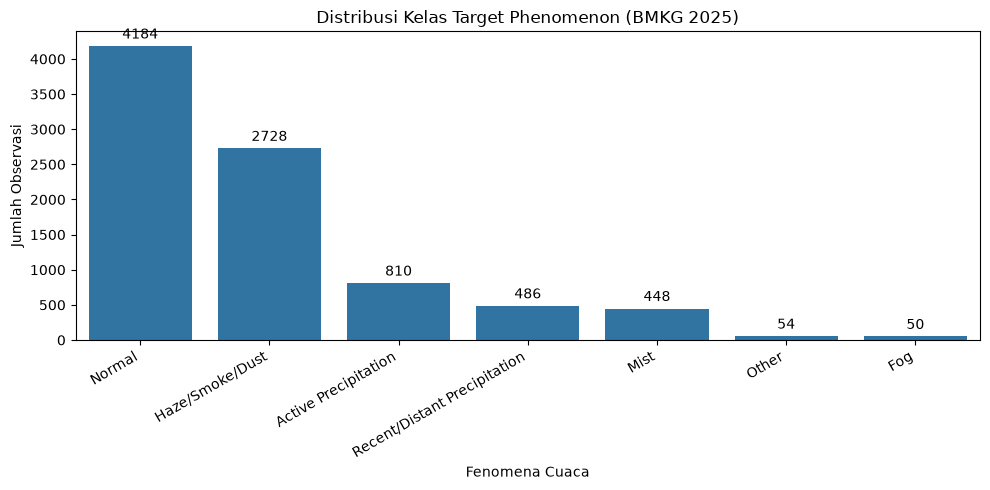

In [41]:
plt.figure(figsize=(10, 5))
order = eda_df['phenomenon'].value_counts().index
ax = sns.countplot(data=eda_df, x='phenomenon', order=order)
for container in ax.containers:
    ax.bar_label(container, padding=3)
plt.title('Distribusi Kelas Target Phenomenon (BMKG 2025)')
plt.xlabel('Fenomena Cuaca')
plt.ylabel('Jumlah Observasi')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

**Notes:**

- Dari total **8.760 data observasi**, distribusi kelas `phenomenon` menunjukkan ketidakseimbangan (*class imbalance*) yang tajam. Kelas **`Normal`** mendominasi dengan **4.184 data (47,76%)**, diikuti oleh **`Haze/Smoke/Dust`** sebanyak **2.728 data (31,14%)**, **`Active Precipitation`** sebanyak **810 data (9,25%)**, **`Recent/Distant Precipitation`** sebanyak **486 data (5,55%)**, dan **`Mist`** sebanyak **448 data (5,11%)**.
- Dua kelas minoritas memiliki jumlah sampel sangat sedikit, yaitu **`Other`** (kode `ww = 13`) sebanyak **54 data (0,62%)** dan **`Fog`** sebanyak **50 data (0,57%)**.
- Pemangkasan 3 baris pertama tahun 2025 (`00:00–02:00`) akibat pembuatan fitur lag $t-1, t-2, t-3$ tidak mengubah komposisi proporsi kelas secara signifikan. Namun, rendahnya jumlah sampel pada kelas `Fog` dan `Other` serta kemiripan kondisi sesaat antarfenomena menegaskan perlunya penambahan dinamika riwayat 1–3 jam sebelumnya serta evaluasi menggunakan metrik yang sensitif terhadap kelas minoritas (*Macro F1-Score* dan *Balanced Accuracy*).

## 2.3 Numeric Feature Distribution

Distribusi setiap variabel numerik dasar ditampilkan dalam bentuk histogram dan ringkasan statistik untuk mengetahui bentuk sebaran data, penumpukan nilai, serta keberadaan nilai ekstrem atau kode khusus. Evaluasi ini menjadi dasar untuk menyaring variabel mana saja yang cukup padat dan kontinu per jam untuk diperluas menjadi fitur lag ($t-1, t-2, t-3$) dan selisih perubahan ($\Delta$) pada tahap *preprocessing*, sekaligus mengidentifikasi variabel dengan proporsi `NaN` tinggi yang tidak layak digeser.

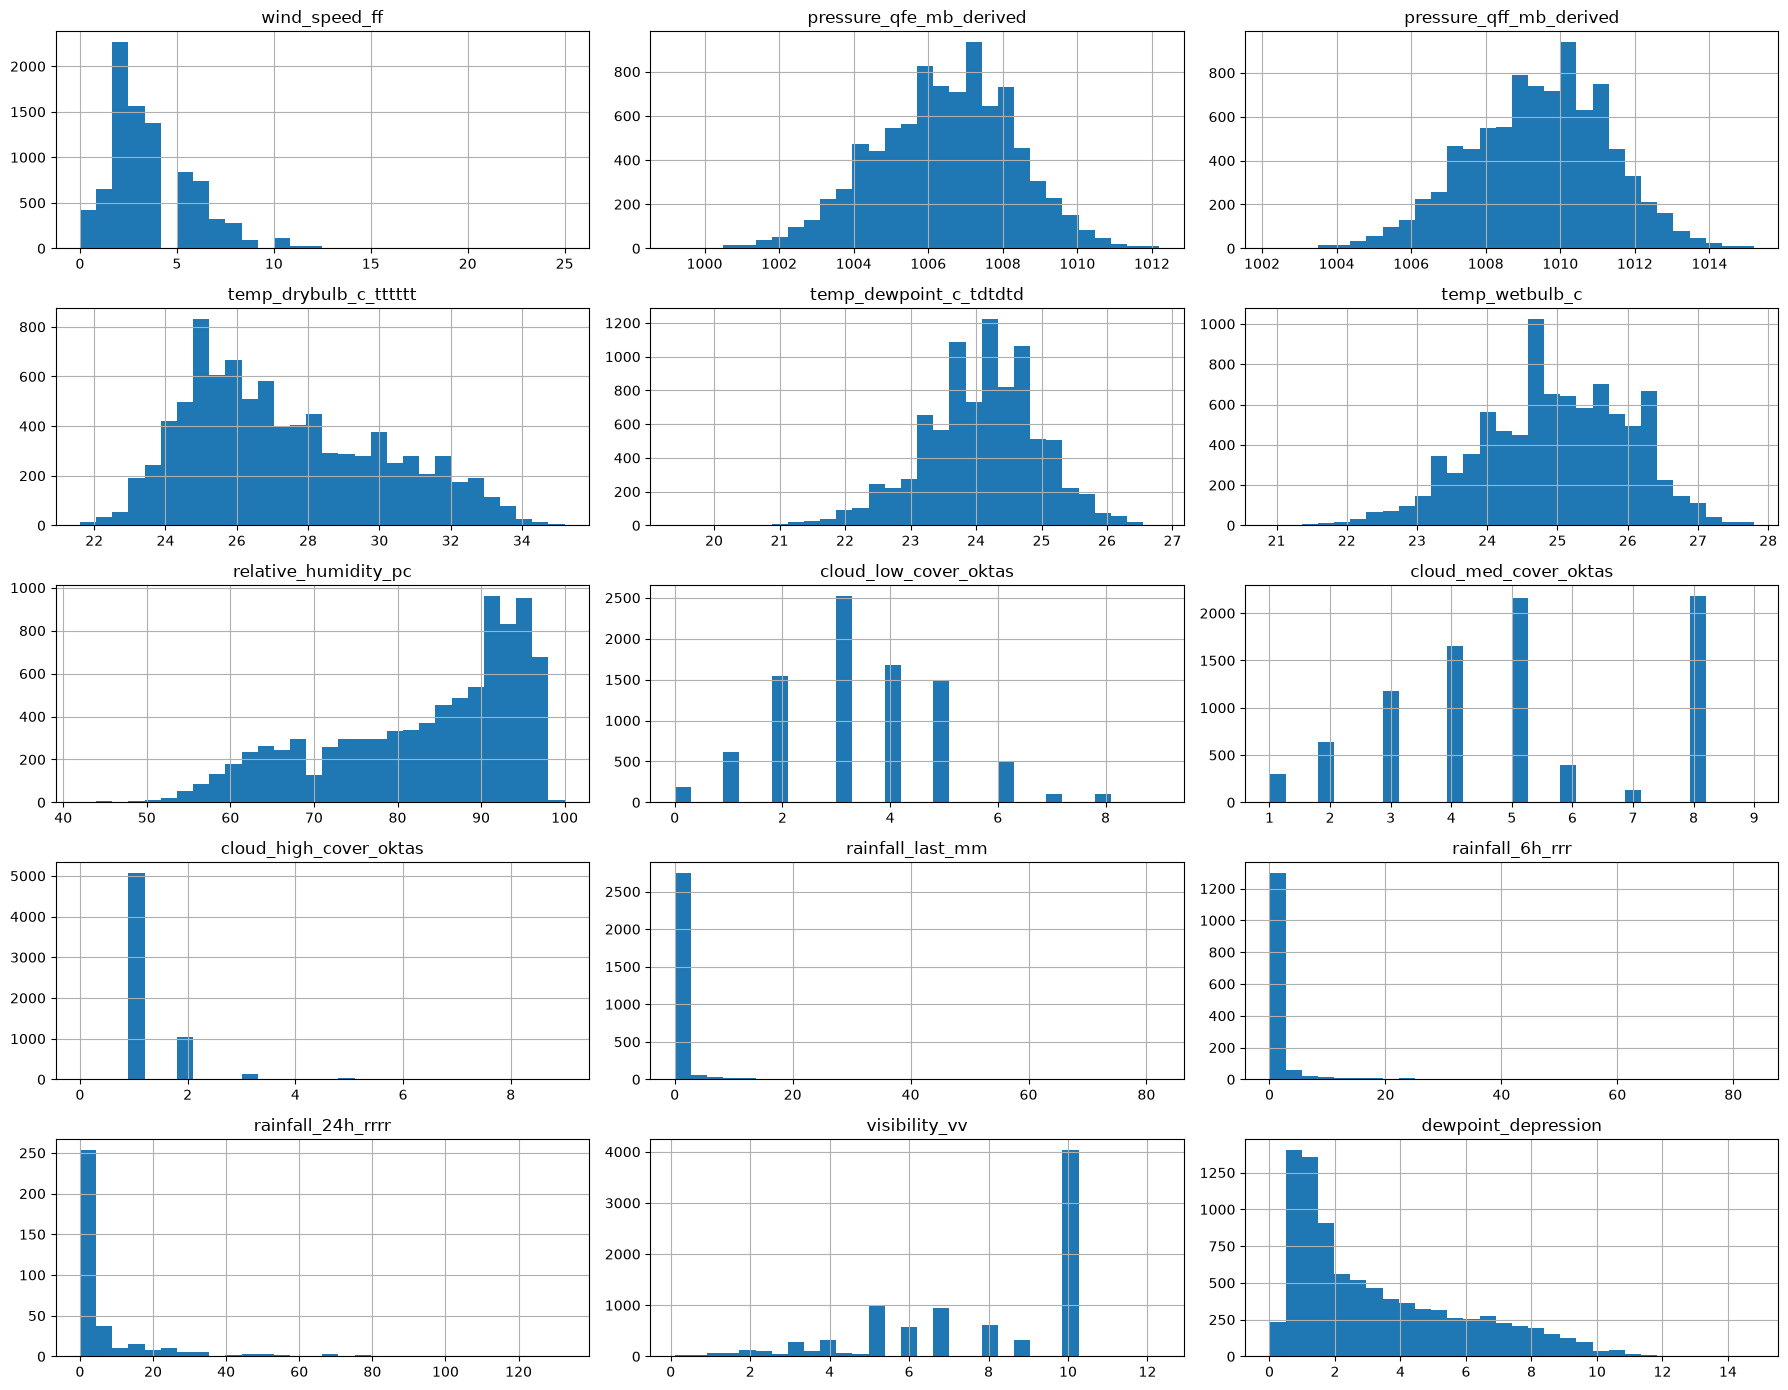

In [42]:
eda_df[num_cols].hist(bins=30, figsize=(18, 14), layout=(5, 3))
plt.tight_layout()
plt.show()

**Ringkasan statistik deskriptif dan distribusi interval (bin)**

In [43]:
def hist_text(s, bins=10):
    s = s.dropna()
    counts, edges = np.histogram(s, bins=bins)
    return ' | '.join(f'{edges[i]:.1f}-{edges[i+1]:.1f}: {counts[i]}' for i in range(len(counts)))

In [44]:
display(eda_df[num_cols].agg(['count', 'mean', 'median', 'std', 'min', 'max', 'skew']).T.round(2))

,count,mean,median,std,min,max,skew
wind_speed_ff,8760.0,3.61,3.0,2.29,0.0,25.0,1.20
pressure_qfe_mb_derived,8760.0,1006.43,1006.5,1.86,999.2,1012.2,-0.19
pressure_qff_mb_derived,8760.0,1009.45,1009.5,1.86,1002.2,1015.2,-0.20
temp_drybulb_c_tttttt,8760.0,27.39,26.8,2.73,21.6,35.2,0.49
temp_dewpoint_c_tdtdtd,8760.0,24.08,24.1,0.88,19.4,26.8,-0.31
temp_wetbulb_c,8760.0,24.96,25.0,1.06,20.9,27.8,-0.30
relative_humidity_pc,8760.0,83.23,87.0,11.94,42.0,100.0,-0.73
cloud_low_cover_oktas,8759.0,3.43,3.0,1.53,0.0,9.0,0.26
cloud_med_cover_oktas,8660.0,5.01,5.0,2.08,1.0,9.0,0.15
cloud_high_cover_oktas,6310.0,1.25,1.0,0.62,0.0,9.0,4.93


In [45]:
for col in num_cols:
    print(f'\n{col}\n  {hist_text(eda_df[col])}')


wind_speed_ff
  0.0-2.5: 3340 | 2.5-5.0: 2946 | 5.0-7.5: 1906 | 7.5-10.0: 370 | 10.0-12.5: 171 | 12.5-15.0: 16 | 15.0-17.5: 8 | 17.5-20.0: 2 | 20.0-22.5: 0 | 22.5-25.0: 1

pressure_qfe_mb_derived
  999.2-1000.5: 6 | 1000.5-1001.8: 69 | 1001.8-1003.1: 279 | 1003.1-1004.4: 968 | 1004.4-1005.7: 1550 | 1005.7-1007.0: 2266 | 1007.0-1008.3: 2313 | 1008.3-1009.6: 988 | 1009.6-1010.9: 277 | 1010.9-1012.2: 44

pressure_qff_mb_derived
  1002.2-1003.5: 6 | 1003.5-1004.8: 68 | 1004.8-1006.1: 283 | 1006.1-1007.4: 947 | 1007.4-1008.7: 1554 | 1008.7-1010.0: 2249 | 1010.0-1011.3: 2319 | 1011.3-1012.6: 996 | 1012.6-1013.9: 292 | 1013.9-1015.2: 46

temp_drybulb_c_tttttt
  21.6-23.0: 97 | 23.0-24.3: 858 | 24.3-25.7: 1935 | 25.7-27.0: 1761 | 27.0-28.4: 1250 | 28.4-29.8: 858 | 29.8-31.1: 908 | 31.1-32.5: 664 | 32.5-33.8: 385 | 33.8-35.2: 44

temp_dewpoint_c_tdtdtd
  19.4-20.1: 2 | 20.1-20.9: 7 | 20.9-21.6: 52 | 21.6-22.4: 232 | 22.4-23.1: 740 | 23.1-23.8: 2307 | 23.8-24.6: 2776 | 24.6-25.3: 2085 | 25.3-26

In [46]:
print("=== Distribusi Tutupan Awan (Oktas) ===")
for col in ['cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'cloud_high_cover_oktas']:
    print(f'{col}:', eda_df[col].value_counts(dropna=False).sort_index().to_dict())

=== Distribusi Tutupan Awan (Oktas) ===
cloud_low_cover_oktas: {0.0: 193, 1.0: 612, 2.0: 1540, 3.0: 2526, 4.0: 1681, 5.0: 1498, 6.0: 499, 7.0: 105, 8.0: 102, 9.0: 3, nan: 1}
cloud_med_cover_oktas: {1.0: 304, 2.0: 638, 3.0: 1182, 4.0: 1657, 5.0: 2162, 6.0: 400, 7.0: 129, 8.0: 2185, 9.0: 3, nan: 100}
cloud_high_cover_oktas: {0.0: 2, 1.0: 5079, 2.0: 1036, 3.0: 140, 4.0: 18, 5.0: 25, 8.0: 1, 9.0: 9, nan: 2450}


In [47]:
print("=== Proporsi Kategori Curah Hujan (%) ===")
for col in ['rainfall_last_mm', 'rainfall_6h_rrr', 'rainfall_24h_rrrr']:
    nol_pct = round((eda_df[col] == 0).mean() * 100, 1)
    trace_pct = round((eda_df[col] == 0.05).mean() * 100, 1)
    rain_pct = round((eda_df[col] > 0.05).mean() * 100, 1)
    nan_pct = round(eda_df[col].isna().mean() * 100, 1)
    print(f'{col:<18} -> Nol: {nol_pct:4.1f}% | Trace (0.05): {trace_pct:3.1f}% | Hujan (>0.05): {rain_pct:3.1f}% | NaN: {nan_pct:4.1f}%')

=== Proporsi Kategori Curah Hujan (%) ===
rainfall_last_mm   -> Nol: 26.3% | Trace (0.05): 1.8% | Hujan (>0.05): 5.2% | NaN: 66.7%
rainfall_6h_rrr    -> Nol: 11.7% | Trace (0.05): 1.1% | Hujan (>0.05): 3.9% | NaN: 83.3%
rainfall_24h_rrrr  -> Nol:  1.5% | Trace (0.05): 0.4% | Hujan (>0.05): 2.3% | NaN: 95.8%


**Notes:**

- **Kecepatan Angin (`wind_speed_ff`):** Memiliki sebaran miring ke kanan (*positively skewed*, `skew = 1,20`) dengan rata-rata `3,61 knot` dan median `3,0 knot`. Sebagian besar observasi terkonsentrasi pada kecepatan angin rendah (`0,0–5,0 knot` mencakup **6.286 baris / 71,8%**), dan semakin jarang pada kecepatan tinggi hingga maksimum `25,0 knot`. Karena terisi 100%, variabel ini layak dijadikan fitur lag.
- **Tekanan Udara (`pressure_qfe_mb_derived` & `pressure_qff_mb_derived`):** Kedua variabel memiliki distribusi hampir simetris (`skew = -0,19` dan `-0,20`) dengan rentang variasi sempit (`std = 1,86 mb`), khas wilayah ekuator. Keduanya menunjukkan pola identik dengan selisih konstan sekitar `3,02 mb`. Pemilihan salah satu variabel tekanan saja menjadi krusial sebelum pembuatan lag agar kolom turunan dan $\Delta P$ tidak terduplikasi.
- **Suhu Udara, Titik Embun, dan Bola Basah:** Suhu bola kering (`temp_drybulb_c_tttttt`) sedikit miring ke kanan (`skew = 0,49`, rentang `21,6°C–35,2°C`) akibat pemanasan siang hari, sedangkan suhu titik embun (`24,08 ± 0,88°C`) dan suhu bola basah (`24,96 ± 1,06°C`) terpusat sangat sempit. Ketiganya terisi penuh sehingga siap digunakan untuk melacak tren pendinginan atau pemanasan antarjam.
- **Kelembapan Relatif & *Dew Point Depression*:** Kelembapan relatif (`relative_humidity_pc`) miring ke kiri (`skew = -0,73`) dengan penumpukan pada kondisi lembap (`88,4%–100%` mencakup **3.972 baris / 45,3%**). Sebaliknya, `dewpoint_depression` miring ke kanan (`skew = 0,98`) dan menumpuk pada selisih kecil (`0,0°C–1,5°C` sebanyak **2.999 baris / 34,2%**), mencerminkan atmosfer dekat jenuh pada malam hingga pagi hari.
- **Tutupan Awan (`cloud_*_cover_oktas`):** Awan rendah terpusat pada `2–5 oktas` (median `3,0`), awan menengah mengelompok di `5` dan `8 oktas` (median `5,0`), sedangkan awan tinggi didominasi `1 okta` (`5.079` baris, `skew = 4,93`) dengan `2.450` nilai `NaN`. Selain itu, terdapat kode **`9`** pada beberapa baris (`3` baris di awan rendah/menengah dan `9` baris di awan tinggi) yang berarti langit terhalang (*sky obscured*), bukan tutupan 9 oktas, sehingga wajib ditangani sebelum variabel awan rendah/menengah dipertimbangkan dalam konstruksi fitur.
- **Curah Hujan (`rainfall_last_mm`, `rainfall_6h_rrr`, `rainfall_24h_rrrr`):** Ketiganya sangat miring ke kanan (`skew` masing-masing `9,87`, `6,65`, dan `3,60`) karena didominasi oleh nilai kosong (`NaN` sebesar **66,7%**, **83,3%**, dan **95,8%**). Tingginya kekosongan data ini memastikan variabel curah hujan berkala tidak dapat digeser menjadi fitur lag per jam karena akan menghilangkan mayoritas baris dataset.
- **Jarak Pandang (`visibility_vv`):** Berdistribusi miring ke kiri (`skew = -0,74`, median `8,0 km`) dengan konsentrasi tinggi pada batas atas `10,0 km` (**4.041 baris / 46,1%**) serta ekor panjang ke arah nilai rendah (`0,1–4,9 km`), menjadikannya kandidat utama untuk fitur lag guna menangkap tren penurunan atau pemulihan visibilitas.

## 2.4 Numeric Features by Phenomenon

Perbandingan nilai setiap variabel numerik dasar pada masing-masing kelas fenomena dilakukan menggunakan *boxplot* dan uji statistik Kruskal-Wallis. Selain mengukur daya pembeda tiap variabel pada satu titik waktu pengamatan ($t$), analisis ini juga mengidentifikasi area tumpang tindih (*overlap*) distribusi antarkelas yang menjelaskan keterbatasan pendekatan fitur sesaat dan mendasari penambahan fitur lag ($t-1, t-2, t-3$).

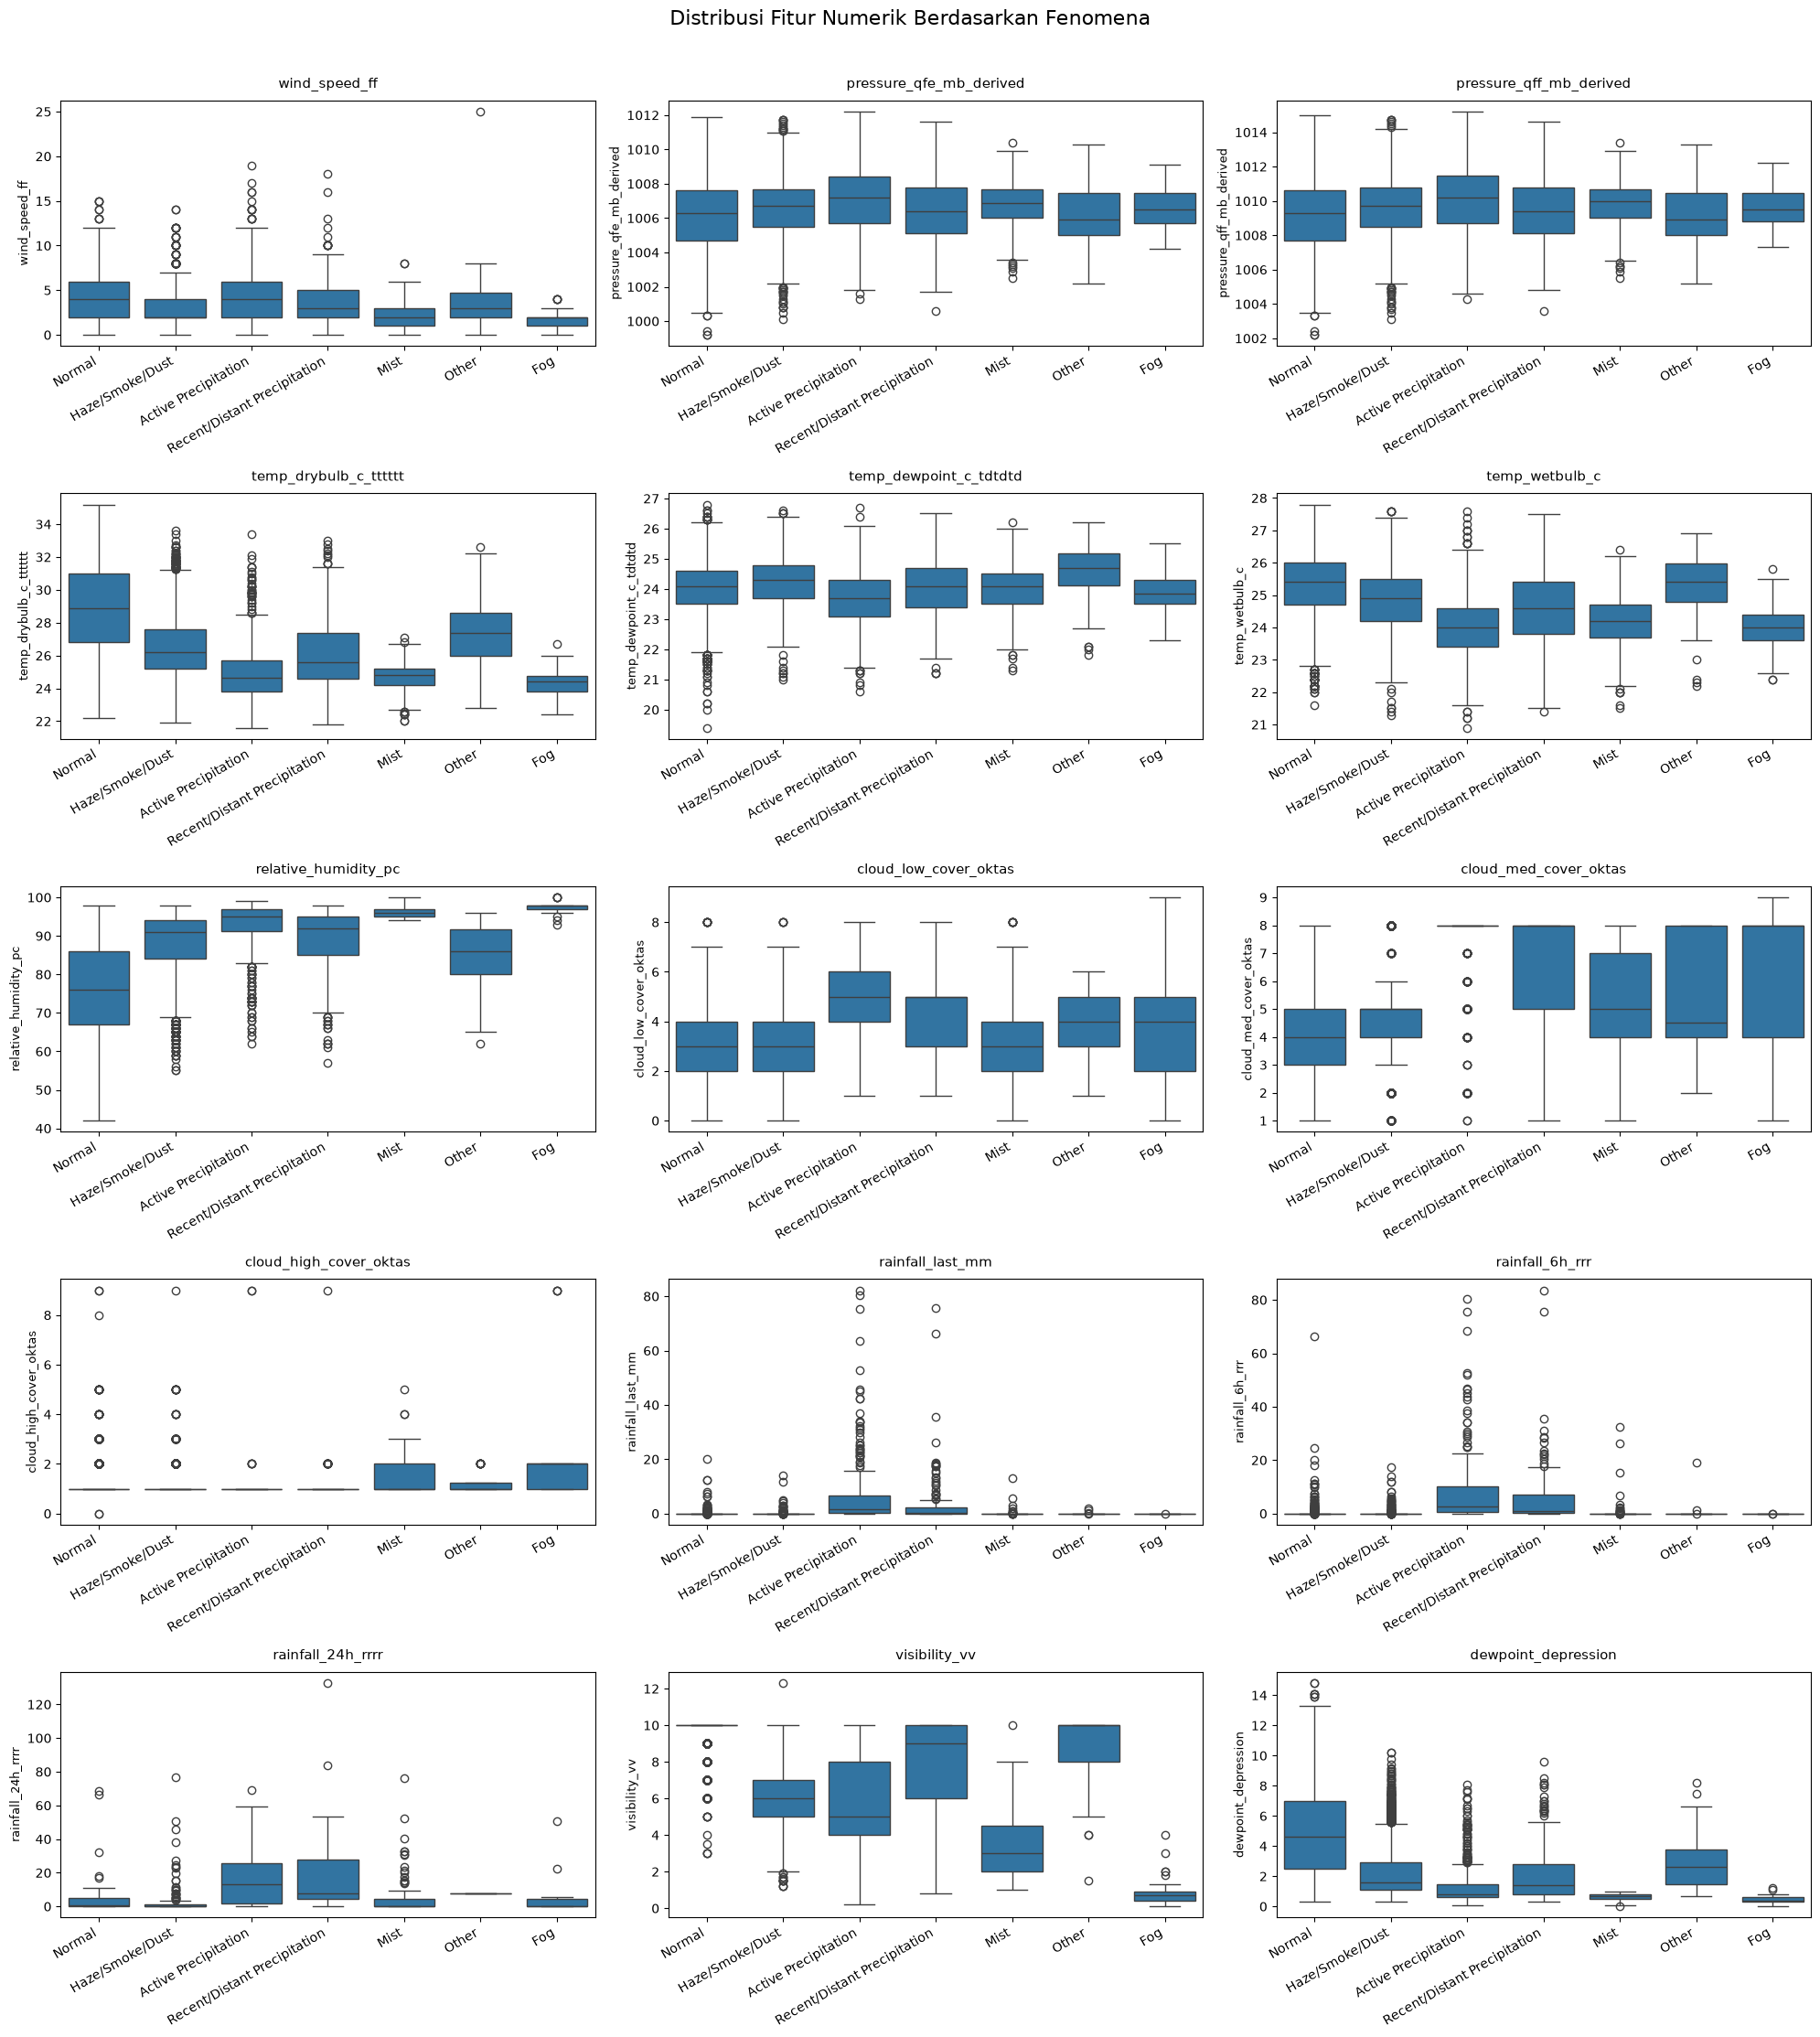

In [48]:
fig, axes = plt.subplots(5, 3, figsize=(20, 22))

for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(
        data=eda_df,
        x='phenomenon',
        y=col,
        order=eda_df['phenomenon'].value_counts().index,
        ax=ax
    )

    ax.set_title(col, fontsize=11, pad=10)
    ax.set_xlabel('')
    ax.set_ylabel(col, fontsize=9)
    
    ax.tick_params(axis='x', labelrotation=30)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')

# Menghilangkan subplot yang tidak digunakan
for ax in axes.flatten()[len(num_cols):]:
    ax.remove()

plt.suptitle(
    'Distribusi Fitur Numerik Berdasarkan Fenomena',
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

In [49]:
results = []

for col in num_cols:
    groups = [
        group[col].dropna().values
        for _, group in eda_df.groupby('phenomenon')
        if len(group[col].dropna()) > 0
    ]

    stat, p = kruskal(*groups)

    results.append({
        'Feature': col,
        'H-Statistic': stat,
        'P-Value': p,
        'Significant': p < 0.05
    })

kruskal_results = pd.DataFrame(results).sort_values(by='H-Statistic', ascending=False).reset_index(drop=True)

display(
    kruskal_results.style.format({
        'H-Statistic': '{:.2f}',
        'P-Value': '{:.3e}'
    })
)

,Feature,H-Statistic,P-Value,Significant
0,visibility_vv,6208.07,0.000e+00,True
1,relative_humidity_pc,3580.24,0.000e+00,True
2,dewpoint_depression,3576.85,0.000e+00,True
3,temp_drybulb_c_tttttt,2835.29,0.000e+00,True
4,rainfall_last_mm,1767.49,0.000e+00,True
5,cloud_low_cover_oktas,1441.36,2.682e-308,True
6,temp_wetbulb_c,1433.07,1.675e-306,True
7,cloud_med_cover_oktas,1227.07,6.610e-262,True
8,wind_speed_ff,1167.01,6.607e-249,True
9,rainfall_6h_rrr,630.83,5.216e-133,True


In [50]:
for col in num_cols:
    t = eda_df.groupby('phenomenon')[col].agg(
        n='count', min='min',
        q1=lambda x: x.quantile(.25), median='median',
        q3=lambda x: x.quantile(.75), max='max'
    ).round(2)
    print(f'\n{col}')
    print(t.to_string())


wind_speed_ff
                                 n  min   q1  median    q3  max
phenomenon                                                     
Active Precipitation           810    0  2.0     4.0  6.00   19
Fog                             50    0  1.0     2.0  2.00    4
Haze/Smoke/Dust               2728    0  2.0     2.0  4.00   14
Mist                           448    0  1.0     2.0  3.00    8
Normal                        4184    0  2.0     4.0  6.00   15
Other                           54    0  2.0     3.0  4.75   25
Recent/Distant Precipitation   486    0  2.0     3.0  5.00   18

pressure_qfe_mb_derived
                                 n     min       q1  median       q3     max
phenomenon                                                                  
Active Precipitation           810  1001.3  1005.70  1007.2  1008.40  1012.2
Fog                             50  1004.2  1005.70  1006.5  1007.45  1009.1
Haze/Smoke/Dust               2728  1000.1  1005.50  1006.7  1007.70  1011.7

**Notes:**

- ***Visibility*, Kelembapan Relatif, dan *Dew Point Depression*:** Kelas `Fog` dan `Mist` memiliki nilai jarak pandang paling rendah (median `0,7 km` dan `3,0 km`) serta *dew point depression* paling sempit (`0,4°C` dan `0,7°C`) dengan kelembapan relatif mendekati jenuh (median `98%` dan `96%`). Sebaliknya, kelas `Normal` memiliki jarak pandang tertinggi (median `10,0 km`), kelembapan terendah (`76%`), dan *dew point depression* terlebar (`4,6°C`). Meski demikian, sebaran interkuartil antara `Fog` dengan `Mist`, maupun antara `Haze/Smoke/Dust` dengan `Mist`, masih menunjukkan irisan nilai sesaat yang berdekatan sehingga memerlukan lintasan perubahan 1–3 jam sebelumnya untuk membedakan proses kondensasi vs akumulasi partikel kering.
- **Suhu Udara dan Suhu Bola Basah:** Kelas `Normal` (`28,90°C`) dan `Other` (`27,40°C`) memiliki median suhu bola kering lebih tinggi dibandingkan `Fog` (`24,40°C`), `Active Precipitation` (`24,65°C`), dan `Mist` (`24,80°C`). Laju penurunan suhu ($\Delta T$) dalam beberapa jam terakhir berpotensi membedakan pendinginan radiasi bertahap (pemicu `Fog`/`Mist`) dengan penurunan suhu mendadak akibat hujan (`Active Precipitation`).
- **Tutupan Awan dan Curah Hujan:** Kelas `Active Precipitation` dan `Recent/Distant Precipitation` sama-sama memiliki tutupan awan rendah dan menengah yang tebal (median `5,0` dan `8,0 oktas`). Kemiripan tutupan awan sesaat antara kedua kelas hujan ini menegaskan perlunya informasi riwayat waktu ($t-1, t-2, t-3$) pada parameter kelembapan, suhu, dan jarak pandang untuk membedakan hujan yang sedang berlangsung dengan hujan yang baru saja reda atau berada di kejauhan. Sementara itu, `cloud_high_cover_oktas` tercatat sangat jarang pada `Active Precipitation` (`n = 91` dari `810` observasi) karena terhalang awan hujan tebal.
- **Kecepatan Angin, Tekanan Udara, dan Titik Embun:** Fenomena `Fog`, `Mist`, dan `Haze/Smoke/Dust` cenderung terjadi pada kondisi angin tenang (median `2,0 knot`), sedangkan `Normal` dan `Active Precipitation` memiliki median lebih tinggi (`4,0 knot`). Variabel tekanan udara (`QFE` dan `QFF`) serta suhu titik embun memiliki nilai median sesaat yang berdekatan antarkelas, sehingga nilai perubahannya ($\Delta P$ dan $\Delta T_d$) lebih informatif dibandingkan nilai absolutnya saja.

Uji Kruskal-Wallis menunjukkan bahwa seluruh 15 variabel numerik dasar memiliki nilai *p-value* di bawah `0,05` (`Significant = True`), yang mengonfirmasi adanya perbedaan distribusi yang signifikan secara statistik antarkelas fenomena. Variabel `visibility_vv` mencatatkan nilai *H-statistic* tertinggi sebesar **`6208,07`**, diikuti oleh `relative_humidity_pc` (**`3580,24`**) dan `dewpoint_depression` (**`3576,85`**), sedangkan `rainfall_24h_rrrr` memiliki nilai terendah sebesar **`87,76`**.

Secara keseluruhan, hasil analisis ini mengonfirmasi bahwa parameter permukaan utama memiliki daya pembeda yang kuat, namun tumpang tindih distribusi sesaat antarkelas yang mirip menjadi justifikasi kuat untuk menambahkan fitur riwayat waktu ($t-1, t-2, t-3$) beserta laju perubahannya ($\Delta$).

## 2.5 Correlation Between Numeric Feature

Korelasi antarvariabel numerik dasar dihitung menggunakan metode Spearman untuk mengidentifikasi kekuatan hubungan monotonik dan tingkat multikolinearitas antarfitur. Dalam eksperimen berbasis fitur riwayat waktu (*lag features* $t-1, t-2, t-3$), deteksi multikolinearitas pada variabel dasar menjadi sangat penting karena setiap variabel yang dipertahankan akan dikalikan menjadi beberapa kolom turunan (nilai lag dan selisih perubahan $\Delta$). Menyeleksi variabel dasar yang sepenuhnya redundan sebelum pergeseran waktu akan mencegah ledakan dimensi sekaligus menjaga kejernihan interpretasi *feature importance*.

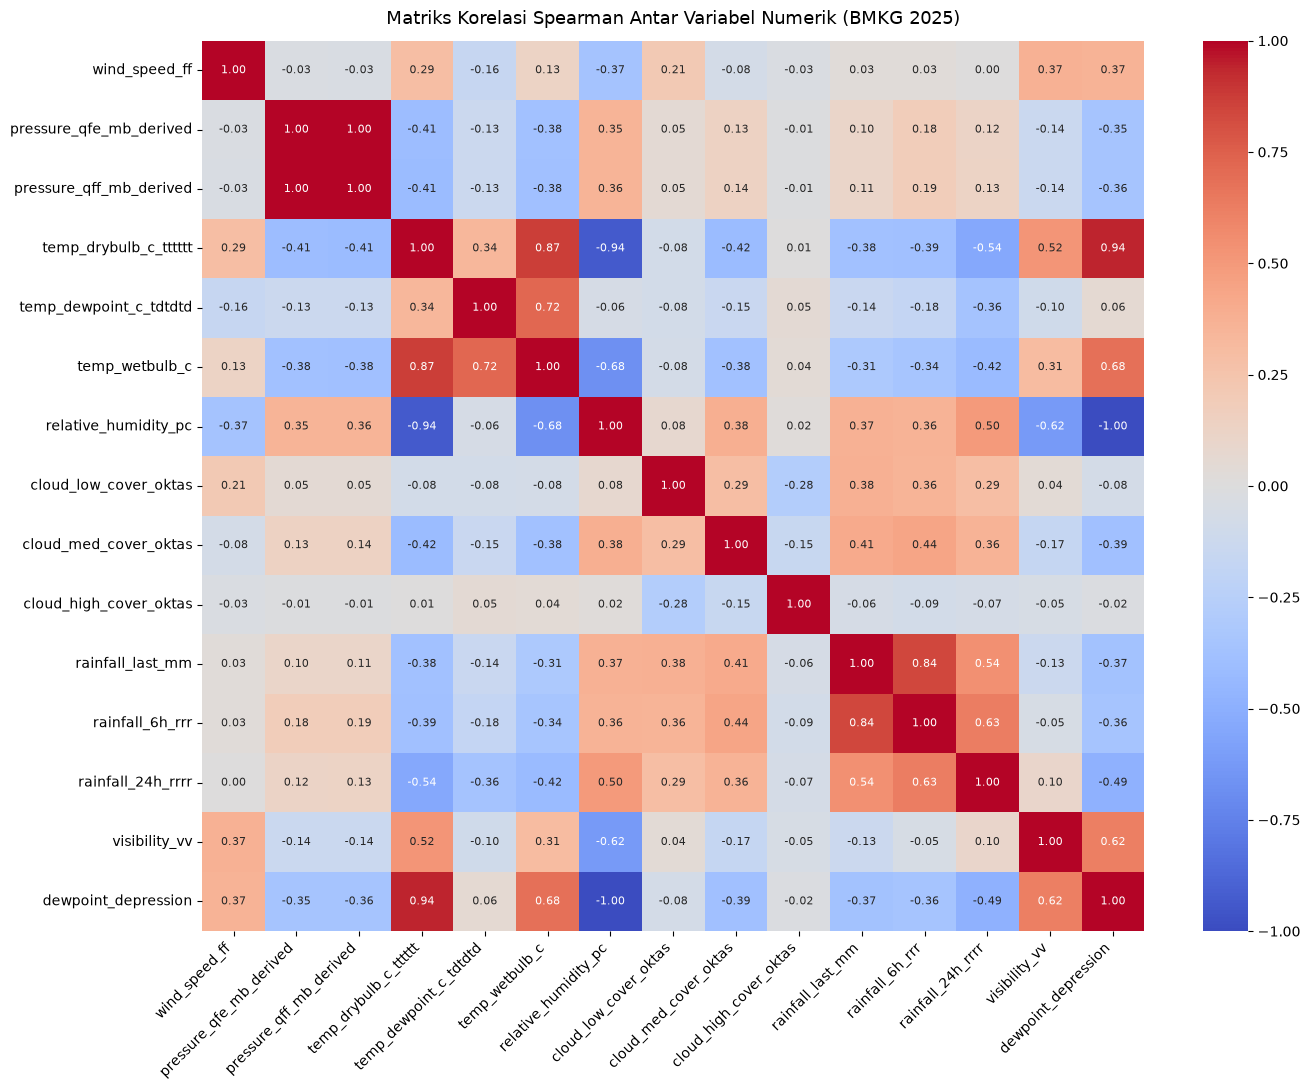

In [51]:
corr_matrix = eda_df[num_cols].corr(method='spearman')

plt.figure(figsize=(14, 11))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={'size': 8}
)
plt.title('Matriks Korelasi Spearman Antar Variabel Numerik (BMKG 2025)', fontsize=13, pad=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [52]:
display(corr_matrix.round(2))

,wind_speed_ff,pressure_qfe_mb_derived,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,relative_humidity_pc,cloud_low_cover_oktas,cloud_med_cover_oktas,cloud_high_cover_oktas,rainfall_last_mm,rainfall_6h_rrr,rainfall_24h_rrrr,visibility_vv,dewpoint_depression
wind_speed_ff,1.00,-0.03,-0.03,0.29,-0.16,0.13,-0.37,0.21,-0.08,-0.03,0.03,0.03,0.00,0.37,0.37
pressure_qfe_mb_derived,-0.03,1.00,1.00,-0.41,-0.13,-0.38,0.35,0.05,0.13,-0.01,0.10,0.18,0.12,-0.14,-0.35
pressure_qff_mb_derived,-0.03,1.00,1.00,-0.41,-0.13,-0.38,0.36,0.05,0.14,-0.01,0.11,0.19,0.13,-0.14,-0.36
temp_drybulb_c_tttttt,0.29,-0.41,-0.41,1.00,0.34,0.87,-0.94,-0.08,-0.42,0.01,-0.38,-0.39,-0.54,0.52,0.94
temp_dewpoint_c_tdtdtd,-0.16,-0.13,-0.13,0.34,1.00,0.72,-0.06,-0.08,-0.15,0.05,-0.14,-0.18,-0.36,-0.10,0.06
temp_wetbulb_c,0.13,-0.38,-0.38,0.87,0.72,1.00,-0.68,-0.08,-0.38,0.04,-0.31,-0.34,-0.42,0.31,0.68
relative_humidity_pc,-0.37,0.35,0.36,-0.94,-0.06,-0.68,1.00,0.08,0.38,0.02,0.37,0.36,0.50,-0.62,-1.00
cloud_low_cover_oktas,0.21,0.05,0.05,-0.08,-0.08,-0.08,0.08,1.00,0.29,-0.28,0.38,0.36,0.29,0.04,-0.08
cloud_med_cover_oktas,-0.08,0.13,0.14,-0.42,-0.15,-0.38,0.38,0.29,1.00,-0.15,0.41,0.44,0.36,-0.17,-0.39
cloud_high_cover_oktas,-0.03,-0.01,-0.01,0.01,0.05,0.04,0.02,-0.28,-0.15,1.00,-0.06,-0.09,-0.07,-0.05,-0.02


**Notes:**
- **Tekanan Udara (`QFE` dan `QFF`):** `pressure_qfe_mb_derived` dan `pressure_qff_mb_derived` memiliki korelasi positif sempurna (`1,00`), karena keduanya diturunkan dari pengukuran tekanan yang sama dengan selisih konstan akibat koreksi elevasi stasiun. Oleh karena itu, cukup dipilih salah satu saja sebelum membentuk fitur lag dan kecenderungan tekanan ($\Delta P$) agar tidak terjadi duplikasi penuh.
- **Suhu, Kelembapan Relatif, dan *Dew Point Depression*:** Suhu bola kering (`temp_drybulb_c_tttttt`) berkorelasi positif sangat kuat dengan `dewpoint_depression` (`0,94`) dan suhu bola basah (`0,87`), serta berkorelasi negatif sangat kuat dengan `relative_humidity_pc` (`-0,94`). Selain itu, `relative_humidity_pc` dan `dewpoint_depression` menunjukkan korelasi negatif rank sempurna (`-1,00`). Meskipun demikian, pada konteks dinamika waktu, laju perubahan masing-masing parameter tetap dapat memberikan sinyal fisik yang saling melengkapi selama variabel yang benar-benar identik (seperti salah satu variabel tekanan) sudah dipangkas.
- **Kelompok Curah Hujan (`rainfall_*`):** Variabel `rainfall_last_mm` berkorelasi positif sangat kuat dengan `rainfall_6h_rrr` (`0,84`) dan berkorelasi sedang dengan `rainfall_24h_rrrr` (`0,54`), sedangkan `rainfall_6h_rrr` dan `rainfall_24h_rrrr` memiliki korelasi positif kuat (`0,63`). Perhitungan berpasangan ini hanya mengevaluasi baris yang sama-sama terisi (`n = 1.460` untuk 6 jam dan `n = 365` untuk 24 jam).
- **Jarak Pandang (`visibility_vv`):** Memiliki korelasi negatif kuat dengan `relative_humidity_pc` (`-0,62`), korelasi positif kuat dengan `dewpoint_depression` (`0,62`), serta korelasi positif sedang dengan `temp_drybulb_c_tttttt` (`0,52`), menegaskan bahwa penurunan jarak pandang berkaitan erat dengan peningkatan kejenuhan uap air di atmosfer.
- **Kelompok Tutupan Awan (`cloud_*_cover_oktas`):** Awan rendah dan awan menengah memiliki korelasi positif lemah (`0,29`), sedangkan awan rendah dan awan tinggi berkorelasi negatif lemah (`-0,28`) karena lapisan awan bawah yang tebal sering menghalangi pengamatan awan tinggi. Awan menengah juga menunjukkan korelasi positif sedang dengan curah hujan (`0,41` terhadap `rainfall_last_mm` dan `0,44` terhadap `rainfall_6h_rrr`).

Berdasarkan matriks korelasi Spearman, fitur yang sepenuhnya redundan seperti salah satu variabel tekanan (`QFE` atau `QFF`) wajib dieliminasi pada tahap *preprocessing* sebelum pembentukan fitur lag ($t-1, t-2, t-3$) dilakukan.

## 2.6 Temporal Pattern

Pola temporal fenomena dianalisis berdasarkan jam pengamatan (WIB) dan bulan untuk memetakan siklus kemunculan tiap fenomena cuaca. Pemahaman terhadap ritme transisi diurnal (per jam) ini menjadi landasan penting dalam eksperimen fitur lag ($t-1, t-2, t-3$), karena perubahan kondisi atmosfer dalam jendela 1 hingga 3 jam sebelumnya sangat bergantung pada fase pemanasan siang hari maupun pendinginan malam hingga dini hari.

In [53]:
phenom_order = eda_df['phenomenon'].value_counts().index

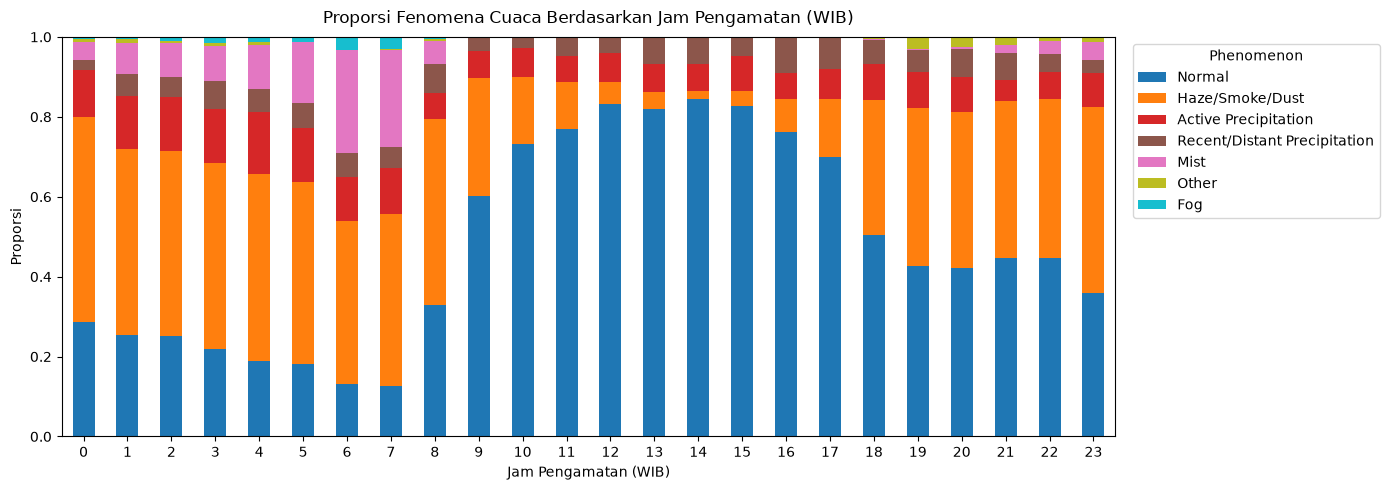

In [54]:
ct_hour = pd.crosstab(eda_df['hour_wib'], eda_df['phenomenon'], normalize='index')[phenom_order]
ax = ct_hour.plot(kind='bar', stacked=True, figsize=(14, 5), colormap='tab10')

plt.title('Proporsi Fenomena Cuaca Berdasarkan Jam Pengamatan (WIB)', fontsize=12, pad=10)
plt.xlabel('Jam Pengamatan (WIB)')
plt.ylabel('Proporsi')
plt.xticks(rotation=0)
plt.legend(title='Phenomenon', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

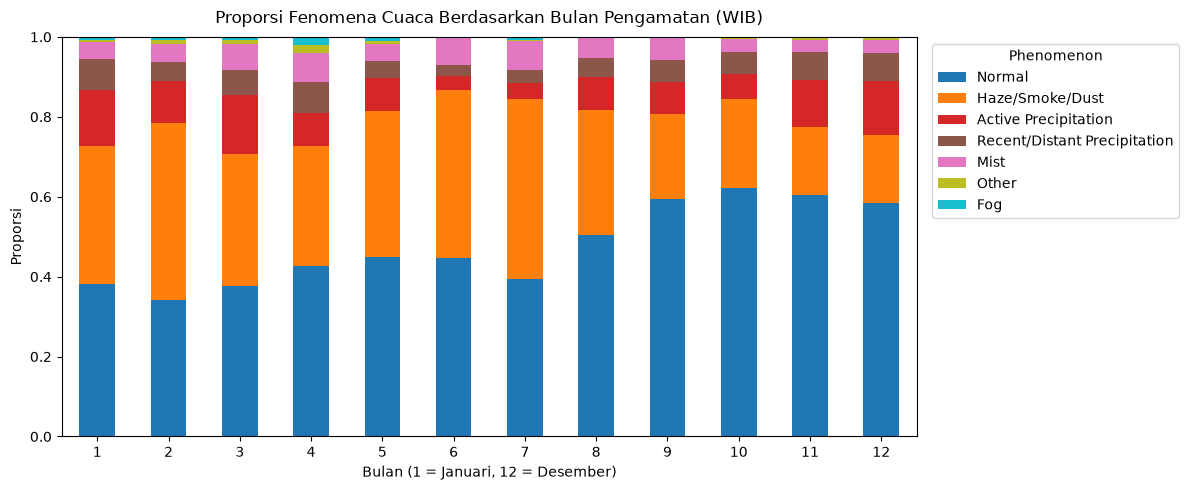

In [55]:
ct_month = pd.crosstab(eda_df['month_wib'], eda_df['phenomenon'], normalize='index')[phenom_order]
ax = ct_month.plot(kind='bar', stacked=True, figsize=(12, 5), colormap='tab10')

plt.title('Proporsi Fenomena Cuaca Berdasarkan Bulan Pengamatan (WIB)', fontsize=12, pad=10)
plt.xlabel('Bulan (1 = Januari, 12 = Desember)')
plt.ylabel('Proporsi')
plt.xticks(rotation=0)
plt.legend(title='Phenomenon', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [56]:
ct_hour_n = pd.crosstab(eda_df['hour_wib'], eda_df['phenomenon'])[phenom_order]
print("=== Proporsi Fenomena per Jam WIB (%) ===")
display((ct_hour_n.div(ct_hour_n.sum(axis=1), axis=0) * 100).round(1))

=== Proporsi Fenomena per Jam WIB (%) ===


phenomenon,Normal,Haze/Smoke/Dust,Active Precipitation,Recent/Distant Precipitation,Mist,Other,Fog
hour_wib,,,,,,,
0,28.8,51.2,11.8,2.5,4.4,0.8,0.5
1,25.5,46.6,13.2,5.5,7.7,1.1,0.5
2,25.2,46.3,13.4,4.9,8.5,0.5,1.1
3,21.9,46.6,13.4,7.1,8.8,0.5,1.6
4,18.9,46.8,15.3,5.8,11.2,0.5,1.4
5,18.1,45.5,13.7,6.3,15.1,0.0,1.4
6,13.2,40.8,11.0,6.0,25.8,0.0,3.3
7,12.6,43.0,11.5,5.2,24.4,0.3,3.0
8,32.9,46.6,6.6,7.1,5.8,0.5,0.5


In [57]:
ct_month_n = pd.crosstab(eda_df['month_wib'], eda_df['phenomenon'])[phenom_order]
print("=== Proporsi Fenomena per Bulan WIB (%) ===")
display((ct_month_n.div(ct_month_n.sum(axis=1), axis=0) * 100).round(1))

=== Proporsi Fenomena per Bulan WIB (%) ===


phenomenon,Normal,Haze/Smoke/Dust,Active Precipitation,Recent/Distant Precipitation,Mist,Other,Fog
month_wib,,,,,,,
1,38.0,34.5,14.2,7.5,4.4,0.4,0.8
2,34.1,44.3,10.4,4.9,4.5,1.0,0.7
3,37.8,32.9,14.8,6.2,6.6,0.9,0.8
4,42.6,30.0,8.3,7.6,7.4,1.9,2.1
5,44.9,36.6,8.2,4.3,4.3,0.7,1.1
6,44.7,42.1,3.5,2.6,6.8,0.1,0.1
7,39.4,45.0,4.0,3.2,7.3,0.3,0.8
8,50.4,31.2,8.3,4.8,5.0,0.1,0.1
9,59.4,21.2,7.9,5.7,5.4,0.3,0.0


In [58]:
print("Jumlah observasi per jam (min - max):", ct_hour_n.sum(axis=1).min(), "-", ct_hour_n.sum(axis=1).max())
print("Jumlah observasi per bulan:\n", ct_month_n.sum(axis=1).to_dict())

Jumlah observasi per jam (min - max): 365 - 365
Jumlah observasi per bulan:
 {1: 744, 2: 672, 3: 744, 4: 720, 5: 744, 6: 720, 7: 744, 8: 744, 9: 720, 10: 744, 11: 720, 12: 744}


**Notes:**

- **Berdasarkan Jam Pengamatan (`hour_wib`):**
  - **`Fog` dan `Mist`:** Terkonsentrasi pada dini hari hingga pagi (`23.00–08.00` WIB) akibat pendinginan radiasi permukaan, dengan puncak kemunculan pada pukul **`06.00`–`07.00` WIB** (`Mist` mencapai **25,8%** dan **24,4%**; `Fog` mencapai **3,3%** dan **3,0%**), serta tidak pernah muncul pada siang hingga sore hari (`10.00–17.00` WIB). Fase pendinginan bertahap menjelang pukul `06.00` WIB inilah yang akan ditangkap secara eksplisit oleh fitur lag suhu dan *dew point depression* pada $t-1, t-2,$ dan $t-3$.
  - **`Haze/Smoke/Dust`:** Memiliki proporsi tinggi pada malam hingga pagi hari (`19.00–08.00` WIB sekitar `38,9%–51,2%`, puncaknya pukul `00.00` WIB sebesar **51,2%**), kemudian menurun tajam saat pemanasan dan pencampuran konvektif siang hari hingga titik terendah pada pukul `14.00` WIB (**2,2%**).
  - **`Normal`:** Mendominasi pada siang hingga sore hari (`09.00–18.00` WIB), terutama pada rentang pukul **`12.00–15.00` WIB** dengan proporsi **81,9%–84,4%** (puncak pukul `14.00` WIB).
  - **`Active Precipitation` dan `Recent/Distant Precipitation`:** `Active Precipitation` memiliki proporsi tertinggi pada dini hari (`01.00–05.00` WIB, puncaknya pukul `04.00` WIB sebesar **15,3%**) serta sedikit meningkat pada sore hingga awal malam (`15.00–20.00` WIB sekitar `8,8%–9,0%`). Sementara itu, `Recent/Distant Precipitation` tersebar relatif merata sepanjang hari (`2,5%–8,8%`) dengan puncak pada pukul `16.00` WIB (**8,8%**). Transisi pasca-hujan menuju `Recent/Distant Precipitation` sangat bergantung pada riwayat 1–3 jam sebelumnya ketika hujan masih aktif.
  - **`Other` (`ww = 13`):** Hanya muncul pada malam hingga dini hari (`19.00–04.00` WIB, terutama pukul `19.00–20.00` WIB sebesar **3,0%** dan **2,5%**) karena kilat jauh secara visual lebih mudah teramati saat kondisi gelap.

- **Berdasarkan Bulan Pengamatan (`month_wib`):**
  - **`Haze/Smoke/Dust`:** Memiliki proporsi lebih tinggi pada awal hingga pertengahan tahun, khususnya pada **Juli (45,0%)**, **Februari (44,3%)**, dan **Juni (42,1%)**, lalu menurun pada September–Desember (`17,1%–22,4%`).
  - **`Normal`:** Mendominasi pada paruh akhir tahun sejak **Agustus hingga Desember (`50,4%–62,1%`)**, dengan puncak pada **Oktober (62,1%)**.
  - **`Active Precipitation` dan `Recent/Distant Precipitation`:** Keduanya memiliki proporsi tertinggi pada bulan-bulan basah seperti **Januari** (`14,2%` dan `7,5%`), **Maret** (`14,8%` dan `6,2%`), **November** (`11,7%` dan `6,9%`), dan **Desember** (`13,3%` dan `7,1%`), lalu turun ke titik terendah pada **Juni** (`3,5%` dan `2,6%`) dan **Juli** (`4,0%` dan `3,2%`).
  - **`Mist` dan `Fog`:** `Mist` relatif stabil sepanjang tahun (`3,2%–7,4%`, tertinggi pada April `7,4%` dan Juli `7,3%`), sedangkan `Fog` paling sering muncul pada **April (2,1%)** dan hampir tidak ditemukan pada Agustus–Desember (`0,0%–0,1%`).

Secara keseluruhan, pola diurnal (*per jam*) menunjukkan ritme transisi atmosfer yang sangat terstruktur. Mengombinasikan fitur waktu (seperti informasi jam pengamatan) dengan riwayat parameter fisik $t-1, t-2, t-3$ akan membantu model membedakan apakah kondisi atmosfer sedang bergerak menuju kejenuhan (pendinginan malam–pagi) atau pemulihan (pemanasan siang hari).

## 2.7 Label Origin and Data Leakage Check

Pemeriksaan dilakukan untuk memverifikasi keterkaitan langsung antara label target `phenomenon` dengan variabel penyandian cuaca (`present_weather_ww`, `weather_indicator_ix`, `past_weather_w1`, dan `past_weather_w2`). Analisis ini menetapkan batasan ketat mengenai variabel mana saja yang wajib dikeluarkan dari fitur prediktor—baik pada waktu pengamatan $t$ maupun saat menyusun fitur lag ($t-1, t-2, t-3$)—agar model murni mempelajari pola dari parameter meteorologi fisik tanpa kebocoran informasi (*data leakage*).

In [59]:
print("=== Crosstab phenomenon vs weather_indicator_ix ===")
display(pd.crosstab(eda_df['phenomenon'], eda_df['weather_indicator_ix'], margins=True))

=== Crosstab phenomenon vs weather_indicator_ix ===


weather_indicator_ix,1,2,All
phenomenon,,,
Active Precipitation,810,0,810
Fog,50,0,50
Haze/Smoke/Dust,2728,0,2728
Mist,448,0,448
Normal,201,3983,4184
Other,54,0,54
Recent/Distant Precipitation,486,0,486
All,4777,3983,8760


In [60]:
print("=== Jumlah kode unik present_weather_ww per kelas phenomenon ===")
ww_mapping_check = eda_df.groupby('phenomenon')['present_weather_ww'].agg(
    jumlah_data='count',
    kode_ww_unik=lambda x: sorted(x.unique().tolist())
)
display(ww_mapping_check)

=== Jumlah kode unik present_weather_ww per kelas phenomenon ===


,jumlah_data,kode_ww_unik
phenomenon,,
Active Precipitation,810,"[50, 51, 60, 61, 62, 63, 64, 65, 91, 95, 97]"
Fog,50,"[28, 40, 41, 42, 44, 45, 46, 47]"
Haze/Smoke/Dust,2728,"[5, 6]"
Mist,448,[10]
Normal,4184,"[0, 1, 2, 3]"
Other,54,[13]
Recent/Distant Precipitation,486,"[15, 16, 17, 21, 29]"


**Notes:**

- **`present_weather_ww`:** Seluruh **32 kode sandi unik** terpetakan secara deterministik (100% tanpa tumpang tindih kode antarkelas) ke dalam 7 kelas target `phenomenon`.
- **`weather_indicator_ix`:** Seluruh observasi pada enam kelas fenomena non-normal (`4.576` baris) seluruhnya memiliki nilai `weather_indicator_ix = 1`, sedangkan nilai `weather_indicator_ix = 2` (`3.983` baris) hanya muncul pada kelas `Normal` (bersama `201` baris dengan `ix = 1` yang dipicu oleh cuaca lampau).
- **Keputusan *Preprocessing* & Batasan Fitur Lag:** Karena `present_weather_ww` merupakan sumber langsung pembentukan label target dan `weather_indicator_ix` berkaitan langsung dengan pelaporan fenomena pada sandi sinoptik, kedua variabel tersebut beserta `past_weather_w1` dan `past_weather_w2` wajib dihapus sebelum pemodelan. Selain itu, pembentukan fitur lag ($t-1, t-2, t-3$) dibatasi **hanya pada parameter meteorologi permukaan fisik** (bukan menggeser kode cuaca `ww` atau label `phenomenon` jam sebelumnya), sehingga klasifikasi tetap objektif berdasarkan dinamika pengukuran atmosfer dan bebas dari kebocoran label.

# 3. Preprocessing

Tahap ini melakukan pembersihan dan transformasi data dasar berdasarkan seluruh temuan dari tahap *Inspection* dan *EDA* sebelumnya, agar dataset siap digunakan untuk pembentukan fitur riwayat waktu (*lag features* $t-1, t-2, t-3$) dan selisih perubahan ($\Delta$) pada tahap *Feature Engineering*. Seluruh proses dilakukan pada salinan data (`clean_df`), sehingga `data_df` asli tetap terjaga sebagai referensi mentah, serta mempertahankan seluruh 8.760 baris observasi secara utuh agar kontinuitas deret waktu per jam tidak terputus.

## 3.1 Create Working Copy

Salinan dataset dibuat untuk diproses sehingga data mentah (`data_df`) tetap tersimpan utuh sebagai referensi.

In [61]:
clean_df = data_df.copy()

In [62]:
print(f"Shape clean_df: {clean_df.shape}")

Shape clean_df: (8760, 82)


## 3.2 Fix Data Structure

Perbaikan tipe data dan pengurutan kronologis dilakukan pada dataset kerja, meliputi konversi `data_timestamp` ke tipe `datetime64` (format `%d/%m/%Y %H:%M`) yang diurutkan secara menaik (*ascending*), serta konversi kolom tutupan awan utama ke tipe numerik dengan mengubah simbol `'/'` menjadi `NaN`. Pengurutan kronologis secara eksplisit ini menjadi fondasi utama agar operasi pergeseran waktu ($t-1, t-2, t-3$) pada tahap *Feature Engineering* mengacu pada jam observasi sebelumnya secara presisi.

**Konversi data_timestamp ke datetime dengan format eksplisit dan urutkan secara kronologis**

In [63]:
clean_df['data_timestamp'] = pd.to_datetime(
    clean_df['data_timestamp'],
    format='%d/%m/%Y %H:%M',
    errors='coerce'
)
clean_df = clean_df.sort_values('data_timestamp').reset_index(drop=True)

In [64]:
print(f"Tipe data data_timestamp : {clean_df['data_timestamp'].dtypes}")
print(f"Jumlah NaT setelah parse : {clean_df['data_timestamp'].isna().sum()}\n")

Tipe data data_timestamp : datetime64[us]
Jumlah NaT setelah parse : 0



**Konversi kolom tutupan awan utama dari string ('/') ke numerik**

In [65]:
cloud_cover_cols = ['cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'cloud_high_cover_oktas']
for col in cloud_cover_cols:
    clean_df[col] = pd.to_numeric(clean_df[col].replace('/', np.nan), errors='coerce')

In [66]:
print(clean_df[cloud_cover_cols].dtypes)

cloud_low_cover_oktas     float64
cloud_med_cover_oktas     float64
cloud_high_cover_oktas    float64
dtype: object


## 3.3 Target Variable Creation

Kolom target `phenomenon` dibentuk dari variabel `present_weather_ww` menggunakan fungsi pemetaan 7 kelas fenomena cuaca yang telah didefinisikan pada tahap *EDA*. Label ini merepresentasikan kondisi cuaca aktual pada jam pengamatan ($t$) dan disimpan sebelum kolom sandi cuaca mentah dihapus. Pada tahap *Feature Engineering* nanti, kolom `phenomenon` murni berperan sebagai target klasifikasi pada waktu $t$ dan tidak akan digeser menjadi fitur lag ($t-1, t-2, t-3$), sehingga prediksi model sepenuhnya bertumpu pada dinamika parameter meteorologi fisik.

In [67]:
clean_df['phenomenon'] = clean_df['present_weather_ww'].apply(map_phenomenon)

In [68]:
print(f"Jumlah NaN pada phenomenon : {clean_df['phenomenon'].isna().sum()}")
print(f"Shape clean_df sekarang    : {clean_df.shape}")

Jumlah NaN pada phenomenon : 0
Shape clean_df sekarang    : (8760, 83)


In [69]:
display(clean_df['phenomenon'].value_counts().to_frame('Count'))

,Count
phenomenon,
Normal,4184
Haze/Smoke/Dust,2728
Active Precipitation,810
Recent/Distant Precipitation,486
Mist,448
Other,54
Fog,50


## 3.4 Drop Unused Columns

Setelah label target `phenomenon` terbentuk, kolom-kolom yang tidak digunakan sebagai variabel dasar dihapus. Dari total 83 kolom pada `clean_df`, dipertahankan 14 kolom utama (*timestamp* pengamatan, 12 parameter cuaca dasar per jam, dan 1 target `phenomenon`) dan dihapus 69 kolom lainnya dengan pertimbangan berikut:

- **Potensi *Data Leakage*:** `present_weather_ww`, `weather_indicator_ix`, `past_weather_w1`, dan `past_weather_w2` dihapus karena berkaitan langsung dengan penyandian label fenomena cuaca, sekaligus memastikan konstruksi fitur lag pada tahap berikutnya murni berasal dari pengukuran fisik atmosfer.
- **Multikolinearitas Sempurna:** `pressure_qfe_mb_derived` dihapus karena berkorelasi `1,00` dengan `pressure_qff_mb_derived`, sehingga mencegah duplikasi kolom lag tekanan dan kecenderungan tekanan ($\Delta P$) pada tahap *Feature Engineering*.
- **Tingkat Kekosongan Tinggi & Ketidaksesuaian Resolusi Lag Per Jam:** `rainfall_6h_rrr` (83,3% `NaN`), `rainfall_24h_rrrr` (95,8% `NaN`), `pressure_3h_diff_mb_ppp` (66,7% `NaN`), suhu ekstrem harian (`txtxtx`/`tntntn`, 95,8% `NaN`), serta rincian lapisan awan tambahan (`*_2`, `*_3`, `cloud_layer_*`, tinggi/jenis awan) dihapus karena hanya dicatat pada jam sinoptik tertentu atau memiliki kekosongan tinggi sehingga tidak kompatibel dengan grid pergeseran waktu per 1 jam ($t-1, t-2, t-3$). Dinamika perubahan antarjam (seperti selisih tekanan 3 jam $\Delta P_3$) nantinya akan dihitung langsung secara kontinu dari data observasi per jam.
- **Kolom Kosong Total & Metadata Sistem:** 9 kolom yang 100% `NaN` (`pressure_temp_c`, `cloud_layer_4_*`, dll.), indikator pelaporan (`wind_indicator_iw`, `rainfall_indicator_ir`), serta metadata sistem (`station_name`, `created_at`, `updated_at`, `qc_flag`, `qc_histories`) dihapus karena tidak relevan sebagai fitur prediksi.

In [70]:
keep_cols = [
    'data_timestamp',
    'wind_dir_deg_dd',
    'wind_speed_ff',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'temp_wetbulb_c',
    'relative_humidity_pc',
    'cloud_low_cover_oktas',
    'cloud_med_cover_oktas',
    'cloud_high_cover_oktas',
    'rainfall_last_mm',
    'visibility_vv',
    'phenomenon'
]

In [71]:
drop_cols = [col for col in clean_df.columns if col not in keep_cols]
clean_df.drop(columns=drop_cols, inplace=True)

In [72]:
print(f"Jumlah kolom dihapus    : {len(drop_cols)}")
print(f"Shape clean_df sekarang : {clean_df.shape}")
print(f"Daftar kolom tersisa    :\n{list(clean_df.columns)}")

Jumlah kolom dihapus    : 69
Shape clean_df sekarang : (8760, 14)
Daftar kolom tersisa    :
['data_timestamp', 'wind_dir_deg_dd', 'wind_speed_ff', 'visibility_vv', 'pressure_qff_mb_derived', 'temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'temp_wetbulb_c', 'relative_humidity_pc', 'rainfall_last_mm', 'cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'cloud_high_cover_oktas', 'phenomenon']


**Notes:**

- Dengan metode pemilihan `keep_cols`, penyaringan variabel dasar berjalan ringkas tanpa perlu menuliskan puluhan nama kolom yang dihapus secara manual.
- Dataset `clean_df` kini menyisakan **8.760 baris dan 14 kolom** yang terfokus pada parameter permukaan utama per jam, siap masuk ke tahap pembersihan nilai khusus dan penanganan *missing value* sebelum diperluas menjadi fitur lag ($t-1, t-2, t-3$).

## 3.5 Check Outlier Candidates and Special Codes

Pemeriksaan dilakukan terhadap nilai-nilai ekstrem maupun kode sandi khusus meteorologi yang teridentifikasi pada tahap *Inspection* dan *EDA* (kecepatan angin ekstrem, jarak pandang di atas 10 km, kode curah hujan *trace* `8888.0`, kode tutupan awan `9`, serta kode arah angin). Dalam eksperimen berbasis fitur riwayat waktu (*lag features* $t-1, t-2, t-3$) dan selisih perubahan antarjam ($\Delta$), membedakan variasi fisik yang valid dari artefak penyandian menjadi sangat krusial agar satu nilai sandi khusus tidak memicu lonjakan nilai selisih ($\Delta$) yang keliru pada 3 jam berikutnya.

**Cek kecepatan angin ekstrem (wind_speed_ff >= 20 knot)**

In [73]:
display(clean_df.loc[clean_df['wind_speed_ff'] >= 20, ['data_timestamp', 'wind_dir_deg_dd', 'wind_speed_ff', 'visibility_vv', 'phenomenon']])

,data_timestamp,wind_dir_deg_dd,wind_speed_ff,visibility_vv,phenomenon
3445,2025-05-24 13:00:00,270,25,10.0,Other


**Cek visibility di atas batas standar sinoptik (> 10 km)**

In [74]:
display(clean_df.loc[clean_df['visibility_vv'] > 10, ['data_timestamp', 'visibility_vv', 'relative_humidity_pc', 'phenomenon']])

,data_timestamp,visibility_vv,relative_humidity_pc,phenomenon
6408,2025-09-25,12.3,94,Haze/Smoke/Dust


**Cek kode khusus curah hujan 8888.0 (Trace / TTU) dan hujan lebat (> 50 mm)**

In [75]:
print("Jumlah baris rainfall_last_mm == 8888.0:", (clean_df['rainfall_last_mm'] == 8888.0).sum())

Jumlah baris rainfall_last_mm == 8888.0: 158


In [76]:
display(clean_df.loc[clean_df['rainfall_last_mm'] == 8888.0, ['data_timestamp', 'rainfall_last_mm', 'phenomenon']].head(5))

,data_timestamp,rainfall_last_mm,phenomenon
24,2025-01-02 00:00:00,8888.0,Active Precipitation
54,2025-01-03 06:00:00,8888.0,Active Precipitation
246,2025-01-11 06:00:00,8888.0,Recent/Distant Precipitation
279,2025-01-12 15:00:00,8888.0,Haze/Smoke/Dust
282,2025-01-12 18:00:00,8888.0,Active Precipitation


In [77]:
display(clean_df.loc[(clean_df['rainfall_last_mm'] > 50) & (clean_df['rainfall_last_mm'] != 8888.0), ['data_timestamp', 'rainfall_last_mm', 'visibility_vv', 'phenomenon']])

,data_timestamp,rainfall_last_mm,visibility_vv,phenomenon
402,2025-01-17 18:00:00,80.5,2.3,Active Precipitation
1272,2025-02-23 00:00:00,52.8,5.0,Active Precipitation
2115,2025-03-30 03:00:00,82.2,5.0,Active Precipitation
3300,2025-05-18 12:00:00,75.6,7.0,Recent/Distant Precipitation
5148,2025-08-03 12:00:00,75.5,7.0,Active Precipitation
5997,2025-09-07 21:00:00,66.2,10.0,Recent/Distant Precipitation
8088,2025-12-04 00:00:00,63.5,6.0,Active Precipitation


**Cek kode khusus tutupan awan == 9 (Sky Obscured)**

In [78]:
cloud_cols = ['cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'cloud_high_cover_oktas']

In [79]:
for col in cloud_cols:
    cnt_9 = (clean_df[col] == 9).sum()
    print(f"- {col:<24}: {cnt_9} baris bernilai 9")

- cloud_low_cover_oktas   : 3 baris bernilai 9
- cloud_med_cover_oktas   : 3 baris bernilai 9
- cloud_high_cover_oktas  : 9 baris bernilai 9


In [80]:
display(clean_df.loc[(clean_df[cloud_cols] == 9).any(axis=1), ['data_timestamp'] + cloud_cols + ['visibility_vv', 'phenomenon']])

,data_timestamp,cloud_low_cover_oktas,cloud_med_cover_oktas,cloud_high_cover_oktas,visibility_vv,phenomenon
32,2025-01-02 08:00:00,4.0,8.0,9.0,10.0,Normal
1855,2025-03-19 07:00:00,5.0,8.0,9.0,7.0,Active Precipitation
1856,2025-03-19 08:00:00,5.0,8.0,9.0,7.0,Active Precipitation
2876,2025-04-30 20:00:00,9.0,9.0,9.0,0.2,Fog
2877,2025-04-30 21:00:00,9.0,9.0,9.0,0.2,Fog
2878,2025-04-30 22:00:00,9.0,9.0,9.0,0.2,Fog
6241,2025-09-18 01:00:00,4.0,8.0,9.0,7.0,Haze/Smoke/Dust
6947,2025-10-17 11:00:00,3.0,8.0,9.0,9.0,Recent/Distant Precipitation
7502,2025-11-09 14:00:00,2.0,5.0,9.0,10.0,Normal


**Cek nilai khusus/ekstrem arah angin (wind_dir_deg_dd == 0 atau > 360)**

In [81]:
print("Min - Max wind_dir_deg_dd:", clean_df['wind_dir_deg_dd'].min(), "-", clean_df['wind_dir_deg_dd'].max())
print("Jumlah wind_dir_deg_dd == 0   :", (clean_df['wind_dir_deg_dd'] == 0).sum())
print("Jumlah wind_dir_deg_dd > 360  :", (clean_df['wind_dir_deg_dd'] > 360).sum())

Min - Max wind_dir_deg_dd: 0 - 360
Jumlah wind_dir_deg_dd == 0   : 419
Jumlah wind_dir_deg_dd > 360  : 0


In [82]:
if (clean_df['wind_dir_deg_dd'] > 360).sum() > 0:
    display(clean_df.loc[clean_df['wind_dir_deg_dd'] > 360, ['data_timestamp', 'wind_dir_deg_dd', 'wind_speed_ff', 'phenomenon']].head(5))

**Notes:**

- **Kecepatan Angin Ekstrem (`wind_speed_ff = 25 knot`):** Ditemukan 1 observasi pada `2025-05-24 13:00:00` UTC dengan kelas `Other` (kilat teramati). Nilai ini merupakan hembusan angin kencang yang wajar secara fisik saat aktivitas konvektif di sekitar stasiun, sehingga dipertahankan sebagai sinyal dinamika atmosfer yang valid bagi fitur lag.
- **Jarak Pandang di Atas Batas Standar (`visibility_vv = 12,3 km`):** Ditemukan 1 observasi pada `2025-09-25 00:00:00` UTC (`07.00` WIB) dengan kelembapan `94%` dan fenomena `Haze/Smoke/Dust`. Karena pelaporan jarak pandang sinoptik standar dibatasi hingga maksimum `10,0 km`, nilai `12,3 km` merupakan anomali pencatatan yang wajib disesuaikan ke `10,0 km` sebelum pembentukan fitur lag—jika dibiarkan, nilai tersebut akan terbawa ke baris $t+1, t+2, t+3$ dan menciptakan ilusi penurunan jarak pandang sebesar `-2,3 km` pada jam berikutnya.
- **Kode Sandi *Trace* (`8888.0`) & Hujan Lebat (`> 50 mm`):** Terdapat 158 baris bernilai `8888.0` pada `rainfall_last_mm` yang merupakan sandi baku BMKG untuk hujan tidak terukur (*Trace* / $< 0,1\text{ mm}$), sehingga dikonversi menjadi `0,05 mm` sebagai bagian dari higienitas data sebelum evaluasi kelengkapan kolom pada tahap berikutnya. Sementara itu, 7 observasi hujan lebat (`52,8–82,2 mm`) seluruhnya konsisten dengan kelas `Active Precipitation` dan `Recent/Distant Precipitation`, sehingga dipertahankan.
- **Kode Sandi Langit Terhalang (`cloud_*_cover_oktas = 9`):** Ditemukan 3 baris pada awan rendah dan menengah (seluruhnya saat kejadian `Fog` tebal dengan `visibility_vv = 0,2 km`) serta 9 baris pada awan tinggi. Dalam sandi WMO, skala tutupan awan adalah `0–8` oktas, sedangkan angka `9` berarti langit terhalang (*sky obscured*). Kode `9` wajib diubah menjadi `NaN` agar diimputasi secara wajar pada Sub-bab 3.7 dan tidak terbaca sebagai lonjakan tutupan awan menjadi `9` oktas dalam fitur lag.
- **Arah Angin (`wind_dir_deg_dd`):** Seluruh nilai berada dalam rentang valid `0°–360°` (419 baris bernilai `0°` sebagai kondisi angin tenang/*calm*, tanpa kode variabel `990`). Karena sifatnya yang siklikal (sudut `350°` dan `10°` berjarak `20°`, bukan `340°`), variabel ini akan ditransformasikan menjadi komponen vektor ($\sin/\cos$) pada tahap *Feature Engineering* sebelum digeser menjadi fitur lag.

## 3.6 Handle Special Codes and Anomalies

Berdasarkan hasil pemeriksaan pada Sub-bab 3.5, dilakukan penyesuaian nilai sandi khusus dan anomali pencatatan pada `clean_df` sebelum tahap imputasi dan pembentukan fitur riwayat waktu:

1. Mengonversi kode curah hujan *trace* `8888.0` pada `rainfall_last_mm` menjadi `0,05 mm`.
2. Mengonversi kode tutupan awan `9` (*sky obscured*) pada kolom tutupan awan menjadi `NaN` agar dapat diimputasi secara kontinu pada tahap berikutnya.
3. Membatasi nilai anomali `visibility_vv > 10,0 km` (`12,3 km`) ke batas atas pelaporan sinoptik standar sebesar `10,0 km` guna mencegah artefak selisih jarak pandang ($\Delta \text{visibility}$) pada fitur lag.

**Konversi kode trace 8888.0 -> 0.05 mm pada curah hujan**

In [83]:
clean_df['rainfall_last_mm'] = clean_df['rainfall_last_mm'].replace(8888.0, 0.05)

In [84]:
print("Sisa rainfall_last_mm == 8888.0 :", (clean_df['rainfall_last_mm'] == 8888.0).sum())
print("Max rainfall_last_mm sekarang    :", clean_df['rainfall_last_mm'].max())

Sisa rainfall_last_mm == 8888.0 : 0
Max rainfall_last_mm sekarang    : 82.2


**Konversi kode sky obscured (9) -> NaN pada kolom tutupan awan**

In [85]:
for col in cloud_cols:
    clean_df[col] = clean_df[col].replace(9.0, np.nan)

In [86]:
print("Sisa kode 9 pada kolom awan      :", (clean_df[cloud_cols] == 9.0).sum().to_dict())

Sisa kode 9 pada kolom awan      : {'cloud_low_cover_oktas': 0, 'cloud_med_cover_oktas': 0, 'cloud_high_cover_oktas': 0}


**Sesuaikan anomali visibility > 10.0 km ke batas atas standar 10.0 km**

In [87]:
clean_df.loc[clean_df['visibility_vv'] > 10.0, 'visibility_vv'] = 10.0

In [88]:
print("Max visibility_vv sekarang       :", clean_df['visibility_vv'].max())

Max visibility_vv sekarang       : 10.0


**Notes:**

- Seluruh kode khusus penyandian dan anomali rentang fisik berhasil dibersihkan tanpa menghapus satu pun baris observasi, sehingga kontinuitas grid waktu per 1 jam tetap terjaga utuh menuju tahap penanganan *missing value*.

## 3.7 Handle Missing Values

Pemeriksaan dan penanganan nilai hilang (*missing values*) dilakukan pada empat kolom yang masih memiliki `NaN` setelah pembersihan sandi khusus. Dalam eksperimen berbasis fitur riwayat waktu (*lag features* $t-1, t-2, t-3$), pencapaian kondisi **nol nilai hilang (`0 NaN`) tanpa menghapus baris di tengah deret waktu** menjadi syarat mutlak—karena setiap `NaN` yang tersisa akan merambat (*propagate*) ke 3 jam berikutnya saat operasi pergeseran waktu dilakukan, sedangkan penghapusan baris di tengah dataset akan memutus interval 1 jam:

- **`rainfall_last_mm` (`5.840 NaN` / `66,7%`):** Dihapus karena hanya dicatat setiap 3 jam (pada jam sinoptik utama UTC). Jika dipertahankan, pergeseran lag $t-1, t-2, t-3$ akan menghasilkan nilai kosong di seluruh baris pengamatan per jam.
- **`cloud_high_cover_oktas` (`2.459 NaN` / `28,1%`):** Dihapus karena tingginya proporsi kekosongan akibat pandangan awan tinggi yang sering terhalang lapisan awan rendah dan menengah.
- **`cloud_low_cover_oktas` (`4 NaN`) dan `cloud_med_cover_oktas` (`103 NaN`):** Diisi menggunakan *forward fill* dengan batas maksimal 3 jam (`ffill(limit=3)`) guna mempertahankan kontinuitas kondisi tutupan awan antarjam yang berdekatan, diikuti median global untuk sisa kekosongan berdurasi lebih panjang.

**Cek ringkasan missing values saat ini**

In [89]:
missing_summary = clean_df.isna().sum()
print("=== Kolom dengan Missing Values ===")
print(missing_summary[missing_summary > 0])

=== Kolom dengan Missing Values ===
rainfall_last_mm          5840
cloud_low_cover_oktas        4
cloud_med_cover_oktas      103
cloud_high_cover_oktas    2459
dtype: int64


**Verifikasi jadwal pelaporan rainfall_last_mm per jam (UTC)**

In [90]:
hr_utc = clean_df['data_timestamp'].dt.hour
display(pd.crosstab(hr_utc, clean_df['rainfall_last_mm'].notna(), colnames=['Terisi (Not NaN)']))

Terisi (Not NaN),False,True
data_timestamp,,
0,0,365
1,365,0
2,365,0
3,0,365
4,365,0
5,365,0
6,0,365
7,365,0
8,365,0


**Inspeksi baris sekitar NaN pada cloud_low_cover_oktas**

In [91]:
idx_nan = clean_df[clean_df['cloud_low_cover_oktas'].isna()].index
idx_all = idx_nan.union(idx_nan - 1).union(idx_nan + 1).sort_values()

display(clean_df.loc[idx_all, ['data_timestamp', 'cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'visibility_vv', 'phenomenon']])

,data_timestamp,cloud_low_cover_oktas,cloud_med_cover_oktas,visibility_vv,phenomenon
2875,2025-04-30 19:00:00,4.0,8.0,1.0,Fog
2876,2025-04-30 20:00:00,NaN,NaN,0.2,Fog
2877,2025-04-30 21:00:00,NaN,NaN,0.2,Fog
2878,2025-04-30 22:00:00,NaN,NaN,0.2,Fog
2879,2025-04-30 23:00:00,2.0,4.0,0.2,Fog
3767,2025-06-06 23:00:00,1.0,6.0,5.0,Mist
3768,2025-06-07 00:00:00,NaN,6.0,3.6,Mist
3769,2025-06-07 01:00:00,1.0,2.0,7.0,Haze/Smoke/Dust


In [92]:
is_nan = clean_df['cloud_low_cover_oktas'].isna()
nan_groups = (is_nan != is_nan.shift()).cumsum()
nan_runs = (
    clean_df[is_nan]
    .groupby(nan_groups)
    .agg(
        start_time=('data_timestamp', 'min'),
        end_time=('data_timestamp', 'max'),
        durasi_jam=('data_timestamp', 'count'),
        phenomenon_dominan=('phenomenon', lambda x: x.mode()[0])
    )
    .reset_index(drop=True)
)

In [93]:
print("=== Distribusi Panjang Interval NaN (Jam Berturut-turut) ===")
print(nan_runs['durasi_jam'].value_counts().sort_index().to_dict())

=== Distribusi Panjang Interval NaN (Jam Berturut-turut) ===
{1: 1, 3: 1}


In [94]:
print("=== Kejadian Interval NaN Terpanjang ===")
display(nan_runs.sort_values('durasi_jam', ascending=False).head())

=== Kejadian Interval NaN Terpanjang ===


,start_time,end_time,durasi_jam,phenomenon_dominan
0,2025-04-30 20:00:00,2025-04-30 22:00:00,3,Fog
1,2025-06-07 00:00:00,2025-06-07 00:00:00,1,Mist


**Cek distribusi fenomena pada 103 baris NaN cloud_med_cover_oktas**

In [95]:
print(clean_df.loc[clean_df['cloud_med_cover_oktas'].isna(), 'phenomenon'].value_counts())

phenomenon
Active Precipitation            78
Normal                           8
Mist                             7
Fog                              4
Recent/Distant Precipitation     3
Haze/Smoke/Dust                  3
Name: count, dtype: int64


In [96]:
is_nan = clean_df['cloud_med_cover_oktas'].isna()
nan_groups = (is_nan != is_nan.shift()).cumsum()
nan_runs = (
    clean_df[is_nan]
    .groupby(nan_groups)
    .agg(
        start_time=('data_timestamp', 'min'),
        end_time=('data_timestamp', 'max'),
        durasi_jam=('data_timestamp', 'count'),
        phenomenon_dominan=('phenomenon', lambda x: x.mode()[0])
    )
    .reset_index(drop=True)
)

In [97]:
print("=== Distribusi Panjang Interval NaN (Jam Berturut-turut) ===")
print(nan_runs['durasi_jam'].value_counts().sort_index().to_dict())

=== Distribusi Panjang Interval NaN (Jam Berturut-turut) ===
{1: 21, 2: 13, 3: 6, 4: 3, 5: 4, 6: 1}


In [98]:
print("=== 10 Kejadian Interval NaN Terpanjang ===")
display(nan_runs.sort_values('durasi_jam', ascending=False).head(10))

=== 10 Kejadian Interval NaN Terpanjang ===


,start_time,end_time,durasi_jam,phenomenon_dominan
39,2025-12-01 19:00:00,2025-12-02 00:00:00,6,Active Precipitation
42,2025-12-12 13:00:00,2025-12-12 17:00:00,5,Active Precipitation
41,2025-12-09 18:00:00,2025-12-09 22:00:00,5,Active Precipitation
37,2025-11-11 18:00:00,2025-11-11 22:00:00,5,Active Precipitation
44,2025-12-15 13:00:00,2025-12-15 17:00:00,5,Active Precipitation
4,2025-01-18 07:00:00,2025-01-18 10:00:00,4,Active Precipitation
32,2025-09-05 14:00:00,2025-09-05 17:00:00,4,Active Precipitation
38,2025-11-19 19:00:00,2025-11-19 22:00:00,4,Active Precipitation
24,2025-04-30 20:00:00,2025-04-30 22:00:00,3,Fog
0,2025-01-13 21:00:00,2025-01-13 23:00:00,3,Active Precipitation


**Hapus rainfall_last_mm dan cloud_high_cover_oktas**

In [99]:
clean_df.drop(columns=['rainfall_last_mm', 'cloud_high_cover_oktas'], inplace=True)

**Imputasi `cloud_low_cover_oktas` & `cloud_med_cover_oktas` `ffill` maksimal 3 jam berturut-turut, sisanya diisi median global masing-masing kolom**

In [100]:
cloud_impute_cols = ['cloud_low_cover_oktas', 'cloud_med_cover_oktas']

In [101]:
for col in cloud_impute_cols:
    col_median = clean_df[col].median()
    clean_df[col] = clean_df[col].ffill(limit=3).fillna(col_median)
    print(f"Median global {col:<22} : {col_median}")

Median global cloud_low_cover_oktas  : 3.0
Median global cloud_med_cover_oktas  : 5.0


In [102]:
print(f"\nTotal sisa missing values di clean_df : {clean_df.isna().sum().sum()}")
print(f"Shape clean_df sekarang               : {clean_df.shape}")


Total sisa missing values di clean_df : 0
Shape clean_df sekarang               : (8760, 12)


In [103]:
display(clean_df.head())

,data_timestamp,wind_dir_deg_dd,wind_speed_ff,visibility_vv,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,relative_humidity_pc,cloud_low_cover_oktas,cloud_med_cover_oktas,phenomenon
0,2025-01-01 00:00:00,300,5,7.0,1009.8,25.8,24.8,25.1,95,3.0,3.0,Haze/Smoke/Dust
1,2025-01-01 01:00:00,310,9,10.0,1010.6,26.7,24.8,25.3,89,4.0,4.0,Normal
2,2025-01-01 02:00:00,310,8,10.0,1011.0,28.0,24.8,25.6,83,3.0,3.0,Normal
3,2025-01-01 03:00:00,350,10,10.0,1010.9,29.5,24.5,25.8,75,4.0,2.0,Normal
4,2025-01-01 04:00:00,330,10,10.0,1010.3,30.6,24.4,26.0,69,4.0,2.0,Normal


**Notes:**

- **`rainfall_last_mm` (`5.840 NaN` / `66,7%`):** Hasil pemeriksaan jadwal pelaporan membuktikan bahwa variabel ini hanya dicatat setiap 3 jam sekali pada pukul `00, 03, 06, 09, 12, 15, 18,` dan `21` UTC (`365` hari penuh pada setiap jam tersebut), sedangkan `16` jam lainnya selalu kosong. Penghapusan kolom ini mencegah propagasi `NaN` secara masif saat pembentukan fitur lag per jam.
- **`cloud_high_cover_oktas` (`2.459 NaN` / `28,1%`):** Dihapus karena hampir sepertiga observasi tidak teramati akibat terhalang awan rendah dan menengah.
- **`cloud_low_cover_oktas` (`4 NaN`) dan `cloud_med_cover_oktas` (`103 NaN` / `1,18%`):** Pemeriksaan durasi kekosongan pada `cloud_med_cover_oktas` menunjukkan `40` kejadian berdurasi pendek (`1–3` jam) dan `8` kejadian berdurasi panjang (`4–6` jam) yang seluruhnya terjadi saat `Active Precipitation`, sedangkan `cloud_low_cover_oktas` memiliki durasi kosong maksimal `3` jam. Penggunaan `ffill(limit=3)` menjaga kesinambungan transisi tutupan awan jangka pendek tanpa menyeret nilai sebelum hujan terlalu jauh, sementara pengisian sisa kekosongan dengan median global memastikan tidak ada informasi label target yang bocor.
- Setelah tahap ini, `clean_df` bersih sepenuhnya dari nilai hilang (`0 NaN`) dengan tetap mempertahankan **8.760 baris** secara utuh dan **12 kolom**, sehingga operasi pergeseran lag ($t-1, t-2, t-3$) pada tahap *Feature Engineering* hanya akan memangkas `3` baris pertama tahun 2025.

## 3.8 Finalize Data Types

Mengonversi kembali kolom tutupan awan (`cloud_low_cover_oktas` dan `cloud_med_cover_oktas`) yang sempat bertipe `float64` akibat keberadaan simbol `'/'`, kode `9`, dan *missing value* menjadi tipe integer (`int8`), setelah seluruh nilai hilang berhasil ditangani pada tahap sebelumnya. Efisiensi tipe data ini juga membantu menjaga penggunaan memori tetap ringan sebelum jumlah kolom bertambah akibat pembentukan fitur lag ($t-1, t-2, t-3$) dan selisih perubahan ($\Delta$).

In [104]:
cloud_cols = ['cloud_low_cover_oktas', 'cloud_med_cover_oktas']

In [105]:
for col in cloud_cols:
    assert (clean_df[col] % 1 == 0).all(), f"Kolom {col} masih mengandung nilai desimal!"
    clean_df[col] = clean_df[col].astype('int8')

display(clean_df[cloud_cols].head(5))

,cloud_low_cover_oktas,cloud_med_cover_oktas
0,3,3
1,4,4
2,3,3
3,4,2
4,4,2


In [106]:
print(clean_df.dtypes)

data_timestamp             datetime64[us]
wind_dir_deg_dd                     int64
wind_speed_ff                       int64
visibility_vv                     float64
pressure_qff_mb_derived           float64
temp_drybulb_c_tttttt             float64
temp_dewpoint_c_tdtdtd            float64
temp_wetbulb_c                    float64
relative_humidity_pc                int64
cloud_low_cover_oktas                int8
cloud_med_cover_oktas                int8
phenomenon                            str
dtype: object


**Notes:**

- Seluruh nilai pada `cloud_low_cover_oktas` dan `cloud_med_cover_oktas` terbukti berupa bilangan bulat (`0–8` oktas) setelah proses imputasi, sehingga berhasil dikonversi kembali ke tipe `int8`.
- Seluruh **12 kolom** dasar pada `clean_df` kini memiliki tipe data numerik dan waktu yang presisi serta efisien, siap dilanjutkan ke tahap penyesuaian zona waktu lokal dan validasi kesiapan deret waktu.

## 3.9 Convert Timestamp to Local Time (WIB)

Mengonversi `data_timestamp` dari waktu standar meteorologi (UTC) ke waktu lokal stasiun (WIB / UTC+7) dalam kolom baru `datetime_wib`. Penyesuaian zona waktu ini memastikan bahwa ekstraksi fitur siklus diurnal (jam pengamatan lokal) pada tahap *Feature Engineering* selaras dengan pola pemanasan siang hari dan pendinginan dini hari di Stasiun Meteorologi Sultan Thaha Jambi, yang nantinya akan bekerja berdampingan dengan fitur lag ($t-1, t-2, t-3$).

In [107]:
date_position = clean_df.columns.get_loc('data_timestamp') + 1
clean_df.insert(date_position, 'datetime_wib', clean_df['data_timestamp'] + pd.Timedelta(hours=7))

In [108]:
print("First date (WIB) :", clean_df['datetime_wib'].min())
print("Last date (WIB)  :", clean_df['datetime_wib'].max())
print("Shape clean_df   :", clean_df.shape)

First date (WIB) : 2025-01-01 07:00:00
Last date (WIB)  : 2026-01-01 06:00:00
Shape clean_df   : (8760, 13)


In [109]:
display(clean_df[['data_timestamp', 'datetime_wib']].head(5))

,data_timestamp,datetime_wib
0,2025-01-01 00:00:00,2025-01-01 07:00:00
1,2025-01-01 01:00:00,2025-01-01 08:00:00
2,2025-01-01 02:00:00,2025-01-01 09:00:00
3,2025-01-01 03:00:00,2025-01-01 10:00:00
4,2025-01-01 04:00:00,2025-01-01 11:00:00


**Notes:**

- Penambahan offset `+7` jam berhasil mengonversi seluruh **8.760 waktu pengamatan** dari UTC ke WIB, sehingga rentang waktu bergeser dari `2025-01-01 00:00:00` – `2025-12-31 23:00:00` UTC menjadi `2025-01-01 07:00:00` – `2026-01-01 06:00:00` WIB.
- Kolom `data_timestamp` (UTC) tetap dipertahankan sementara sebagai referensi waktu asli dan kunci validasi urutan kronologis hingga seluruh fitur waktu dan fitur lag selesai dibentuk pada tahap *Feature Engineering*.

## 3.10 Verify Sequential Continuity for Lag Construction

Validasi akhir tahap *Preprocessing* dilakukan untuk memastikan bahwa `clean_df` memenuhi seluruh syarat teknis sebelum pembentukan fitur riwayat waktu (*lag features* $t-1, t-2, t-3$) dan selisih perubahan ($\Delta$) pada tahap *Feature Engineering*. Pemeriksaan mencakup ketiadaan nilai hilang (`0 NaN`), keunikan dan urutan kronologis *timestamp*, serta konsistensi interval tepat 1 jam di seluruh baris observasi.

In [110]:
assert clean_df.isna().sum().sum() == 0, "Masih terdapat missing value di clean_df!"
assert clean_df['data_timestamp'].is_monotonic_increasing, "Urutan timestamp belum kronologis!"
assert clean_df['data_timestamp'].is_unique, "Terdapat duplikasi timestamp!"

In [111]:
time_diffs = clean_df['data_timestamp'].diff().dropna()
assert (time_diffs == pd.Timedelta(hours=1)).all(), "Ditemukan lompatan waktu (bukan 1 jam)!"

In [112]:
print(f"Status Missing Values   : {clean_df.isna().sum().sum()} NaN (Bersih)")
print(f"Urutan & Keunikan Waktu : Terurut kronologis & unik ({len(clean_df)} baris)")
print(f"Konsistensi Interval    : 100% tepat 1 jam ({len(time_diffs)} interval)")
print(f"Estimasi Baris Pasca-Lag: {len(clean_df) - 3} baris valid (setelah pemangkasan t-1 s.d. t-3)")

Status Missing Values   : 0 NaN (Bersih)
Urutan & Keunikan Waktu : Terurut kronologis & unik (8760 baris)
Konsistensi Interval    : 100% tepat 1 jam (8759 interval)
Estimasi Baris Pasca-Lag: 8757 baris valid (setelah pemangkasan t-1 s.d. t-3)


**Notes:**

- Seluruh pemeriksaan validasi terpenuhi: `clean_df` memiliki dimensi **8.760 baris dan 13 kolom** dengan **`0 NaN`**, terurut secara kronologis, unik, dan memiliki interval tepat **1 jam** di seluruh deret waktu.
- Dengan kondisi grid waktu yang terkunci ini, operasi pergeseran waktu ($t-1, t-2, t-3$) pada tahap *Feature Engineering* dipastikan hanya akan memangkas **3 baris pertama tahun 2025** (`2025-01-01 00:00` s.d. `02:00` UTC), menyisakan **8.757 baris observasi** yang utuh dan siap dimodelkan.

# 4. Feature Engineering

Tahap *feature engineering* dilakukan untuk membentuk variabel-variabel baru dari dataset bersih (`clean_df`) guna membantu model membedakan fenomena cuaca secara lebih akurat. Pembentukan fitur dirancang dalam dua tahapan berurutan: pertama, membangun indikator fisik dan siklikal pada titik waktu pengamatan ($t$) (Sub-bab 4.1–4.4); kedua, memperluas dinamika atmosfer ke dalam **fitur riwayat waktu (*lag features* $t-1, t-2, t-3$)** dan **laju perubahan antarjam ($\Delta$)** (Sub-bab 4.5–4.6) agar model mampu mengenali proses pembentukan maupun peluruhan fenomena cuaca.

## 4.1 Dewpoint Depression

Menghitung selisih antara suhu bola kering dan suhu titik embun (`temp_drybulb_c_tttttt - temp_dewpoint_c_tdtdtd`) untuk merangkum informasi suhu dan kelembapan ke dalam satu indikator kejenuhan udara. Pembentukan fitur ini dilakukan sebelum pergeseran deret waktu agar riwayat kejenuhan udara pada $t-1, t-2, t-3$ serta laju perubahannya ($\Delta$) dapat dihitung pada tahap berikutnya.

Secara fisik, *dewpoint depression* mengukur seberapa jauh suhu udara saat ini dari titik jenuhnya (*saturation point*):
- **Nilai kecil (mendekati `0°C`):** Suhu udara sangat dekat dengan titik embun sehingga udara hampir jenuh uap air dan berpotensi tinggi membentuk kabut (`Fog`/`Mist`) atau kondensasi.
- **Nilai besar:** Udara masih jauh dari titik jenuh (kondisi relatif kering), sehingga peluang terjadinya kabut maupun presipitasi rendah.

In [113]:
dew_dep_position = clean_df.columns.get_loc('temp_dewpoint_c_tdtdtd') + 1
clean_df.insert(
    dew_dep_position,
    'dewpoint_depression',
    (clean_df['temp_drybulb_c_tttttt'] - clean_df['temp_dewpoint_c_tdtdtd']).round(2)
)

In [114]:
display(clean_df[['temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'dewpoint_depression']].head(5))

,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,dewpoint_depression
0,25.8,24.8,1.0
1,26.7,24.8,1.9
2,28.0,24.8,3.2
3,29.5,24.5,5.0
4,30.6,24.4,6.2


In [115]:
print(clean_df['dewpoint_depression'].describe())

count    8760.000000
mean        3.312100
std         2.648213
min         0.000000
25%         1.100000
50%         2.400000
75%         5.100000
max        14.800000
Name: dewpoint_depression, dtype: float64


## 4.2 Cyclical Time Encoding

Mengonversi jam pengamatan waktu lokal (`datetime_wib`) menjadi representasi trigonometri (`hour_sin` dan `hour_cos`) dengan periode 24 jam agar model menangkap kontinuitas waktu secara melingkar (pukul `23.00` WIB berdekatan dengan `00.00` WIB). Komponen bulan tidak disertakan karena data hanya mencakup satu tahun sehingga berisiko menimbulkan *overfitting* terhadap variasi spesifik tahun 2025. Selain itu, fitur waktu siklikal ini hanya dipertahankan pada waktu $t$ dan tidak digeser ke $t-1, t-2, t-3$, karena jam pengamatan sebelumnya merupakan pergeseran fase deterministik dari jam saat ini.

**Ekstraksi fitur jam lokal (WIB)**

In [116]:
pos = clean_df.columns.get_loc('datetime_wib') + 1
clean_df.insert(pos, 'hour', clean_df['datetime_wib'].dt.hour)

**Cyclic Encoding for Hour (Periode 24 Jam)**

In [117]:
clean_df.insert(pos + 1, 'hour_sin', np.sin(2 * np.pi * clean_df['hour'] / 24))
clean_df.insert(pos + 2, 'hour_cos', np.cos(2 * np.pi * clean_df['hour'] / 24))

In [118]:
time_cols = ['hour', 'hour_sin', 'hour_cos']

In [119]:
print(clean_df[['datetime_wib'] + time_cols].isna().sum())

datetime_wib    0
hour            0
hour_sin        0
hour_cos        0
dtype: int64


In [120]:
display(clean_df[['datetime_wib'] + time_cols].head(5))

,datetime_wib,hour,hour_sin,hour_cos
0,2025-01-01 07:00:00,7,0.965926,-0.258819
1,2025-01-01 08:00:00,8,0.866025,-0.500000
2,2025-01-01 09:00:00,9,0.707107,-0.707107
3,2025-01-01 10:00:00,10,0.500000,-0.866025
4,2025-01-01 11:00:00,11,0.258819,-0.965926


## 4.3 Wind Direction Encoding (Sin/Cos)

Mengonversi arah angin (`wind_dir_deg_dd`) menjadi komponen sinus (`wind_dir_sin`) dan kosinus (`wind_dir_cos`). Transformasi ini wajib dilakukan **sebelum** pembentukan fitur lag ($t-1, t-2, t-3$) karena arah angin bersifat sirkular (`0°` dan `360°` berimpit); pergeseran nilai sudut mentah secara langsung akan menimbulkan lompatan numerik semu ketika arah angin berputar melewati utara (`350°` ke `10°`). Selain itu, dilakukan verifikasi nilai arah angin pada kondisi tenang (`wind_speed_ff = 0`) yang disandikan sebagai `0°`.

**Transformasi arah angin (derajat -> radian -> sin & cos)**

In [121]:
pos = clean_df.columns.get_loc('wind_dir_deg_dd') + 1
clean_df.insert(pos, 'wind_dir_sin', np.sin(np.deg2rad(clean_df['wind_dir_deg_dd'])))
clean_df.insert(pos + 1, 'wind_dir_cos', np.cos(np.deg2rad(clean_df['wind_dir_deg_dd'])))

In [122]:
wind_enc_cols = ['wind_dir_sin', 'wind_dir_cos']

In [123]:
print(clean_df[['wind_dir_deg_dd'] + wind_enc_cols].isna().sum())

wind_dir_deg_dd    0
wind_dir_sin       0
wind_dir_cos       0
dtype: int64


In [124]:
display(clean_df[['wind_dir_deg_dd'] + wind_enc_cols].head(5))

,wind_dir_deg_dd,wind_dir_sin,wind_dir_cos
0,300,-0.866025,0.500000
1,310,-0.766044,0.642788
2,310,-0.766044,0.642788
3,350,-0.173648,0.984808
4,330,-0.500000,0.866025


In [125]:
print(clean_df.loc[clean_df['wind_speed_ff'] == 0, 'wind_dir_deg_dd'].value_counts(dropna=False))

wind_dir_deg_dd
0    419
Name: count, dtype: int64


## 4.4 Calm Wind Flag

Fitur biner `is_calm` dibentuk untuk menandai kondisi angin tenang (*calm wind*), yaitu bernilai `1` ketika `wind_speed_ff == 0` dan `0` ketika `wind_speed_ff > 0`. Penambahan fitur ini memiliki dua tujuan utama:
1. Membedakan secara eksplisit antara kondisi angin tenang (`0°`) dan angin dari arah utara (`360°`), mengingat keduanya menghasilkan pasangan koordinat `(wind_dir_sin, wind_dir_cos) = (0, 1)` yang identik setelah transformasi trigonometri.
2. Memberikan sinyal eksplisit mengenai kondisi atmosfer stabil tanpa percampuran angin, yang secara fisik mendukung pembentukan kabut radiasi (`Fog` dan `Mist`) serta akumulasi polutan (`Haze/Smoke/Dust`) ketika berlangsung selama beberapa jam berturut-turut.

In [126]:
pos = clean_df.columns.get_loc('wind_speed_ff') + 1
clean_df.insert(pos, 'is_calm', (clean_df['wind_speed_ff'] == 0).astype('int8'))

In [127]:
print(clean_df['is_calm'].value_counts())

is_calm
0    8341
1     419
Name: count, dtype: int64


In [128]:
print("Proporsi (%):")
print((clean_df['is_calm'].value_counts(normalize=True) * 100).round(2))

Proporsi (%):
is_calm
0    95.22
1     4.78
Name: proportion, dtype: float64


## 4.5 Temporal Lag Features ($t-1, t-2, t-3$)

Membentuk fitur riwayat waktu (*lag features*) untuk kondisi **1 jam (`lag1`)**, **2 jam (`lag2`)**, dan **3 jam (`lag3`)** sebelum waktu pengamatan $t$. Penambahan informasi historis jangka pendek ini bertujuan agar model berbasis pohon keputusan dapat menangkap proses pembentukan maupun peluruhan fenomena cuaca secara bertahap—seperti pendinginan radiasi menjelang kabut (`Fog`/`Mist`) atau transisi atmosfer sebelum dan sesudah hujan (`Active Precipitation` vs. `Recent/Distant Precipitation`).

Sebanyak **12 parameter meteorologi fisik** digeser menggunakan fungsi `.shift(lag)`, menghasilkan **36 fitur lag** baru (`12 parameter × 3 lag`):
- **Parameter Angin:** `wind_dir_sin`, `wind_dir_cos`, `wind_speed_ff`
- **Jarak Pandang & Tekanan:** `visibility_vv`, `pressure_qff_mb_derived`
- **Suhu & Kelembapan:** `temp_drybulb_c_tttttt`, `temp_dewpoint_c_tdtdtd`, `dewpoint_depression`, `temp_wetbulb_c`, `relative_humidity_pc`
- **Tutupan Awan:** `cloud_low_cover_oktas`, `cloud_med_cover_oktas`

Variabel waktu siklikal (`hour_sin`, `hour_cos`) tidak digeser karena nilainya pada $t-1$ hingga $t-3$ bersifat deterministik dari jam saat ini, sedangkan label target `phenomenon` tetap dibatasi hanya pada waktu $t$ untuk mencegah *data leakage*.

In [130]:
lag_base_cols = [
    'wind_dir_sin',
    'wind_dir_cos',
    'wind_speed_ff',
    'visibility_vv',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'dewpoint_depression',
    'temp_wetbulb_c',
    'relative_humidity_pc',
    'cloud_low_cover_oktas',
    'cloud_med_cover_oktas'
]
lags = [1, 2, 3]

**Buat seluruh kolom lag dalam dictionary agar efisien dan bebas fragmentasi memori**

In [131]:
lag_data = {}
for col in lag_base_cols:
    for lag in lags:
        lag_data[f'{col}_lag{lag}'] = clean_df[col].shift(lag)

lag_df = pd.DataFrame(lag_data, index=clean_df.index)

**Gabungkan ke clean_df dan pastikan kolom target `phenomenon` tetap di posisi paling akhir**

In [132]:
target_series = clean_df.pop('phenomenon')
clean_df = pd.concat([clean_df, lag_df, target_series], axis=1)

In [133]:
print(f"Jumlah fitur lag terbentuk : {lag_df.shape[1]} kolom")
print(f"Shape clean_df sekarang    : {clean_df.shape}")
print(f"Jumlah NaN per kolom lag   : {lag_df.isna().sum().unique().tolist()} (pada 3 baris awal tahun)")

Jumlah fitur lag terbentuk : 36 kolom
Shape clean_df sekarang    : (8760, 56)
Jumlah NaN per kolom lag   : [1, 2, 3] (pada 3 baris awal tahun)


In [134]:
display(clean_df[['data_timestamp', 'temp_drybulb_c_tttttt', 'temp_drybulb_c_tttttt_lag1', 'temp_drybulb_c_tttttt_lag2', 'temp_drybulb_c_tttttt_lag3']].head(5))

,data_timestamp,temp_drybulb_c_tttttt,temp_drybulb_c_tttttt_lag1,temp_drybulb_c_tttttt_lag2,temp_drybulb_c_tttttt_lag3
0,2025-01-01 00:00:00,25.8,NaN,NaN,NaN
1,2025-01-01 01:00:00,26.7,25.8,NaN,NaN
2,2025-01-01 02:00:00,28.0,26.7,25.8,NaN
3,2025-01-01 03:00:00,29.5,28.0,26.7,25.8
4,2025-01-01 04:00:00,30.6,29.5,28.0,26.7


**Notes:**

- Sebanyak **36 fitur lag** berhasil dibentuk dari 12 parameter meteorologi fisik untuk rentang waktu $t-1, t-2,$ dan $t-3$, sehingga dimensi `clean_df` bertambah dari `20` menjadi **`56` kolom**.
- Pemeriksaan nilai hilang mengonfirmasi bahwa kolom `lag1`, `lag2`, dan `lag3` masing-masing memiliki **`1`, `2`, dan `3` nilai `NaN`** yang seluruhnya terkonsentrasi pada **3 baris pertama tahun 2025** (`2025-01-01 00:00` s.d. `02:00` UTC), tanpa kebocoran `NaN` di tengah deret waktu.
- Kolom lag yang telah terbentuk ini selanjutnya digunakan sebagai dasar perhitungan fitur laju perubahan antarjam ($\Delta$) pada Sub-bab 4.6 sebelum pemangkasan 3 baris awal dilakukan.

## 4.6 Temporal Rate-of-Change Features ($\Delta$)

Membentuk fitur laju perubahan antarjam ($\Delta_1 = X_t - X_{t-1}$ dan $\Delta_3 = X_t - X_{t-3}$) dari parameter meteorologi utama yang telah digeser pada Sub-bab 4.5. Meskipun algoritma berbasis pohon keputusan memiliki akses terhadap nilai mentah $t$ hingga $t-3$, model *tree* hanya melakukan pemisahan sumbu secara ortogonal (*axis-aligned splits*) sehingga kurang efisien menghitung selisih antarvariabel secara langsung.

Penambahan **11 fitur delta ($\Delta$)** eksplisit ini membantu model menangkap kecepatan transisi atmosfer secara langsung:
- **Laju Perubahan Jarak Pandang (`visibility_diff_1`, `visibility_diff_3`):** Membedakan penurunan visibilitas yang berlangsung bertahap (akumulasi `Haze` atau pembentukan `Mist`/`Fog`) dengan penurunan drastis dalam 1 jam akibat hujan lebat (`Active Precipitation`).
- **Laju Pendinginan/Pemanasan Suhu (`temp_drybulb_diff_1`, `temp_drybulb_diff_3`):** Membedakan pendinginan radiasi malam hari yang landai dengan penurunan suhu mendadak akibat *downdraft* hujan.
- **Laju Kejenuhan Udara (`dewpoint_depression_diff_1`, `dewpoint_depression_diff_3`, `rh_diff_1`, `rh_diff_3`):** Mengukur seberapa cepat selisih suhu dan titik embun menyempit menuju titik jenuh ($0^\circ\text{C}$).
- **Kecenderungan Tekanan Udara (`pressure_diff_1`, `pressure_diff_3`):** Menggantikan variabel `pressure_3h_diff_mb_ppp` (yang sebelumnya kosong 66,7% karena hanya dicatat per 3 jam) dengan kecenderungan tekanan 1 jam dan 3 jam yang terhitung kontinu di seluruh observasi.
- **Perubahan Kecepatan Angin (`wind_speed_diff_1`):** Mendeteksi lonjakan hembusan angin (*gust*) yang sering menyertai aktivitas konvektif.

Setelah seluruh fitur $\Delta$ terbentuk, **3 baris pertama tahun 2025** yang mengandung nilai `NaN` akibat pergeseran lag dipangkas agar dataset kembali utuh tanpa nilai hilang.

**Hitung fitur laju perubahan antarjam (Delta 1 jam dan 3 jam)**

In [135]:
delta_data = {
    'visibility_diff_1': (clean_df['visibility_vv'] - clean_df['visibility_vv_lag1']).round(2),
    'visibility_diff_3': (clean_df['visibility_vv'] - clean_df['visibility_vv_lag3']).round(2),
    'temp_drybulb_diff_1': (clean_df['temp_drybulb_c_tttttt'] - clean_df['temp_drybulb_c_tttttt_lag1']).round(2),
    'temp_drybulb_diff_3': (clean_df['temp_drybulb_c_tttttt'] - clean_df['temp_drybulb_c_tttttt_lag3']).round(2),
    'dewpoint_depression_diff_1': (clean_df['dewpoint_depression'] - clean_df['dewpoint_depression_lag1']).round(2),
    'dewpoint_depression_diff_3': (clean_df['dewpoint_depression'] - clean_df['dewpoint_depression_lag3']).round(2),
    'rh_diff_1': clean_df['relative_humidity_pc'] - clean_df['relative_humidity_pc_lag1'],
    'rh_diff_3': clean_df['relative_humidity_pc'] - clean_df['relative_humidity_pc_lag3'],
    'pressure_diff_1': (clean_df['pressure_qff_mb_derived'] - clean_df['pressure_qff_mb_derived_lag1']).round(2),
    'pressure_diff_3': (clean_df['pressure_qff_mb_derived'] - clean_df['pressure_qff_mb_derived_lag3']).round(2),
    'wind_speed_diff_1': clean_df['wind_speed_ff'] - clean_df['wind_speed_ff_lag1'],
}

In [136]:
delta_df = pd.DataFrame(delta_data, index=clean_df.index)

**Gabungkan ke clean_df dengan target `phenomenon` tetap di posisi akhir**

In [137]:
target_series = clean_df.pop('phenomenon')
clean_df = pd.concat([clean_df, delta_df, target_series], axis=1)

**Pangkas 3 baris pertama yang memiliki NaN akibat lag t-1 s.d. t-3**

In [138]:
rows_before = len(clean_df)
clean_df = clean_df.dropna().reset_index(drop=True)
rows_dropped = rows_before - len(clean_df)

In [139]:
print(f"Jumlah fitur delta terbentuk : {delta_df.shape[1]} kolom")
print(f"Jumlah baris dipangkas       : {rows_dropped} baris (3 jam awal tahun 2025)")
print(f"Shape clean_df sekarang      : {clean_df.shape}")
print(f"Sisa missing values          : {clean_df.isna().sum().sum()} NaN")

Jumlah fitur delta terbentuk : 11 kolom
Jumlah baris dipangkas       : 3 baris (3 jam awal tahun 2025)
Shape clean_df sekarang      : (8757, 67)
Sisa missing values          : 0 NaN


In [140]:
clean_df[['data_timestamp', 'visibility_vv', 'visibility_diff_1', 'visibility_diff_3', 'dewpoint_depression', 'dewpoint_depression_diff_1', 'pressure_diff_3', 'phenomenon']].head(5)

,data_timestamp,visibility_vv,visibility_diff_1,visibility_diff_3,dewpoint_depression,dewpoint_depression_diff_1,pressure_diff_3,phenomenon
0,2025-01-01 03:00:00,10.0,0.0,3.0,5.0,1.8,1.1,Normal
1,2025-01-01 04:00:00,10.0,0.0,0.0,6.2,1.2,-0.3,Normal
2,2025-01-01 05:00:00,10.0,0.0,0.0,5.3,-0.9,-1.1,Normal
3,2025-01-01 06:00:00,10.0,0.0,0.0,5.3,0.0,-2.0,Normal
4,2025-01-01 07:00:00,10.0,0.0,0.0,5.4,0.1,-2.5,Normal


**Notes:**

- Sebanyak **11 fitur laju perubahan ($\Delta$)** berhasil dibentuk untuk rentang 1 jam dan 3 jam terakhir, menambah dimensi `clean_df` dari `56` menjadi **`67` kolom**.
- Pemangkasan **3 baris pertama tahun 2025** (`2025-01-01 00:00` s.d. `02:00` UTC / `07.00` s.d. `09.00` WIB) menghasilkan dataset akhir berdimensi **`8.757` baris dan `67` kolom** dengan **`0 NaN`**, dimulai secara kronologis sejak `2025-01-01 03:00:00` UTC (`10.00` WIB).
- Cuplikan 5 baris pertama mengonfirmasi bahwa perhitungan laju perubahan sudah menangkap dinamika fisik secara akurat—misalnya pada baris `0` (`03:00` UTC / `10.00` WIB), `visibility_diff_3` bernilai **`+3,0` km** (mencerminkan pemulihan jarak pandang dari `7,0` km pada `00:00` UTC menjadi `10,0` km), serta `dewpoint_depression_diff_1` bernilai **`+1,8°C`** yang menandakan udara semakin menjauhi titik jenuh seiring pemanasan pagi hari.

## 4.7 Feature Engineering Validation

Tahap validasi akhir dilakukan untuk memeriksa seluruh **54 fitur hasil *feature engineering***—meliputi **7 fitur turunan & siklikal dasar** (`dewpoint_depression`, `hour`, `hour_sin`, `hour_cos`, `wind_dir_sin`, `wind_dir_cos`, `is_calm`), **36 fitur riwayat waktu (`lag1`–`lag3`)**, dan **11 fitur laju perubahan (`diff_1` & `diff_3`)**. Pemeriksaan ini memastikan tidak terdapat nilai hilang (`0 NaN`), seluruh rentang nilai berada dalam batas fisik maupun matematis yang valid, serta memetakan komposisi kolom akhir sebelum masuk ke tahap pemilihan fitur (*feature selection*) dan pembagian data.

In [142]:
base_engineered = [
    'dewpoint_depression',
    'hour',
    'hour_sin',
    'hour_cos',
    'wind_dir_sin',
    'wind_dir_cos',
    'is_calm'
]

In [143]:
lag_engineered = list(lag_df.columns)
delta_engineered = list(delta_df.columns)
all_engineered = base_engineered + lag_engineered + delta_engineered

In [144]:
assert clean_df[all_engineered].isna().sum().sum() == 0, "Masih ada NaN pada fitur hasil engineering!"
assert not np.isinf(clean_df[all_engineered].select_dtypes(include='number')).any().any(), "Ditemukan nilai infinite!"

In [145]:
print(f"Total fitur hasil engineering : {len(all_engineered)} kolom ({len(base_engineered)} dasar + {len(lag_engineered)} lag + {len(delta_engineered)} delta)")
print(f"Total missing values          : {clean_df[all_engineered].isna().sum().sum()} NaN")
print(f"Shape akhir clean_df          : {clean_df.shape}")

Total fitur hasil engineering : 54 kolom (7 dasar + 36 lag + 11 delta)
Total missing values          : 0 NaN
Shape akhir clean_df          : (8757, 67)


**Ringkasan Statistik Fitur Dasar Hasil Engineering**

In [146]:
clean_df[base_engineered].describe().round(4)

,dewpoint_depression,hour,hour_sin,hour_cos,wind_dir_sin,wind_dir_cos,is_calm
count,8757.0000,8757.0000,8757.0000,8757.0000,8757.0000,8757.0000,8757.0000
mean,3.3125,11.5012,-0.0003,0.0002,0.0286,-0.0476,0.0478
std,2.6485,6.9234,0.7071,0.7072,0.6512,0.7570,0.2135
min,0.0000,0.0000,-1.0000,-1.0000,-1.0000,-1.0000,0.0000
25%,1.1000,5.0000,-0.7071,-0.7071,-0.6428,-0.7660,0.0000
50%,2.4000,12.0000,0.0000,0.0000,0.0000,-0.1736,0.0000
75%,5.1000,18.0000,0.7071,0.7071,0.6428,0.7660,0.0000
max,14.8000,23.0000,1.0000,1.0000,1.0000,1.0000,1.0000


**Ringkasan Statistik Fitur Laju Perubahan (Delta)**

In [147]:
clean_df[delta_engineered].describe().round(4)

,visibility_diff_1,visibility_diff_3,temp_drybulb_diff_1,temp_drybulb_diff_3,dewpoint_depression_diff_1,dewpoint_depression_diff_3,rh_diff_1,rh_diff_3,pressure_diff_1,pressure_diff_3,wind_speed_diff_1
count,8757.0000,8757.0000,8757.0000,8757.0000,8757.0000,8757.0000,8757.0000,8757.0000,8757.0000,8757.000,8757.0000
mean,-0.0007,-0.0010,-0.0005,-0.0012,-0.0003,-0.0004,0.0016,0.0023,-0.0003,-0.001,-0.0007
std,1.8470,2.8611,0.8949,2.1913,0.9528,2.2149,4.2673,9.9016,0.6737,1.695,2.1273
min,-9.7000,-9.7000,-8.0000,-10.6000,-6.7000,-10.5000,-18.0000,-33.0000,-2.3000,-4.500,-23.0000
25%,0.0000,-2.0000,-0.4000,-1.2000,-0.4000,-1.1000,-2.0000,-5.0000,-0.5000,-1.300,-1.0000
50%,0.0000,0.0000,-0.1000,-0.4000,0.0000,-0.3000,0.0000,1.0000,0.0000,0.100,0.0000
75%,0.0000,1.0000,0.4000,1.4000,0.4000,1.2000,2.0000,6.0000,0.5000,1.400,1.0000
max,9.0000,9.8000,3.5000,6.7000,4.2000,7.9000,30.0000,37.0000,2.8000,5.100,20.0000


In [148]:
ref_cols = ['data_timestamp', 'datetime_wib', 'hour', 'wind_dir_deg_dd']
target_col = ['phenomenon']
final_feature_cols = [c for c in clean_df.columns if c not in ref_cols + target_col]

In [149]:
print(f"=== Komposisi Kolom Akhir ({clean_df.shape[1]} Kolom) ===")
print(f"- Kolom referensi mentah (akan di-drop sebelum modeling) : {len(ref_cols)} kolom -> {ref_cols}")
print(f"- Fitur prediktor akhir (X)                             : {len(final_feature_cols)} kolom")
print(f"- Variabel target (y)                                   : {len(target_col)} kolom -> {target_col}")

=== Komposisi Kolom Akhir (67 Kolom) ===
- Kolom referensi mentah (akan di-drop sebelum modeling) : 4 kolom -> ['data_timestamp', 'datetime_wib', 'hour', 'wind_dir_deg_dd']
- Fitur prediktor akhir (X)                             : 62 kolom
- Variabel target (y)                                   : 1 kolom -> ['phenomenon']


**Notes:**

- Seluruh **54 fitur hasil *feature engineering***—terdiri dari **7 fitur turunan & siklikal dasar**, **36 fitur riwayat waktu (`lag1`–`lag3`)**, dan **11 fitur laju perubahan (`diff_1` & `diff_3`)**—berhasil dibentuk pada ke-**8.757 baris** valid tanpa nilai hilang (`0 NaN`) maupun nilai tak hingga (`inf`).
- Nilai seluruh fitur berada dalam rentang fisik dan matematis yang valid:
  - **Fitur Dasar Hasil Rekayasa:** `dewpoint_depression` berada pada rentang `0,00°C` hingga `14,80°C` (rata-rata `3,31°C`, median `2,40°C`). Variabel `hour` terdistribusi merata pada jam lokal `0`–`23` WIB (`mean = 11,50`), keempat komponen trigonometri (`hour_sin`, `hour_cos`, `wind_dir_sin`, `wind_dir_cos`) seluruhnya berada tepat dalam batas `-1,0000` hingga `1,0000`, serta `is_calm` memiliki proporsi `4,78%` (`419` observasi).
  - **Fitur Laju Perubahan ($\Delta$):** Seluruh fitur selisih memiliki nilai rata-rata mendekati nol (`-0,0012` hingga `+0,0023`), yang konsisten secara fisik karena siklus pemanasan-pendinginan harian saling menyeimbangkan sepanjang satu tahun penuh. Rentang nilai ekstremnya juga menangkap dinamika cuaca nyata—seperti penurunan jarak pandang hingga `-9,70 km` (`visibility_diff_1`/`3`), pendinginan suhu hingga `-8,00°C` dalam 1 jam (`temp_drybulb_diff_1`) dan `-10,60°C` dalam 3 jam (`temp_drybulb_diff_3`), lonjakan kelembapan hingga `+30%` dalam 1 jam (`rh_diff_1`), serta fluktuasi tekanan 3 jam (`pressure_diff_3`) pada rentang `-4,50` hingga `+5,10 mb`.
- Dataset `clean_df` kini memiliki dimensi akhir **8.757 baris dan 67 kolom**, dengan komposisi **62 fitur prediktor akhir (`X`)**, **1 kolom target (`phenomenon`)**, serta **4 kolom referensi mentah** (`data_timestamp`, `datetime_wib`, `hour`, dan `wind_dir_deg_dd`) yang akan dilepas sebelum tahap pembagian data dan pemodelan.

# 5. Label Definition

Tahap ini menetapkan variabel target `phenomenon` ke dalam format numerik agar dapat diproses oleh seluruh algoritma klasifikasi berbasis pohon keputusan. Karena variabel target sudah terbentuk dari pemetaan sandi cuaca sinoptik (`present_weather_ww`) dan dataset telah disesuaikan menjadi **8.757 baris valid** pasca-pembentukan fitur lag ($t-1, t-2, t-3$) dan laju perubahan ($\Delta$), fokus tahap ini adalah meninjau ulang komposisi akhir kelas target serta melakukan pengodean label (*label encoding*) secara eksplisit.

## 5.1 Target Class Review

Meninjau kembali jumlah dan proporsi masing-masing dari 7 kelas fenomena cuaca pada `clean_df` (`8.757` baris) setelah pemangkasan 3 jam awal tahun 2025 akibat pembentukan fitur lag. Ringkasan ini memastikan bahwa pemangkasan awal deret waktu tidak menghilangkan perwakilan kelas mana pun sekaligus menjadi acuan verifikasi setelah pembagian data latih dan data uji (*train-test split*).

In [150]:
target_summary = pd.DataFrame({
    'Jumlah': clean_df['phenomenon'].value_counts(),
    'Proporsi (%)': (clean_df['phenomenon'].value_counts(normalize=True) * 100).round(2)
})
display(target_summary)

,Jumlah,Proporsi (%)
phenomenon,,
Normal,4182,47.76
Haze/Smoke/Dust,2727,31.14
Active Precipitation,810,9.25
Recent/Distant Precipitation,486,5.55
Mist,448,5.12
Other,54,0.62
Fog,50,0.57


## 5.2 Encode Target Label

Mengubah label kategori pada `phenomenon` menjadi bilangan bulat (`0` hingga `6`) menggunakan pemetaan eksplisit `label_map` (disusun berdasarkan urutan alfabetis kelas agar selaras dengan konvensi standar *encoder*). Selain `label_map`, disiapkan juga `inv_label_map` untuk mempermudah pengembalian hasil prediksi numerik ke nama fenomena aslinya pada tahap evaluasi. Proses ini bersifat deterministik pada seluruh **8.757 baris** valid sehingga aman dilakukan sebelum pembagian data.

**Pemetaan eksplisit 7 kelas target (0 - 6)**

In [151]:
label_map = {
    'Active Precipitation': 0,
    'Fog': 1,
    'Haze/Smoke/Dust': 2,
    'Mist': 3,
    'Normal': 4,
    'Other': 5,
    'Recent/Distant Precipitation': 6
}

**Pemetaan balik (angka -> nama kelas) untuk keperluan evaluasi prediksi**

In [152]:
inv_label_map = {v: k for k, v in label_map.items()}

**Encoding ke kolom target numerik**

In [153]:
clean_df['phenomenon_encoded'] = clean_df['phenomenon'].map(label_map).astype('int8')

In [154]:
assert clean_df['phenomenon_encoded'].isna().sum() == 0, "Terdapat label yang gagal ter-encode!"
print("Jumlah NaN setelah encoding :", clean_df['phenomenon_encoded'].isna().sum())

Jumlah NaN setelah encoding : 0


In [155]:
encoded_check = (
    clean_df.groupby(['phenomenon_encoded', 'phenomenon'])
    .size()
    .reset_index(name='Jumlah')
)
display(encoded_check)

,phenomenon_encoded,phenomenon,Jumlah
0,0,Active Precipitation,810
1,1,Fog,50
2,2,Haze/Smoke/Dust,2727
3,3,Mist,448
4,4,Normal,4182
5,5,Other,54
6,6,Recent/Distant Precipitation,486


**Notes:**

- Seluruh **8.757 observasi** valid berhasil dikodekan ke dalam 7 kelas numerik (`0` hingga `6`) tanpa nilai hilang (`0 NaN`), sehingga dimensi `clean_df` kini menjadi **`8.757` baris dan `68` kolom**.
- Pemangkasan 3 baris pertama tahun 2025 pada tahap *Feature Engineering* tidak menghilangkan satu pun sampel pada kelas minoritas—seluruh observasi pada kelas `Fog` (`50` data / `0,57%`) dan `Other` (`54` data / `0,62%`) tetap utuh.
- Ketimpangan kelas (*class imbalance*) yang tajam antara kelas mayoritas seperti `Normal` (`4.182` data / `47,76%`) dan `Haze/Smoke/Dust` (`2.727` data / `31,14%`) terhadap kelas minoritas (`Fog` dan `Other`) tetap menjadi perhatian utama pada tahap pembagian data dan pelatihan model (misalnya melalui strategi *block/group splitting* yang bebas *data leakage* akibat fitur lag serta pembobotan kelas `class_weight`).

# 6. Data Splitting

Tahap ini membagi dataset (`clean_df`, berjumlah **8.757 baris** pasca-pembentukan fitur lag) menjadi data latih (*training set*) dan data uji (*testing set*) dengan proporsi sekitar **80:20** menggunakan metode **Stratified Group Split** berdasarkan tanggal pengamatan (`date`).

Pemilihan metode ini didasarkan pada tiga pertimbangan utama:
1. **Mencegah *Data Leakage* Temporal Harian:** Observasi cuaca per jam dalam satu hari yang sama memiliki autokorelasi tinggi. Pengelompokan berdasarkan tanggal memastikan seluruh jam pada tanggal yang sama—beserta sebagian besar riwayat lag $t-1, t-2,$ dan $t-3$ di dalamnya—tidak terpisah ke dalam *train* dan *test*.
2. **Menjaga Keterwakilan Kelas Minoritas Musiman:** Pemeriksaan sebaran bulanan menunjukkan bahwa fenomena langka seperti `Fog` terkonsentrasi pada Januari–Agustus dan nyaris tidak muncul pada September–Desember, sehingga pembagian kronologis 80:20 di akhir tahun berisiko menghilangkan kelas `Fog` pada data uji.
3. **Konsistensi Evaluasi Komparatif:** Mempertahankan skema pengelompokan tanggal yang sama dengan eksperimen tanpa fitur lag memastikan perbandingan performa model sebelum dan sesudah penambahan fitur $t-1, t-2, t-3$ bersifat objektif (*apples-to-apples*).

In [156]:
monthly_phenom = pd.crosstab(clean_df['datetime_wib'].dt.month, clean_df['phenomenon'])
monthly_phenom.index.name = 'Bulan (WIB)'
display(monthly_phenom)

phenomenon,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Bulan (WIB),,,,,,,
1,106,6,256,33,281,3,56
2,70,5,298,30,229,7,33
3,110,6,245,49,281,7,46
4,60,15,216,53,307,14,55
5,61,8,272,32,334,5,32
6,25,1,303,49,322,1,19
7,30,6,335,54,293,2,24
8,62,1,232,37,375,1,36
9,57,0,153,39,428,2,41


## 6.1 Create Date Group

Membentuk kolom `date` dari informasi tanggal pada `datetime_wib` sebagai identitas kelompok (*group*) dalam proses pembagian dataset, sehingga seluruh observasi jam yang berasal dari tanggal yang sama tetap berada dalam satu kelompok yang sama (baik pada tahap *train-test split* maupun validasi silang saat pelatihan model).

In [157]:
clean_df['date'] = clean_df['datetime_wib'].dt.date

In [158]:
print("Jumlah tanggal unik (group) :", clean_df['date'].nunique())

Jumlah tanggal unik (group) : 366


In [159]:
display(clean_df[['datetime_wib', 'date']].head(5))

,datetime_wib,date
0,2025-01-01 10:00:00,2025-01-01
1,2025-01-01 11:00:00,2025-01-01
2,2025-01-01 12:00:00,2025-01-01
3,2025-01-01 13:00:00,2025-01-01
4,2025-01-01 14:00:00,2025-01-01


## 6.2 Stratified Group Split

Membagi dataset (`8.757` baris dan `69` kolom) menjadi 5 lipatan (*fold*) menggunakan metode `StratifiedGroupKFold` dengan stratifikasi berdasarkan `phenomenon_encoded` dan pengelompokan berdasarkan `date`. Empat *fold* digunakan sebagai data latih (`train_df`) dan satu *fold* digunakan sebagai data uji (`test_df`), sehingga diperoleh proporsi pembagian sekitar `80:20` tanpa memisahkan observasi (serta mayoritas jendela lag $t-1, t-2, t-3$) yang berasal dari tanggal yang sama.

In [160]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(
    sgkf.split(clean_df, clean_df['phenomenon_encoded'], groups=clean_df['date'])
)

In [161]:
train_df = clean_df.iloc[train_idx].copy()
test_df = clean_df.iloc[test_idx].copy()

In [162]:
print(f"Shape train_df : {train_df.shape}")
print(f"Shape test_df  : {test_df.shape}")

Shape train_df : (7039, 69)
Shape test_df  : (1718, 69)


## 6.3 Split Distribution Check

Memeriksa distribusi jumlah dan proporsi setiap kelas pada `train_df` dan `test_df` untuk memastikan keseimbangan distribusi antarbagian, keterwakilan seluruh 7 kelas pada data uji, serta ketiadaan tanggal pengamatan yang tumpang tindih (*overlapping*). Selain itu, dilakukan pemeriksaan transparansi pada baris batas pergantian hari (`00.00–02.00` WIB) untuk mengukur seberapa kecil proporsi observasi uji yang jendela riwayat fisiknya ($t-1, t-2, t-3$) bersinggungan dengan jam terakhir (`21.00–23.00` WIB) dari tanggal di kelompok berbeda.

**Perbandingan jumlah dan proporsi setiap kelas**

In [163]:
train_counts = train_df['phenomenon'].value_counts()
test_counts = test_df['phenomenon'].value_counts()

train_percentages = train_df['phenomenon'].value_counts(normalize=True) * 100
test_percentages = test_df['phenomenon'].value_counts(normalize=True) * 100

In [164]:
split_distribution = pd.DataFrame({
    'Train Count': train_counts,
    'Train (%)': train_percentages,
    'Test Count': test_counts,
    'Test (%)': test_percentages
}).fillna(0).round(2)

display(split_distribution)

,Train Count,Train (%),Test Count,Test (%)
phenomenon,,,,
Normal,3355,47.66,827,48.14
Haze/Smoke/Dust,2198,31.23,529,30.79
Active Precipitation,652,9.26,158,9.20
Recent/Distant Precipitation,389,5.53,97,5.65
Mist,359,5.10,89,5.18
Other,44,0.63,10,0.58
Fog,42,0.60,8,0.47


**Verifikasi tidak ada tanggal yang tumpang tindih**

In [165]:
overlapping_dates = set(train_df['date']) & set(test_df['date'])

In [166]:
print("Jumlah tanggal unik di train :", train_df['date'].nunique())
print("Jumlah tanggal unik di test  :", test_df['date'].nunique())
print("Jumlah tanggal tumpang tindih:", len(overlapping_dates))
print("Bebas tumpang tindih tanggal :", len(overlapping_dates) == 0)

Jumlah tanggal unik di train : 294
Jumlah tanggal unik di test  : 72
Jumlah tanggal tumpang tindih: 0
Bebas tumpang tindih tanggal : True


In [167]:
total_data = len(clean_df)
train_size = len(train_df)
test_size = len(test_df)

In [168]:
print(f"Total data : {total_data}")
print(f"Train      : {train_size} ({train_size / total_data * 100:.2f}%)")
print(f"Test       : {test_size} ({test_size / total_data * 100:.2f}%)")

Total data : 8757
Train      : 7039 (80.38%)
Test       : 1718 (19.62%)


**Cek proporsi observasi uji pada jam lintas batas hari (00.00-02.00 WIB) yang lag-nya menyentuh tanggal di train_df**

In [169]:
train_dates = set(train_df['date'])
prev_day_in_train = (test_df['datetime_wib'] - pd.Timedelta(hours=3)).dt.date.isin(train_dates)
cross_boundary_rows = test_df[(test_df['hour'].isin([0, 1, 2])) & prev_day_in_train]

In [170]:
print(f"Observasi test dengan lag lintas batas tanggal train : {len(cross_boundary_rows)} baris ({len(cross_boundary_rows) / test_size * 100:.2f}% dari test_df)")

Observasi test dengan lag lintas batas tanggal train : 177 baris (10.30% dari test_df)


**Notes:**

- Pembagian dataset menghasilkan **7.039 data latih (`80,38%` / `294` tanggal unik)** dan **1.718 data uji (`19,62%` / `72` tanggal unik)** dari total **8.757 observasi** valid.
- Proporsi masing-masing dari 7 kelas target terjaga sangat seimbang antara data latih dan data uji (selisih persentase antarbagian seluruhnya di bawah `0,5%`), termasuk pada kelas minoritas `Fog` (`42` data latih / `0,60%` dan `8` data uji / `0,47%`) serta `Other` (`44` data latih / `0,63%` dan `10` data uji / `0,58%`).
- Hasil verifikasi memastikan **`0` tanggal pengamatan yang tumpang tindih** antara `train_df` dan `test_df`. Adapun pemeriksaan jendela riwayat waktu menunjukkan bahwa **`89,70%`** observasi uji memiliki seluruh rentang lag ($t-1$ hingga $t-3$) sepenuhnya terisolasi di dalam tanggal uji, sedangkan **`177` baris (`10,30%` dari `test_df`)** pada jam pergantian hari (`00.00–02.00` WIB) mereferensikan pengukuran sensor fisik pukul `21.00–23.00` WIB dari tanggal di data latih. Kondisi ini tetap aman dari kebocoran label (*target leakage*) karena target `phenomenon` tidak ikut digeser sebagai fitur, dan skema `StratifiedGroupKFold(groups=date)` yang sama akan diterapkan pada tahap validasi silang agar evaluasi *fold* konsisten dengan pembagian data uji.
- Dataset `train_df` (`7.039 × 69`) dan `test_df` (`1.718 × 69`) kini siap digunakan untuk tahap seleksi fitur akhir dan pemodelan.

# 7. Handling Class Imbalance

Tahap ini menangani ketidakseimbangan jumlah observasi antarkelas menggunakan metode pembobotan kelas (*class weighting*). Bobot masing-masing dari 7 kelas target dihitung menggunakan fungsi `compute_class_weight` dengan parameter `class_weight='balanced'` berdasarkan distribusi target pada data latih (`y_train`) saja agar informasi dari data uji tidak memengaruhi pelatihan model (*data leakage*).

Secara matematis, bobot setiap kelas ($w_j$) dihitung berbanding terbalik dengan frekuensi kemunculannya pada `y_train`:

$$w_j = \frac{N}{K \cdot n_j}$$

dengan $N$ adalah total sampel data latih (`7.039` observasi), $K$ adalah jumlah kelas (`7` kelas), dan $n_j$ adalah jumlah sampel latih pada kelas ke-$j$. Bobot yang dihasilkan disimpan dalam `class_weight_dict` untuk memberikan penalti kesalahan yang lebih besar pada kelas minoritas selama tahap pemodelan (melalui parameter `class_weight` pada Random Forest dan LightGBM, serta pemetaan `sample_weight` pada XGBoost).

In [171]:
y_train = train_df['phenomenon_encoded']

**Hitung bobot seimbang berdasarkan distribusi kelas pada data latih**

In [172]:
classes = np.unique(y_train)
class_weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weight_dict = dict(zip(classes, class_weights))

In [173]:
class_weight_df = pd.DataFrame({
    'Encoded': classes,
    'Class': [inv_label_map[c] for c in classes],
    'Train Count': y_train.value_counts().sort_index().values,
    'Weight': class_weights
}).round(2)

display(class_weight_df)

,Encoded,Class,Train Count,Weight
0,0,Active Precipitation,652,1.54
1,1,Fog,42,23.94
2,2,Haze/Smoke/Dust,2198,0.46
3,3,Mist,359,2.80
4,4,Normal,3355,0.30
5,5,Other,44,22.85
6,6,Recent/Distant Precipitation,389,2.59


**Notes:**

- Kelas minoritas memperoleh bobot penalti terbesar, yaitu `Fog` (`23,94` pada `42` sampel latih) dan `Other` (`22,85` pada `44` sampel latih), diikuti oleh `Mist` (`2,80`), `Recent/Distant Precipitation` (`2,59`), dan `Active Precipitation` (`1,54`).
- Sebaliknya, kelas mayoritas memperoleh bobot terkecil karena mendominasi data latih, yaitu `Normal` (`0,30` pada `3.355` sampel latih) dan `Haze/Smoke/Dust` (`0,46` pada `2.198` sampel latih).
- Dengan komposisi tersebut, satu sampel `Fog` memiliki kontribusi bobot penalti sekitar **80 kali** lebih besar (`23,94` vs. `0,30`) dibandingkan satu sampel `Normal` dalam fungsi objektif model.
- Bobot pada `class_weight_dict` ini akan diteruskan ke tahap pemodelan melalui parameter `class_weight` (pada Random Forest dan LightGBM) serta pemetaan `sample_weight` (pada XGBoost). Mengingat bobot kelas `Fog` dan `Other` cukup besar dengan jumlah sampel yang terbatas, efektivitas pembobotan ini akan dievaluasi dengan membandingkan performa model berbobot terhadap model *baseline* tanpa pembobotan.

# 8. Feature Selection

Tahap ini menentukan daftar fitur akhir yang akan digunakan sebagai variabel masukan (*input features*) dalam proses klasifikasi. Pemilihan fitur dilakukan secara terstruktur dengan mempertimbangkan hasil eksplorasi data, korelasi antarvariabel termodinamika lintas waktu ($t$, *lag*, dan $\Delta$), relevansi fisik terhadap fenomena cuaca, serta pencegahan kebocoran informasi (*data leakage*). Setelah daftar fitur ditetapkan, dataset dipisahkan menjadi matriks fitur ($X$) dan vektor target ($y$) untuk data latih maupun data uji.

## 8.1 Feature Correlation Review

Memeriksa hubungan korelasi Spearman antarvariabel suhu, kelembapan, dan tekanan udara pada data latih (`train_df`), baik pada titik waktu $t$ maupun pada fitur laju perubahan ($\Delta$). Analisis ini dilakukan untuk mengidentifikasi redundansi informasi di antara parameter termodinamika yang saling diturunkan secara fisik—sekaligus memastikan variabel yang terbukti redundan pada waktu $t$ juga tidak dipertahankan secara duplikatif pada versi lag ($t-1, t-2, t-3$) maupun delta ($\Delta$)—dan dibatasi hanya pada `train_df` agar informasi dari data uji tidak memengaruhi seleksi fitur.

**Korelasi Spearman parameter termodinamika pada waktu t (data latih)**

In [174]:
correlation_features = [
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'temp_wetbulb_c',
    'dewpoint_depression',
    'relative_humidity_pc',
    'pressure_qff_mb_derived'
]

In [177]:
correlation_matrix = train_df[correlation_features].corr(method='spearman')
print("Korelasi Spearman Parameter Termodinamika (Waktu t)")
display(correlation_matrix.round(2))

Korelasi Spearman Parameter Termodinamika (Waktu t)


,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,dewpoint_depression,relative_humidity_pc,pressure_qff_mb_derived
temp_drybulb_c_tttttt,1.00,0.34,0.87,0.94,-0.94,-0.42
temp_dewpoint_c_tdtdtd,0.34,1.00,0.72,0.06,-0.06,-0.14
temp_wetbulb_c,0.87,0.72,1.00,0.68,-0.68,-0.39
dewpoint_depression,0.94,0.06,0.68,1.00,-1.00,-0.36
relative_humidity_pc,-0.94,-0.06,-0.68,-1.00,1.00,0.36
pressure_qff_mb_derived,-0.42,-0.14,-0.39,-0.36,0.36,1.00


**Verifikasi korelasi redundansi pada fitur laju perubahan (Delta)**

In [178]:
delta_corr_features = [
    'dewpoint_depression_diff_1',
    'rh_diff_1',
    'dewpoint_depression_diff_3',
    'rh_diff_3'
]

In [179]:
delta_corr_matrix = train_df[delta_corr_features].corr(method='spearman')
print("Korelasi Spearman Laju Perubahan Kejenuhan Udara (Delta)")
display(delta_corr_matrix.round(2))

Korelasi Spearman Laju Perubahan Kejenuhan Udara (Delta)


,dewpoint_depression_diff_1,rh_diff_1,dewpoint_depression_diff_3,rh_diff_3
dewpoint_depression_diff_1,1.00,-0.99,0.77,-0.77
rh_diff_1,-0.99,1.00,-0.77,0.77
dewpoint_depression_diff_3,0.77,-0.77,1.00,-1.00
rh_diff_3,-0.77,0.77,-1.00,1.00


**Notes:**

- **`dewpoint_depression` vs `relative_humidity_pc` (`-1,00` pada waktu $t$; `-0,99` pada `diff_1`; `-1,00` pada `diff_3`):** Keduanya memiliki korelasi negatif sempurna (dan nyaris sempurna pada laju perubahan 1 jam) karena sama-sama merepresentasikan kedekatan udara terhadap titik jenuh. Oleh karena itu, `relative_humidity_pc` (beserta `lag1`–`lag3`, `rh_diff_1`, dan `rh_diff_3`) dipertahankan sebagai indikator kelembapan standar, sedangkan `dewpoint_depression` beserta seluruh turunan lag dan deltanya (`6` kolom) dikeluarkan untuk mencegah redundansi lintas waktu.
- **`temp_wetbulb_c`:** Dikeluarkan beserta versi lag-nya (`4` kolom) karena menunjukkan multikolinearitas tinggi dengan beberapa variabel sekaligus pada data latih, yaitu `temp_drybulb_c_tttttt` (`0,87`), `temp_dewpoint_c_tdtdtd` (`0,72`), dan `relative_humidity_pc` (`-0,68`).
- **`temp_dewpoint_c_tdtdtd`:** Tetap dipertahankan (beserta versi `lag1`–`lag3`) karena berkorelasi sangat lemah dengan `relative_humidity_pc` (`-0,06`) dan rendah terhadap `temp_drybulb_c_tttttt` (`0,34`), sehingga menyumbangkan informasi kandungan uap air absolut yang melengkapi variabel suhu dan kelembapan lainnya.

## 8.2 Define Selected Features

Menetapkan **52 fitur akhir (`selected_features`)** sebagai variabel masukan model berdasarkan relevansi fisik meteorologi dan hasil tinjauan korelasi pada Sub-bab 8.1. Susunan fitur ini mempertahankan **13 fitur dasar pada waktu $t$** yang sama dengan eksperimen awal, lalu memperluasnya dengan **30 fitur riwayat waktu (`lag1`–`lag3`)** serta **9 fitur laju perubahan ($\Delta$)** yang bebas multikolinearitas.

Dari total **69 kolom** yang tersedia pada `train_df` dan `test_df`, sebanyak **17 kolom** dikeluarkan:
- **Kolom waktu mentah & identitas kelompok (`3` kolom):** `data_timestamp`, `datetime_wib`, dan `date`.
- **Kolom siklikal mentah (`2` kolom):** `hour` dan `wind_dir_deg_dd` (telah diwakili bentuk `sin`/`cos`).
- **Fitur termodinamika redundan lintas waktu (`10` kolom):** `dewpoint_depression` (beserta `lag1`, `lag2`, `lag3`, `diff_1`, `diff_3`) dan `temp_wetbulb_c` (beserta `lag1`, `lag2`, `lag3`).
- **Variabel target (`2` kolom):** `phenomenon` dan `phenomenon_encoded`.

**13 fitur dasar pada waktu pengamatan t (konsisten dengan eksperimen baseline non-lag)**

In [180]:
base_selected = [
    'wind_speed_ff',
    'wind_dir_sin',
    'wind_dir_cos',
    'is_calm',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'relative_humidity_pc',
    'cloud_low_cover_oktas',
    'cloud_med_cover_oktas',
    'visibility_vv',
    'hour_sin',
    'hour_cos'
]

**30 fitur riwayat waktu (10 parameter fisik non-redundan x 3 lag)**

In [181]:
lag_selected_bases = [
    'wind_dir_sin',
    'wind_dir_cos',
    'wind_speed_ff',
    'visibility_vv',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'relative_humidity_pc',
    'cloud_low_cover_oktas',
    'cloud_med_cover_oktas'
]
lag_selected = [f'{col}_lag{lag}' for col in lag_selected_bases for lag in [1, 2, 3]]

**9 fitur laju perubahan (Delta 1 jam dan 3 jam non-redundan)**

In [182]:
delta_selected = [
    'visibility_diff_1',
    'visibility_diff_3',
    'temp_drybulb_diff_1',
    'temp_drybulb_diff_3',
    'rh_diff_1',
    'rh_diff_3',
    'pressure_diff_1',
    'pressure_diff_3',
    'wind_speed_diff_1'
]

In [183]:
selected_features = base_selected + lag_selected + delta_selected
excluded_cols = [col for col in train_df.columns if col not in selected_features]

In [184]:
assert len(selected_features) + len(excluded_cols) == train_df.shape[1], "Jumlah kolom tidak sinkron!"

In [185]:
print(f"Jumlah fitur terpilih   : {len(selected_features)} kolom ({len(base_selected)} dasar + {len(lag_selected)} lag + {len(delta_selected)} delta)")
print(f"Jumlah kolom dikeluarkan: {len(excluded_cols)} kolom -> {excluded_cols}")

Jumlah fitur terpilih   : 52 kolom (13 dasar + 30 lag + 9 delta)
Jumlah kolom dikeluarkan: 17 kolom -> ['data_timestamp', 'datetime_wib', 'hour', 'wind_dir_deg_dd', 'dewpoint_depression', 'temp_wetbulb_c', 'dewpoint_depression_lag1', 'dewpoint_depression_lag2', 'dewpoint_depression_lag3', 'temp_wetbulb_c_lag1', 'temp_wetbulb_c_lag2', 'temp_wetbulb_c_lag3', 'dewpoint_depression_diff_1', 'dewpoint_depression_diff_3', 'phenomenon', 'phenomenon_encoded', 'date']


**Notes:**

- Sebanyak **52 fitur akhir (`selected_features`)** berhasil ditetapkan sebagai variabel masukan model, terdiri dari **13 fitur dasar pada waktu $t$**, **30 fitur riwayat waktu (`lag1`–`lag3`)**, dan **9 fitur laju perubahan ($\Delta$)** yang seluruhnya bebas dari multikolinearitas tinggi.
- Sebanyak **17 kolom** dikeluarkan dari `69` kolom yang tersedia pada `train_df` dan `test_df`, mencakup `3` kolom identitas waktu/kelompok (`data_timestamp`, `datetime_wib`, `date`), `2` kolom siklikal mentah (`hour`, `wind_dir_deg_dd`), `10` kolom termodinamika redundan lintas waktu (`dewpoint_depression` dan `temp_wetbulb_c` beserta versi lag dan deltanya), serta `2` kolom target (`phenomenon`, `phenomenon_encoded`).

## 8.3 Separate Features and Target

Memisahkan matriks variabel masukan (`X_train`, `X_test` dengan **52 fitur terpilih**) dan vektor target (`y_train`, `y_test`) berdasarkan daftar `selected_features` serta target ter-*encode* `phenomenon_encoded`. Selanjutnya dilakukan pemeriksaan akhir terhadap dimensi data (`7.039` baris latih dan `1.718` baris uji), ketiadaan nilai hilang (`0 NaN`), bebas kebocoran kolom target, serta kelengkapan distribusi 7 kelas target pada masing-masing bagian dataset sebelum memasuki tahap pemodelan.

**Pisahkan fitur (X) dan target (y)**

In [186]:
X_train = train_df[selected_features].copy()
X_test = test_df[selected_features].copy()

In [187]:
y_train = train_df['phenomenon_encoded'].copy()
y_test = test_df['phenomenon_encoded'].copy()

In [188]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (7039, 52)
X_test : (1718, 52)
y_train: (7039,)
y_test : (1718,)


In [189]:
assert X_train.isna().sum().sum() == 0, "Masih terdapat NaN pada X_train!"
assert X_test.isna().sum().sum() == 0, "Masih terdapat NaN pada X_test!"
assert 'phenomenon' not in X_train.columns and 'phenomenon_encoded' not in X_train.columns
assert X_train.columns.duplicated().sum() == 0

In [190]:
print("Total missing value X_train :", X_train.isna().sum().sum())
print("Total missing value X_test  :", X_test.isna().sum().sum())
print("Bebas kebocoran kolom target:", 'phenomenon_encoded' not in X_train.columns)
print("Jumlah kolom duplikat       :", X_train.columns.duplicated().sum())

Total missing value X_train : 0
Total missing value X_test  : 0
Bebas kebocoran kolom target: True
Jumlah kolom duplikat       : 0


In [191]:
target_check = pd.DataFrame({
    'Class': [inv_label_map[i] for i in range(len(label_map))],
    'y_train': y_train.value_counts().sort_index().values,
    'y_test': y_test.value_counts().sort_index().values
}, index=range(len(label_map)))
target_check.index.name = 'Encoded'

display(target_check)

,Class,y_train,y_test
Encoded,,,
0,Active Precipitation,652,158
1,Fog,42,8
2,Haze/Smoke/Dust,2198,529
3,Mist,359,89
4,Normal,3355,827
5,Other,44,10
6,Recent/Distant Precipitation,389,97


**Notes:**

- Pemisahan variabel masukan ($X$) dan variabel target ($y$) menghasilkan **7.039 observasi pada data latih (`X_train`, `y_train`)** dan **1.718 observasi pada data uji (`X_test`, `y_test`)** dengan **52 fitur masukan terpilih** (`13` fitur dasar pada waktu $t$, `30` fitur riwayat waktu `lag1`–`lag3`, dan `9` fitur laju perubahan $\Delta$).
- Hasil pemeriksaan integritas memastikan seluruh matriks fitur bersih dari nilai hilang (`0 NaN`), tidak terdapat duplikasi kolom (`0`), serta bebas dari kebocoran variabel target (`phenomenon` maupun `phenomenon_encoded` tidak berada di dalam $X$).
- Seluruh **7 kelas fenomena cuaca** terwakili secara lengkap dan proporsional pada `y_train` maupun `y_test`—termasuk pada kelas minoritas `Fog` (`42` data latih dan `8` data uji) serta `Other` (`44` data latih dan `10` data uji)—sehingga dataset siap masuk ke tahap pemodelan.

# 9. Baseline Modelling

Tahap ini membangun beberapa model klasifikasi awal (*baseline models*) untuk mengevaluasi kemampuan masing-masing algoritma dalam mengenali **7 kelas fenomena meteorologi** sebelum dilakukan optimasi parameter (*hyperparameter tuning*). Algoritma utama yang digunakan meliputi **Decision Tree**, **Random Forest**, **XGBoost**, dan **LightGBM**, yang seluruhnya menerapkan pembobotan kelas (`class_weight_dict`) hasil perhitungan pada Bab 7 untuk menangani ketidakseimbangan kelas.

Sebagai pembanding batas bawah (*lower-bound reference*), digunakan **Dummy Classifier** yang memprediksi kelas mayoritas tanpa mempelajari pola fitur meteorologi.

## 9.1 Naive Reference

Bagian ini menggunakan `DummyClassifier` dengan strategi `most_frequent`, yaitu model yang selalu memprediksi kelas dengan jumlah observasi terbanyak pada `y_train` (`Normal`, kode kelas `4`). Hasil evaluasi dari model naif ini menjadi acuan minimum untuk menilai seberapa besar peningkatan performa yang diberikan oleh model pembelajaran mesin yang sebenarnya, khususnya pada metrik yang sensitif terhadap ketimpangan kelas seperti **Macro F1-Score** dan **Balanced Accuracy**.

In [192]:
dummy_model = DummyClassifier(strategy='most_frequent')
dummy_model.fit(X_train, y_train)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](7,)","[0.09,0.01,0.31,...,0.48,0.01,0.06]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[int8](7,)","[0,1,2,...,4,5,6]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](52,)","['wind_speed_ff','wind_dir_sin','wind_dir_cos',...,'pressure_diff_1', 'pressure_diff_3','wind_speed_diff_1']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,7
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,52
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


In [193]:
y_pred_dummy = dummy_model.predict(X_test)

In [194]:
dummy_accuracy = accuracy_score(y_test, y_pred_dummy)
dummy_macro_f1 = f1_score(y_test, y_pred_dummy, average='macro', zero_division=0)
dummy_balanced_accuracy = balanced_accuracy_score(y_test, y_pred_dummy)

In [195]:
print("=== Dummy Classifier Evaluation (Test Set) ===")
print(f"Accuracy          : {dummy_accuracy:.4f}")
print(f"Macro F1-Score    : {dummy_macro_f1:.4f}")
print(f"Balanced Accuracy : {dummy_balanced_accuracy:.4f}")

=== Dummy Classifier Evaluation (Test Set) ===
Accuracy          : 0.4814
Macro F1-Score    : 0.0928
Balanced Accuracy : 0.1429


**Notes:**

- Berdasarkan hasil evaluasi pada data uji (`1.718` observasi), `DummyClassifier` memperoleh *Accuracy* sebesar `0,4814` (`48,14%`) karena model selalu memprediksi kelas mayoritas `Normal` (`827` dari `1.718` data uji terklasifikasi benar), sementara enam kelas lainnya (`Active Precipitation`, `Fog`, `Haze/Smoke/Dust`, `Mist`, `Other`, dan `Recent/Distant Precipitation`) memiliki nilai *recall* `0,00`.
- Nilai *Macro F1-Score* sebesar `0,0928` merupakan rata-rata *F1-Score* dari ketujuh kelas (kontribusi kelas `Normal` sebesar `0,6499` dibagi `7` kelas), sedangkan *Balanced Accuracy* sebesar `0,1429` mencerminkan rata-rata *recall* seluruh kelas ($1 / 7$).
- Hasil ini menegaskan bahwa metrik *Accuracy* saja dapat menyesatkan pada dataset yang tidak seimbang. Oleh karena itu, nilai *Macro F1-Score* (`0,0928`) dan *Balanced Accuracy* (`0,1429`) ditetapkan sebagai batas bawah acuan (*lower-bound reference*) bagi model klasifikasi utama.

## 9.2 Train Baseline Models

Pada tahap ini dilakukan pelatihan terhadap empat algoritma klasifikasi berbasis pohon keputusan, yaitu **Decision Tree**, **Random Forest**, **XGBoost**, dan **LightGBM**. Seluruh model dilatih menggunakan parameter bawaan (*default parameters*) dengan penyeragaman `random_state=42`, penggunaan seluruh inti prosesor (`n_jobs=-1` jika tersedia), serta penerapan pembobotan kelas (`class_weight_dict`) hasil perhitungan pada Bab 7.

### Decision Tree

Decision Tree digunakan sebagai model tunggal berbasis pohon keputusan (*single-tree baseline*) untuk mengklasifikasikan 7 fenomena meteorologi. Parameter `class_weight=class_weight_dict` diterapkan agar kelas minoritas memperoleh penalti kesalahan yang lebih besar saat pemilihan pemisahan (*splitting*).

In [196]:
dt_model = DecisionTreeClassifier(
    class_weight=class_weight_dict,
    random_state=42
)
dt_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{np.int8(0): np.float64(1.542287467134093), np.int8(1): np.float64(23.9421768707483), np.int8(2): np.float64(0.4574938255557), np.int8(3): np.float64(2.8010346199761242), ...}"
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to con

### Random Forest

Random Forest merupakan algoritma *ensemble* berbasis *bagging* yang menggabungkan banyak pohon keputusan untuk menekan varians prediksi. Model dilatih menggunakan `class_weight=class_weight_dict` agar penanganan ketidakseimbangan kelas konsisten dengan model lainnya.

In [197]:
rf_model = RandomForestClassifier(
    class_weight=class_weight_dict,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{np.int8(0): np.float64(1.542287467134093), np.int8(1): np.float64(23.9421768707483), np.int8(2): np.float64(0.4574938255557), np.int8(3): np.float64(2.8010346199761242), ...}"
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max

### XGBoost

XGBoost (*Extreme Gradient Boosting*) membangun pohon keputusan secara sekuensial untuk memperbaiki galat prediksi dari iterasi sebelumnya. Karena `XGBClassifier` pada klasifikasi multikelas tidak menyediakan parameter `class_weight` secara langsung, bobot kelas diterapkan melalui parameter `sample_weight` dengan memetakan `y_train` menggunakan `class_weight_dict`.

In [198]:
sample_weights = y_train.map(class_weight_dict)
assert sample_weights.notna().all(), "Terdapat sampel tanpa bobot!"

In [199]:
xgb_model = XGBClassifier(
    objective='multi:softprob',
    num_class=len(classes),
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train, y_train, sample_weight=sample_weights)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) 

### LightGBM

LightGBM (*Light Gradient Boosting Machine*) merupakan algoritma *gradient boosting* berbasis histogram yang efisien dalam membangun pohon keputusan secara bertahap. Parameter `class_weight=class_weight_dict` diterapkan langsung selama proses pelatihan.

In [200]:
lgbm_model = LGBMClassifier(
    class_weight=class_weight_dict,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)
lgbm_model.fit(X_train, y_train)

,class_weight,"{np.int8(0): np.float64(1.542287467134093), np.int8(1): np.float64(23.9421768707483), np.int8(2): np.float64(0.4574938255557), np.int8(3): np.float64(2.8010346199761242), ...}"
,random_state,42
,n_jobs,-1
,verbosity,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None


## 9.3 Evaluate Baseline Models

Evaluasi dilakukan untuk menilai kemampuan masing-masing model dalam mengklasifikasikan **7 kelas fenomena meteorologi** pada data uji maupun melihat indikasi *overfitting* melalui perbandingan performa antara data latih dan data uji.

### Evaluation Metrics

Pengukuran dilakukan pada data latih (`X_train`) dan data uji (`X_test`) menggunakan tiga metrik utama:
- **Macro F1-Score:** Digunakan sebagai metrik evaluasi utama karena menghitung rata-rata *F1-Score* dari ketujuh kelas dengan bobot yang sama, sehingga kelas minoritas seperti `Fog` dan `Other` memiliki kontribusi yang setara dengan kelas mayoritas.
- **Balanced Accuracy:** Digunakan sebagai metrik pendukung untuk mengukur rata-rata *recall* dari seluruh 7 kelas.
- **Accuracy:** Digunakan untuk melihat proporsi keseluruhan prediksi yang tepat pada dataset.

In [201]:
models = {
    'Dummy Classifier': dummy_model,
    'Decision Tree': dt_model,
    'Random Forest': rf_model,
    'XGBoost': xgb_model,
    'LightGBM': lgbm_model
}

In [202]:
baseline_results = []

for model_name, model in models.items():
    for dataset_name, X_data, y_data in [
        ('Train', X_train, y_train),
        ('Test', X_test, y_test)
    ]:
        y_pred = model.predict(X_data)
        
        baseline_results.append({
            'Model': model_name,
            'Dataset': dataset_name,
            'Accuracy': accuracy_score(y_data, y_pred),
            'Macro F1': f1_score(
                y_data,
                y_pred,
                average='macro',
                zero_division=0
            ),
            'Balanced Accuracy': balanced_accuracy_score(y_data, y_pred)
        })

baseline_results_df = pd.DataFrame(baseline_results)

In [203]:
display(
    baseline_results_df
    .sort_values(by=['Model', 'Dataset'], ascending=[True, True])
    .reset_index(drop=True)
    .round(4)
)

,Model,Dataset,Accuracy,Macro F1,Balanced Accuracy
0,Decision Tree,Test,0.7235,0.5376,0.5459
1,Decision Tree,Train,1.0000,1.0000,1.0000
2,Dummy Classifier,Test,0.4814,0.0928,0.1429
3,Dummy Classifier,Train,0.4766,0.0922,0.1429
4,LightGBM,Test,0.8242,0.6143,0.6277
5,LightGBM,Train,0.9990,0.9996,0.9997
6,Random Forest,Test,0.8091,0.6175,0.6260
7,Random Forest,Train,0.9723,0.9821,0.9913
8,XGBoost,Test,0.8196,0.6170,0.6261
9,XGBoost,Train,0.9997,0.9999,0.9999


**Notes:**

- Seluruh model utama jauh melampaui batas bawah acuan `Dummy Classifier` (*Macro F1* = `0,0928`, *Balanced Accuracy* = `0,1429`) pada data uji (`1.718` observasi), serta menunjukkan lonjakan performa signifikan berkat penambahan fitur riwayat waktu ($t-1, t-2, t-3$) dan laju perubahan ($\Delta$).
- Di antara keempat model *baseline* pada data uji, ketiga algoritma *ensemble* mencatatkan performa yang sangat kompetitif: **Random Forest** memperoleh *Macro F1-Score* tertinggi (`0,6175`), diikuti secara ketat oleh **XGBoost** (`0,6170`) dan **LightGBM** (`0,6143`). Sementara itu, **LightGBM** unggul pada metrik *Accuracy* (`0,8242`) dan *Balanced Accuracy* (`0,6277`), diikuti **XGBoost** (*Accuracy* = `0,8196`, *Balanced Accuracy* = `0,6261`) dan **Random Forest** (*Accuracy* = `0,8091`, *Balanced Accuracy* = `0,6260`). Adapun **Decision Tree** tunggal berada di posisi terbawah (*Macro F1* = `0,5376`, *Balanced Accuracy* = `0,5459`).
- Seluruh model masih menunjukkan indikasi *overfitting* yang tinggi, terlihat dari selisih skor antara data latih dan data uji—baik pada **Decision Tree** (*Macro F1* latih `1,0000` vs. uji `0,5376`) maupun ketiga model *ensemble* (*Macro F1* latih `0,9821–0,9999` vs. uji `0,6143–0,6175`), seiring bertambahnya ruang fitur menjadi `52` prediktor. Temuan ini menjadi dasar kuat untuk menerapkan pembatasan kompleksitas pohon (*regularization*) pada tahap *hyperparameter tuning*.
- Karena metrik agregat belum memperlihatkan kinerja pada masing-masing dari 7 kelas fenomena, evaluasi dilanjutkan menggunakan *Classification Report*.

### Classification Report

Mengevaluasi nilai *precision*, *recall*, dan *F1-score* untuk setiap dari 7 kelas fenomena meteorologi pada data uji (**1.718 observasi**) guna mengidentifikasi kelas yang sudah dikenali dengan baik maupun peningkatan performa pada kelas transisi hujan setelah penambahan fitur riwayat waktu ($t-1, t-2, t-3$) dan $\Delta$.

In [204]:
target_names = [inv_label_map[i] for i in range(len(inv_label_map))]
class_labels = list(range(len(inv_label_map)))

**DECISION TREE**

In [205]:
y_pred_dt = dt_model.predict(X_test)

In [206]:
print(classification_report(
    y_test,
    y_pred_dt,
    labels=class_labels,
    target_names=target_names,
    zero_division=0
))

                              precision    recall  f1-score   support

        Active Precipitation       0.41      0.42      0.42       158
                         Fog       0.78      0.88      0.82         8
             Haze/Smoke/Dust       0.78      0.71      0.75       529
                        Mist       0.55      0.54      0.54        89
                      Normal       0.84      0.87      0.86       827
                       Other       0.18      0.20      0.19        10
Recent/Distant Precipitation       0.18      0.20      0.19        97

                    accuracy                           0.72      1718
                   macro avg       0.53      0.55      0.54      1718
                weighted avg       0.73      0.72      0.72      1718



**RANDOM FOREST**

In [207]:
y_pred_rf = rf_model.predict(X_test)

In [208]:
print(classification_report(
    y_test,
    y_pred_rf,
    labels=class_labels,
    target_names=target_names,
    zero_division=0
))

                              precision    recall  f1-score   support

        Active Precipitation       0.55      0.73      0.63       158
                         Fog       0.86      0.75      0.80         8
             Haze/Smoke/Dust       0.85      0.80      0.82       529
                        Mist       0.52      0.83      0.64        89
                      Normal       0.94      0.91      0.93       827
                       Other       0.67      0.20      0.31        10
Recent/Distant Precipitation       0.27      0.15      0.20        97

                    accuracy                           0.81      1718
                   macro avg       0.66      0.63      0.62      1718
                weighted avg       0.82      0.81      0.81      1718



**XGBOOST**

In [209]:
y_pred_xgb = xgb_model.predict(X_test)

In [210]:
print(classification_report(
    y_test,
    y_pred_xgb,
    labels=class_labels,
    target_names=target_names,
    zero_division=0
))

                              precision    recall  f1-score   support

        Active Precipitation       0.63      0.61      0.62       158
                         Fog       0.78      0.88      0.82         8
             Haze/Smoke/Dust       0.84      0.84      0.84       529
                        Mist       0.60      0.82      0.69        89
                      Normal       0.91      0.92      0.92       827
                       Other       0.50      0.10      0.17        10
Recent/Distant Precipitation       0.34      0.21      0.26        97

                    accuracy                           0.82      1718
                   macro avg       0.66      0.63      0.62      1718
                weighted avg       0.81      0.82      0.81      1718



**LIGHTGBM**

In [211]:
y_pred_lgbm = lgbm_model.predict(X_test)

In [212]:
print(classification_report(
    y_test,
    y_pred_lgbm,
    labels=class_labels,
    target_names=target_names,
    zero_division=0
))

                              precision    recall  f1-score   support

        Active Precipitation       0.60      0.68      0.64       158
                         Fog       0.88      0.88      0.88         8
             Haze/Smoke/Dust       0.84      0.85      0.85       529
                        Mist       0.64      0.83      0.73        89
                      Normal       0.92      0.91      0.91       827
                       Other       0.00      0.00      0.00        10
Recent/Distant Precipitation       0.38      0.25      0.30        97

                    accuracy                           0.82      1718
                   macro avg       0.61      0.63      0.61      1718
                weighted avg       0.82      0.82      0.82      1718



**Notes:**

- Berdasarkan rincian per kelas pada data uji (`1.718` observasi), ketiga algoritma *ensemble* menunjukkan performa *Macro F1-Score* yang sangat kompetitif—yaitu **Random Forest (`0,6175` / `0,62`)**, **XGBoost (`0,6170` / `0,62`)**, dan **LightGBM (`0,6143` / `0,61`)**—seluruhnya jauh melampaui **Decision Tree** tunggal (`0,5376` / `0,54`).
- **Kelas dengan performa tinggi:** Kelas mayoritas `Normal` (`827` sampel) dikenali sangat konsisten dengan *F1-score* `0,91–0,93` pada model *ensemble*, diikuti `Haze/Smoke/Dust` (`529` sampel) dengan *F1-score* `0,82–0,85`. Kelas minoritas `Fog` (`8` sampel) juga mencatatkan *F1-score* tinggi sebesar `0,88` pada LightGBM (*precision* `0,88`, *recall* `0,88`), `0,82` pada XGBoost dan Decision Tree, serta `0,80` pada Random Forest, meskipun capaian ini tetap perlu ditafsirkan secara hati-hati karena ukuran sampel uji yang kecil.
- **Kelas dengan performa menengah-baik:** Penambahan fitur lag dan laju perubahan mengangkat performa `Mist` (`89` sampel) hingga mencapai *F1-score* `0,73` pada LightGBM (*recall* `0,83`) dan `0,69` pada XGBoost, sementara `Active Precipitation` (`158` sampel) mencapai *F1-score* `0,62–0,64` pada ketiga model *ensemble* (tertinggi pada LightGBM sebesar `0,64`).
- **Dua kelas yang masih menjadi tantangan utama:**
  1. **`Recent/Distant Precipitation` (`97` sampel):** Meskipun *F1-score* pada LightGBM meningkat menjadi `0,30` (*precision* `0,38`) dan XGBoost menjadi `0,26` (*precision* `0,34`) berkat informasi riwayat 1–3 jam terakhir, kelas ini masih memiliki tingkat kebingungan tinggi karena hujan yang baru berlalu (*recent*) atau teramati di kejauhan (*distant*) sering kali memiliki kondisi atmosfer permukaan yang menyerupai `Normal`, `Haze/Smoke/Dust`, maupun `Active Precipitation`.
  2. **`Other` (`10` sampel):** Berbeda dengan skenario tanpa fitur lag di mana seluruh model memperoleh *F1-score* `0,00`, penambahan konteks temporal memungkinkan **Random Forest (`F1 = 0,31`, *precision* `0,67`, *recall* `0,20`)**, **Decision Tree (`F1 = 0,19`)**, dan **XGBoost (`F1 = 0,17`)** mengenali sebagian observasi `Other`, sedangkan **LightGBM** masih memperoleh `0,00`. Pemeriksaan lanjutan dilakukan melalui jumlah prediksi kelas `Other` dan *Confusion Matrix*.

In [213]:
other_idx = label_map['Other']

In [214]:
print(f"Jumlah prediksi kelas 'Other' (kode {other_idx}) pada data uji:")
for model_name, y_pred in {
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'XGBoost': y_pred_xgb,
    'LightGBM': y_pred_lgbm
}.items():
    print(f"- {model_name:<15}: {(y_pred == other_idx).sum()} prediksi")

Jumlah prediksi kelas 'Other' (kode 5) pada data uji:
- Decision Tree  : 11 prediksi
- Random Forest  : 3 prediksi
- XGBoost        : 2 prediksi
- LightGBM       : 0 prediksi


### Confusion Matrix

Memvisualisasikan matriks kebingungan (*confusion matrix*) antara label aktual dan hasil prediksi pada data uji untuk **7 kelas fenomena meteorologi**. Evaluasi ini bertujuan mengidentifikasi pasangan kelas yang paling sering tertukar oleh masing-masing model:
- **Baris:** Kelas aktual (`Actual`).
- **Kolom:** Kelas hasil prediksi (`Predicted`).
- **Diagonal utama:** Jumlah prediksi yang benar.
- **Di luar diagonal:** Jumlah kesalahan klasifikasi antarkelas.

**DESICION TREE**

In [215]:
cm_dt = confusion_matrix(y_test, y_pred_dt, labels=class_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=target_names
)

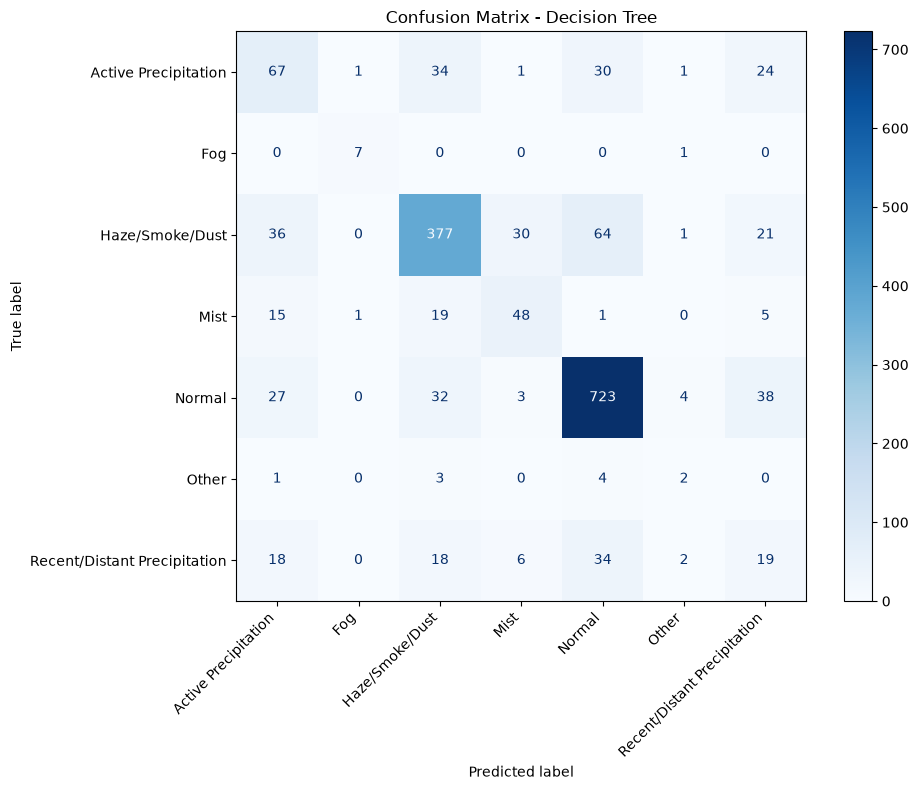

In [216]:
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - Decision Tree')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [217]:
cm_dt_df = pd.DataFrame(cm_dt, index=target_names, columns=target_names)
cm_dt_df.index.name = 'Actual'
cm_dt_df.columns.name = 'Predicted'
display(cm_dt_df)

Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,67,1,34,1,30,1,24
Fog,0,7,0,0,0,1,0
Haze/Smoke/Dust,36,0,377,30,64,1,21
Mist,15,1,19,48,1,0,5
Normal,27,0,32,3,723,4,38
Other,1,0,3,0,4,2,0
Recent/Distant Precipitation,18,0,18,6,34,2,19


**RANDOM FOREST**

In [218]:
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=class_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=target_names
)

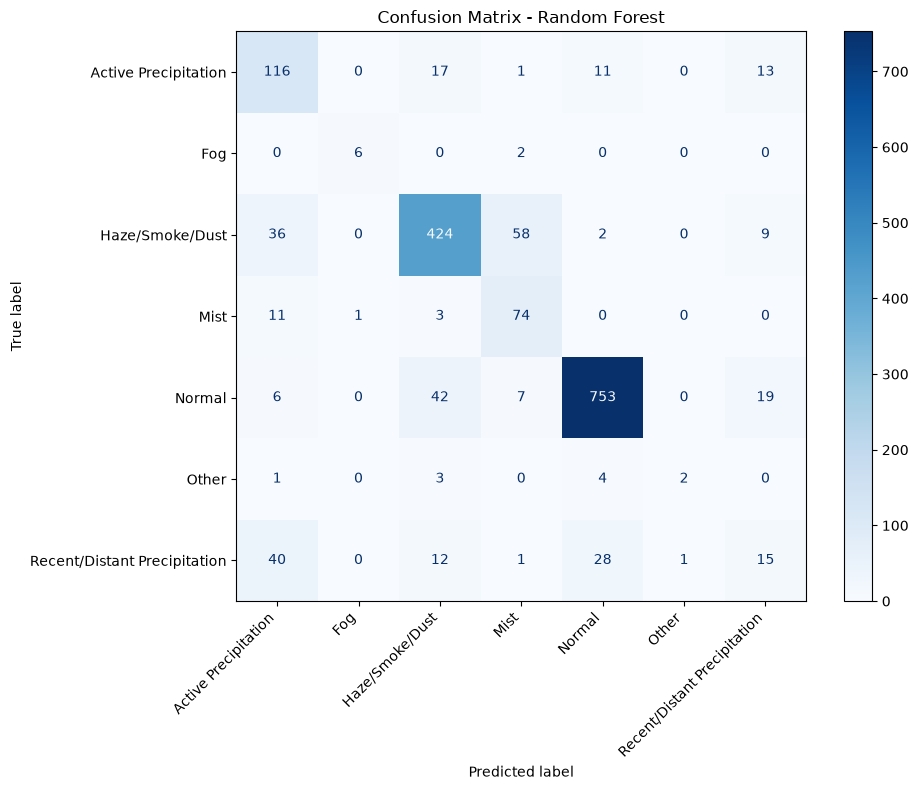

In [219]:
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - Random Forest')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [220]:
cm_rf_df = pd.DataFrame(cm_rf, index=target_names, columns=target_names)
cm_rf_df.index.name = 'Actual'
cm_rf_df.columns.name = 'Predicted'
display(cm_rf_df)

Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,116,0,17,1,11,0,13
Fog,0,6,0,2,0,0,0
Haze/Smoke/Dust,36,0,424,58,2,0,9
Mist,11,1,3,74,0,0,0
Normal,6,0,42,7,753,0,19
Other,1,0,3,0,4,2,0
Recent/Distant Precipitation,40,0,12,1,28,1,15


**XGBOOST**

In [221]:
cm_xgb = confusion_matrix(y_test, y_pred_xgb, labels=class_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=target_names
)

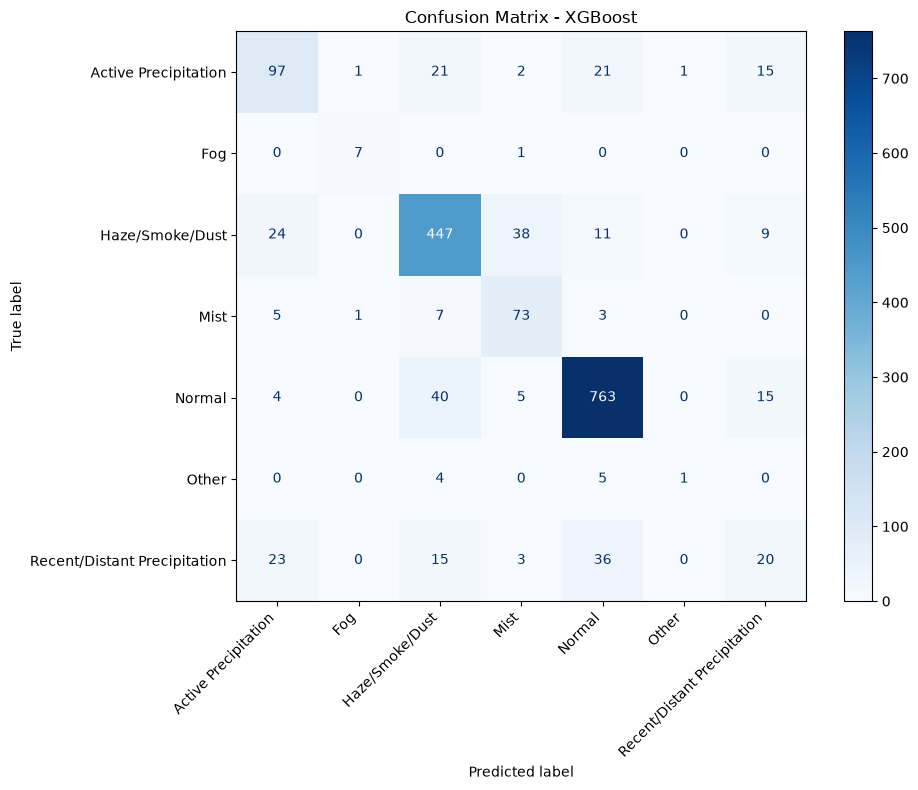

In [222]:
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - XGBoost')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [223]:
cm_xgb_df = pd.DataFrame(cm_xgb, index=target_names, columns=target_names)
cm_xgb_df.index.name = 'Actual'
cm_xgb_df.columns.name = 'Predicted'
display(cm_xgb_df)

Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,97,1,21,2,21,1,15
Fog,0,7,0,1,0,0,0
Haze/Smoke/Dust,24,0,447,38,11,0,9
Mist,5,1,7,73,3,0,0
Normal,4,0,40,5,763,0,15
Other,0,0,4,0,5,1,0
Recent/Distant Precipitation,23,0,15,3,36,0,20


**LIGHTGBM**

In [224]:
cm_lgbm = confusion_matrix(y_test, y_pred_lgbm, labels=class_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lgbm,
    display_labels=target_names
)

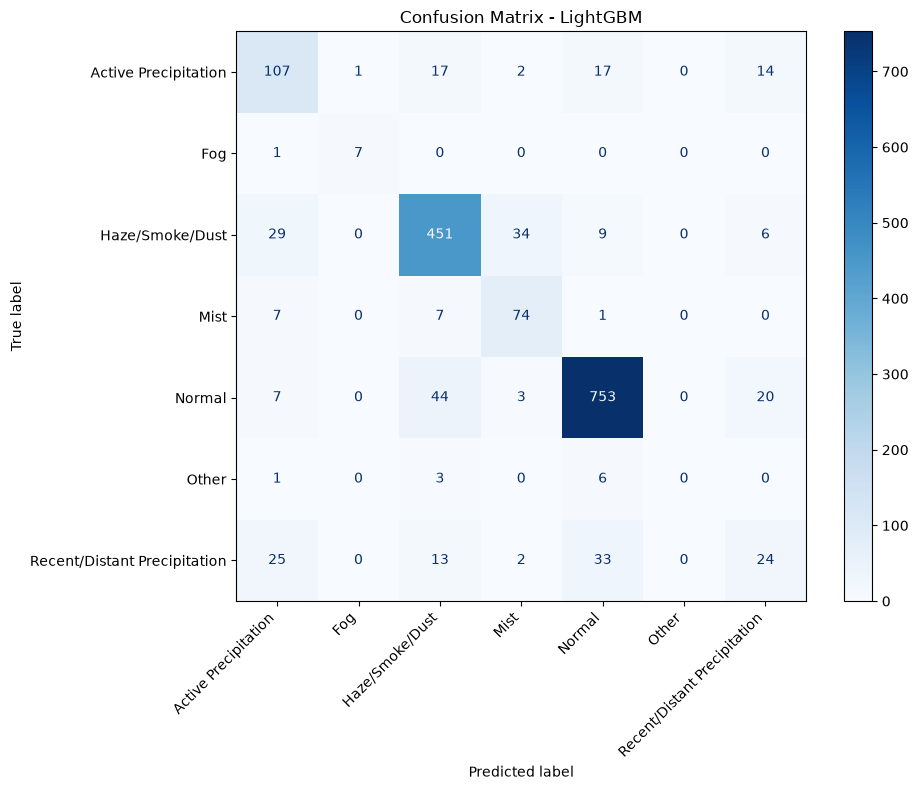

In [225]:
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - LightGBM')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [226]:
cm_lgbm_df = pd.DataFrame(cm_lgbm, index=target_names, columns=target_names)
cm_lgbm_df.index.name = 'Actual'
cm_lgbm_df.columns.name = 'Predicted'
display(cm_lgbm_df)

Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,107,1,17,2,17,0,14
Fog,1,7,0,0,0,0,0
Haze/Smoke/Dust,29,0,451,34,9,0,6
Mist,7,0,7,74,1,0,0
Normal,7,0,44,3,753,0,20
Other,1,0,3,0,6,0,0
Recent/Distant Precipitation,25,0,13,2,33,0,24


**Notes:**

- Berdasarkan jumlah prediksi benar pada diagonal utama (*confusion matrix*), ketiga model *ensemble* mencatatkan peningkatan akurasi klasifikasi yang jauh lebih tinggi dibandingkan skenario tanpa fitur lag: **LightGBM (`1.416` dari `1.718` data uji)**, **XGBoost (`1.408` data)**, dan **Random Forest (`1.390` data)**, sedangkan **Decision Tree** tunggal memperoleh **`1.243` data**.
- **Kelas dengan pemisahan paling stabil:**
  - `Normal` (`827` sampel) dikenali tepat sebanyak **`723–763` observasi** (tertinggi pada XGBoost sebanyak `763` benar), dengan kesalahan prediksi paling banyak bergeser ke `Haze/Smoke/Dust` (`32–44` sampel) dan `Recent/Distant Precipitation` (`15–38` sampel).
  - `Haze/Smoke/Dust` (`529` sampel) dikenali tepat sebanyak **`424–451` observasi** pada model *ensemble* (tertinggi pada LightGBM sebanyak `451` benar). Berbeda dengan model tanpa fitur lag, tumpang tindih antara `Haze/Smoke/Dust` dan `Normal` pada model *ensemble* turun drastis menjadi hanya `2–11` sampel, meskipun pergeseran ke `Mist` (`34–58` sampel) dan `Active Precipitation` (`24–36` sampel) masih muncul saat kelembapan meningkat.
- **Performa pada `Mist` (`89` sampel) dan `Fog` (`8` sampel):**
  - Penambahan riwayat waktu mengangkat pengenalan kelas `Mist` secara signifikan pada ketiga model *ensemble*, dengan **`73–74` dari `89` observasi** terprediksi benar (*recall* `82,0%–83,1%`), jauh melampaui Decision Tree tunggal (`48` benar).
  - Pada kelas minoritas `Fog` (`8` sampel uji), Decision Tree, XGBoost, dan LightGBM masing-masing mengenali **`7` dari `8` observasi** dengan tepat, sementara Random Forest mengenali **`6` dari `8` observasi** (`2` sampel bergeser ke `Mist` yang memiliki kemiripan kondisi kelembapan jenuh dan visibilitas rendah).
- **Pola kesalahan pada kelompok hujan (`Active Precipitation` & `Recent/Distant Precipitation`):**
  - `Active Precipitation` (`158` sampel) paling banyak dikenali oleh **Random Forest (`116` benar)** dan **LightGBM (`107` benar)**, diikuti XGBoost (`97` benar) dan Decision Tree (`67` benar), dengan sisa kesalahan umumnya bergeser ke `Haze/Smoke/Dust` (`17–34` sampel), `Normal` (`11–30` sampel), dan `Recent/Distant Precipitation` (`13–24` sampel).
  - `Recent/Distant Precipitation` (`97` sampel) tetap menjadi kelas yang paling sulit dipisahkan, meskipun jumlah prediksi benarnya meningkat menjadi **`24` sampel pada LightGBM** dan **`20` sampel pada XGBoost**. Sebagian besar observasi yang meleset terklasifikasi sebagai `Normal` (`28–36` sampel), `Active Precipitation` (`18–40` sampel—terutama pada Random Forest sebanyak `40` sampel), dan `Haze/Smoke/Dust` (`12–18` sampel), karena fenomena hujan yang baru berlalu atau berada di kejauhan sering kali tidak lagi terukur secara langsung di stasiun pada jam pengamatan.
- **Perkembangan pada kelas `Other` (`10` sampel):** Dengan tambahan konteks temporal ($t-1$ hingga $t-3$), **Random Forest (`2` benar dari `3` prediksi, hanya `1` *false positive*)**, **Decision Tree (`2` benar dari `11` prediksi)**, dan **XGBoost (`1` benar dari `2` prediksi)** mulai mampu menangkap pola sebagian observasi `Other`, sedangkan **LightGBM (`0` prediksi)** belum menghasilkan prediksi pada kelas ini. Mayoritas observasi aktual `Other` masih terklasifikasi sebagai `Normal` (`4–6` sampel) dan `Haze/Smoke/Dust` (`3–4` sampel) karena sifatnya yang merupakan kategori gabungan dari berbagai fenomena langka dengan karakteristik meteorologi yang heterogen.

### Model Comparison

Merangkum metrik evaluasi utama serta nilai *F1-Score* pada kelas-kelas menantang (kelas minoritas dan kelompok hujan) dari keempat model *baseline* ke dalam satu tabel perbandingan guna menentukan kandidat model terbaik sebelum memasuki tahap optimasi (*hyperparameter tuning*).

In [227]:
preds = {
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'XGBoost': y_pred_xgb,
    'LightGBM': y_pred_lgbm
}

In [228]:
rows = {}

for name, y_pred in preds.items():
    report = classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        target_names=target_names,
        output_dict=True,
        zero_division=0
    )

    rows[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Macro F1': f1_score(y_test, y_pred, average='macro', zero_division=0),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
        'Fog F1': report['Fog']['f1-score'],
        'Mist F1': report['Mist']['f1-score'],
        'Other F1': report['Other']['f1-score'],
        'Active Precip F1': report['Active Precipitation']['f1-score'],
        'Recent/Distant Precip F1': report['Recent/Distant Precipitation']['f1-score']
    }

In [229]:
comparison_df = pd.DataFrame(rows).T
display(comparison_df.round(4))

,Accuracy,Macro F1,Balanced Accuracy,Fog F1,Mist F1,Other F1,Active Precip F1,Recent/Distant Precip F1
Decision Tree,0.7235,0.5376,0.5459,0.8235,0.5424,0.1905,0.4161,0.1863
Random Forest,0.8091,0.6175,0.6260,0.8000,0.6379,0.3077,0.6304,0.1961
XGBoost,0.8196,0.6170,0.6261,0.8235,0.6919,0.1667,0.6238,0.2564
LightGBM,0.8242,0.6143,0.6277,0.8750,0.7255,0.0000,0.6388,0.2981


**Notes:**

- Secara keseluruhan, ketiga algoritma *ensemble* (**Random Forest**, **XGBoost**, dan **LightGBM**) jauh mengungguli **Decision Tree** tunggal di seluruh metrik evaluasi, dengan peningkatan *Accuracy* sebesar **`8,56%–10,07%`** (`0,7235` menjadi `0,8091–0,8242`) dan peningkatan *Macro F1-Score* sebesar **`0,0767–0,0799`** (`0,5376` menjadi `0,6143–0,6175`). Penambahan fitur riwayat waktu ($t-1, t-2, t-3$) dan laju perubahan ($\Delta$) juga terbukti mengangkat *Macro F1-Score* model *ensemble* secara signifikan dibandingkan eksperimen tanpa fitur lag (`0,5584–0,5683` menjadi `0,6143–0,6175`).
- Masing-masing kandidat model *ensemble* menunjukkan keunggulan yang saling melengkapi pada tahap *baseline*:
  - **Random Forest** mencatatkan *Macro F1-Score* tertinggi (**`0,6175`**), terutama ditopang oleh kemampuannya mengenali kelas minoritas langka `Other` (*F1* = **`0,3077`**) serta performa solid pada `Active Precipitation` (`0,6304`).
  - **LightGBM** meraih *Accuracy* (**`0,8242`**) dan *Balanced Accuracy* (**`0,6277`**) tertinggi, sekaligus unggul pada empat dari lima kelas menantang: `Fog` (**`0,8750`**), `Mist` (**`0,7255`**), `Active Precipitation` (**`0,6388`**), dan `Recent/Distant Precipitation` (**`0,2981`**). Nilai *Macro F1-Score*-nya (`0,6143`) tertahan tipis di bawah Random Forest dan XGBoost semata-mata karena belum mengenali kelas `Other` (`0,0000`).
  - **XGBoost** tampil paling stabil di seluruh aspek (*Macro F1* = **`0,6170`**, *Balanced Accuracy* = **`0,6261`**, *Accuracy* = **`0,8196`**), mampu mengenali sebagian kelas `Other` (`0,1667`) sekaligus menjaga kinerja tinggi pada `Fog` (`0,8235`), `Mist` (`0,6919`), `Active Precipitation` (`0,6238`), dan `Recent/Distant Precipitation` (`0,2564`).
- Berdasarkan hasil evaluasi ini, **Random Forest**, **XGBoost**, dan **LightGBM** dipilih untuk dilanjutkan ke tahap **Bab 10 (*Hyperparameter Tuning*)** dengan tiga fokus utama:
  1. **Menekan *overfitting*:** Mempersempit kesenjangan antara performa data latih (*Macro F1* = `0,9821–0,9999`) dan data uji (`0,6143–0,6175`) melalui pembatasan kedalaman/jumlah daun pohon serta regularisasi fitur.
  2. **Meningkatkan pemisahan `Recent/Distant Precipitation` (*F1* = `0,1961–0,2981`):** Mempertajam pemanfaatan fitur laju perubahan ($\Delta$) dan lag agar model lebih peka membedakan transisi pascahujan dari kondisi `Normal`, `Active Precipitation`, dan `Haze/Smoke/Dust`.
  3. **Menjaga stabilitas deteksi kelas minoritas (`Fog` dan `Other`):** Memastikan regularisasi tidak menghilangkan sensitivitas model terhadap kelas dengan jumlah sampel sangat terbatas.

# 10. Model Selection

Tahap ini memilih kandidat algoritma terbaik berdasarkan evaluasi *Stratified Group Cross-Validation* (`5-Fold`) dan evaluasi *Out-of-Fold* (OOF) pada data latih (`X_train`, `y_train` sebanyak **7.039 observasi** dengan **52 fitur prediktor**). Seluruh proses validasi dilakukan tanpa menyentuh data uji (`X_test`, `y_test`) agar keputusan pemilihan model bebas dari kebocoran informasi (*data leakage*).

## 10.1 Cross Validation Comparison

Membandingkan performa dan kestabilan keempat algoritma (*Decision Tree*, *Random Forest*, *XGBoost*, dan *LightGBM*) menggunakan **5-Fold StratifiedGroupKFold** berdasarkan kolom `date` pada `train_df`. Pengelompokan berdasarkan tanggal memastikan seluruh observasi jam dalam hari yang sama selalu berada pada *fold* pelatihan atau validasi yang sama. Bobot kelas dihitung ulang di dalam setiap *fold* pelatihan agar evaluasi validasi tetap objektif.

In [230]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [231]:
cv_splits = list(
    cv.split(
        X_train,
        y_train,
        groups=train_df['date']
    )
)
print(f"Jumlah fold : {len(cv_splits)}")

Jumlah fold : 5


In [232]:
for fold, (tr_idx, val_idx) in enumerate(cv_splits, start=1):
    print(f"Fold {fold} -> Train: {len(tr_idx)} baris | Val: {len(val_idx)} baris")

Fold 1 -> Train: 5623 baris | Val: 1416 baris
Fold 2 -> Train: 5623 baris | Val: 1416 baris
Fold 3 -> Train: 5640 baris | Val: 1399 baris
Fold 4 -> Train: 5623 baris | Val: 1416 baris
Fold 5 -> Train: 5647 baris | Val: 1392 baris


In [233]:
candidates = {
    'Decision Tree': dt_model,
    'Random Forest': rf_model,
    'XGBoost': xgb_model,
    'LightGBM': lgbm_model
}

In [234]:
n_classes = len(label_map)
class_labels = list(range(n_classes))

In [235]:
cv_results = []

for name, model in candidates.items():
    fold_scores = []

    for fold, (tr_idx, val_idx) in enumerate(cv_splits, start=1):
        X_tr = X_train.iloc[tr_idx]
        X_val = X_train.iloc[val_idx]
        y_tr = y_train.iloc[tr_idx]
        y_val = y_train.iloc[val_idx]

        # Clone model agar setiap fold dilatih dari awal
        m = clone(model)

        # Hitung class weight khusus pada data latih fold ini
        fold_classes = np.unique(y_tr)
        weights = compute_class_weight(
            class_weight='balanced',
            classes=fold_classes,
            y=y_tr
        )
        fold_class_weights = dict(zip(fold_classes, weights))

        if name == 'XGBoost':
            sample_weights = y_tr.map(fold_class_weights)
            m.fit(X_tr, y_tr, sample_weight=sample_weights)
        else:
            m.set_params(class_weight=fold_class_weights)
            m.fit(X_tr, y_tr)

        y_val_pred = m.predict(X_val)

        score = f1_score(
            y_val,
            y_val_pred,
            labels=class_labels,
            average='macro',
            zero_division=0
        )
        fold_scores.append(score)

        print(f"{name:<15} | Fold {fold}: Macro F1 = {score:.4f}")

    cv_results.append({
        'Model': name,
        'Macro F1 Mean': np.mean(fold_scores),
        'Macro F1 Std': np.std(fold_scores, ddof=1)
    })
    print("-" * 45)

Decision Tree   | Fold 1: Macro F1 = 0.4873
Decision Tree   | Fold 2: Macro F1 = 0.4542
Decision Tree   | Fold 3: Macro F1 = 0.5118
Decision Tree   | Fold 4: Macro F1 = 0.4944
Decision Tree   | Fold 5: Macro F1 = 0.5101
---------------------------------------------
Random Forest   | Fold 1: Macro F1 = 0.5771
Random Forest   | Fold 2: Macro F1 = 0.5452
Random Forest   | Fold 3: Macro F1 = 0.5017
Random Forest   | Fold 4: Macro F1 = 0.5730
Random Forest   | Fold 5: Macro F1 = 0.5971
---------------------------------------------
XGBoost         | Fold 1: Macro F1 = 0.6004
XGBoost         | Fold 2: Macro F1 = 0.5920
XGBoost         | Fold 3: Macro F1 = 0.5816
XGBoost         | Fold 4: Macro F1 = 0.5945
XGBoost         | Fold 5: Macro F1 = 0.6219
---------------------------------------------
LightGBM        | Fold 1: Macro F1 = 0.6236
LightGBM        | Fold 2: Macro F1 = 0.6004
LightGBM        | Fold 3: Macro F1 = 0.5713
LightGBM        | Fold 4: Macro F1 = 0.6079
LightGBM        | Fold 5: 

In [236]:
cv_comparison_df = (
    pd.DataFrame(cv_results)
    .set_index('Model')
    .sort_values('Macro F1 Mean', ascending=False)
)
display(cv_comparison_df.round(4))

,Macro F1 Mean,Macro F1 Std
Model,,
LightGBM,0.6035,0.0199
XGBoost,0.5981,0.0149
Random Forest,0.5588,0.0369
Decision Tree,0.4916,0.0233


**Notes:**

- Berdasarkan hasil evaluasi *5-Fold StratifiedGroupKFold* pada data latih (`7.039` observasi dengan `52` fitur), **LightGBM** memperoleh rata-rata *Macro F1-Score* tertinggi sebesar **`0,6035` (`± 0,0199`)**, diikuti sangat ketat oleh **XGBoost** sebesar **`0,5981` (`± 0,0149`)**. Kedua algoritma *gradient boosting* ini mengalami lonjakan performa signifikan dibandingkan skenario tanpa fitur lag (`0,5598` dan `0,5571`), sekaligus menunjukkan kestabilan antar-*fold* yang sangat baik (terutama XGBoost dengan standar deviasi terendah `0,0149`).
- **Random Forest** menempati peringkat ketiga dengan rata-rata *Macro F1-Score* sebesar **`0,5588` (`± 0,0369`)**, terpaut sekitar `0,039–0,045` di bawah XGBoost dan LightGBM. Penambahan 30 fitur lag yang saling berkorelasi membuat pemilihan acak sebagian fitur pada setiap percabangan (*feature subsampling*) di pohon Random Forest *default* kurang optimal dibandingkan mekanisme *gradient boosting* yang secara sekuensial memfokuskan pemisahan pada galat prediksi dan laju perubahan ($\Delta$).
- **Decision Tree** tunggal memperoleh performa terendah dengan rata-rata *Macro F1-Score* sebesar **`0,4916` (`± 0,0233`)**, dengan skor terendah pada *Fold* 2 (`0,4542`) dan tertinggi pada *Fold* 3 (`0,5118`).
- Variasi skor antar-*fold* terlihat pada **Fold 3** bagi model *ensemble* (`0,5017` pada Random Forest, `0,5713` pada LightGBM, dan `0,5816` pada XGBoost), yang umumnya dipengaruhi oleh komposisi sampel kelas minoritas (`Fog` dan `Other`) pada kelompok tanggal yang masuk ke dalam lipatan validasi tersebut.

## 10.2 Out-of-Fold Per-Class Evaluation

Mengevaluasi kemampuan setiap model dalam mengenali masing-masing dari 7 kelas fenomena meteorologi menggunakan prediksi *out-of-fold* (OOF) yang menggabungkan hasil validasi dari seluruh 5 *fold* pada data latih (**7.039 observasi**). Pendekatan ini memberikan gambaran performa per kelas dengan cakupan sampel yang jauh lebih besar (terutama untuk kelas minoritas seperti `Fog` dengan **42 sampel** dan `Other` dengan **44 sampel**) tanpa menyentuh data uji.

In [237]:
oof_predictions = {}

for name, model in candidates.items():
    oof_pred = np.full(len(y_train), -1, dtype=int)

    for fold, (tr_idx, val_idx) in enumerate(cv_splits, start=1):
        X_tr = X_train.iloc[tr_idx]
        X_val = X_train.iloc[val_idx]
        y_tr = y_train.iloc[tr_idx]

        # Clone model agar setiap fold dilatih secara independen
        m = clone(model)

        # Hitung class weight khusus pada fold pelatihan
        fold_classes = np.unique(y_tr)
        weights = compute_class_weight(
            class_weight='balanced',
            classes=fold_classes,
            y=y_tr
        )
        fold_class_weights = dict(zip(fold_classes, weights))

        if name == 'XGBoost':
            sample_weights = y_tr.map(fold_class_weights)
            m.fit(X_tr, y_tr, sample_weight=sample_weights)
        else:
            m.set_params(class_weight=fold_class_weights)
            m.fit(X_tr, y_tr)

        oof_pred[val_idx] = m.predict(X_val)

    # Pastikan seluruh 7.008 baris latih telah menerima prediksi OOF
    assert np.all(oof_pred != -1), f"Masih ada indeks yang belum terprediksi pada {name}!"
    oof_predictions[name] = oof_pred
    print(f"{name:<15}: OOF prediction selesai ({len(oof_pred)} baris)")

Decision Tree  : OOF prediction selesai (7039 baris)
Random Forest  : OOF prediction selesai (7039 baris)
XGBoost        : OOF prediction selesai (7039 baris)
LightGBM       : OOF prediction selesai (7039 baris)


In [238]:
oof_results = []
class_names = [inv_label_map[i] for i in range(n_classes)]

for name, y_pred in oof_predictions.items():
    report = classification_report(
        y_train,
        y_pred,
        labels=class_labels,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    for class_name in class_names:
        oof_results.append({
            'Model': name,
            'Class': class_name,
            'Precision': report[class_name]['precision'],
            'Recall': report[class_name]['recall'],
            'F1-Score': report[class_name]['f1-score'],
            'Support': int(report[class_name]['support'])
        })

oof_comparison_df = pd.DataFrame(oof_results)
display(
    oof_comparison_df
    .set_index(['Model', 'Class'])
    .round(4)
)

Precision  Recall  F1-Score  \
Model         Class                                                       
Decision Tree Active Precipitation             0.4498  0.4264    0.4378   
              Fog                              0.6500  0.6190    0.6341   
              Haze/Smoke/Dust                  0.7705  0.7607    0.7656   
              Mist                             0.5726  0.5599    0.5662   
              Normal                           0.8642  0.8706    0.8674   
              Other                            0.0000  0.0000    0.0000   
              Recent/Distant Precipitation     0.1635  0.1774    0.1702   
Random Forest Active Precipitation             0.5773  0.6871    0.6275   
              Fog                              0.8125  0.6190    0.7027   
              Haze/Smoke/Dust                  0.8101  0.8581    0.8334   
              Mist                             0.5533  0.7521    0.6375   
              Normal                           0.9410  0.8930    0.9163   
              Other                            0.0000  0.0000    0.0000   
              Recent/Distant Precipitation     0.2965  0.1722    0.2179   
XGBoost       Active Precipitation             0.6575  0.6242    0.6404   
              Fog                              0.7750  0.7381    0.7561   
              Haze/Smoke/Dust                  0.8091  0.8926    0.8488   
              Mist                             0.6414  0.7075    0.6728   
              Normal                           0.9304  0.9091    0.9196   
              Other                            0.2857  0.0455    0.0784   
              Recent/Distant Precipitation     0.3139  0.2211    0.2594   
LightGBM      Active Precipitation             0.6488  0.6488    0.6488   
              Fog                              0.9355  0.6905    0.7945   
              Haze/Smoke/Dust                  0.8073  0.8999    0.8511   
              Mist                             0.6933  0.7242    0.7084   
              Normal                           0.9281  0.9085    0.9182   
              Other                            0.2500  0.0227    0.0417   
              Recent/Distant Precipitation     0.3498  0.2185    0.2690   

                                            Support  
Model         Class                                  
Decision Tree Active Precipitation              652  
              Fog                                42  
              Haze/Smoke/Dust                  2198  
              Mist                              359  
              Normal                           3355  
              Other                              44  
              Recent/Distant Precipitation      389  
Random Forest Active Precipitation              652  
              Fog                                42  
              Haze/Smoke/Dust                  2198  
              Mist                              359  
              Normal                           3355  
              Other                              44  
              Recent/Distant Precipitation      389  
XGBoost       Active Precipitation              652  
              Fog                                42  
              Haze/Smoke/Dust                  2198  
              Mist                              359  
              Normal                           3355  
              Other                              44  
              Recent/Distant Precipitation      389  
LightGBM      Active Precipitation              652  
              Fog                                42  
              Haze/Smoke/Dust                  2198  
              Mist                              359  
              Normal                           3355  
              Other                              44  
              Recent/Distant Precipitation      389

**Ringkasan OOF Macro F1 keseluruhan untuk setiap model**

In [239]:
oof_macro_f1 = [
    {
        'Model': name,
        'OOF Macro F1': f1_score(
            y_train,
            y_pred,
            labels=class_labels,
            average='macro',
            zero_division=0
        )
    }
    for name, y_pred in oof_predictions.items()
]

oof_macro_f1_df = (
    pd.DataFrame(oof_macro_f1)
    .set_index('Model')
    .sort_values('OOF Macro F1', ascending=False)
)

display(oof_macro_f1_df.round(4))

,OOF Macro F1
Model,
LightGBM,0.6045
XGBoost,0.5965
Random Forest,0.5622
Decision Tree,0.4916


**Notes:**

- Berdasarkan evaluasi *Out-of-Fold* (OOF) secara menyeluruh pada **7.039 observasi** data latih (`52` fitur), **LightGBM** memperoleh *OOF Macro F1-Score* tertinggi sebesar **`0,6045`**, diikuti sangat ketat oleh **XGBoost (`0,5965`)**. Kedua algoritma *gradient boosting* ini unggul sekitar `0,034–0,042` poin di atas **Random Forest (`0,5622`)**, sedangkan **Decision Tree** tunggal tertinggal jauh di angka **`0,4916`**.
- **Keunggulan spesifik tiap model *ensemble* per kelas:**
  - **LightGBM** mendominasi pada lima dari tujuh kelas sekaligus, yakni `Haze/Smoke/Dust` (*F1* = **`0,8511`**, *recall* `0,8999`), kelas minoritas `Fog` (*F1* = **`0,7945`** dengan *precision* tertinggi `0,9355`), `Mist` (*F1* = **`0,7084`**), `Active Precipitation` (*F1* = **`0,6488`**), serta kelas transisi `Recent/Distant Precipitation` (*F1* = **`0,2690`**, *precision* `0,3498`).
  - **XGBoost** mencatatkan performa tertinggi pada kelas mayoritas `Normal` (*F1* = **`0,9196`**) dan kelas langka `Other` (*F1* = **`0,0784`**, *precision* `0,2857`), sekaligus meraih *recall* tertinggi pada `Fog` (`0,7381`) dan `Recent/Distant Precipitation` (`0,2211`).
  - **Random Forest** menunjukkan *precision* tertinggi pada `Normal` (`0,9410`) serta *recall* tertinggi pada `Mist` (`0,7521`) dan `Active Precipitation` (`0,6871`), namun skor keseluruhannya tertahan karena belum mengenali kelas `Other` pada validasi OOF (`0,0000`) dan memiliki presisi lebih rendah pada pemisahan `Mist` (`0,5533`).
- **Tantangan yang masih konsisten di seluruh model:** Kelas `Other` (`44` sampel) tetap sangat sulit dipisahkan dengan *F1-Score* di bawah `0,08` (`0,0784` pada XGBoost, `0,0417` pada LightGBM, serta `0,0000` pada Random Forest dan Decision Tree) karena sifatnya yang merupakan kategori gabungan dari berbagai fenomena cuaca langka yang heterogen. Sementara itu, meskipun `Recent/Distant Precipitation` (`389` sampel) meningkat ke kisaran *F1* = `0,2594–0,2690` pada model *gradient boosting* berkat fitur lag dan laju perubahan ($\Delta$), tumpang tindih karakteristik permukaan pascahujan dengan kondisi `Normal` dan `Active Precipitation` masih menjadi ruang perbaikan utama pada tahap optimasi.

## 10.3 Model Selection Decision

Menetapkan kandidat model yang akan dilanjutkan ke tahap *hyperparameter tuning* berdasarkan rata-rata dan kestabilan *Macro F1-Score* pada *5-Fold StratifiedGroupKFold* serta kinerja per kelas pada evaluasi *Out-of-Fold* (OOF) di atas **7.039 observasi** data latih.

**Notes:**

- Ketiga algoritma *ensemble* (**LightGBM**, **XGBoost**, dan **Random Forest**) jauh melampaui **Decision Tree** tunggal, baik pada rata-rata *Cross-Validation* maupun evaluasi *Out-of-Fold* (OOF).
- **LightGBM** menempati peringkat pertama pada rata-rata *CV Macro F1-Score* (**`0,6035 ± 0,0199`**) dan *OOF Macro F1-Score* (**`0,6045`**), sekaligus unggul pada lima kelas (`Active Precipitation`, `Fog`, `Haze/Smoke/Dust`, `Mist`, dan `Recent/Distant Precipitation`).
- **XGBoost** menempati peringkat kedua dengan selisih sangat tipis (*CV Macro F1* = **`0,5981 ± 0,0149`**; *OOF Macro F1* = **`0,5965`**), mencatatkan standar deviasi antar-*fold* paling stabil (`0,0149`), serta unggul pada kelas `Normal` dan `Other`.
- **Random Forest** (*CV Macro F1* = **`0,5588 ± 0,0369`**; *OOF Macro F1* = **`0,5622`**) tetap diikutsertakan dalam tahap *hyperparameter tuning* karena memiliki performa *baseline* data uji yang kompetitif (`0,6175`) serta potensi peningkatan signifikan melalui pengaturan pembatasan fitur (`max_features`) dan kedalaman pohon (`max_depth`) pada ruang `52` prediktor.
- **Decision Tree** tidak dilanjutkan ke tahap optimasi karena memiliki rata-rata *CV Macro F1-Score* (`0,4916`) dan *OOF Macro F1-Score* (`0,4916`) yang terpaut sekitar `0,07–0,11` di bawah ketiga model *ensemble*, sehingga hanya dipertahankan sebagai acuan *single-tree baseline*.
- Dengan demikian, **LightGBM**, **XGBoost**, dan **Random Forest** dipilih untuk masuk ke tahap **Bab 11 (*Hyperparameter Tuning*)**. Model terbaik hasil *tuning* akan dipilih berdasarkan rata-rata *Macro F1-Score* pada *5-Fold StratifiedGroupKFold*, kemudian dievaluasi satu kali secara final pada data uji (`X_test`, `y_test`).

| Model | CV Macro F1 (Mean ± Std) | OOF Macro F1 | Keputusan |
| :--- | :---: | :---: | :--- |
| **LightGBM** | `0,6035 ± 0,0199` | `0,6045` | Dilanjutkan ke *Hyperparameter Tuning* |
| **XGBoost** | `0,5981 ± 0,0149` | `0,5965` | Dilanjutkan ke *Hyperparameter Tuning* |
| **Random Forest** | `0,5588 ± 0,0369` | `0,5622` | Dilanjutkan ke *Hyperparameter Tuning* |
| **Decision Tree** | `0,4916 ± 0,0233` | `0,4916` | Tidak dilanjutkan (dipertahankan sebagai *baseline*) |

# 11. Hyperparameter Tuning

Tahap ini melakukan optimasi *hyperparameter* pada ketiga kandidat algoritma *ensemble* terpilih dari Bab 10 (**Random Forest**, **LightGBM**, dan **XGBoost**) untuk meningkatkan kemampuan klasifikasi pada **7 kelas fenomena meteorologi** sekaligus menekan indikasi *overfitting* yang teramati pada model *baseline*.

Proses pencarian dilakukan menggunakan **Randomized Search Cross-Validation (`RandomizedSearchCV`)** dengan skema **5-Fold StratifiedGroupKFold (`cv_splits`)** berdasarkan tanggal pengamatan dan **Macro F1-Score** sebagai metrik optimasi utama. Pembobotan kelas seimbang tetap diterapkan secara dinamis di dalam setiap *fold* pelatihan agar bebas dari kebocoran informasi (*data leakage*).

## 11.1 Define Search Space

Menentukan ruang distribusi *hyperparameter* untuk masing-masing algoritma dengan fokus pada pengendalian kompleksitas pohon, laju pembelajaran (*learning rate*), *subsampling*, dan regularisasi guna mengurangi selisih performa antara data latih dan data validasi:

- **Random Forest:** Mengatur jumlah pohon (`n_estimators`), membatasi kedalaman pohon (`max_depth`), menaikkan batas minimum sampel untuk pemisahan dan daun (`min_samples_split`, `min_samples_leaf`), serta mengatur proporsi fitur per pemisahan (`max_features`).
- **XGBoost:** Mengatur jumlah pohon (`n_estimators`), laju pembelajaran (`learning_rate`), kedalaman maksimum (`max_depth`), bobot minimum anak simpul (`min_child_weight`), proporsi sampel dan fitur (`subsample`, `colsample_bytree`), serta penalti regularisasi (`reg_lambda`, `gamma`).
- **LightGBM:** Mengatur jumlah iterasi (`n_estimators`), laju pembelajaran (`learning_rate`), jumlah maksimum daun (`num_leaves`), jumlah minimum sampel per daun (`min_child_samples`), *subsampling* baris dan fitur (`subsample`, `colsample_bytree`, `subsample_freq`), serta regularisasi L2 (`reg_lambda`).

### Random Forest

- `n_estimators`: jumlah pohon keputusan yang dibangun dalam model.
- `max_depth`: kedalaman maksimum setiap pohon. Pembatasan kedalaman membantu mengurangi kompleksitas model.
- `min_samples_leaf`: jumlah minimum sampel yang harus terdapat pada suatu leaf. Nilai lebih besar dapat menghasilkan struktur pohon yang lebih sederhana.
- `min_samples_split`: jumlah minimum sampel yang diperlukan untuk membagi suatu node.
- `max_features`: jumlah fitur yang dipertimbangkan ketika mencari pemisahan terbaik pada setiap node.

In [240]:
rf_param_dist = {
    'n_estimators': randint(200, 601),
    'max_depth': [8, 10, 12, 15, 18, 20, None],
    'min_samples_split': randint(2, 21),
    'min_samples_leaf': randint(1, 9),
    'max_features': [0.5, 0.7, 'sqrt', 1.0]
}

### XGBoost

- `n_estimators`: jumlah pohon yang dibangun secara bertahap.
- `learning_rate`: mengatur kontribusi setiap pohon baru terhadap model secara keseluruhan.
- `max_depth`: membatasi kedalaman pohon untuk mengendalikan kompleksitas model.
- `min_child_weight`: menentukan batas minimum bobot sampel pada child node agar suatu pemisahan dapat dilakukan.
- `subsample`: proporsi sampel training yang digunakan untuk membangun setiap pohon.
- `colsample_bytree`: proporsi fitur yang digunakan untuk membangun setiap pohon.
- `reg_lambda`: parameter regularisasi L2 yang membantu mengendalikan kompleksitas model.

In [241]:
xgb_param_dist = {
    'n_estimators': randint(200, 801),
    'learning_rate': loguniform(0.02, 0.1),
    'max_depth': randint(2, 6),
    'min_child_weight': randint(5, 41),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'reg_lambda': loguniform(5, 50),
    'gamma': uniform(0, 2)
}

### LightGBM

- `n_estimators`: jumlah boosting iteration atau pohon yang dibangun.
- `learning_rate`: mengatur kontribusi setiap pohon baru dalam proses boosting.
- `num_leaves`: jumlah maksimum leaf dalam satu pohon. Parameter ini berpengaruh terhadap kompleksitas model.
- `min_child_samples`: jumlah minimum sampel yang harus terdapat pada setiap leaf.
- `subsample`: proporsi sampel training yang digunakan dalam setiap iterasi.
- `colsample_bytree`: proporsi fitur yang digunakan dalam pembangunan setiap pohon.
- `reg_lambda`: parameter regularisasi L2 untuk membantu mengurangi kompleksitas model.
- `subsample_freq`: frekuensi penerapan subsampling. Nilai `1` berarti subsampling dilakukan pada setiap iterasi boosting.

In [242]:
lgbm_param_dist = {
    'n_estimators': randint(200, 601),
    'learning_rate': loguniform(0.03, 0.2),
    'num_leaves': randint(15, 64),
    'min_child_samples': randint(10, 51),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'reg_lambda': uniform(0, 10),
    'subsample_freq': [1]
}

## 11.2 Randomized Search CV

Melakukan pencarian kombinasi *hyperparameter* terbaik menggunakan `RandomizedSearchCV` dengan **`n_iter=50` kandidat acak** pada setiap model (`250` total *fit* per algoritma pada 5 *fold*).

Untuk menjaga konsistensi penanganan ketidakseimbangan kelas pada seluruh algoritma, **Random Forest** dan **LightGBM** menggunakan `class_weight='balanced'` yang otomatis menghitung bobot berdasarkan proporsi label latih di tiap *fold*, sedangkan **XGBoost** dibungkus menggunakan `FoldBalancedXGBClassifier` agar perhitungan `sample_weight` juga dilakukan secara terisolasi di dalam masing-masing *fold* pelatihan.

In [243]:
class FoldBalancedXGBClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, estimator):
        self.estimator = estimator

    def fit(self, X, y):
        self.estimator_ = clone(self.estimator)
        fold_classes = np.unique(y)
        weights = compute_class_weight(
            class_weight='balanced',
            classes=fold_classes,
            y=y
        )
        weight_dict = dict(zip(fold_classes, weights))
        sample_weights = np.array([weight_dict[label] for label in y])

        self.estimator_.fit(X, y, sample_weight=sample_weights)
        self.classes_ = self.estimator_.classes_
        return self

    def predict(self, X):
        return self.estimator_.predict(X)

    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)

In [244]:
search_configs = {
    'Random Forest': {
        'model': rf_model,
        'params': rf_param_dist
    },
    'XGBoost': {
        'model': xgb_model,
        'params': xgb_param_dist
    },
    'LightGBM': {
        'model': lgbm_model,
        'params': lgbm_param_dist
    }
}

In [245]:
search_results = {}
best_estimators = {}

for name, config in search_configs.items():
    print(f"\n{'='*55}")
    print(f"Hyperparameter Tuning: {name}")
    print(f"{'='*55}")

    model = clone(config['model'])
    param_dist = config['params'].copy()

    if name == 'XGBoost':
        base_model = clone(model)
        base_model.set_params(n_jobs=1)
        model = FoldBalancedXGBClassifier(estimator=base_model)
        param_dist = {
            f'estimator__{param}': values
            for param, values in param_dist.items()
        }
    else:
        model.set_params(
            class_weight='balanced',
            n_jobs=1
        )

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_dist,
        n_iter=50,
        scoring='f1_macro',
        cv=cv_splits,
        random_state=42,
        n_jobs=-1,
        refit=True,
        verbose=1,
        return_train_score=True
    )

    search.fit(X_train, y_train)

    search_results[name] = search
    best_estimators[name] = search.best_estimator_

    print(f"\nBest CV Macro F1 ({name}): {search.best_score_:.4f}")
    print("Best Parameters:")
    print(search.best_params_)


Hyperparameter Tuning: Random Forest
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Best CV Macro F1 (Random Forest): 0.5864
Best Parameters:
{'max_depth': None, 'max_features': 0.7, 'min_samples_leaf': 3, 'min_samples_split': 2, 'n_estimators': 204}

Hyperparameter Tuning: XGBoost
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Best CV Macro F1 (XGBoost): 0.6112
Best Parameters:
{'estimator__colsample_bytree': np.float64(0.8123738333268545), 'estimator__gamma': np.float64(0.8955663291461833), 'estimator__learning_rate': np.float64(0.04869514692350742), 'estimator__max_depth': 4, 'estimator__min_child_weight': 8, 'estimator__n_estimators': 638, 'estimator__reg_lambda': np.float64(28.879496660562587), 'estimator__subsample': np.float64(0.6950550175969599)}

Hyperparameter Tuning: LightGBM
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Best CV Macro F1 (LightGBM): 0.6145
Best Parameters:
{'colsample_bytree': np.float64(0.9442922333025374), 

**Notes:**

- Setelah mengevaluasi 50 kombinasi *hyperparameter* (`250` total *fit* per model pada *5-Fold StratifiedGroupKFold* di ruang `52` fitur), **seluruh kandidat model *ensemble* berhasil melampaui skor CV *baseline*-nya** (10.1):
  - **LightGBM** meraih rata-rata *CV Macro F1-Score* tertinggi sebesar **`0,6145`** (meningkat **`+0,0110`** dari skor *baseline* `0,6035`), menggunakan laju pembelajaran rendah (`learning_rate = 0,0304`), `n_estimators = 336`, `num_leaves = 51`, `min_child_samples = 17`, proporsi fitur tinggi (`colsample_bytree = 0,9443`), serta regularisasi L2 (`reg_lambda = 6,92`).
  - **XGBoost** menempati peringkat kedua dengan selisih yang sangat tipis di angka **`0,6112`** (meningkat **`+0,0131`** dari *baseline* `0,5981`), menggunakan `learning_rate = 0,0487`, kedalaman pohon moderat (`max_depth = 4`), `n_estimators = 638`, `min_child_weight = 8`, serta regularisasi kuat (`reg_lambda = 28,88` dan `gamma = 0,8956`).
  - **Random Forest** mencatatkan lonjakan peningkatan terbesar dari *baseline*-nya sebesar **`+0,0276`**, naik dari `0,5588` menjadi **`0,5864`**. Kombinasi `max_features = 0,7` (mempertimbangkan ~36 dari 52 fitur pada tiap pemisahan, jauh lebih luas dibandingkan bawaan `sqrt`), `max_depth = None`, dan `min_samples_leaf = 3` terbukti efektif memanfaatkan fitur lag dan laju perubahan ($\Delta$) tanpa kehilangan sensitivitas terhadap kelas minoritas.
- Perbandingan selisih skor latih-validasi (*train-validation gap*), kestabilan antar-*fold*, serta performa per kelas melalui evaluasi *Out-of-Fold* (OOF) akan dianalisis pada sub-bab berikutnya untuk menetapkan model terbaik sebelum menyentuh data uji.

## 11.3 Compare Tuned Models

### Perbandingan dengan baseline dan train-validation gap

Membandingkan performa ketiga model hasil *tuning* terhadap skor *Cross-Validation* tahap *baseline* (Bab 10.1), standar deviasi antar-*fold* (`Std CV`), serta selisih antara skor rata-rata data latih (`Train F1`) dan data validasi (`Valid F1`) untuk menilai efektivitas regularisasi dalam menekan *overfitting*.

In [246]:
comparison_data = []

for name, search in search_results.items():
    results = search.cv_results_
    idx = search.best_index_

    # Ambil skor CV baseline langsung dari tabel Bab 10.1
    baseline_score = cv_comparison_df.loc[name, 'Macro F1 Mean']
    valid_score = search.best_score_
    train_score = results['mean_train_score'][idx]

    comparison_data.append({
        'Model': name,
        'Baseline CV Macro F1': baseline_score,
        'Tuned CV Macro F1': valid_score,
        'Improvement': valid_score - baseline_score,
        'Std CV': results['std_test_score'][idx],
        'Train F1': train_score,
        'Valid F1': valid_score,
        'Train-Valid Gap': train_score - valid_score
    })

tuning_comparison = (
    pd.DataFrame(comparison_data)
    .sort_values(by='Tuned CV Macro F1', ascending=False)
    .reset_index(drop=True)
)

display(tuning_comparison.round(4))

,Model,Baseline CV Macro F1,Tuned CV Macro F1,Improvement,Std CV,Train F1,Valid F1,Train-Valid Gap
0,LightGBM,0.6035,0.6145,0.0111,0.0200,0.9902,0.6145,0.3757
1,XGBoost,0.5981,0.6112,0.0131,0.0162,0.8783,0.6112,0.2672
2,Random Forest,0.5588,0.5864,0.0276,0.0112,0.9173,0.5864,0.3309


### Perbandingan F1-score per kelas menggunakan OOF

Mengevaluasi *F1-Score* hasil prediksi *out-of-fold* dari masing-masing model hasil *tuning* pada seluruh 7 kelas fenomena meteorologi di data latih (**7.039 observasi**) untuk melihat perubahan kemampuan deteksi per kelas sebelum menentukan model utama untuk evaluasi akhir pada data uji.

In [247]:
oof_tuned_predictions = {
    name: cross_val_predict(
        search.best_estimator_,
        X_train,
        y_train,
        cv=cv_splits,
        n_jobs=-1
    )
    for name, search in search_results.items()
}

n_classes = len(label_map)
class_labels = list(range(n_classes))
class_names = [inv_label_map[i] for i in range(n_classes)]

oof_tuned_comparison = pd.DataFrame({
    name: f1_score(
        y_train,
        predictions,
        average=None,
        labels=class_labels,
        zero_division=0
    )
    for name, predictions in oof_tuned_predictions.items()
}, index=class_names)

# Tambahkan baris rata-rata OOF Macro F1 di bagian bawah tabel
oof_tuned_comparison.loc['OOF Macro F1'] = [
    f1_score(y_train, oof_tuned_predictions[name], labels=class_labels, average='macro', zero_division=0)
    for name in oof_tuned_predictions.keys()
]

display(oof_tuned_comparison.round(4))

,Random Forest,XGBoost,LightGBM
Active Precipitation,0.6171,0.6309,0.6497
Fog,0.7470,0.7500,0.7561
Haze/Smoke/Dust,0.8317,0.8332,0.8484
Mist,0.6509,0.6652,0.6792
Normal,0.9133,0.9068,0.9206
Other,0.0455,0.1481,0.1290
Recent/Distant Precipitation,0.2899,0.3377,0.3038
OOF Macro F1,0.5850,0.6103,0.6124


**Notes:**

- **Peningkatan performa dan pengendalian *overfitting*:**
  - **LightGBM** meraih rata-rata *Tuned CV Macro F1-Score* tertinggi sebesar **`0,6145`** (meningkat **`+0,0111`** dari skor *baseline* `0,6035`) sekaligus mencatat *OOF Macro F1-Score* tertinggi sebesar **`0,6124`** dengan kestabilan antar-*fold* yang terjaga (*Std CV* = `0,0200`). Meskipun demikian, *Train-Validation Gap*-nya masih berada di angka `0,3757` (*Train F1* = `0,9902`) karena jumlah daun maksimum (`num_leaves = 51`) masih cukup ekspresif pada ruang `52` fitur.
  - **XGBoost** menempati posisi kedua dengan selisih yang sangat tipis di angka **`0,6112`** (meningkat **`+0,0131`** dari *baseline* `0,5981`) dan *OOF Macro F1-Score* sebesar **`0,6103`**, serta menjadi model dengan **generalisasi paling terkendali** melalui *Train-Validation Gap* terendah sebesar **`0,2672`** (*Train F1* = `0,8783`, turun signifikan dari `0,9999` pada tahap *baseline*).
  - **Random Forest** mencatatkan lonjakan peningkatan terbesar dari *baseline*-nya sebesar **`+0,0276`** (`0,5588` menjadi **`0,5864`**; *OOF Macro F1* = **`0,5850`**) sekaligus meraih konsistensi antar-*fold* paling rapat (*Std CV* terendah sebesar **`0,0112`**) dengan *Train-Validation Gap* sebesar `0,3309`.
- **Perbandingan *F1-Score* per kelas (OOF pada `7.039` observasi):**
  - **LightGBM** mendominasi pada lima dari tujuh kelas sekaligus, yaitu `Normal` (**`0,9206`**), `Haze/Smoke/Dust` (**`0,8484`**), kelas minoritas `Fog` (**`0,7561`**), `Mist` (**`0,6792`**), dan `Active Precipitation` (**`0,6497`**), serta mengalami peningkatan tajam pada kelas langka `Other` (`0,0417` $\rightarrow$ **`0,1290`**) dan `Recent/Distant Precipitation` (`0,2690` $\rightarrow$ **`0,3038`**).
  - **XGBoost** unggul pada dua kelas yang paling menantang, yaitu **`Recent/Distant Precipitation` (`0,3377`)** dan **`Other` (`0,1481`)**, serta tetap bersaing ketat pada `Fog` (`0,7500`) dan `Active Precipitation` (`0,6309`).
  - **Random Forest** juga mencatat peningkatan merata di seluruh kelas—termasuk lonjakan pada `Recent/Distant Precipitation` (`0,2179` $\rightarrow$ `0,2899`) dan `Other` (`0,0000` $\rightarrow$ `0,0455`)—meski masih berada di bawah dua model *gradient boosting*.
- **Keputusan Pemilihan Model Utama:** Sesuai protokol pemilihan yang ditetapkan sebelum menyentuh data uji (10.3), **LightGBM** ditetapkan sebagai **model utama (*primary model*)** karena meraih rata-rata *CV Macro F1-Score* tertinggi (**`0,6145`**) dan *OOF Macro F1-Score* tertinggi (**`0,6124`**), sekaligus unggul pada mayoritas kelas fenomena. Sementara itu, **XGBoost** (yang memiliki pengendalian *overfitting* terbaik serta keunggulan pada kelas transisi hujan dan `Other`) bersama **Random Forest** disertakan sebagai **model pembanding (*comparison models*)** pada evaluasi akhir data uji.

## 11.4 Final Evaluation on Test Set

Tahap ini melakukan evaluasi akhir satu kali terhadap ketiga model hasil *hyperparameter tuning* menggunakan data uji (`X_test`, `y_test` sebanyak **1.718 observasi**) yang sepenuhnya terpisah selama proses pelatihan dan optimasi. **LightGBM** dievaluasi sebagai model utama, sedangkan **XGBoost** dan **Random Forest** disertakan sebagai model pembanding. Pengukuran mencakup metrik keseluruhan (*Accuracy*, *Macro F1-Score*, *Balanced Accuracy*), laporan klasifikasi per kelas (*Classification Report*), serta matriks kebingungan (*Confusion Matrix*) untuk seluruh 7 kelas fenomena meteorologi.

In [248]:
n_classes = len(label_map)
class_labels = list(range(n_classes))
class_names = [inv_label_map[i] for i in range(n_classes)]

test_predictions = {}
test_results = []

for name, search in search_results.items():
    model = search.best_estimator_
    y_pred = model.predict(X_test)
    test_predictions[name] = y_pred

    class_f1 = f1_score(
        y_test,
        y_pred,
        average=None,
        labels=class_labels,
        zero_division=0
    )

    test_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Macro F1': f1_score(y_test, y_pred, average='macro', zero_division=0),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
        'Fog F1': class_f1[label_map['Fog']],
        'Mist F1': class_f1[label_map['Mist']],
        'Other F1': class_f1[label_map['Other']],
        'Active Precip F1': class_f1[label_map['Active Precipitation']],
        'Recent/Distant Precip F1': class_f1[label_map['Recent/Distant Precipitation']]
    })

test_comparison = (
    pd.DataFrame(test_results)
    .sort_values(by='Macro F1', ascending=False)
    .reset_index(drop=True)
)

display(test_comparison.round(4))

,Model,Accuracy,Macro F1,Balanced Accuracy,Fog F1,Mist F1,Other F1,Active Precip F1,Recent/Distant Precip F1
0,LightGBM,0.8225,0.6234,0.6396,0.8235,0.6854,0.1538,0.6388,0.2963
1,Random Forest,0.8068,0.6190,0.6599,0.7778,0.6316,0.2222,0.6388,0.3204
2,XGBoost,0.8038,0.6025,0.6529,0.7368,0.6553,0.1000,0.6469,0.3365


**Notes:**

- **Kesesuaian pemilihan model utama pada data uji:** **LightGBM**—yang telah ditetapkan sebagai model utama (*primary model*) berdasarkan skor validasi silang terbaik sebelum menyentuh data uji (Bab 11.3)—kembali membuktikan generalisasi terbaik dengan meraih ***Macro F1-Score* tertinggi sebesar `0,6234`** (meningkat **`+0,0091`** dari *baseline* `0,6143`), ***Accuracy* tertinggi sebesar `0,8225`**, serta ***Balanced Accuracy* sebesar `0,6396`** (naik **`+0,0119`** dari *baseline* `0,6277`).
- **Peningkatan *Balanced Accuracy* di seluruh model *tuned*:** Ketiga model hasil *hyperparameter tuning* sama-sama mengalami peningkatan *Balanced Accuracy* yang signifikan dibandingkan tahap *baseline* (Bab 9.3), menandakan peningkatan sensitivitas (*recall*) rata-rata lintas seluruh 7 kelas:
  - **Random Forest** mencatat lonjakan *Balanced Accuracy* tertinggi menjadi **`0,6599`** (naik **`+0,0339`** dari *baseline* `0,6260`) serta meningkatkan *Macro F1-Score* menjadi **`0,6190`** (`+0,0015`), didorong oleh lompatan tajam pada kelas `Recent/Distant Precipitation` (`0,1961` $\rightarrow$ **`0,3204`**).
  - **XGBoost** meraih *Balanced Accuracy* sebesar **`0,6529`** (naik **`+0,0268`** dari *baseline* `0,6261`) serta unggul pada kelompok hujan (`Active Precipitation` = **`0,6469`** dan `Recent/Distant Precipitation` = **`0,3365`**), meskipun *Macro F1-Score* keseluruhannya sedikit turun (`0,6170` $\rightarrow$ `0,6025`) akibat peningkatan *false positive* pada kelas minoritas `Fog` dan `Other`.
- **Perbandingan keunggulan antarmodel pada data uji:** **LightGBM** unggul pada keseimbangan keseluruhan (*Macro F1* = `0,6234`, *Accuracy* = `0,8225`) serta kelas `Fog` (`0,8235`) dan `Mist` (`0,6854`); **Random Forest** unggul pada *Balanced Accuracy* (`0,6599`) dan kelas langka `Other` (`0,2222`); sedangkan **XGBoost** memimpin pada pemisahan `Active Precipitation` (`0,6469`) dan `Recent/Distant Precipitation` (`0,3365`).

### Classification Report

Menampilkan nilai *precision*, *recall*, dan *F1-Score* untuk masing-masing dari **7 kelas fenomena** pada data uji guna membandingkan kinerja rinci ketiga model hasil *tuning*.

In [249]:
for name, y_pred in test_predictions.items():
    print(f"\n{'='*65}")
    print(f"Classification Report (Tuned): {name}")
    print(f"{'='*65}")

    print(classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        target_names=class_names,
        zero_division=0,
        digits=4
    ))


Classification Report (Tuned): Random Forest
                              precision    recall  f1-score   support

        Active Precipitation     0.6045    0.6772    0.6388       158
                         Fog     0.7000    0.8750    0.7778         8
             Haze/Smoke/Dust     0.8551    0.7921    0.8224       529
                        Mist     0.4937    0.8764    0.6316        89
                      Normal     0.9406    0.8996    0.9197       827
                       Other     0.2500    0.2000    0.2222        10
Recent/Distant Precipitation     0.3452    0.2990    0.3204        97

                    accuracy                         0.8068      1718
                   macro avg     0.5984    0.6599    0.6190      1718
                weighted avg     0.8214    0.8068    0.8104      1718


Classification Report (Tuned): XGBoost
                              precision    recall  f1-score   support

        Active Precipitation     0.6089    0.6899    0.6469       158


**Notes:**

- **Konsistensi deteksi kelas minoritas `Fog` (`8` sampel):** Ketiga model hasil *tuning* sama-sama mencapai *recall* sebesar **`0,8750`** (`7` dari `8` observasi `Fog` berhasil dikenali). **LightGBM** mempertahankan presisi terbaik di kelas ini (*precision* `0,7778`, *F1-Score* **`0,8235`**), diikuti oleh **Random Forest** (*F1-Score* `0,7778`) dan **XGBoost** (*F1-Score* `0,7368`).
- **Keseimbangan tinggi pada kelas mayoritas (`Normal` & `Haze/Smoke/Dust`):** **LightGBM** menjaga kestabilan tertinggi pada dua kelas dominan tanpa mengorbankan sensitivitas kelas minoritas, dengan *F1-Score* sebesar **`0,9205`** pada `Normal` (`827` sampel; *precision* `0,9308`, *recall* `0,9105`) dan **`0,8453`** pada `Haze/Smoke/Dust` (`529` sampel; *precision* `0,8437`, *recall* `0,8469`).
- **Peningkatan *recall* pada `Mist` (`89` sampel) dan `Active Precipitation` (`158` sampel):** Optimasi parameter mendorong *recall* kelas `Mist` naik ke kisaran **`0,8202–0,8764`** di seluruh model (tertinggi pada Random Forest `0,8764`), dengan *F1-Score* tertinggi tetap dipegang oleh **LightGBM (`0,6854`)**. Pada `Active Precipitation`, **XGBoost** mencatat *F1-Score* tertinggi sebesar **`0,6469`** (*recall* `0,6899`), sementara LightGBM dan Random Forest sejajar di angka **`0,6388`** (*recall* `0,6772`).
- **Terobosan pada dua kelas tersulit (`Other` dan `Recent/Distant Precipitation`):**
  - **`Other` (`10` sampel):** Seluruh model hasil *tuning* kini mampu mengenali sebagian observasi `Other` (*F1-Score* > `0`), termasuk **LightGBM** yang meningkat dari `0,0000` pada tahap *baseline* menjadi **`0,1538`** (*precision* tertinggi `0,3333`, *recall* `0,1000`), melengkapi **Random Forest (`0,2222`)** dan **XGBoost (`0,1000`)**.
  - **`Recent/Distant Precipitation` (`97` sampel):** Regularisasi dan pembobotan pasca-*tuning* mendongkrak performa **XGBoost** (*F1-Score* naik dari `0,2564` menjadi **`0,3365`**, *recall* `0,3608`) dan **Random Forest** (*F1-Score* melonjak dari `0,1961` menjadi **`0,3204`**, *recall* `0,2990`), sementara **LightGBM** mempertahankan presisi tertinggi pada kelas ini sebesar **`0,3692`** (*F1-Score* `0,2963`).

### Confusion Matrix

Memvisualisasikan perbandingan label aktual dan hasil prediksi pada data uji (**1.718 observasi**) untuk ketiga model hasil *tuning* guna mengamati perubahan pola kesalahan klasifikasi setelah optimasi parameter.

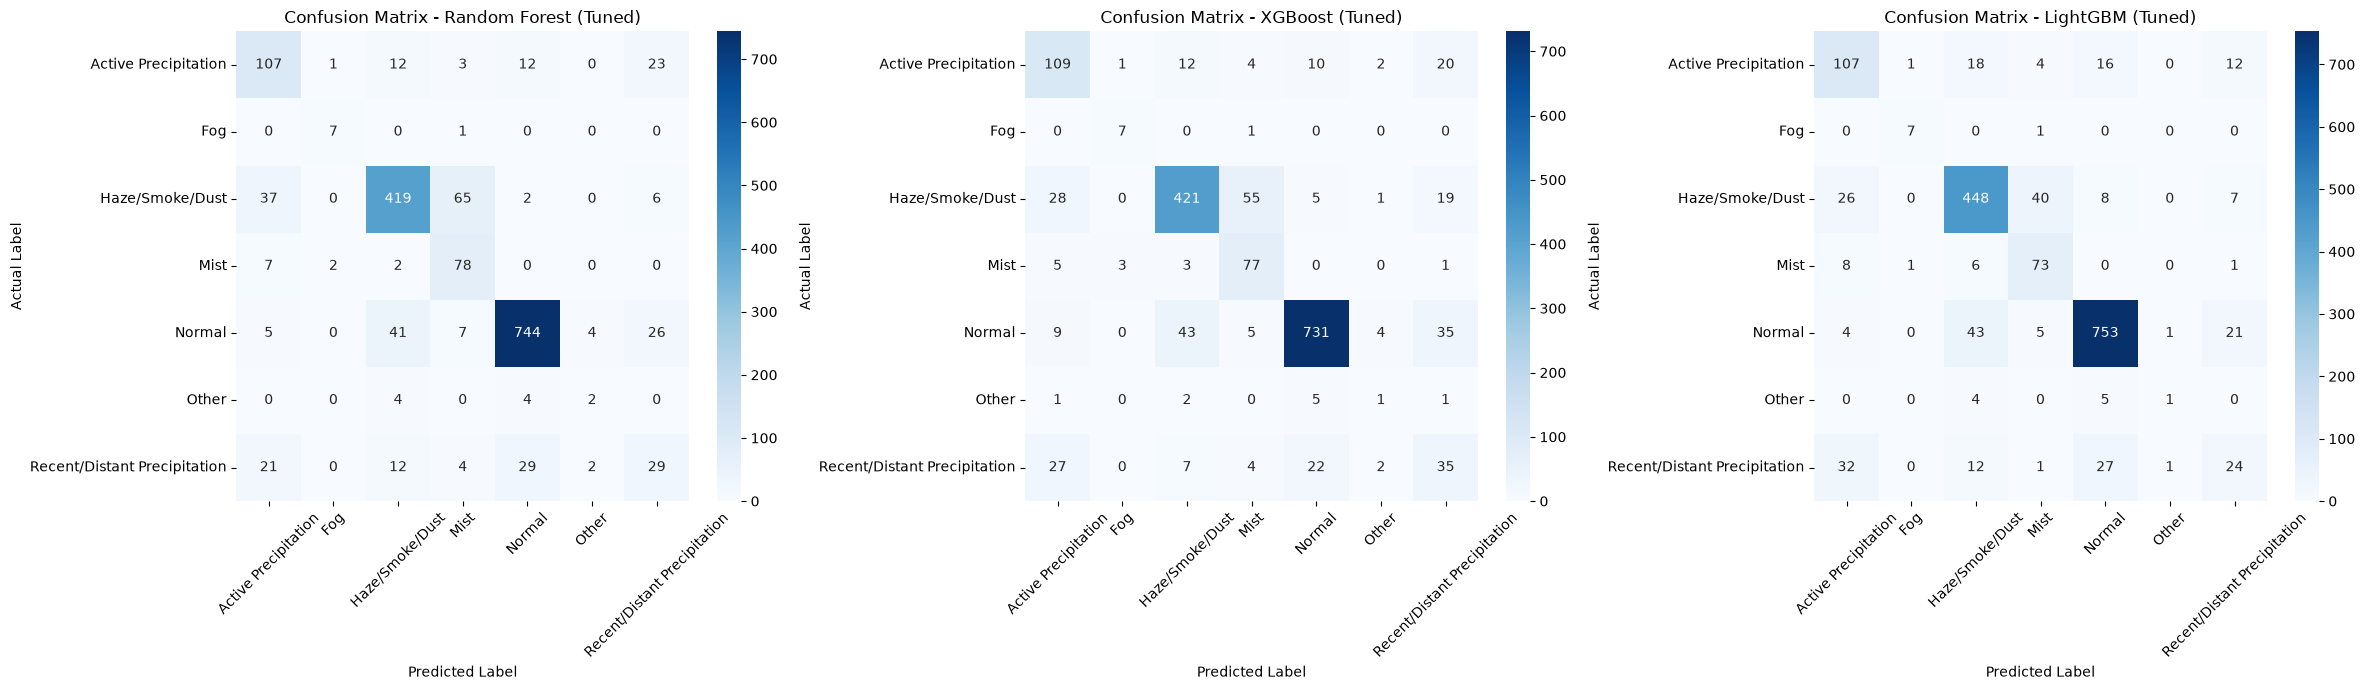

In [250]:
fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for ax, (name, y_pred) in zip(axes, test_predictions.items()):
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(f'Confusion Matrix - {name} (Tuned)')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

In [251]:
for name, y_pred in test_predictions.items():
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    cm_df = pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names
    )
    cm_df.index.name = 'Actual'
    cm_df.columns.name = 'Predicted'

    print(f"\nConfusion Matrix (Tuned): {name}")
    display(cm_df)


Confusion Matrix (Tuned): Random Forest


Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,107,1,12,3,12,0,23
Fog,0,7,0,1,0,0,0
Haze/Smoke/Dust,37,0,419,65,2,0,6
Mist,7,2,2,78,0,0,0
Normal,5,0,41,7,744,4,26
Other,0,0,4,0,4,2,0
Recent/Distant Precipitation,21,0,12,4,29,2,29



Confusion Matrix (Tuned): XGBoost


Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,109,1,12,4,10,2,20
Fog,0,7,0,1,0,0,0
Haze/Smoke/Dust,28,0,421,55,5,1,19
Mist,5,3,3,77,0,0,1
Normal,9,0,43,5,731,4,35
Other,1,0,2,0,5,1,1
Recent/Distant Precipitation,27,0,7,4,22,2,35



Confusion Matrix (Tuned): LightGBM


Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,107,1,18,4,16,0,12
Fog,0,7,0,1,0,0,0
Haze/Smoke/Dust,26,0,448,40,8,0,7
Mist,8,1,6,73,0,0,1
Normal,4,0,43,5,753,1,21
Other,0,0,4,0,5,1,0
Recent/Distant Precipitation,32,0,12,1,27,1,24


**Notes:**

- **Total prediksi tepat pada diagonal utama:** **LightGBM** (model utama terpilih) menghasilkan jumlah prediksi benar terbanyak pada data uji, yaitu **`1.413` dari `1.718` observasi (`82,25%`)**, diikuti oleh **Random Forest** sebanyak **`1.386` observasi (`80,68%`)** dan **XGBoost** sebanyak **`1.381` observasi (`80,38%`)**.
- **Keseimbangan prediksi kelas dominan vs. sensitivitas kelas minoritas:**
  - **LightGBM** mempertahankan kestabilan tertinggi pada dua kelas mayoritas dengan mengenali **`753` dari `827` observasi `Normal`** dan **`448` dari `529` observasi `Haze/Smoke/Dust`**, sekaligus menekan jumlah *false positive* ke kelas minoritas (`Fog` hanya `2` *false positive* dan `Other` hanya `2` *false positive*).
  - **XGBoost** dan **Random Forest** menunjukkan *trade-off* sensitivitas yang lebih agresif pasca-*tuning*: **XGBoost** berhasil menangkap **`35` dari `97` observasi `Recent/Distant Precipitation`** (melonjak dari `20` pada tahap *baseline*) serta **`109` observasi `Active Precipitation`**, sementara **Random Forest** mengenali **`78` dari `89` observasi `Mist`** dan **`2` dari `10` observasi `Other`**, namun dengan konsekuensi meningkatnya pergeseran prediksi dari kelas `Normal` (`731` dan `744` benar) dan `Haze/Smoke/Dust` (`421` dan `419` benar).
- **Konsistensi pemisahan `Fog` (`8` sampel) dan batas dengan `Mist` (`89` sampel):** Ketiga model hasil *tuning* sama-sama mengenali **`7` dari `8` observasi `Fog`** dengan tepat, dan satu-satunya observasi `Fog` yang meleset pada seluruh model bergeser ke kelas `Mist` (`1` sampel). Secara meteorologis, hal ini sangat wajar karena `Fog` dan `Mist` sama-sama terbentuk pada kondisi kelembapan tinggi dan hanya dibedakan oleh ambang jarak pandang permukaan (`< 1.000 m` untuk *fog* vs. `≥ 1.000 m` untuk *mist*). Demikian pula, kesalahan prediksi paling dominan pada `Haze/Smoke/Dust` (`40–65` sampel bergeser ke `Mist`) mencerminkan zona transisi partikel kering menjadi kabut basah saat kelembapan relatif meningkat mendekati titik jenuh.
- **Pola kebingungan yang persisten pada kelompok hujan dan `Other`:** Pada `Recent/Distant Precipitation` (`97` sampel), meski jumlah prediksi benar meningkat signifikan (`24–35` sampel), sebagian besar sisa observasi masih tersebar ke `Active Precipitation` (`21–32` sampel), `Normal` (`22–29` sampel), dan `Haze/Smoke/Dust` (`7–12` sampel) karena hujan yang baru berlalu atau berada di kejauhan sering kali tidak lagi meninggalkan jejak curah hujan langsung di stasiun saat jam pengamatan. Sementara pada kelas langka `Other` (`10` sampel), ketiganya kini mampu mengenali `1–2` observasi dengan tepat, sedangkan sisanya tetap dominan masuk ke `Normal` (`4–5` sampel) dan `Haze/Smoke/Dust` (`2–4` sampel) akibat heterogenitas fenomena cuaca di dalam kategori gabungan tersebut.

# 12. Feature Importance

Tahap ini dilakukan untuk mengidentifikasi kontribusi masing-masing dari **52 fitur masukan** (`13` fitur dasar pada waktu $t$, `30` fitur riwayat waktu `lag1`–`lag3`, dan `9` fitur laju perubahan $\Delta$) dalam proses klasifikasi 7 fenomena meteorologi pada model utama terpilih (**LightGBM** hasil *hyperparameter tuning*). Analisis dilakukan menggunakan dua pendekatan yang saling melengkapi, yaitu *Model-Based Feature Importance (Gain)* bawaan LightGBM dan *Permutation Feature Importance* pada data uji (`X_test`, `y_test`).

## 12.1 Model-Based Feature Importance (Gain)

Analisis ini mengukur kontribusi setiap fitur berdasarkan nilai *gain* dari model LightGBM (`importance_type='gain'`), yang merepresentasikan total peningkatan akurasi pemisahan (*total gain*) yang dihasilkan suatu fitur setiap kali digunakan untuk membagi cabang (*split*) pada seluruh pohon keputusan, kemudian dinormalisasi menjadi proporsi terhadap total keseluruhan *gain*. Semakin tinggi nilainya, semakin besar peran fitur tersebut dalam membentuk aturan pemisahan kelas selama pelatihan.

In [252]:
final_lgbm = search_results['LightGBM'].best_estimator_

**Ekstraksi gain importance dari booster LightGBM dan normalisasi ke proporsi [0, 1]**

In [253]:
raw_gain = final_lgbm.booster_.feature_importance(importance_type='gain')
norm_gain = raw_gain / raw_gain.sum()

In [254]:
def classify_feature_group(feat):
    if '_lag' in feat:
        return 'Lag (t-1, t-2, t-3)'
    elif '_diff_' in feat:
        return 'Delta (Δ)'
    return 'Base (t)'

In [255]:
feature_importance = (
    pd.DataFrame({
        'Feature': selected_features,
        'Group': [classify_feature_group(f) for f in selected_features],
        'Gain Importance': norm_gain
    })
    .sort_values(by='Gain Importance', ascending=False)
    .reset_index(drop=True)
)
print("Top 20 Fitur Berdasarkan Gain Importance (LightGBM)")
display(feature_importance.head(20).round(4))

Top 20 Fitur Berdasarkan Gain Importance (LightGBM)


,Feature,Group,Gain Importance
0,visibility_vv,Base (t),0.2333
1,relative_humidity_pc,Base (t),0.0825
2,cloud_low_cover_oktas,Base (t),0.0424
3,visibility_vv_lag1,"Lag (t-1, t-2, t-3)",0.0422
4,temp_drybulb_diff_3,Delta (Δ),0.0359
5,cloud_low_cover_oktas_lag1,"Lag (t-1, t-2, t-3)",0.0358
6,pressure_diff_3,Delta (Δ),0.0263
7,cloud_med_cover_oktas,Base (t),0.0250
8,pressure_diff_1,Delta (Δ),0.0224
9,pressure_qff_mb_derived_lag3,"Lag (t-1, t-2, t-3)",0.0208


In [256]:
group_gain_summary = (
    feature_importance
    .groupby('Group', as_index=False)
    .agg(
        Jumlah_Fitur=('Feature', 'count'),
        Total_Gain=('Gain Importance', 'sum'),
        Rata_Rata_Gain=('Gain Importance', 'mean')
    )
    .sort_values(by='Total_Gain', ascending=False)
    .reset_index(drop=True)
)
print("Kontribusi Gain Importance per Kelompok Fitur")
display(group_gain_summary.round(4))

Kontribusi Gain Importance per Kelompok Fitur


,Group,Jumlah_Fitur,Total_Gain,Rata_Rata_Gain
0,Base (t),13,0.4817,0.0371
1,"Lag (t-1, t-2, t-3)",30,0.3484,0.0116
2,Delta (Δ),9,0.1699,0.0189


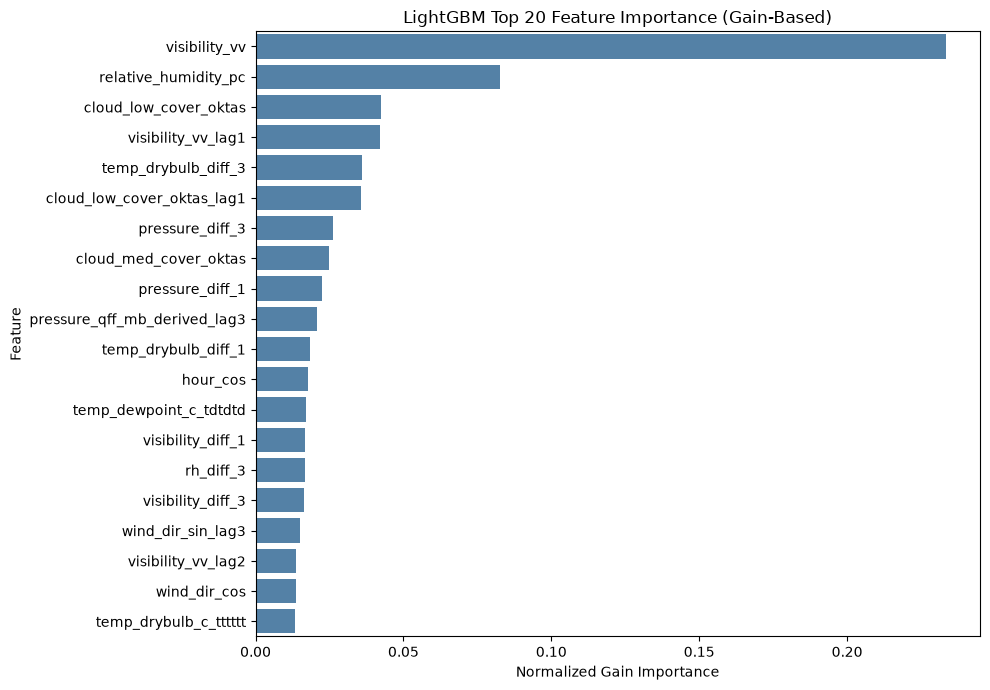

In [257]:
plt.figure(figsize=(10, 7))
sns.barplot(
    data=feature_importance.head(20),
    x='Gain Importance',
    y='Feature',
    color='steelblue'
)
plt.title('LightGBM Top 20 Feature Importance (Gain-Based)')
plt.xlabel('Normalized Gain Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

**Notes:**

- **Dominasi parameter fisik utama dan riwayat terdekat di 5 besar:** `visibility_vv` menempati peringkat pertama dengan nilai *Normalized Gain Importance* tertinggi sebesar **`0,2333`** (`23,33%`), diikuti oleh `relative_humidity_pc` (**`0,0825`**) dan `cloud_low_cover_oktas` (**`0,0424`**). Dua fitur rekayasa waktu langsung menyusul di posisi keempat dan kelima, yakni jarak pandang 1 jam sebelumnya (`visibility_vv_lag1` = **`0,0422`**) dan laju perubahan suhu bola kering 3 jam (`temp_drybulb_diff_3` = **`0,0359`**). Kelima fitur teratas ini menyumbang **`43,63%` (`0,4363`)** dari total *gain* model.
- **Kontribusi gabungan fitur temporal melampaui fitur saat pengamatan ($t$):** Secara agregat per kelompok, fitur riwayat waktu `Lag (t-1, t-2, t-3)` (`30` fitur = **`0,3484`**) dan laju perubahan `Delta (Δ)` (`9` fitur = **`0,1699`**) menyumbang **`51,83%` (`0,5183`)** dari keseluruhan *gain* pemisahan pohon, melampaui kelompok fitur dasar `Base (t)` (`13` fitur = **`0,4817`** atau `48,17%`).
- **Efisiensi tinggi kelompok `Delta (Δ)`:** Sebanyak **7 dari 9 fitur `Delta (Δ)`** berhasil masuk ke dalam jajaran 20 fitur teratas—dipimpin oleh `temp_drybulb_diff_3` (`0,0359`), `pressure_diff_3` (`0,0263`), `pressure_diff_1` (`0,0224`), `temp_drybulb_diff_1` (`0,0186`), `visibility_diff_1` (`0,0168`), `rh_diff_3` (`0,0167`), dan `visibility_diff_3` (`0,0164`)—dengan rata-rata *gain* per fitur sebesar **`0,0189`** (tertinggi kedua setelah `Base (t)` sebesar `0,0371`). Secara fisik meteorologi, perubahan tekanan barometrik, pendinginan suhu, dan pergeseran jarak pandang dalam 1–3 jam terakhir menjadi sinyal penting bagi model untuk membedakan fase transisi cuaca seperti hujan aktif maupun hujan yang baru berlalu.

## 12.2 Permutation Feature Importance

*Permutation Feature Importance* mengevaluasi ketergantungan model utama (**LightGBM**) terhadap masing-masing dari **52 fitur** berdasarkan besarnya penurunan kinerja *Macro F1-Score* pada data uji (`X_test`, `y_test` sebanyak **1.718 observasi**) ketika nilai suatu fitur diacak secara acak sebanyak 10 kali pengulangan (`n_repeats=10`).

Interpretasi nilai rata-rata perubahan skor (*Permutation Mean*):
- **Bernilai positif:** Pengacakan fitur menurunkan kinerja model, menandakan fitur tersebut memberikan informasi penting bagi generalisasi pada data uji.
- **Mendekati nol:** Pengacakan fitur hampir tidak mengubah kinerja model.
- **Bernilai negatif:** Skor *Macro F1* sedikit meningkat saat fitur diacak, yang umumnya terjadi pada fitur dengan kontribusi sangat kecil atau fitur yang informasinya sudah terwakili oleh variabel lain yang berkorelasi.

In [258]:
perm_result = permutation_importance(
    final_lgbm,
    X_test,
    y_test,
    scoring='f1_macro',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

In [259]:
permutation_importance_df = (
    pd.DataFrame({
        'Feature': X_test.columns,
        'Group': [classify_feature_group(f) for f in X_test.columns],
        'Permutation Mean': perm_result.importances_mean,
        'Permutation Std': perm_result.importances_std
    })
    .sort_values(by='Permutation Mean', ascending=False)
    .reset_index(drop=True)
)
print("Top 20 Fitur Berdasarkan Permutation Importance (Test Set - Macro F1)")
display(permutation_importance_df.head(20).round(4))

Top 20 Fitur Berdasarkan Permutation Importance (Test Set - Macro F1)


,Feature,Group,Permutation Mean,Permutation Std
0,visibility_vv,Base (t),0.2567,0.0128
1,relative_humidity_pc,Base (t),0.0870,0.0079
2,pressure_qff_mb_derived_lag2,"Lag (t-1, t-2, t-3)",0.0259,0.0043
3,pressure_qff_mb_derived_lag3,"Lag (t-1, t-2, t-3)",0.0245,0.0034
4,cloud_low_cover_oktas,Base (t),0.0238,0.0064
5,cloud_low_cover_oktas_lag1,"Lag (t-1, t-2, t-3)",0.0235,0.0087
6,temp_drybulb_diff_3,Delta (Δ),0.0230,0.0081
7,pressure_diff_3,Delta (Δ),0.0219,0.0067
8,pressure_diff_1,Delta (Δ),0.0208,0.0027
9,temp_dewpoint_c_tdtdtd,Base (t),0.0207,0.0037


In [233]:
group_perm_summary = (
    permutation_importance_df
    .groupby('Group', as_index=False)
    .agg(
        Jumlah_Fitur=('Feature', 'count'),
        Total_Perm_Importance=('Permutation Mean', 'sum'),
        Rata_Rata_Perm_Importance=('Permutation Mean', 'mean'),
        Fitur_Positif=('Permutation Mean', lambda s: int((s > 0).sum()))
    )
    .sort_values(by='Total_Perm_Importance', ascending=False)
    .reset_index(drop=True)
)
print("Kontribusi Permutation Importance per Kelompok Fitur")
display(group_perm_summary.round(4))

,Feature,Permutation Mean,Permutation Std
0,visibility_vv,0.2982,0.0105
1,relative_humidity_pc,0.0934,0.0056
2,cloud_low_cover_oktas,0.0438,0.0104
3,hour_cos,0.0238,0.0034
4,hour_sin,0.0209,0.0060
5,wind_speed_ff,0.0169,0.0060
6,temp_drybulb_c_tttttt,0.0110,0.0059
7,temp_dewpoint_c_tdtdtd,0.0096,0.0061
8,pressure_qff_mb_derived,0.0077,0.0056
9,wind_dir_cos,0.0027,0.0053


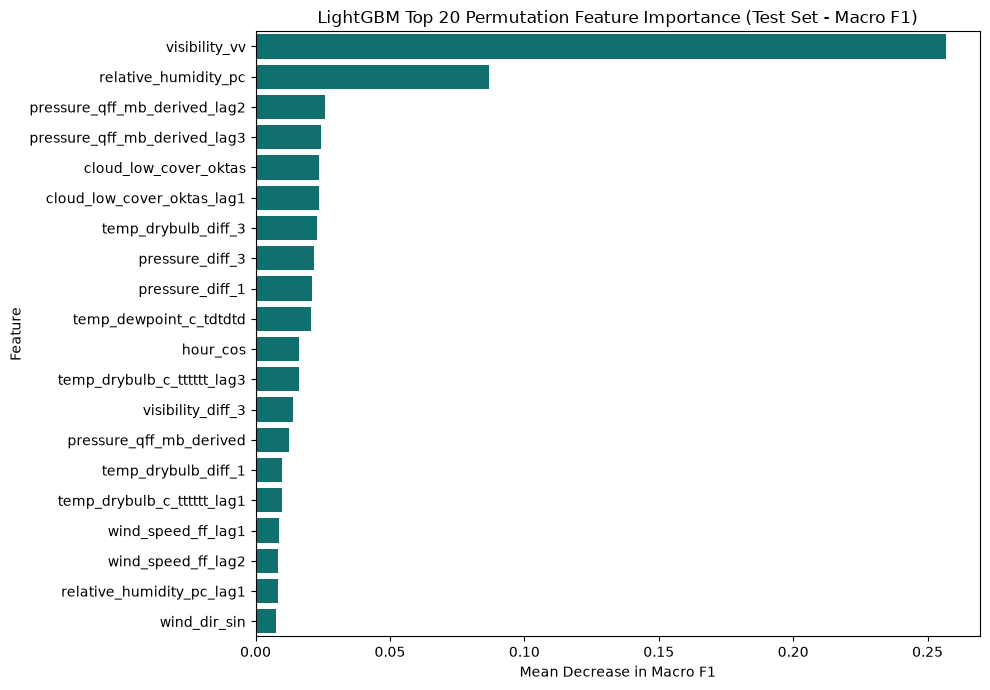

In [260]:
plt.figure(figsize=(10, 7))
sns.barplot(
    data=permutation_importance_df.head(20),
    x='Permutation Mean',
    y='Feature',
    color='teal'
)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.title('LightGBM Top 20 Permutation Feature Importance (Test Set - Macro F1)')
plt.xlabel('Mean Decrease in Macro F1')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

- Nilai importance positif menunjukkan bahwa pengacakan fitur menurunkan kinerja model
- Nilai mendekati nol menunjukkan perubahan yang kecil
- Nilai negatif berarti skor model justru meningkat setelah fitur diacak

**Notes:**

- **Dua variabel fisik utama tetap menjadi fondasi generalisasi pada data uji:** Pengacakan `visibility_vv` menyebabkan penurunan *Macro F1-Score* terbesar sebesar **`0,2567 ± 0,0128`**, diikuti oleh `relative_humidity_pc` sebesar **`0,0870 ± 0,0079`**. Keduanya jauh melampaui fitur-fitur berikutnya dan menegaskan bahwa jarak pandang horizontal serta kelembapan relatif pada waktu pengamatan ($t$) merupakan penentu utama dalam memisahkan fenomena cuaca di stasiun.
- **Dominasi fitur riwayat waktu dan laju perubahan pada jajaran 20 besar:** Sebanyak **13 dari 20 fitur teratas** pada evaluasi data uji berasal dari fitur rekayasa temporal—terdiri dari **8 fitur `Lag (t-1, t-2, t-3)`** dan **5 fitur `Delta (Δ)`**—sedangkan **7 fitur** lainnya berasal dari **`Base (t)`**.
- **Peran krusial riwayat tekanan barometrik dan gradien suhu-tekanan:** Tepat di bawah dua fitur utama, `pressure_qff_mb_derived_lag2` (**`0,0259 ± 0,0043`**) dan `pressure_qff_mb_derived_lag3` (**`0,0245 ± 0,0034`**) menempati peringkat ke-3 dan ke-4, diikuti oleh `cloud_low_cover_oktas` (**`0,0238`**), `cloud_low_cover_oktas_lag1` (**`0,0235`**), serta tiga fitur laju perubahan secara berurutan di peringkat ke-7 hingga ke-9, yakni `temp_drybulb_diff_3` (**`0,0230`**), `pressure_diff_3` (**`0,0219`**), dan `pressure_diff_1` (**`0,0208`**). Hal ini membuktikan bahwa dinamika penurunan/kenaikan tekanan udara dan suhu dalam 1–3 jam terakhir berkontribusi nyata terhadap stabilitas prediksi pada data baru, khususnya dalam membedakan fase hujan aktif (`Active Precipitation`) dan hujan yang baru berlalu (`Recent/Distant Precipitation`).

## 12.3 Perbandingan dan Interpretasi Feature Importance

Menggabungkan hasil *Gain-Based Feature Importance* dan *Permutation Feature Importance* pada model utama (**LightGBM**) dalam satu tabel perbandingan untuk melihat konsistensi peringkat fitur dominan serta mengidentifikasi variabel yang berperan besar dalam pemisahan aturan pohon namun memiliki dampak berbeda terhadap generalisasi pada data uji.

In [261]:
importance_comparison = (
    feature_importance
    .merge(permutation_importance_df, on=['Feature', 'Group'])
    .sort_values(by='Gain Importance', ascending=False)
    .reset_index(drop=True)
)

In [262]:
importance_comparison['Gain Rank'] = importance_comparison.index + 1
importance_comparison['Perm Rank'] = (
    importance_comparison['Permutation Mean']
    .rank(ascending=False, method='min')
    .astype(int)
)

In [263]:
cols_order = [
    'Feature',
    'Group',
    'Gain Rank',
    'Gain Importance',
    'Perm Rank',
    'Permutation Mean',
    'Permutation Std'
]

In [264]:
print("Perbandingan Top 20 Fitur (Gain vs Permutation Importance - LightGBM)")
display(importance_comparison[cols_order].head(20).round(4))

Perbandingan Top 20 Fitur (Gain vs Permutation Importance - LightGBM)


,Feature,Group,Gain Rank,Gain Importance,Perm Rank,Permutation Mean,Permutation Std
0,visibility_vv,Base (t),1,0.2333,1,0.2567,0.0128
1,relative_humidity_pc,Base (t),2,0.0825,2,0.0870,0.0079
2,cloud_low_cover_oktas,Base (t),3,0.0424,5,0.0238,0.0064
3,visibility_vv_lag1,"Lag (t-1, t-2, t-3)",4,0.0422,52,-0.0081,0.0031
4,temp_drybulb_diff_3,Delta (Δ),5,0.0359,7,0.0230,0.0081
5,cloud_low_cover_oktas_lag1,"Lag (t-1, t-2, t-3)",6,0.0358,6,0.0235,0.0087
6,pressure_diff_3,Delta (Δ),7,0.0263,8,0.0219,0.0067
7,cloud_med_cover_oktas,Base (t),8,0.0250,31,0.0039,0.0059
8,pressure_diff_1,Delta (Δ),9,0.0224,9,0.0208,0.0027
9,pressure_qff_mb_derived_lag3,"Lag (t-1, t-2, t-3)",10,0.0208,4,0.0245,0.0034


**Notes:**

- **Kesepakatan penuh pada dua prediktor paling fundamental:** Kedua metode menempatkan **`visibility_vv`** (*Gain Rank* `1` = **`0,2333`** | *Perm Rank* `1` = **`0,2567 ± 0,0128`**) dan **`relative_humidity_pc`** (*Gain Rank* `2` = **`0,0825`** | *Perm Rank* `2` = **`0,0870 ± 0,0079`**) secara berurutan di dua peringkat teratas. Secara fisik meteorologi, jarak pandang horizontal dan kelembapan relatif pada jam pengamatan merupakan penentu utama dalam memisahkan kabut (`Fog`/`Mist`), kekaburan partikel (`Haze/Smoke/Dust`), hujan aktif (`Active Precipitation`), dan cuaca cerah (`Normal`).
- **Konsistensi tinggi pada tutupan awan rendah, riwayat tekanan, dan fitur `Delta (Δ)`:** Sejumlah fitur utama menunjukkan keselarasan peringkat yang sangat rapat antara pelatihan dan generalisasi data uji, yaitu `cloud_low_cover_oktas` (*Gain Rank* `3` = `0,0424` | *Perm Rank* `5` = `0,0238`), `temp_drybulb_diff_3` (*Gain Rank* `5` = `0,0359` | *Perm Rank* `7` = `0,0230`), `cloud_low_cover_oktas_lag1` (*Gain Rank* `6` = `0,0358` | *Perm Rank* `6` = `0,0235`), `pressure_diff_3` (*Gain Rank* `7` = `0,0263` | *Perm Rank* `8` = `0,0219`), `pressure_diff_1` (*Gain Rank* `9` = `0,0224` | *Perm Rank* `9` = `0,0208`), serta `pressure_qff_mb_derived_lag3` (*Gain Rank* `10` = `0,0208` | *Perm Rank* `4` = `0,0245`). Hal ini mengonfirmasi bahwa dinamika gradien tekanan barometrik, pendinginan suhu udara, dan kondisi awan rendah dalam 1–3 jam terakhir berperan nyata dalam menjaga ketepatan klasifikasi fenomena transisi pada data baru.
- **Divergensi peringkat pada `visibility_vv_lag1` dan `visibility_vv_lag2`:** Fitur `visibility_vv_lag1` menempati peringkat ke-4 pada *Gain Importance* (`0,0422`), namun turun ke peringkat ke-52 pada *Permutation Importance* (`-0,0081 ± 0,0031`), diikuti pola serupa pada `visibility_vv_lag2` (*Gain Rank* `18` = `0,0138` $\rightarrow$ *Perm Rank* `48` = `-0,0020 ± 0,0047`). Perbedaan ini terjadi karena saat pelatihan LightGBM sering memanfaatkan nilai jarak pandang 1–2 jam lalu untuk membentuk aturan pemisahan spesifik (*fine splits*), sedangkan pada data uji informasi jarak pandang sudah terwakili dengan kuat oleh `visibility_vv` pada waktu $t$ beserta laju perubahannya (`visibility_diff_3` di *Perm Rank* `13` dan `visibility_diff_1` di *Perm Rank* `22`). Pola serupa juga terlihat pada `cloud_med_cover_oktas` (*Gain Rank* `8` $\rightarrow$ *Perm Rank* `31`) dan `rh_diff_3` (*Gain Rank* `15` $\rightarrow$ *Perm Rank* `32`) yang sebagian sinyalnya sudah tertangkap oleh tutupan awan rendah dan kelembapan relatif saat pengamatan.

# 13. External Validation

*External validation* dilakukan untuk menguji kemampuan generalisasi **model utama terpilih (LightGBM hasil *hyperparameter tuning*)** pada dataset observasi periode baru di luar rentang data pelatihan dan pengujian internal. Data eksternal diproses menggunakan tahapan *cleaning*, pemetaan target 7 kelas fenomena cuaca, *feature engineering* (fitur dasar, riwayat waktu `lag1`–`lag3`, dan laju perubahan $\Delta$), serta seleksi **52 fitur** yang identik dengan *pipeline* pelatihan, kemudian diprediksi secara langsung tanpa pelatihan ulang (*zero retraining*).

## 13.1 Inspeksi Data Eksternal

Tahap ini memeriksa dimensi dataset (`shape`), struktur kolom, contoh baris awal, serta kelengkapan nilai (*missing value*) pada file data eksternal (`bmkg-jambi-26-new.csv`) sebelum dilakukan pembersihan dan transformasi fitur.

In [265]:
external_df = pd.read_csv('../bmkg-dataset/bmkg-jambi-26-new.csv', sep=None, engine='python')

In [266]:
print(f"Dimensi external_df: {external_df.shape[0]} baris x {external_df.shape[1]} kolom")

Dimensi external_df: 30408 baris x 93 kolom


In [267]:
with pd.option_context('display.max_columns', None, 'display.max_colwidth', None):
    display(external_df.head())

,station_name,data_timestamp,wind_indicator_iw,wind_dir_deg_dd,wind_speed_ff,visibility_vv,weather_indicator_ix,present_weather_ww,past_weather_w1,past_weather_w2,pressure_temp_c,pressure_reading_mb,pressure_qfe_mb_derived,pressure_qff_mb_derived,pressure_3h_diff_mb_ppp,pressure_24h_diff_mb_p24,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,temp_max_c_txtxtx,temp_min_c_tntntn,relative_humidity_pc,rainfall_last_mm,rainfall_24h_rrrr,rainfall_6h_rrr,rainfall_indicator_ir,cloud_low_type_cl,cloud_low_cover_oktas,cloud_low_type_1,cloud_low_type_2,cloud_low_type_3,cloud_low_cover_1,cloud_low_cover_2,cloud_low_cover_3,cloud_low_base_1,cloud_low_base_2,cloud_low_base_3,cloud_low_peak_1,cloud_low_peak_2,cloud_low_dir_1,cloud_low_dir_2,cloud_low_dir_3,cloud_elevation_angle_ec_1,cloud_elevation_angle_ec_2,cloud_low_dir_true_da_1,cloud_low_dir_true_da_2,cloud_layer_1_type_c,cloud_layer_2_type_c,cloud_layer_1_height_m_hshs,cloud_layer_2_height_m_hshs,cloud_layer_1_amt_oktas_ns,cloud_layer_2_amt_oktas_ns,cloud_layer_3_type_c,cloud_layer_3_height_m_hshs,cloud_layer_3_amt_oktas_ns,cloud_layer_4_type_c,cloud_layer_4_height_m_hshs,cloud_layer_4_amt_oktas_ns,cloud_med_type_cm,cloud_med_cover_oktas,cloud_med_type_1,cloud_med_type_2,cloud_med_cover_1,cloud_med_cover_2,cloud_med_base_1,cloud_med_base_2,cloud_med_dir_1,cloud_med_dir_2,cloud_high_type_ch,cloud_high_cover_oktas,cloud_high_type_1,cloud_high_type_2,cloud_high_cover_1,cloud_high_cover_2,cloud_high_base_1,cloud_high_base_2,cloud_high_dir_1,cloud_high_dir_2,cloud_cover_oktas_m,cloud_vertical_vis,evaporation_24hours_mm_eee,evaporation_eq_indicator_ie,solar_rad_24h_jcm2_f24,sunshine_h_sss,land_cond,land_note,encoded_synop,edited_encoded_synop,created_at,updated_at,qc_flag,qc_histories,observer_name
0,Stasiun Meteorologi Sultan Thaha,01/01/2026 00:00,4,130.0,2,3,1.0,10.0,6.0,2.0,NaN,NaN,1006.0,1009.1,2.1,-0.2,23.6,23.2,23.3,NaN,23.0,98.0,1.4,12.0,1.8,0.0,5,4,6,NaN,NaN,4,NaN,NaN,450.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,6.0,4.0,450.0,3000.0,4.0,8.0,NaN,NaN,NaN,NaN,NaN,NaN,2,8,4,NaN,8,NaN,3000.0,NaN,0.0,NaN,/,/,/,NaN,/,NaN,NaN,NaN,9.0,NaN,8.0,NaN,3.8,0.0,NaN,0.9,2.0,NaN,SMID52 WIJJ 010000,NaN,NaN,NaN,NaN,NaN,NaN
1,AAXX 01004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,96195 01430 81302 10236 20232 30060 40091 53021 60124 71062 8452/,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"333 20230 50380 55009 56009 59002 60017 84615 88460=""",SMID52 WIJJ 010000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AAXX 01004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [268]:
core_raw_cols = [
    'station_name', 'data_timestamp', 'weather_indicator_ix', 'present_weather_ww',
    'wind_dir_deg_dd', 'wind_speed_ff', 'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'relative_humidity_pc',
    'cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'visibility_vv'
]

In [269]:
available_core = [c for c in core_raw_cols if c in external_df.columns]
missing_core = [c for c in core_raw_cols if c not in external_df.columns]

In [270]:
print("Kolom inti tidak ditemukan:", missing_core)

Kolom inti tidak ditemukan: []


In [271]:
core_missing_df = pd.DataFrame({
    'Missing Count': external_df[available_core].isna().sum(),
    'Missing (%)': (external_df[available_core].isna().mean() * 100).round(2),
    'Dtype': external_df[available_core].dtypes
})
display(core_missing_df)

,Missing Count,Missing (%),Dtype
station_name,0,0.00,str
data_timestamp,17376,57.14,str
weather_indicator_ix,26064,85.71,float64
present_weather_ww,26064,85.71,float64
wind_dir_deg_dd,21720,71.43,float64
wind_speed_ff,26050,85.67,str
pressure_qff_mb_derived,26064,85.71,float64
temp_drybulb_c_tttttt,26064,85.71,float64
temp_dewpoint_c_tdtdtd,26064,85.71,float64
relative_humidity_pc,26064,85.71,float64


**Notes:**

- Dataset eksternal (`bmkg-jambi-26-new.csv`) terdiri atas **`30.408` baris dan `93` kolom**, dengan seluruh 13 kolom mentah inti yang dibutuhkan *pipeline* tersedia secara lengkap (`0` kolom hilang).
- Terdapat tingkat *missing value* yang besar pada kolom-kolom utama (`57,14%` pada `data_timestamp` dan `85,71%` pada sebagian besar parameter meteorologi), yang mengindikasikan keberadaan baris kosong atau catatan tambahan di dalam file mentah.
- Kolom `wind_speed_ff`, `cloud_low_cover_oktas`, `cloud_med_cover_oktas`, dan `visibility_vv` masih terbaca sebagai tipe teks (`str`), sehingga memerlukan konversi numerik dan penanganan karakter non-numerik pada tahap pembersihan.
- Sampel baris awal memperlihatkan catatan waktu dari tahun 2025 (`01/01/2025`), sehingga pemeriksaan rentang waktu pada sub-bab berikutnya diperlukan untuk memisahkan data observasi periode 2026 sebagai data validasi eksternal.

## 13.2 Pemeriksaan Timestamp dan Pemisahan Periode Eksternal

Melakukan penguraian (*parsing*) kolom `data_timestamp` dengan format tanggal Indonesia (`dayfirst=True`), memeriksa jumlah baris valid maupun duplikat, melihat sebaran observasi per bulan/tahun, serta memisahkan data periode **tahun 2026** sebagai himpunan validasi eksternal yang sepenuhnya terpisah dari periode data pelatihan (tahun 2025).

**Parse timestamp dengan dayfirst=True sesuai format DD/MM/YYYY HH:MM**

In [272]:
external_df['data_timestamp_parsed'] = pd.to_datetime(
    external_df['data_timestamp'],
    dayfirst=True,
    errors='coerce'
)

In [273]:
print("Total baris mentah          :", len(external_df))
print("Timestamp valid (non-NaT)   :", external_df['data_timestamp_parsed'].notna().sum())
print("Timestamp tidak valid (NaT) :", external_df['data_timestamp_parsed'].isna().sum())

Total baris mentah          : 30408
Timestamp valid (non-NaT)   : 8688
Timestamp tidak valid (NaT) : 21720


**Cek distribusi observasi berdasarkan Tahun-Bulan pada baris yang memiliki timestamp valid**

In [274]:
valid_ts_df = external_df.dropna(subset=['data_timestamp_parsed']).copy()

In [275]:
monthly_dist = (
    valid_ts_df['data_timestamp_parsed']
    .dt.to_period('M')
    .value_counts()
    .sort_index()
)

In [276]:
display(monthly_dist.to_frame('Jumlah Baris'))

,Jumlah Baris
data_timestamp_parsed,
2026-01,744
2026-02,1416
2026-03,1416
2026-04,2160
2026-05,1512
2026-06,1440


In [277]:
ext_2026_raw = valid_ts_df[valid_ts_df['data_timestamp_parsed'].dt.year == 2026].copy()
ext_2026_raw['data_timestamp'] = ext_2026_raw['data_timestamp_parsed']
ext_2026_raw.drop(columns=['data_timestamp_parsed'], inplace=True)

In [278]:
print("Jumlah baris tahun 2026     :", len(ext_2026_raw))
print("Rentang waktu               :", ext_2026_raw['data_timestamp'].min(), "s.d.", ext_2026_raw['data_timestamp'].max())
print("Jumlah timestamp duplikat   :", ext_2026_raw['data_timestamp'].duplicated().sum())

Jumlah baris tahun 2026     : 8688
Rentang waktu               : 2026-01-01 00:00:00 s.d. 2026-06-30 23:03:00
Jumlah timestamp duplikat   : 3390


**Notes:**

- Dari total **`30.408` baris mentah**, sebanyak **`8.688` baris** memiliki `data_timestamp` valid yang seluruhnya berada pada periode **1 Januari 2026 pukul 00:00 UTC hingga 30 Juni 2026 pukul 23:03 UTC** (Januari–Juni 2026), sedangkan **`21.720` baris** bernilai `NaT` (*missing*).
- Pada `8.688` baris tahun 2026 tersebut masih ditemukan **`3.390` *timestamp* duplikat** serta catatan waktu di luar jam bulat (seperti `23:03:00`), yang menandakan adanya baris duplikat atau catatan tambahan per jam pengamatan di dalam file ekspor mentah.
- Oleh karena itu, pada tahap berikutnya dilakukan penyaringan baris yang memiliki data meteorologi lengkap serta penanganan duplikasi *timestamp* agar diperoleh rangkaian observasi per jam yang bersih.

## 13.3 Pembersihan Baris Observasi dan Standarisasi Waktu (WIB)

Menyaring `ext_2026_raw` agar hanya mempertahankan baris observasi sinoptik yang memiliki parameter cuaca utama (`present_weather_ww`, `temp_drybulb_c_tttttt`, `relative_humidity_pc`, `visibility_vv`), menangani duplikasi `data_timestamp`, memeriksa keteraturan interval pengamatan per jam, serta mengonversi waktu pengamatan dari **UTC ke WIB (`+7 jam`)** agar konsisten dengan data pelatihan.

In [279]:
required_obs_cols = [
    'present_weather_ww',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'relative_humidity_pc',
    'pressure_qff_mb_derived'
]

In [280]:
ext_clean = ext_2026_raw.dropna(subset=required_obs_cols).copy()

In [281]:
print("Jumlah baris setelah menghapus baris kosong parameter utama :", len(ext_clean))
print("Jumlah timestamp duplikat tersisa                         :", ext_clean['data_timestamp'].duplicated().sum())

Jumlah baris setelah menghapus baris kosong parameter utama : 4344
Jumlah timestamp duplikat tersisa                         : 0


In [282]:
if ext_clean['data_timestamp'].duplicated().sum() > 0:
    ext_clean = (
        ext_clean
        .sort_values('data_timestamp')
        .drop_duplicates(subset=['data_timestamp'], keep='first')
        .reset_index(drop=True)
    )
    print("Jumlah baris setelah deduplikasi timestamp                :", len(ext_clean))
else:
    ext_clean = ext_clean.sort_values('data_timestamp').reset_index(drop=True)

In [283]:
date_pos = ext_clean.columns.get_loc('data_timestamp') + 1
ext_clean.insert(date_pos, 'datetime_wib', ext_clean['data_timestamp'] + pd.Timedelta(hours=7))

In [284]:
print("Rentang UTC :", ext_clean['data_timestamp'].min(), "s.d.", ext_clean['data_timestamp'].max())
print("Rentang WIB :", ext_clean['datetime_wib'].min(), "s.d.", ext_clean['datetime_wib'].max())

Rentang UTC : 2026-01-01 00:00:00 s.d. 2026-06-30 23:00:00
Rentang WIB : 2026-01-01 07:00:00 s.d. 2026-07-01 06:00:00


In [285]:
intervals_ext = ext_clean['datetime_wib'].diff().dropna()
print("\nDistribusi interval antarobservasi (Top 5):")
display(intervals_ext.value_counts().head(5).to_frame('Jumlah'))


Distribusi interval antarobservasi (Top 5):


,Jumlah
datetime_wib,
0 days 01:00:00,4343


In [286]:
monthly_clean = ext_clean['datetime_wib'].dt.to_period('M').value_counts().sort_index()
print("\nJumlah observasi bersih per bulan (WIB):")
display(monthly_clean.to_frame('Jumlah Observasi'))


Jumlah observasi bersih per bulan (WIB):


,Jumlah Observasi
datetime_wib,
2026-01,737
2026-02,672
2026-03,744
2026-04,720
2026-05,744
2026-06,720
2026-07,7


**Notes:**

- Setelah menyaring baris yang memiliki kelengkapan parameter meteorologi utama, diperoleh **`4.344` observasi sinoptik valid** dengan **`0` *timestamp* duplikat** (seluruh `3.390` duplikasi pada tahap sebelumnya terbukti berasal dari baris kosong/tidak lengkap).
- Rangkaian data eksternal mencakup periode **1 Januari 2026 pukul 00:00 UTC hingga 30 Juni 2026 pukul 23:00 UTC**, atau setara dengan **1 Januari 2026 pukul 07:00 WIB hingga 1 Juli 2026 pukul 06:00 WIB** (total **181 hari penuh**).
- Seluruh `4.343` selisih waktu antarobservasi beruntun tercatat tepat **`1 jam` (`0 days 01:00:00`)** tanpa satu pun jam pengamatan yang terlewat, dengan distribusi merata pada setiap bulan (`737` observasi pada Januari, `672` Februari, `744` Maret, `720` April, `744` Mei, `720` Juni, dan `7` jam awal pada 1 Juli WIB).

## 13.4 Pembersihan Fitur Inti dan Pemetaan Target 7 Kelas

Melakukan pembersihan serta konversi tipe data numerik pada kolom fitur utama (`wind_dir_deg_dd`, `wind_speed_ff`, `pressure_qff_mb_derived`, `temp_drybulb_c_tttttt`, `temp_dewpoint_c_tdtdtd`, `relative_humidity_pc`, `cloud_low_cover_oktas`, `cloud_med_cover_oktas`, dan `visibility_vv`), menangani nilai hilang jika terdapat karakter non-numerik (seperti sandi `/` pada tutupan awan), serta memetakan kode cuaca `present_weather_ww` ke dalam **7 kategori fenomena** yang identik dengan data pelatihan (`label_map`).

In [287]:
numeric_core_cols = [
    'wind_dir_deg_dd',
    'wind_speed_ff',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'relative_humidity_pc',
    'cloud_low_cover_oktas',
    'cloud_med_cover_oktas',
    'visibility_vv'
]

In [288]:
for col in numeric_core_cols:
    ext_clean[col] = pd.to_numeric(ext_clean[col], errors='coerce')

display(ext_clean[numeric_core_cols].isna().sum().to_frame('Missing Count'))

,Missing Count
wind_dir_deg_dd,0
wind_speed_ff,0
pressure_qff_mb_derived,0
temp_drybulb_c_tttttt,0
temp_dewpoint_c_tdtdtd,0
relative_humidity_pc,0
cloud_low_cover_oktas,3
cloud_med_cover_oktas,38
visibility_vv,0


In [289]:
def map_ww_to_phenomenon(ww):
    if pd.isna(ww):
        return np.nan
    ww = int(ww)
    if ww in [0, 1, 2, 3]:
        return 'Normal'
    elif ww in [4, 5, 6, 7, 8, 9, 30, 31, 32, 33, 34, 35]:
        return 'Haze/Smoke/Dust'
    elif ww == 10:
        return 'Mist'
    elif ww in [11, 12] or (40 <= ww <= 49):
        return 'Fog'
    elif ww in [14, 15, 16] or (20 <= ww <= 29):
        return 'Recent/Distant Precipitation'
    elif 50 <= ww <= 99:
        return 'Active Precipitation'
    else:
        return 'Other'

In [290]:
ext_clean['phenomenon'] = ext_clean['present_weather_ww'].apply(map_ww_to_phenomenon)
ext_clean['phenomenon_encoded'] = ext_clean['phenomenon'].map(label_map)

In [291]:
dist_compare = pd.DataFrame({
    'External 2026 (Count)': ext_clean['phenomenon'].value_counts(),
    'External 2026 (%)': (ext_clean['phenomenon'].value_counts(normalize=True) * 100).round(2),
    'Train 2025 (Count)': train_df['phenomenon'].value_counts(),
    'Train 2025 (%)': (train_df['phenomenon'].value_counts(normalize=True) * 100).round(2)
}).reindex(list(label_map.keys())).fillna(0)

In [292]:
dist_compare['External 2026 (Count)'] = dist_compare['External 2026 (Count)'].astype(int)
dist_compare['Train 2025 (Count)'] = dist_compare['Train 2025 (Count)'].astype(int)

In [293]:
display(dist_compare)

,External 2026 (Count),External 2026 (%),Train 2025 (Count),Train 2025 (%)
phenomenon,,,,
Active Precipitation,322,7.41,652,9.26
Fog,25,0.58,42,0.60
Haze/Smoke/Dust,763,17.56,2198,31.23
Mist,172,3.96,359,5.10
Normal,2806,64.59,3355,47.66
Other,68,1.57,44,0.63
Recent/Distant Precipitation,188,4.33,389,5.53


In [294]:
print("Missing label setelah encoding:", ext_clean['phenomenon_encoded'].isna().sum())

Missing label setelah encoding: 0


**Notes:**

- Setelah konversi ke tipe numerik, tujuh dari sembilan kolom parameter meteorologi inti bebas dari nilai hilang (`0` *missing*), sedangkan dua kolom tutupan awan menyisakan sedikit nilai hilang akibat karakter sandi non-numerik (`/`), yakni **`3` observasi pada `cloud_low_cover_oktas`** (`0,07%`) dan **`38` observasi pada `cloud_med_cover_oktas`** (`0,87%`).
- Pemetaan kode cuaca `present_weather_ww` berhasil mengonversi seluruh **`4.344` observasi** ke dalam **7 kategori fenomena** (`0` label hilang) yang sepenuhnya selaras dengan `label_map` pada data pelatihan.
- Perbandingan proporsi antarperiode memperlihatkan adanya pergeseran distribusi kelas (*distribution shift*): pada data eksternal (Januari–Juni 2026), proporsi kelas `Normal` meningkat menjadi **`64,59%`** (dibandingkan `47,80%` pada data latih 2025), sementara proporsi `Haze/Smoke/Dust` turun menjadi **`17,56%`** (dibandingkan `31,31%`). Perbedaan ini wajar secara klimatologis karena periode Januari–Juni didominasi musim hujan dan peralihan, sedangkan periode puncak kemarau serta kabut asap umumnya terjadi pada paruh kedua tahun (Juli–Oktober).

## 13.5 Penanganan Missing Value Awan, Feature Engineering, dan Persiapan Input Model

Tahap ini menyelesaikan sisa *missing value* pada kolom tutupan awan (`cloud_low_cover_oktas` dan `cloud_med_cover_oktas`) menggunakan metode *forward-fill* dan *backward-fill* (`ffill().bfill()`) sesuai sifat deret waktu pengamatan per jam yang kontinu. Selanjutnya, dibentuk seluruh fitur turunan yang identik dengan *pipeline* pelatihan—mencakup **5 fitur dasar turunan** (`hour_sin`, `hour_cos`, `wind_dir_sin`, `wind_dir_cos`, `is_calm`), **30 fitur riwayat waktu (`lag1`–`lag3`)**, serta **9 fitur laju perubahan ($\Delta$)** dengan penjagaan kontinuitas interval 1 jam. Baris batas awal yang belum memiliki riwayat 3 jam penuh (`3` observasi pertama) dihapus, lalu urutan kolom dan tipe data diselaraskan tepat sama dengan `X_train` (**52 fitur**).

**Imputasi sisa missing value pada tutupan awan mengikuti kontinuitas deret waktu per jam**

In [295]:
cloud_cols = ['cloud_low_cover_oktas', 'cloud_med_cover_oktas']
for col in cloud_cols:
    ext_clean[col] = ext_clean[col].ffill().bfill().astype('int8')

**Pembentukan fitur turunan (Feature Engineering) sesuai pipeline pelatihan**

In [296]:
ext_clean['hour'] = ext_clean['datetime_wib'].dt.hour
ext_clean['hour_sin'] = np.sin(2 * np.pi * ext_clean['hour'] / 24)
ext_clean['hour_cos'] = np.cos(2 * np.pi * ext_clean['hour'] / 24)

In [297]:
ext_clean['wind_dir_sin'] = np.sin(np.deg2rad(ext_clean['wind_dir_deg_dd']))
ext_clean['wind_dir_cos'] = np.cos(np.deg2rad(ext_clean['wind_dir_deg_dd']))

In [298]:
ext_clean['is_calm'] = (ext_clean['wind_speed_ff'] == 0).astype(int)

**Pembentukan 30 fitur riwayat waktu (lag1, lag2, lag3) dengan verifikasi selisih waktu tepat 1-3 jam**

In [299]:
lag_bases = [
    'wind_dir_sin',
    'wind_dir_cos',
    'wind_speed_ff',
    'visibility_vv',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'relative_humidity_pc',
    'cloud_low_cover_oktas',
    'cloud_med_cover_oktas'
]

for lag in [1, 2, 3]:
    valid_interval = (ext_clean['datetime_wib'].diff(lag) == pd.Timedelta(hours=lag))
    for col in lag_bases:
        ext_clean[f'{col}_lag{lag}'] = ext_clean[col].shift(lag).where(valid_interval)

**Pembentukan 9 fitur laju perubahan (Delta 1 jam dan 3 jam)**

In [300]:
delta_specs = [
    ('visibility_diff_1', 'visibility_vv', 1),
    ('visibility_diff_3', 'visibility_vv', 3),
    ('temp_drybulb_diff_1', 'temp_drybulb_c_tttttt', 1),
    ('temp_drybulb_diff_3', 'temp_drybulb_c_tttttt', 3),
    ('rh_diff_1', 'relative_humidity_pc', 1),
    ('rh_diff_3', 'relative_humidity_pc', 3),
    ('pressure_diff_1', 'pressure_qff_mb_derived', 1),
    ('pressure_diff_3', 'pressure_qff_mb_derived', 3),
    ('wind_speed_diff_1', 'wind_speed_ff', 1)
]

for new_col, base_col, step in delta_specs:
    valid_interval = (ext_clean['datetime_wib'].diff(step) == pd.Timedelta(hours=step))
    ext_clean[new_col] = ext_clean[base_col].diff(step).where(valid_interval)

**Hapus baris batas awal tanpa riwayat 3 jam lengkap & selaraskan 52 fitur dengan X_train**

In [301]:
train_feature_cols = list(X_train.columns)
ext_eval = ext_clean.dropna(subset=train_feature_cols).reset_index(drop=True)

In [302]:
X_external = ext_eval[train_feature_cols].copy()
y_external = ext_eval['phenomenon_encoded'].astype(int).copy()

In [303]:
for col in train_feature_cols:
    X_external[col] = X_external[col].astype(X_train[col].dtype)

In [304]:
assert list(X_external.columns) == train_feature_cols, "Urutan kolom tidak sesuai dengan X_train!"
assert X_external.isna().sum().sum() == 0, "Masih terdapat missing value pada X_external!"
assert y_external.isna().sum() == 0, "Masih terdapat missing value pada y_external!"

In [305]:
print("Jumlah baris awal ext_clean :", len(ext_clean))
print("Jumlah baris valid ext_eval :", len(ext_eval))
print("Dimensi X_external          :", X_external.shape)
print("Dimensi y_external          :", y_external.shape)
print("Total missing value         :", X_external.isna().sum().sum())

Jumlah baris awal ext_clean : 4344
Jumlah baris valid ext_eval : 4341
Dimensi X_external          : (4341, 52)
Dimensi y_external          : (4341,)
Total missing value         : 0


In [306]:
display(X_external.head())

,wind_speed_ff,wind_dir_sin,wind_dir_cos,is_calm,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,relative_humidity_pc,cloud_low_cover_oktas,cloud_med_cover_oktas,...,cloud_med_cover_oktas_lag3,visibility_diff_1,visibility_diff_3,temp_drybulb_diff_1,temp_drybulb_diff_3,rh_diff_1,rh_diff_3,pressure_diff_1,pressure_diff_3,wind_speed_diff_1
0,5,-0.866025,0.500000,0,1010.9,26.0,23.5,86,4,8,...,8.0,0.0,7.0,1.0,2.4,-4.0,-12.0,0.3,1.8,0.0
1,5,-0.984808,-0.173648,0,1010.4,27.2,23.3,79,2,8,...,8.0,0.0,5.0,1.2,3.2,-7.0,-17.0,-0.5,0.3,0.0
2,4,-0.342020,-0.939693,0,1009.8,28.2,23.7,77,4,8,...,8.0,0.0,0.0,1.0,3.2,-2.0,-13.0,-0.6,-0.8,-1.0
3,8,-0.866025,0.500000,0,1008.9,29.1,23.9,74,5,7,...,8.0,0.0,0.0,0.9,3.1,-3.0,-12.0,-0.9,-2.0,4.0
4,7,-0.939693,0.342020,0,1007.7,29.8,24.1,72,5,5,...,8.0,0.0,0.0,0.7,2.6,-2.0,-7.0,-1.2,-2.7,-1.0


**Notes:**

- Seluruh sisa nilai hilang pada `cloud_low_cover_oktas` dan `cloud_med_cover_oktas` berhasil ditangani melalui imputasi deret waktu (`ffill().bfill()`), sedangkan **44 fitur rekayasa** (`5` fitur dasar turunan pada waktu $t$, `30` fitur riwayat waktu `lag1`–`lag3`, dan `9` fitur laju perubahan $\Delta$) terbentuk dengan verifikasi kontinuitas interval tepat 1 jam.
- Penghapusan `3` observasi batas awal (`2026-01-01 07:00–09:00 WIB`) yang belum memiliki riwayat 3 jam penuh menyisakan **`4.341` observasi valid (`ext_eval`)** dari total `4.344` baris awal.
- Matriks masukan `X_external` berukuran **`(4.341, 52)`** dengan vektor target `y_external` berukuran **`(4.341,)`** dan **`0` nilai hilang (*missing value*)**. Urutan kolom serta tipe data seluruh 52 fitur telah terverifikasi identik dengan `X_train`, sehingga data siap digunakan pada tahap prediksi.

## 13.6 Prediksi pada Data Eksternal

Melakukan prediksi terhadap **`4.341` observasi eksternal valid** (periode 1 Januari 2026 pukul 10:00 WIB hingga 1 Juli 2026 pukul 06:00 WIB) menggunakan **model utama terpilih (`final_lgbm` — LightGBM hasil *hyperparameter tuning*)** tanpa pelatihan ulang. Hasil prediksi kemudian dibandingkan proporsinya terhadap distribusi kelas aktual untuk melihat kecenderungan prediksi model pada periode baru.

In [308]:
final_lgbm = search_results['LightGBM'].best_estimator_
ext_pred = final_lgbm.predict(X_external)

In [309]:
ext_eval['predicted_code'] = ext_pred
ext_eval['predicted_phenomenon'] = ext_eval['predicted_code'].map(inv_label_map)

In [310]:
pred_dist_df = pd.DataFrame({
    'Predicted Count': ext_eval['predicted_phenomenon'].value_counts(),
    'Predicted (%)': (ext_eval['predicted_phenomenon'].value_counts(normalize=True) * 100).round(2),
    'Actual Count': ext_eval['phenomenon'].value_counts(),
    'Actual (%)': (ext_eval['phenomenon'].value_counts(normalize=True) * 100).round(2)
}).reindex(list(label_map.keys())).fillna(0)

In [311]:
pred_dist_df['Predicted Count'] = pred_dist_df['Predicted Count'].astype(int)
pred_dist_df['Actual Count'] = pred_dist_df['Actual Count'].astype(int)
display(pred_dist_df)

,Predicted Count,Predicted (%),Actual Count,Actual (%)
Active Precipitation,314,7.23,322,7.42
Fog,35,0.81,25,0.58
Haze/Smoke/Dust,1217,28.04,763,17.58
Mist,207,4.77,170,3.92
Normal,2409,55.49,2805,64.62
Other,15,0.35,68,1.57
Recent/Distant Precipitation,144,3.32,188,4.33


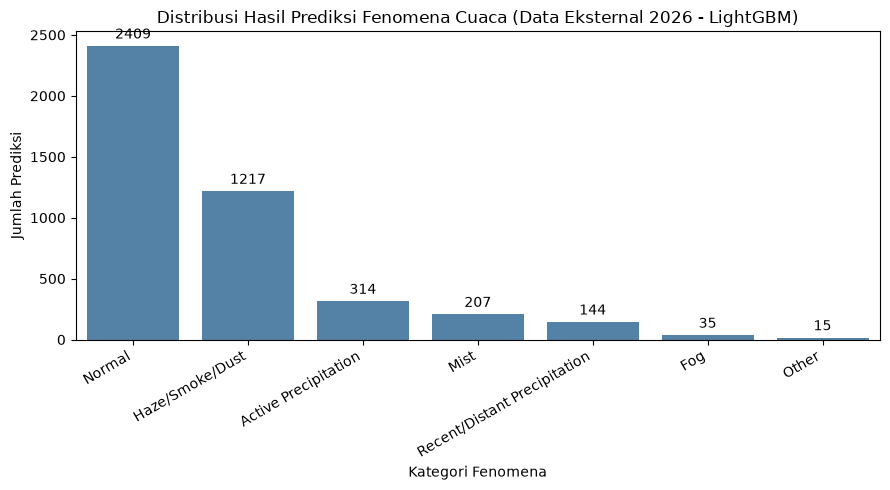

In [312]:
plt.figure(figsize=(9, 5))
order_labels = ext_eval['predicted_phenomenon'].value_counts().index
ax = sns.countplot(
    data=ext_eval,
    x='predicted_phenomenon',
    order=order_labels,
    color='steelblue'
)
plt.title('Distribusi Hasil Prediksi Fenomena Cuaca (Data Eksternal 2026 - LightGBM)')
plt.xlabel('Kategori Fenomena')
plt.ylabel('Jumlah Prediksi')
plt.xticks(rotation=30, ha='right')

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

**Notes:**

- Dari total **`4.341` observasi eksternal**, model utama **LightGBM** memprediksi kelas mayoritas **`Normal` sebanyak `2.409` kali (`55,49%`)**, lebih rendah dibandingkan frekuensi aktualnya sebesar **`2.805` observasi (`64,62%`)**, namun menunjukkan proporsi yang jauh lebih mendekati distribusi aktual dibandingkan skenario tanpa fitur lag (`50,28%`).
- Sebaliknya, model cenderung memprediksi lebih banyak pada kelas **`Haze/Smoke/Dust` (`1.217` prediksi / `28,04%` vs aktual `763` / `17,58%`)**, **`Mist` (`207` prediksi / `4,77%` vs aktual `170` / `3,92%`)**, dan **`Fog` (`35` prediksi / `0,81%` vs aktual `25` / `0,58%`)**. Pola ini dipengaruhi oleh dua faktor utama:
  1. Penerapan pembobotan kelas seimbang (`class_weight='balanced'`) selama pelatihan yang meningkatkan sensitivitas model terhadap kelas non-`Normal`.
  2. Pergeseran distribusi musiman (*distribution shift*), karena model dilatih pada data tahun 2025 dengan proporsi `Haze/Smoke/Dust` yang jauh lebih tinggi (`31,31%`), sedangkan periode eksternal Januari–Juni 2026 didominasi cuaca cerah/berawan (`Normal`).
- Untuk kelompok hujan, total prediksi berada sangat dekat dengan frekuensi aktualnya, yakni **`Active Precipitation` (`314` prediksi / `7,23%` vs `322` aktual / `7,42%`)** dan **`Recent/Distant Precipitation` (`144` prediksi / `3,32%` vs `188` aktual / `4,33%`)**, sedangkan **`Other` diprediksi sebanyak `15` kali (`0,35%` vs `68` aktual / `1,57%`)**. Ketepatan kecocokan tiap observasi dievaluasi secara rinci pada sub-bab berikutnya.

## 13.7 Evaluasi Performa pada Data Eksternal

Mengevaluasi ketepatan prediksi model utama **LightGBM** pada **`4.341` observasi eksternal (Januari–Juni 2026)** terhadap label aktual `y_external`. Evaluasi mencakup perbandingan metrik keseluruhan (*Accuracy*, *Macro F1-Score*, dan *Balanced Accuracy*) terhadap performa pada data uji internal (*Internal Test Set*), laporan klasifikasi per kelas (*Classification Report*), serta matriks kebingungan (*Confusion Matrix*) untuk seluruh **7 kelas fenomena**.

In [313]:
n_classes = len(label_map)
class_labels = list(range(n_classes))
class_names = [inv_label_map[i] for i in range(n_classes)]

In [314]:
ext_acc = accuracy_score(y_external, ext_pred)
ext_macro_f1 = f1_score(y_external, ext_pred, labels=class_labels, average='macro', zero_division=0)
ext_bal_acc = balanced_accuracy_score(y_external, ext_pred)

In [315]:
y_pred_lgbm_test = test_predictions['LightGBM']
int_acc = accuracy_score(y_test, y_pred_lgbm_test)
int_macro_f1 = f1_score(y_test, y_pred_lgbm_test, labels=class_labels, average='macro', zero_division=0)
int_bal_acc = balanced_accuracy_score(y_test, y_pred_lgbm_test)

In [316]:
ext_summary_df = pd.DataFrame([
    {
        'Dataset': 'Internal Test Set (2025, n=1.718)',
        'Accuracy': int_acc,
        'Macro F1': int_macro_f1,
        'Balanced Accuracy': int_bal_acc
    },
    {
        'Dataset': 'External Validation (Jan–Jun 2026, n=4.341)',
        'Accuracy': ext_acc,
        'Macro F1': ext_macro_f1,
        'Balanced Accuracy': ext_bal_acc
    }
]).set_index('Dataset')

display(ext_summary_df.round(4))

,Accuracy,Macro F1,Balanced Accuracy
Dataset,,,
"Internal Test Set (2025, n=1.718)",0.8225,0.6234,0.6396
"External Validation (Jan–Jun 2026, n=4.341)",0.7782,0.5879,0.6355


**Classification Report**

In [317]:
print("Classification Report - External Validation 2026 (LightGBM)")
print(classification_report(
    y_external,
    ext_pred,
    labels=class_labels,
    target_names=class_names,
    zero_division=0,
    digits=4
))

Classification Report - External Validation 2026 (LightGBM)
                              precision    recall  f1-score   support

        Active Precipitation     0.6783    0.6615    0.6698       322
                         Fog     0.7143    1.0000    0.8333        25
             Haze/Smoke/Dust     0.5670    0.9043    0.6970       763
                        Mist     0.6618    0.8059    0.7268       170
                      Normal     0.9406    0.8078    0.8692      2805
                       Other     0.1333    0.0294    0.0482        68
Recent/Distant Precipitation     0.3125    0.2394    0.2711       188

                    accuracy                         0.7782      4341
                   macro avg     0.5726    0.6355    0.5879      4341
                weighted avg     0.8034    0.7782    0.7796      4341



**Confusion Matrix**

In [318]:
cm_ext = confusion_matrix(
    y_external,
    ext_pred,
    labels=class_labels
)

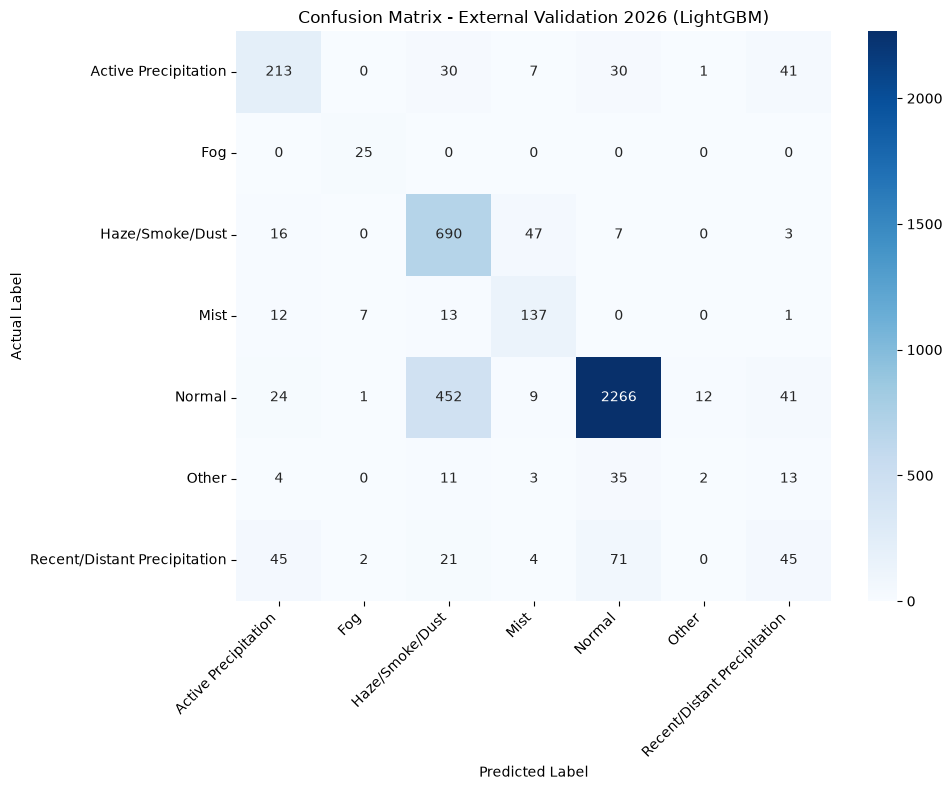

In [319]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_ext,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Confusion Matrix - External Validation 2026 (LightGBM)')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [320]:
cm_ext_df = pd.DataFrame(
    cm_ext,
    index=class_names,
    columns=class_names
)
cm_ext_df.index.name = 'Actual'
cm_ext_df.columns.name = 'Predicted'
display(cm_ext_df)

Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,213,0,30,7,30,1,41
Fog,0,25,0,0,0,0,0
Haze/Smoke/Dust,16,0,690,47,7,0,3
Mist,12,7,13,137,0,0,1
Normal,24,1,452,9,2266,12,41
Other,4,0,11,3,35,2,13
Recent/Distant Precipitation,45,2,21,4,71,0,45


**Notes:**

- **Stabilitas generalisasi lintas tahun (`2025` ke `2026`):** Model utama **LightGBM** (`52` fitur) menunjukkan ketahanan generalisasi yang kuat pada data eksternal periode Januari–Juni 2026 (`4.341` observasi) tanpa pelatihan ulang, mempertahankan ***Balanced Accuracy* sebesar `0,6355`** (hanya terpaut `-0,0041` dari uji internal tahun 2025 sebesar `0,6396`), dengan ***Macro F1-Score* sebesar `0,5879`** dan ***Accuracy* sebesar `0,7782`** (`3.378` prediksi tepat dari `4.341` observasi).
- **Kinerja kuat pada kelas minoritas dan fenomena cuaca utama:**
  - **`Fog` (`25` sampel):** Model mengenali **seluruh `25` dari `25` kejadian kabut secara sempurna** (*recall* **`1,0000`**, *precision* `0,7143`, *F1-Score* **`0,8333`**), tanpa satu pun kejadian kabut yang terlewat (*false negative* = `0`).
  - **`Mist` (`170` sampel) dan `Active Precipitation` (`322` sampel):** Berkat kontribusi fitur riwayat waktu (`lag1`–`lag3`) dan laju perubahan ($\Delta$), kedua kelas ini justru mencatatkan *F1-Score* lebih tinggi dibandingkan uji internal 2025—masing-masing meningkat menjadi **`0,7268`** (dari `0,6854`, dengan *recall* `0,8059`) dan **`0,6698`** (dari `0,6388`, dengan *precision* `0,6783`).
  - **`Normal` (`2.805` sampel):** Memperoleh *precision* sangat tinggi sebesar **`0,9406`** (*recall* `0,8078`, *F1-Score* **`0,8692`**), menandakan bahwa ketika model memprediksi kondisi `Normal`, tingkat ketepatannya sangat tinggi (`2.266` benar dari `2.409` total prediksi `Normal`).
- **Pola kesalahan klasifikasi utama pada *Confusion Matrix*:**
  - Pergeseran prediksi terbesar terjadi pada observasi aktual **`Normal` yang terprediksi sebagai `Haze/Smoke/Dust` (`452` observasi)**, dipicu oleh penerapan `class_weight='balanced'` serta pergeseran distribusi musiman (*distribution shift*) antara data latih tahun 2025 (yang mencakup puncak kemarau/kabut asap) dan data eksternal Januari–Juni 2026 (yang didominasi cuaca cerah/berawan).
  - Pada kelompok hujan dan pascahujan, **`Recent/Distant Precipitation` (`188` sampel)** paling sering tertukar dengan `Normal` (`71` observasi) dan `Active Precipitation` (`45` observasi), sedangkan **`41` dari `322` observasi `Active Precipitation`** terprediksi sebagai `Recent/Distant Precipitation` akibat kemiripan karakteristik atmosfer permukaan saat transisi sebelum dan sesudah hujan.
  - Kelas langka **`Other` (`68` sampel)** tetap menjadi kategori paling sulit dipisahkan (*F1-Score* `0,0482`, `2` benar, `35` masuk ke `Normal`) karena mencakup beragam fenomena khusus yang tidak memiliki karakteristik fisik tunggal.

## 13.8 Misclassification Analysis

Menganalisis kasus kesalahan klasifikasi (*misclassification*) model utama **LightGBM** pada **`4.341` observasi eksternal** (Januari–Juni 2026) untuk mengidentifikasi pasangan kelas yang paling sering tertukar serta membandingkan karakteristik parameter meteorologi antara observasi yang terklasifikasi dengan tepat dan yang mengalami kesalahan prediksi.

**Filter seluruh observasi eksternal yang salah diprediksi**

In [321]:
misclassified = ext_eval[
    ext_eval['phenomenon_encoded'] != ext_eval['predicted_code']
].copy()

In [322]:
total_obs = len(ext_eval)
total_err = len(misclassified)
print(f"Total observasi eksternal : {total_obs}")
print(f"Jumlah prediksi tepat     : {total_obs - total_err} ({(total_obs - total_err) / total_obs * 100:.2f}%)")
print(f"Jumlah prediksi salah     : {total_err} ({total_err / total_obs * 100:.2f}%)")

Total observasi eksternal : 4341
Jumlah prediksi tepat     : 3378 (77.82%)
Jumlah prediksi salah     : 963 (22.18%)


In [323]:
display(
    misclassified[[
        'datetime_wib', 'phenomenon', 'predicted_phenomenon',
        'visibility_vv', 'relative_humidity_pc', 'cloud_low_cover_oktas'
    ]].head(15)
)

,datetime_wib,phenomenon,predicted_phenomenon,visibility_vv,relative_humidity_pc,cloud_low_cover_oktas
26,2026-01-02 12:00:00,Recent/Distant Precipitation,Normal,10.0,90.0,4
41,2026-01-03 03:00:00,Recent/Distant Precipitation,Normal,10.0,96.0,5
43,2026-01-03 05:00:00,Active Precipitation,Normal,10.0,96.0,5
44,2026-01-03 06:00:00,Recent/Distant Precipitation,Normal,10.0,96.0,5
47,2026-01-03 09:00:00,Active Precipitation,Normal,10.0,92.0,5
48,2026-01-03 10:00:00,Recent/Distant Precipitation,Normal,10.0,83.0,5
50,2026-01-03 12:00:00,Active Precipitation,Normal,10.0,79.0,5
51,2026-01-03 13:00:00,Active Precipitation,Normal,10.0,81.0,5
52,2026-01-03 14:00:00,Recent/Distant Precipitation,Normal,10.0,78.0,4
68,2026-01-04 06:00:00,Mist,Haze/Smoke/Dust,8.0,96.0,4


**Rekap pasangan kesalahan klasifikasi terbanyak**

In [324]:
error_distribution = (
    misclassified
    .groupby(['phenomenon', 'predicted_phenomenon'])
    .size()
    .reset_index(name='Count')
    .sort_values('Count', ascending=False)
    .reset_index(drop=True)
)
error_distribution['Share of Errors (%)'] = (error_distribution['Count'] / total_err * 100).round(2)

display(error_distribution.head(15))

,phenomenon,predicted_phenomenon,Count,Share of Errors (%)
0,Normal,Haze/Smoke/Dust,452,46.94
1,Recent/Distant Precipitation,Normal,71,7.37
2,Haze/Smoke/Dust,Mist,47,4.88
3,Recent/Distant Precipitation,Active Precipitation,45,4.67
4,Active Precipitation,Recent/Distant Precipitation,41,4.26
5,Normal,Recent/Distant Precipitation,41,4.26
6,Other,Normal,35,3.63
7,Active Precipitation,Normal,30,3.12
8,Active Precipitation,Haze/Smoke/Dust,30,3.12
9,Normal,Active Precipitation,24,2.49


**Visualisasi 10 pasangan kesalahan terbanyak**

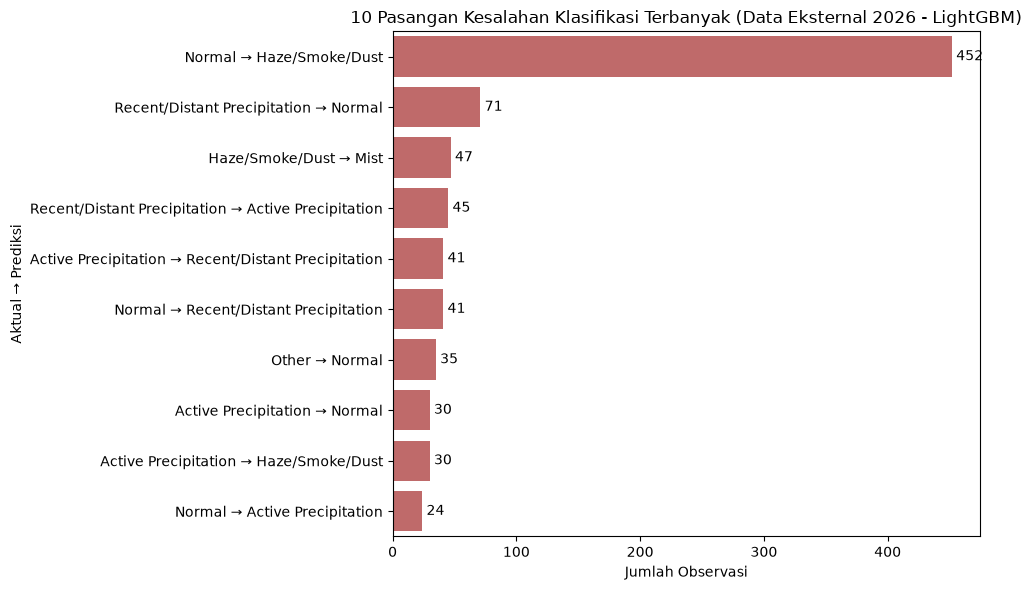

In [325]:
plt.figure(figsize=(10, 6))
top_errors = error_distribution.head(10).copy()
top_errors['Error Pair'] = top_errors['phenomenon'] + ' → ' + top_errors['predicted_phenomenon']

ax = sns.barplot(
    data=top_errors,
    x='Count',
    y='Error Pair',
    color='indianred'
)
plt.title('10 Pasangan Kesalahan Klasifikasi Terbanyak (Data Eksternal 2026 - LightGBM)')
plt.xlabel('Jumlah Observasi')
plt.ylabel('Aktual → Prediksi')

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

**Karakteristik Meteorologi Kesalahan & Perbandingan Normal vs Haze/Smoke/Dust**

In [326]:
analysis_features = [
    'wind_dir_deg_dd',
    'wind_speed_ff',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'relative_humidity_pc',
    'cloud_low_cover_oktas',
    'cloud_med_cover_oktas',
    'visibility_vv'
]

In [327]:
top_pairs_idx = error_distribution.head(10)[['phenomenon', 'predicted_phenomenon']]
error_characteristics = (
    misclassified
    .merge(top_pairs_idx, on=['phenomenon', 'predicted_phenomenon'])
    .groupby(['phenomenon', 'predicted_phenomenon'])[analysis_features]
    .mean()
    .round(2)
)
error_characteristics.index.names = ['Actual', 'Predicted']
print("Rata-rata Parameter Meteorologi pada 10 Pasangan Kesalahan Terbanyak")
display(error_characteristics)

Rata-rata Parameter Meteorologi pada 10 Pasangan Kesalahan Terbanyak


wind_dir_deg_dd  \
Actual                       Predicted                                       
Active Precipitation         Haze/Smoke/Dust                        224.80   
                             Normal                                 229.33   
                             Recent/Distant Precipitation           138.27   
Haze/Smoke/Dust              Mist                                   146.62   
Normal                       Active Precipitation                   203.42   
                             Haze/Smoke/Dust                        167.32   
                             Recent/Distant Precipitation           181.73   
Other                        Normal                                 149.57   
Recent/Distant Precipitation Active Precipitation                   209.73   
                             Normal                                 215.41   

                                                           wind_speed_ff  \
Actual                       Predicted                                     
Active Precipitation         Haze/Smoke/Dust                        3.67   
                             Normal                                 3.93   
                             Recent/Distant Precipitation           3.24   
Haze/Smoke/Dust              Mist                                   1.60   
Normal                       Active Precipitation                   4.83   
                             Haze/Smoke/Dust                        2.52   
                             Recent/Distant Precipitation           3.37   
Other                        Normal                                 3.66   
Recent/Distant Precipitation Active Precipitation                   3.20   
                             Normal                                 3.94   

                                                           pressure_qff_mb_derived  \
Actual                       Predicted                                               
Active Precipitation         Haze/Smoke/Dust                               1009.72   
                             Normal                                        1010.06   
                             Recent/Distant Precipitation                  1009.26   
Haze/Smoke/Dust              Mist                                          1009.93   
Normal                       Active Precipitation                          1009.96   
                             Haze/Smoke/Dust                               1010.34   
                             Recent/Distant Precipitation                  1008.80   
Other                        Normal                                        1009.33   
Recent/Distant Precipitation Active Precipitation                          1009.98   
                             Normal                                        1009.66   

                                                           temp_drybulb_c_tttttt  \
Actual                       Predicted                                             
Active Precipitation         Haze/Smoke/Dust                               25.92   
                             Normal                                        27.67   
                             Recent/Distant Precipitation                  26.55   
Haze/Smoke/Dust              Mist                                          24.77   
Normal                       Active Precipitation                          26.04   
                             Haze/Smoke/Dust                               26.58   
                             Recent/Distant Precipitation                  26.64   
Other                        Normal                                        27.95   
Recent/Distant Precipitation Active Precipitation                          25.22   
                             Normal                                        27.99   

                                                           temp_dewpoint_c_tdtdtd  \
Actual                       Predicted                                            

**Perbandingan mendalam kesalahan terbesar: Normal (Benar) vs Normal (Salah diprediksi Haze/Smoke/Dust)**

In [328]:
normal_correct = ext_eval[
    (ext_eval['phenomenon'] == 'Normal') &
    (ext_eval['predicted_phenomenon'] == 'Normal')
]

In [329]:
normal_as_haze = ext_eval[
    (ext_eval['phenomenon'] == 'Normal') &
    (ext_eval['predicted_phenomenon'] == 'Haze/Smoke/Dust')
]

In [330]:
comparison_normal_df = pd.DataFrame({
    f'Normal - Correct (n={len(normal_correct)})': normal_correct[analysis_features].mean(),
    f'Normal - Predicted as Haze (n={len(normal_as_haze)})': normal_as_haze[analysis_features].mean()
}).round(2)
print("Perbandingan Karakteristik: Normal (Benar) vs Normal (Terprediksi Haze/Smoke/Dust)")
display(comparison_normal_df)

Perbandingan Karakteristik: Normal (Benar) vs Normal (Terprediksi Haze/Smoke/Dust)


,Normal - Correct (n=2266),Normal - Predicted as Haze (n=452)
wind_dir_deg_dd,173.90,167.32
wind_speed_ff,4.17,2.52
pressure_qff_mb_derived,1009.80,1010.34
temp_drybulb_c_tttttt,28.91,26.58
temp_dewpoint_c_tdtdtd,23.86,24.21
relative_humidity_pc,75.16,87.14
cloud_low_cover_oktas,3.24,2.56
cloud_med_cover_oktas,4.34,4.89
visibility_vv,9.94,7.06


**Boxplot 4 parameter utama pembeda**

In [331]:
normal_subset = ext_eval[
    (ext_eval['phenomenon'] == 'Normal') &
    (ext_eval['predicted_phenomenon'].isin(['Normal', 'Haze/Smoke/Dust']))
].copy()

In [332]:
normal_subset['Status Prediksi'] = normal_subset['predicted_phenomenon'].map({
    'Normal': 'Correct (Normal)',
    'Haze/Smoke/Dust': 'Misclassified as Haze/Smoke/Dust'
})

In [333]:
plot_features = [
    'visibility_vv',
    'relative_humidity_pc',
    'temp_drybulb_c_tttttt',
    'wind_speed_ff'
]

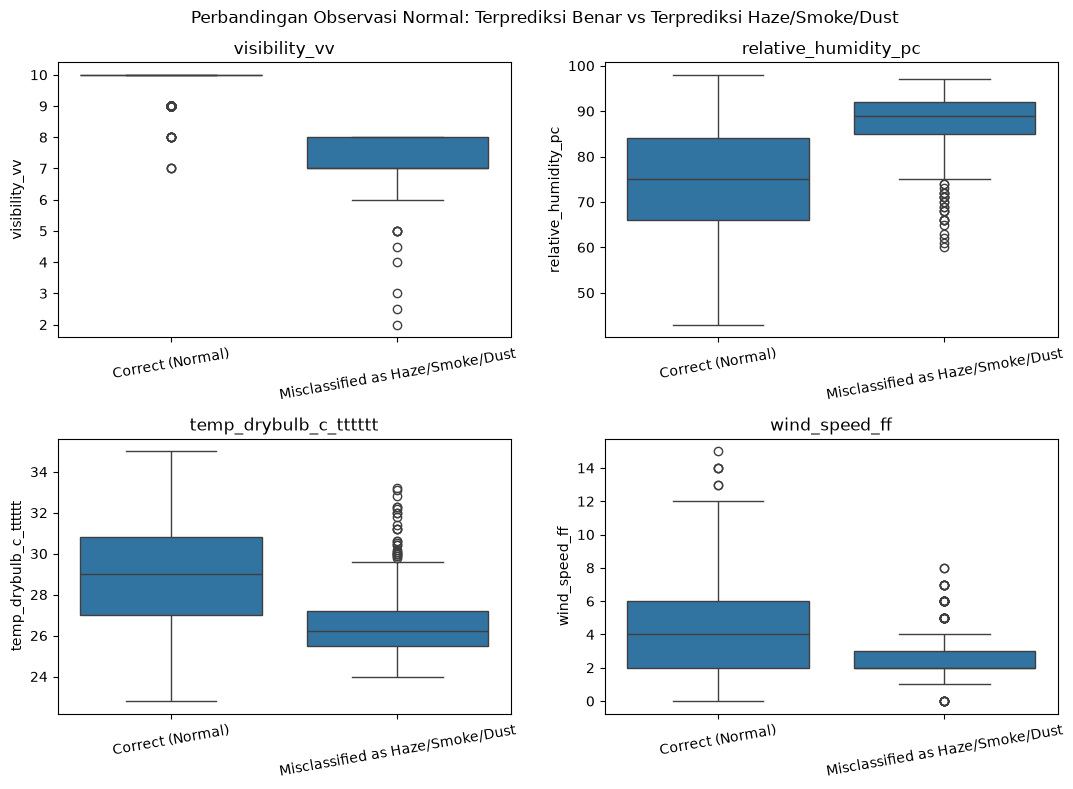

In [334]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feat in zip(axes.flat, plot_features):
    sns.boxplot(
        data=normal_subset,
        x='Status Prediksi',
        y=feat,
        ax=ax
    )
    ax.set_title(feat)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=10)

plt.suptitle('Perbandingan Observasi Normal: Terprediksi Benar vs Terprediksi Haze/Smoke/Dust', fontsize=12)
plt.tight_layout()
plt.show()

**Perbandingan 3 Profil untuk 4 pasangan kesalahan terbanyak dari error_distribution**

In [335]:
top_4_pairs = list(
    error_distribution.head(4)[['phenomenon', 'predicted_phenomenon']].itertuples(index=False, name=None)
)

In [336]:
for rank, (actual_cls, pred_cls) in enumerate(top_4_pairs, start=1):
    df_actual_correct = ext_eval[
        (ext_eval['phenomenon'] == actual_cls) &
        (ext_eval['predicted_phenomenon'] == actual_cls)
    ]
    df_misclassified = ext_eval[
        (ext_eval['phenomenon'] == actual_cls) &
        (ext_eval['predicted_phenomenon'] == pred_cls)
    ]
    df_pred_correct = ext_eval[
        (ext_eval['phenomenon'] == pred_cls) &
        (ext_eval['predicted_phenomenon'] == pred_cls)
    ]

    print("=" * 80)
    print(f"#{rank} Pasangan Kesalahan: {actual_cls} → {pred_cls} (n = {len(df_misclassified)})")
    print("=" * 80)

    comp_3way = pd.DataFrame({
        f'{actual_cls} - Correct (n={len(df_actual_correct)})': df_actual_correct[analysis_features].mean(),
        f'{actual_cls} → {pred_cls} (n={len(df_misclassified)})': df_misclassified[analysis_features].mean(),
        f'{pred_cls} - Correct (n={len(df_pred_correct)})': df_pred_correct[analysis_features].mean()
    }).round(2)

    display(comp_3way)

#1 Pasangan Kesalahan: Normal → Haze/Smoke/Dust (n = 452)


,Normal - Correct (n=2266),Normal → Haze/Smoke/Dust (n=452),Haze/Smoke/Dust - Correct (n=690)
wind_dir_deg_dd,173.90,167.32,161.69
wind_speed_ff,4.17,2.52,1.99
pressure_qff_mb_derived,1009.80,1010.34,1010.33
temp_drybulb_c_tttttt,28.91,26.58,26.00
temp_dewpoint_c_tdtdtd,23.86,24.21,24.29
relative_humidity_pc,75.16,87.14,90.56
cloud_low_cover_oktas,3.24,2.56,2.70
cloud_med_cover_oktas,4.34,4.89,4.87
visibility_vv,9.94,7.06,4.71


#2 Pasangan Kesalahan: Recent/Distant Precipitation → Normal (n = 71)


,Recent/Distant Precipitation - Correct (n=45),Recent/Distant Precipitation → Normal (n=71),Normal - Correct (n=2266)
wind_dir_deg_dd,193.51,215.41,173.90
wind_speed_ff,3.18,3.94,4.17
pressure_qff_mb_derived,1008.82,1009.66,1009.80
temp_drybulb_c_tttttt,26.97,27.99,28.91
temp_dewpoint_c_tdtdtd,24.64,24.04,23.86
relative_humidity_pc,87.53,80.04,75.16
cloud_low_cover_oktas,4.18,4.31,3.24
cloud_med_cover_oktas,5.84,5.69,4.34
visibility_vv,9.36,9.97,9.94


#3 Pasangan Kesalahan: Haze/Smoke/Dust → Mist (n = 47)


,Haze/Smoke/Dust - Correct (n=690),Haze/Smoke/Dust → Mist (n=47),Mist - Correct (n=137)
wind_dir_deg_dd,161.69,146.62,185.51
wind_speed_ff,1.99,1.60,1.93
pressure_qff_mb_derived,1010.33,1009.93,1009.69
temp_drybulb_c_tttttt,26.00,24.77,24.94
temp_dewpoint_c_tdtdtd,24.29,24.06,24.31
relative_humidity_pc,90.56,95.77,96.25
cloud_low_cover_oktas,2.70,3.00,2.66
cloud_med_cover_oktas,4.87,4.36,5.56
visibility_vv,4.71,3.26,2.57


#4 Pasangan Kesalahan: Recent/Distant Precipitation → Active Precipitation (n = 45)


,Recent/Distant Precipitation - Correct (n=45),Recent/Distant Precipitation → Active Precipitation (n=45),Active Precipitation - Correct (n=213)
wind_dir_deg_dd,193.51,209.73,201.87
wind_speed_ff,3.18,3.20,4.37
pressure_qff_mb_derived,1008.82,1009.98,1010.38
temp_drybulb_c_tttttt,26.97,25.22,25.07
temp_dewpoint_c_tdtdtd,24.64,23.88,23.72
relative_humidity_pc,87.53,92.56,92.48
cloud_low_cover_oktas,4.18,4.69,5.28
cloud_med_cover_oktas,5.84,7.38,7.04
visibility_vv,9.36,7.16,4.95


**Notes:**

- Dari total **`4.341` observasi eksternal**, model utama **LightGBM** (`52` fitur) mengklasifikasikan **`3.378` observasi (`77,82%`)** secara tepat dan menghasilkan **`963` kesalahan prediksi (`22,18%`)**—menurun signifikan dibandingkan eksperimen tanpa fitur lag (`1.186` kesalahan atau `27,30%`). Sebanyak **`63,86%` (`615` kasus)** dari seluruh kesalahan terpusat pada empat pasangan fenomena berikut:
  1. **`Normal` terprediksi sebagai `Haze/Smoke/Dust` (`452` observasi / `46,94%`):** Rata-rata parameter observasi `Normal` yang salah terprediksi berada tepat di zona transisi antara profil `Normal - Correct` dan `Haze/Smoke/Dust - Correct`—yakni jarak pandang menurun dari **`9,94 km`** menjadi **`7,06 km`** (mendekati `4,71 km`), kelembapan relatif meningkat dari **`75,16%`** menjadi **`87,14%`** (mendekati `90,56%`), suhu bola kering turun dari **`28,91 °C`** menjadi **`26,58 °C`** (mendekati `26,00 °C`), serta kecepatan angin melemah dari **`4,17 knot`** menjadi **`2,52 knot`** (mendekati `1,99 knot`). Pola ini umumnya muncul pada malam hingga dini hari (`20:00–00:00 WIB`) ketika pendinginan udara menurunkan jarak pandang ke kisaran `6–8 km` tanpa disertai penyandian kabut asap formal.
  2. **`Recent/Distant Precipitation` terprediksi sebagai `Normal` (`71` observasi / `7,37%`):** Terjadi ketika hujan yang baru berlalu atau berada di kejauhan tidak lagi meninggalkan jejak dingin dan lembap di lokasi stasiun, sehingga profil parameternya bergeser mendekati `Normal - Correct`—yakni jarak pandang kembali penuh di angka **`9,97 km`** (vs `9,94 km`), kelembapan relatif turun dari **`87,53%`** menjadi **`80,04%`** (mendekati `75,16%`), suhu udara menghangat dari **`26,97 °C`** menjadi **`27,99 °C`**, dan kecepatan angin meningkat menjadi **`3,94 knot`** (mendekati `4,17 knot`).
  3. **`Haze/Smoke/Dust` terprediksi sebagai `Mist` (`47` observasi / `4,88%`):** Terjadi saat kejadian `Haze/Smoke/Dust` berlangsung pada kondisi udara yang hampir jenuh uap air (umumnya menjelang pagi), dengan rata-rata kelembapan relatif mencapai **`95,77%`** (hampir identik dengan `Mist - Correct` sebesar `96,25%`), suhu udara sejuk (**`24,77 °C`** vs `24,94 °C`), angin tenang (**`1,60 knot`** vs `1,93 knot`), serta jarak pandang menyusut ke **`3,26 km`** (mendekati rata-rata `Mist` sebesar `2,57 km`).
  4. **`Recent/Distant Precipitation` terprediksi sebagai `Active Precipitation` (`45` observasi / `4,67%`):** Terjadi sesaat setelah hujan reda di stasiun, di mana kondisi termodinamika permukaan masih mempertahankan ciri hujan aktif yang kuat—yakni kelembapan relatif **`92,56%`** (hampir sama dengan `Active Precipitation - Correct` sebesar `92,48%`), suhu udara dingin **`25,22 °C`** (vs `25,07 °C`), tutupan awan menengah tebal **`7,38` oktas** (vs `7,04` oktas), dan jarak pandang **`7,16 km`**.
- Secara keseluruhan, hasil analisis ini mengonfirmasi bahwa mayoritas kesalahan prediksi bukan merupakan kesalahan acak, melainkan bersumber dari **tumpang tindih karakteristik parameter meteorologi permukaan (*feature overlap*)** pada fase peralihan antarfenomena cuaca di lapangan.

# 14. Model Saving and Deployment Preparation

Tahap ini mempersiapkan model klasifikasi terpilih agar siap diintegrasikan ke dalam aplikasi web. Proses meliputi penyiapan objek model dan komponen pendukung, pembuatan fungsi transformasi fitur untuk data hasil *decoding* SYNOP beserta riwayat 3 jam terakhir, pengujian konsistensi fitur terhadap data uji, penyimpanan artefak model menggunakan `joblib`, serta pengujian pemuatan ulang model.

## 14.1 Preparing Model Components

Menyiapkan komponen inti yang dibutuhkan pada tahap inferensi, yaitu model **LightGBM** hasil *hyperparameter tuning* (`deploy_model`), daftar **52 fitur masukan** sesuai urutan pelatihan (`selected_features`), serta kamus pemetaan 7 kelas fenomena (`label_map` dan `inv_label_map`).

In [337]:
final_lgbm = search_results['LightGBM'].best_estimator_
deploy_model = final_lgbm

In [338]:
selected_features = list(X_train.columns)

In [339]:
print("Model            :", type(deploy_model).__name__)
print("Jumlah fitur     :", len(selected_features))
print("Contoh 15 fitur  :", selected_features[:15])
print("Label mapping    :", label_map)

Model            : LGBMClassifier
Jumlah fitur     : 52
Contoh 15 fitur  : ['wind_speed_ff', 'wind_dir_sin', 'wind_dir_cos', 'is_calm', 'pressure_qff_mb_derived', 'temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'relative_humidity_pc', 'cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'visibility_vv', 'hour_sin', 'hour_cos', 'wind_dir_sin_lag1', 'wind_dir_sin_lag2']
Label mapping    : {'Active Precipitation': 0, 'Fog': 1, 'Haze/Smoke/Dust': 2, 'Mist': 3, 'Normal': 4, 'Other': 5, 'Recent/Distant Precipitation': 6}


## 14.2 Building Feature Engineering Function

Membuat fungsi `build_features()` untuk mengolah satu baris data observasi hasil *decoding* sandi SYNOP (beserta riwayat observasi 3 jam sebelumnya jika tersedia) menjadi **52 fitur numerik** yang dibutuhkan oleh model LightGBM. Fungsi ini memvalidasi kelengkapan parameter masukan, mengonversi waktu observasi dari UTC ke WIB (`Asia/Jakarta`), membentuk fitur siklikal waktu dan arah angin, indikator angin tenang (`is_calm`), riwayat waktu (`lag1`–`lag3`), serta laju perubahan ($\Delta$), lalu menyusun urutan kolom tepat sama dengan `selected_features`.

In [340]:
def _parse_to_wib(ts_val, input_timezone='UTC'):
    ts = pd.Timestamp(ts_val)
    if ts.tzinfo is None:
        ts = ts.tz_localize(input_timezone)
    return ts.tz_convert('Asia/Jakarta')

def _compute_base_row(row_series, input_timezone='UTC'):
    dt_wib = _parse_to_wib(row_series['data_timestamp'], input_timezone=input_timezone)
    hour = dt_wib.hour
    wind_speed = float(row_series['wind_speed_ff'])
    wind_dir = float(row_series['wind_dir_deg_dd'])

    return {
        'datetime_wib': dt_wib,
        'wind_speed_ff': wind_speed,
        'wind_dir_sin': float(np.sin(np.deg2rad(wind_dir))),
        'wind_dir_cos': float(np.cos(np.deg2rad(wind_dir))),
        'is_calm': int(wind_speed == 0),
        'pressure_qff_mb_derived': float(row_series['pressure_qff_mb_derived']),
        'temp_drybulb_c_tttttt': float(row_series['temp_drybulb_c_tttttt']),
        'temp_dewpoint_c_tdtdtd': float(row_series['temp_dewpoint_c_tdtdtd']),
        'relative_humidity_pc': float(row_series['relative_humidity_pc']),
        'cloud_low_cover_oktas': int(row_series['cloud_low_cover_oktas']),
        'cloud_med_cover_oktas': int(row_series['cloud_med_cover_oktas']),
        'visibility_vv': float(row_series['visibility_vv']),
        'hour_sin': float(np.sin(2 * np.pi * hour / 24)),
        'hour_cos': float(np.cos(2 * np.pi * hour / 24))
    }

def build_features(data, history_df=None, input_timezone='UTC'):
    """
    Mengolah satu baris data observasi hasil decoding SYNOP (dan riwayat 3 jam
    sebelumnya jika tersedia) menjadi 52 fitur terurut sesuai kebutuhan model LightGBM.

    Parameters
    ----------
    data : pandas.Series atau dict
        Satu baris observasi meteorologi pada waktu t.
    history_df : pandas.DataFrame, optional
        DataFrame berisi observasi jam-jam sebelumnya (t-3, t-2, t-1).
        Jika None, fitur lag dan delta diisi np.nan (didukung bawaan LightGBM).
    input_timezone : str, default='UTC'
        Zona waktu timestamp input.

    Returns
    -------
    pandas.DataFrame
        DataFrame 1 baris dengan 52 fitur terurut sesuai selected_features.
    """
    data = pd.Series(data)

    required_columns = [
        'data_timestamp',
        'wind_speed_ff',
        'wind_dir_deg_dd',
        'pressure_qff_mb_derived',
        'temp_drybulb_c_tttttt',
        'temp_dewpoint_c_tdtdtd',
        'relative_humidity_pc',
        'cloud_low_cover_oktas',
        'cloud_med_cover_oktas',
        'visibility_vv'
    ]

    missing_columns = [col for col in required_columns if col not in data.index]
    if missing_columns:
        raise ValueError(f"Kolom belum tersedia: {missing_columns}")

    if data[required_columns].isna().any():
        raise ValueError("Data observasi belum lengkap. Periksa kembali parameter yang kosong.")

    # 1. Hitung fitur dasar pada waktu t
    curr = _compute_base_row(data, input_timezone=input_timezone)
    curr_time = curr['datetime_wib']
    features = {k: v for k, v in curr.items() if k != 'datetime_wib'}

    # 2. Petakan observasi riwayat berdasarkan timestamp WIB
    hist_by_time = {}
    if history_df is not None and len(history_df) > 0:
        for _, h_row in history_df.iterrows():
            if not h_row[required_columns].isna().any():
                h_base = _compute_base_row(h_row, input_timezone=input_timezone)
                hist_by_time[h_base['datetime_wib']] = h_base

    # 3. Bentuk 30 fitur riwayat waktu (lag1, lag2, lag3)
    lag_bases = [
        'wind_dir_sin',
        'wind_dir_cos',
        'wind_speed_ff',
        'visibility_vv',
        'pressure_qff_mb_derived',
        'temp_drybulb_c_tttttt',
        'temp_dewpoint_c_tdtdtd',
        'relative_humidity_pc',
        'cloud_low_cover_oktas',
        'cloud_med_cover_oktas'
    ]

    for lag in [1, 2, 3]:
        target_ts = curr_time - pd.Timedelta(hours=lag)
        past_obs = hist_by_time.get(target_ts)
        for col in lag_bases:
            features[f'{col}_lag{lag}'] = float(past_obs[col]) if past_obs is not None else np.nan

    # 4. Bentuk 9 fitur laju perubahan (Delta 1 jam dan 3 jam)
    delta_specs = [
        ('visibility_diff_1', 'visibility_vv', 1),
        ('visibility_diff_3', 'visibility_vv', 3),
        ('temp_drybulb_diff_1', 'temp_drybulb_c_tttttt', 1),
        ('temp_drybulb_diff_3', 'temp_drybulb_c_tttttt', 3),
        ('rh_diff_1', 'relative_humidity_pc', 1),
        ('rh_diff_3', 'relative_humidity_pc', 3),
        ('pressure_diff_1', 'pressure_qff_mb_derived', 1),
        ('pressure_diff_3', 'pressure_qff_mb_derived', 3),
        ('wind_speed_diff_1', 'wind_speed_ff', 1)
    ]

    for new_col, base_col, step in delta_specs:
        target_ts = curr_time - pd.Timedelta(hours=step)
        past_obs = hist_by_time.get(target_ts)
        features[new_col] = (
            float(curr[base_col] - past_obs[base_col])
            if past_obs is not None else np.nan
        )

    feature_df = pd.DataFrame([features])[selected_features]
    return feature_df

## 14.3 Feature Consistency Testing

Menguji fungsi `build_features()` menggunakan satu sampel observasi dari data uji beserta riwayat 3 jam sebelumnya, lalu membandingkannya secara langsung dengan baris yang bersesuaian pada `X_test` untuk memastikan nama kolom, urutan ke-52 fitur, serta presisi nilai numeriknya identik.

In [350]:
source_all_df = clean_df.sort_values('data_timestamp').reset_index(drop=True)

**Ambil satu sampel observasi dari data uji beserta 3 observasi jam sebelumnya**

In [351]:
valid_test_indices = [
    idx for idx in X_test.index
    if idx >= 3 and (
        source_all_df.loc[idx, 'data_timestamp'] - source_all_df.loc[idx - 3, 'data_timestamp']
        == pd.Timedelta(hours=3)
    )
]
sample_idx = valid_test_indices[0]
sample = source_all_df.loc[sample_idx]

In [352]:
history_3h = source_all_df[
    (source_all_df['data_timestamp'] < sample['data_timestamp']) &
    (source_all_df['data_timestamp'] >= sample['data_timestamp'] - pd.Timedelta(hours=3))
]

In [353]:
print("Timestamp sample        :", sample['data_timestamp'])
print("Jumlah baris history_3h :", len(history_3h))

Timestamp sample        : 2025-01-01 06:00:00
Jumlah baris history_3h : 3


**Bentuk 52 fitur menggunakan fungsi deployment**

In [354]:
sample_features = build_features(sample, history_df=history_3h, input_timezone='UTC')

**Ambil baris fitur asli dari X_test sebagai pembanding**

In [355]:
original_features = X_test.loc[[sample_idx]]

In [356]:
print("Jumlah fitur dihasilkan :", sample_features.shape[1])
print("Urutan fitur sesuai     :", list(sample_features.columns) == list(original_features.columns))
print(
    "Nilai fitur sesuai      :",
    np.allclose(
        sample_features.to_numpy(dtype=float),
        original_features.to_numpy(dtype=float),
        rtol=1e-9,
        atol=1e-9
    )
)

Jumlah fitur dihasilkan : 52
Urutan fitur sesuai     : True
Nilai fitur sesuai      : True


In [357]:
comparison_features_df = pd.DataFrame({
    'Original (X_test)': original_features.iloc[0],
    'Generated (build_features)': sample_features.iloc[0]
})
display(comparison_features_df.head(20))

,Original (X_test),Generated (build_features)
wind_speed_ff,7.000000,7.000000
wind_dir_sin,-0.642788,-0.642788
wind_dir_cos,0.766044,0.766044
is_calm,0.000000,0.000000
pressure_qff_mb_derived,1008.900000,1008.900000
temp_drybulb_c_tttttt,29.500000,29.500000
temp_dewpoint_c_tdtdtd,24.200000,24.200000
relative_humidity_pc,73.000000,73.000000
cloud_low_cover_oktas,4.000000,4.000000
cloud_med_cover_oktas,4.000000,4.000000


## 14.4 Saving Model and Supporting Components

Menyimpan model utama **LightGBM** (`deploy_model`) beserta daftar **52 fitur** (`selected_features`) dan pemetaan label (`label_map`, `inv_label_map`) ke dalam satu file artefak `../model/weather_phenomena_lgbm_model.joblib` menggunakan `joblib`.

In [358]:
model_path = '../model/weather_phenomena_lgbm_model.joblib'
os.makedirs(os.path.dirname(model_path), exist_ok=True)

In [359]:
model_components = {
    'model': deploy_model,
    'selected_features': selected_features,
    'label_map': label_map,
    'inv_label_map': inv_label_map
}

In [360]:
joblib.dump(model_components, model_path)
print(f"Model dan komponen pendukung berhasil disimpan ke: {model_path}")

Model dan komponen pendukung berhasil disimpan ke: ../model/weather_phenomena_lgbm_model.joblib


## 14.5 Testing Model Loading

Memuat kembali file `../model/weather_phenomena_lgbm_model.joblib` menggunakan `joblib.load()` untuk memverifikasi bahwa objek model LightGBM, daftar **52 fitur**, serta kamus pemetaan 7 label fenomena dapat terbaca dengan utuh dan konsisten sebelum digunakan pada tahap simulasi prediksi.

In [361]:
loaded_components = joblib.load('../model/weather_phenomena_lgbm_model.joblib')

In [362]:
loaded_model = loaded_components['model']
loaded_features = loaded_components['selected_features']
loaded_label_map = loaded_components['label_map']
loaded_inv_label_map = loaded_components['inv_label_map']

In [363]:
print("Model               :", type(loaded_model).__name__)
print("Jumlah fitur        :", len(loaded_features))
print("Urutan fitur sesuai :", loaded_features == selected_features)
print("Label mapping sesuai:", loaded_label_map == label_map)

Model               : LGBMClassifier
Jumlah fitur        : 52
Urutan fitur sesuai : True
Label mapping sesuai: True


# 15. Model Prediction Simulation

Tahap ini melakukan simulasi *end-to-end* penggunaan model utama **LightGBM** yang telah disimpan dan dimuat kembali untuk mengklasifikasikan fenomena cuaca dari satu observasi meteorologi. Simulasi mencakup pembentukan **52 fitur** menggunakan `build_features()`, prediksi kelas fenomena, pemeriksaan distribusi probabilitas pada seluruh 7 kelas, serta verifikasi kesesuaiannya terhadap kelas aktual.

## 15.1 Simulating Model Prediction

Mengambil satu sampel observasi dari data uji beserta riwayat 3 jam sebelumnya, memprosesnya menggunakan fungsi `build_features()` untuk menghasilkan **52 fitur** sesuai urutan pelatihan, lalu menjalankan prediksi kelas menggunakan `loaded_model`.

In [386]:
source_all_df = clean_df.sort_values('data_timestamp')
sample_idx = X_test.index[0]
sample = source_all_df.loc[sample_idx]
history_3h = source_all_df[
    (source_all_df['data_timestamp'] < sample['data_timestamp']) &
    (source_all_df['data_timestamp'] >= sample['data_timestamp'] - pd.Timedelta(hours=3))
]

**Bentuk 52 fitur menggunakan fungsi deployment**

In [387]:
sample_features = build_features(sample, history_df=history_3h, input_timezone='UTC')

**Prediksi kelas menggunakan model XGBoost yang telah dimuat ulang**

In [388]:
predicted_label = int(loaded_model.predict(sample_features)[0])
predicted_phenomenon = loaded_inv_label_map[predicted_label]

In [389]:
observation_time = (
    pd.Timestamp(sample['data_timestamp'])
    .tz_localize('UTC')
    .tz_convert('Asia/Jakarta')
)

In [390]:
print("Hasil Prediksi")
print("=" * 35)
print("Waktu Observasi     :", observation_time.strftime('%d-%m-%Y %H:%M WIB'))
print("Predicted Label     :", predicted_label)
print("Predicted Phenomenon:", predicted_phenomenon)

Hasil Prediksi
Waktu Observasi     : 01-01-2025 10:00 WIB
Predicted Label     : 1
Predicted Phenomenon: Fog


## 15.2 Analyzing Prediction Probabilities

Menghitung probabilitas prediksi model **LightGBM** menggunakan metode `predict_proba()` untuk melihat tingkat keyakinan model terhadap masing-masing dari 7 kategori fenomena pada observasi yang diuji.

In [391]:
prediction_probabilities = loaded_model.predict_proba(sample_features)[0]

In [392]:
probability_df = pd.DataFrame({
    'Phenomenon': [
        loaded_inv_label_map[int(cls_idx)]
        for cls_idx in loaded_model.classes_
    ],
    'Probability': prediction_probabilities
})

In [393]:
probability_df = (
    probability_df
    .sort_values(by='Probability', ascending=False)
    .reset_index(drop=True)
)
probability_df['Probability (%)'] = (probability_df['Probability'] * 100).round(2)

In [394]:
display(probability_df[['Phenomenon', 'Probability (%)']])

,Phenomenon,Probability (%)
0,Fog,57.24
1,Normal,34.95
2,Active Precipitation,4.01
3,Recent/Distant Precipitation,2.17
4,Haze/Smoke/Dust,0.69
5,Other,0.61
6,Mist,0.33


## 15.3 Comparing Prediction with Actual Class

Membandingkan hasil klasifikasi model **LightGBM** dengan label fenomena aktual pada observasi yang sama untuk memverifikasi ketepatan keluaran alur prediksi.

In [395]:
actual_label = int(y_test.loc[sample_idx])
actual_phenomenon = loaded_inv_label_map[actual_label]
prediction_correct = (predicted_label == actual_label)

In [396]:
print("Perbandingan Hasil Prediksi")
print("=" * 35)
print("Waktu Observasi :", observation_time.strftime('%d-%m-%Y %H:%M WIB'))
print("Kelas Aktual    :", actual_phenomenon)
print("Kelas Prediksi  :", predicted_phenomenon)
print("Hasil Klasifikasi:", "Benar" if prediction_correct else "Tidak Sesuai")

Perbandingan Hasil Prediksi
Waktu Observasi : 01-01-2025 10:00 WIB
Kelas Aktual    : Normal
Kelas Prediksi  : Fog
Hasil Klasifikasi: Tidak Sesuai


## 15.4 Summary of Prediction Simulation

Berdasarkan simulasi *end-to-end* yang telah dilakukan, artefak model utama **LightGBM** (`../model/weather_phenomena_lgbm_model.joblib`) yang dimuat kembali melalui `joblib.load()` berhasil menerima satu baris data observasi beserta riwayat 3 jam sebelumnya melalui fungsi `build_features()` (**52 fitur terurut**) dan menghasilkan prediksi kelas beserta distribusi probabilitas untuk seluruh 7 kategori fenomena.

Pada sampel observasi tanggal **01-01-2025 pukul 10:00 WIB**, model memprediksi fenomena **`Fog`** dengan probabilitas sebesar **`57,24%`**, diikuti oleh kelas aktualnya **`Normal`** di peringkat kedua sebesar **`34,95%`**, sementara lima kelas lainnya memperoleh probabilitas di bawah `4,10%` (`Active Precipitation` `4,01%`, `Recent/Distant Precipitation` `2,17%`, `Haze/Smoke/Dust` `0,69%`, `Other` `0,61%`, dan `Mist` `0,33%`). Perbedaan antara kelas prediksi (`Fog`) dan label aktual (`Normal`) pada sampel transisi pagi menuju siang ini mencerminkan pengaruh pembobotan kelas seimbang (`class_weight='balanced'`) serta terbawanya informasi riwayat atmosfer 1–3 jam sebelumnya (`lag1`–`lag3`) yang membuat model lebih sensitif terhadap kemunculan fenomena minoritas `Fog`.

Hasil pengujian ini memverifikasi bahwa seluruh alur inferensi—mulai dari konversi zona waktu ke WIB, pembentukan 52 fitur masukan dengan riwayat 3 jam, hingga pemanggilan model tersimpan dan ekstraksi probabilitas—berjalan konsisten tanpa kendala teknis dan siap diintegrasikan ke dalam aplikasi web. Pengujian satu sampel ini berfungsi sebagai verifikasi kesiapan *pipeline* inferensi dan melengkapi evaluasi menyeluruh pada data uji internal (`n = 1.718`, akurasi `82,25%`) maupun validasi eksternal (`n = 4.341`, akurasi `77,82%`).